# Model selection and training: application table

This notebook chooses, tunes and trains a model that predicts the probability of payment difficulties (`TARGET`) for a Home Credit loan application.

It picks up where `01_application_train_eda.ipynb` ended. That notebook cleaned `application_train.csv`, engineered features, and reduced 120 raw columns to 55. This notebook takes those 55 features as given and answers a different question: which model should use them, with what settings, and how good is the result?

## Inputs

| File | Rows | Contents |
|---|---:|---|
| `data/processed/application_train_features.parquet` | 307,511 | 55 features and `TARGET`, indexed by `SK_ID_CURR` |
| `data/processed/application_test_features.parquet` | 48,744 | The same 55 features, no target |

The data arrives with nine text columns still as text and with missing values left missing (about 6.7% of cells). Encoding and imputation are part of each model's pipeline, because the right choice depends on the model.

## What is carried over from the EDA

- **Target:** 8.07% of applications default, about 11 repaid loans for every default.
- **Primary metric:** ROC AUC, the competition metric. PR AUC and log loss are reported alongside.
- **Validation:** stratified 5-fold cross-validation with a fixed seed, the same folds for every model.
- **Scores to beat:**

| Reference | ROC AUC |
|---|---:|
| Any uninformed prediction | 0.500 |
| Mean of the external scores, no model | 0.7165 |
| Untuned gradient boosting on the 55 features | 0.7625 |

- **Known risk:** train and test are different populations, mainly because test loans carry higher payment rates. A validation score measured on train may not carry over exactly.

## What this notebook does

| # | Stage | Question it answers |
|---|---|---|
| 1 | Setup and data | Do the saved files load as expected, and are the folds fixed? |
| 2 | Holdout split | Which rows are set aside and not touched until the final evaluation? |
| 3 | Preprocessing pipelines | How are missing values and text columns handled for linear models and for tree models? |
| 4 | Baselines | What do the simplest reasonable models score? |
| 5 | Candidate models | Which model family is best at default settings? |
| 6 | Class imbalance | Do class weights or resampling help, and what do they do to the predicted probabilities? |
| 7 | Hyperparameter tuning | How much better are the leading models once tuned? |
| 8 | Feature importance and pruning | Which features does the tuned model rely on, and can the list be shortened? |
| 9 | Calibration | Can the predicted probabilities be read as real default rates? |
| 10 | Decision threshold | Where should the approve or decline line sit, and what does each choice cost? |
| 11 | Holdout evaluation | What does the chosen model score on rows it has never seen? |
| 12 | Explainability | Why does the model give a particular applicant a particular score? |
| 13 | Final model and outputs | Refit on all of train, save the model, and write the Kaggle submission files |
| 14 | Conclusions | The chosen model, its score, its limits, and what to do next |

Each stage ends with a short findings cell and a decision, as in the EDA notebook.

## Rules followed throughout

- Every preprocessing step that learns from data (imputation values, scaling, encoders) sits inside the model pipeline, so it is fitted on the training folds only.
- The holdout set is scored once, in stage 11, after every choice has been made.
- Models are compared fold by fold on identical folds. A difference smaller than the fold-to-fold noise is not treated as a win.
- The test file has no target. It is used only to produce the submission in stage 13.

## What this notebook produces

- A comparison table of every model tried, on the same folds.
- One tuned and calibrated model, saved under `artifacts/`.
- A chosen decision threshold, with the reasoning behind it.
- Kaggle submission files, with and without `ANNUITY_TO_CREDIT`, to test whether the validation score carries over to the test set.

## Out of scope

- The six history tables (`bureau`, `previous_application` and the rest). This model uses the application table only. Adding the history tables is the next phase and is expected to raise the score well beyond what is reached here.
- Further feature engineering on the application table. Stage 12 of the EDA showed little remains to be gained there.

## Stage 1: Setup and data

Load the saved feature tables, confirm they are what the EDA produced, and audit them for data leakage before any model is trained.

In [1]:
import time
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, log_loss

pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 200)

SEED = 42
N_SPLITS = 5
PROCESSED = '../data/processed'
RAW = '../data/raw'

### 1.1 Load and check

In [2]:
train = pd.read_parquet(f'{PROCESSED}/application_train_features.parquet')
X_test = pd.read_parquet(f'{PROCESSED}/application_test_features.parquet')

# one column is integer in train and float in test, because a single out-of-range test value was set to missing
train['REGION_RATING_CLIENT_W_CITY'] = train['REGION_RATING_CLIENT_W_CITY'].astype(float)
X_test['REGION_RATING_CLIENT_W_CITY'] = X_test['REGION_RATING_CLIENT_W_CITY'].astype(float)

X = train.drop(columns='TARGET')
y = train['TARGET']

FEATURES = list(X.columns)
TEXT_FEATURES = [c for c in FEATURES if not pd.api.types.is_numeric_dtype(X[c])]
NUMERIC_FEATURES = [c for c in FEATURES if c not in TEXT_FEATURES]

checks = {
    'train shape is (307511, 55)': X.shape == (307511, 55),
    'test shape is (48744, 55)': X_test.shape == (48744, 55),
    'same feature columns, same order': list(X.columns) == list(X_test.columns),
    'same dtypes in train and test': all(str(X[c].dtype) == str(X_test[c].dtype) for c in FEATURES),
    'index is SK_ID_CURR in both': X.index.name == 'SK_ID_CURR' and X_test.index.name == 'SK_ID_CURR',
    'no duplicate IDs': X.index.is_unique and X_test.index.is_unique,
    'no ID shared by train and test': len(X.index.intersection(X_test.index)) == 0,
    'target is 0 or 1 with no missing values': y.isin([0, 1]).all() and y.notna().all(),
    '24,825 defaults (8.07%)': int(y.sum()) == 24825,
    'no infinite values': not np.isinf(X[NUMERIC_FEATURES].to_numpy(dtype=float)).any() and not np.isinf(X_test[NUMERIC_FEATURES].to_numpy(dtype=float)).any(),
}
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(checks.values())

print(f"\n{len(NUMERIC_FEATURES)} numeric and {len(TEXT_FEATURES)} text features")
print('text features:', TEXT_FEATURES)
print(f"cells missing: train {X.isna().values.mean():.1%}, test {X_test.isna().values.mean():.1%}")
print(f"default rate: {y.mean():.4f}")

PASS  train shape is (307511, 55)
PASS  test shape is (48744, 55)
PASS  same feature columns, same order
PASS  same dtypes in train and test
PASS  index is SK_ID_CURR in both
PASS  no duplicate IDs
PASS  no ID shared by train and test
PASS  target is 0 or 1 with no missing values
PASS  24,825 defaults (8.07%)
PASS  no infinite values

46 numeric and 9 text features
text features: ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE']
cells missing: train 6.7%, test 6.2%
default rate: 0.0807


### 1.2 Leakage audit

Data leakage means the model is given information during training that it would not have when making a real prediction. It makes validation scores look better than the model really is. There are several ways it can happen, and each is checked below.

| # | Channel | What would go wrong |
|---|---|---|
| A | The target, or a copy of it, is among the features | The model reads the answer directly |
| B | A feature was computed using the target or using other rows | Information about the answer leaks in through the feature |
| C | The row identifier or row order predicts the target | The model learns an accident of how the file was built |
| D | The same application appears more than once | A row is scored by a model that already saw its twin |
| E | A feature describes something that happened after the application | The model uses the future |
| F | Preprocessing statistics are learned from validation or test rows | Validation rows influence their own predictions |
| G | Features were selected using the rows later used for validation | The selection itself was tuned to the validation data |

**A. Is the target among the features?**

In [3]:
print('TARGET in feature columns:', 'TARGET' in FEATURES)
print('feature names containing TARGET or DEFAULT:', [c for c in FEATURES if 'TARGET' in c.upper() or 'DEFAULT' in c.upper()])

# a numeric feature identical to the target, or its mirror image, would show up as an absolute correlation of 1
target_corr = X[NUMERIC_FEATURES].corrwith(y).abs().sort_values(ascending=False)
print(f"highest absolute correlation between a numeric feature and the target: {target_corr.iloc[0]:.3f} ({target_corr.index[0]})")

# does any single value of a feature determine the target? Largest group with a pure outcome, per feature
purest = []
for c in FEATURES:
    g = y.groupby(X[c]).agg(['size', 'mean'])
    pure = g[(g['mean'] == 0) | (g['mean'] == 1)]
    purest.append({'feature': c, 'largest_pure_group_rows': int(pure['size'].max()) if len(pure) else 0})
purest = pd.DataFrame(purest).set_index('feature').sort_values('largest_pure_group_rows', ascending=False)
print('\nlargest group of rows sharing one feature value and one outcome:')
print(purest.head(5).to_string())

TARGET in feature columns: False
feature names containing TARGET or DEFAULT: []


highest absolute correlation between a numeric feature and the target: 0.222 (EXT_MEAN)



largest group of rows sharing one feature value and one outcome:
                   largest_pure_group_rows
feature                                   
EXT_MIN                                140
ANNUITY_TO_CREDIT                      117
AMT_ANNUITY                            117
AMT_CREDIT                             113
CREDIT_TO_GOODS                         87


**B. Was any feature computed from the target or from other rows?**

Two checks. First, every feature is scored alone against the target: a leaked feature shows up as a score far above anything the EDA found (the best there was 0.716). Second, each of the 14 engineered features is rebuilt here from the raw CSV using only that row's own raw values. If the rebuilt values match the saved ones exactly, the feature is a fixed formula of its own row and cannot contain the target or anything from another row.

In [4]:
def single_feature_auc(s, target, n_splits=5, seed=SEED):
    # numeric: the feature used directly as a score. Text: each level replaced by its default rate from the other folds.
    if pd.api.types.is_numeric_dtype(s):
        present = s.notna()
        a = roc_auc_score(target[present], s[present])
        return max(a, 1 - a)
    s = s.fillna('(missing)')
    encoded = pd.Series(np.nan, index=s.index)
    for fit_idx, val_idx in StratifiedKFold(n_splits, shuffle=True, random_state=seed).split(s, target):
        rates = target.iloc[fit_idx].groupby(s.iloc[fit_idx]).mean()
        encoded.iloc[val_idx] = s.iloc[val_idx].map(rates).fillna(target.iloc[fit_idx].mean()).values
    return roc_auc_score(target, encoded)

feature_auc = pd.Series({c: single_feature_auc(X[c], y) for c in FEATURES}).sort_values(ascending=False)
print('highest single-feature AUCs:')
print(feature_auc.head(8).round(4).to_string())
print(f"\nfeatures above 0.75: {int((feature_auc > 0.75).sum())}   above 0.90: {int((feature_auc > 0.90).sum())}")

highest single-feature AUCs:
EXT_MEAN         0.7165
EXT_MIN          0.6910
EXT_MAX          0.6862
EXT_SOURCE_3     0.6794
EXT_SOURCE_1     0.6657
EXT_SOURCE_2     0.6561
DAYS_BIRTH       0.5830
DAYS_EMPLOYED    0.5824

features above 0.75: 0   above 0.90: 0


In [5]:
# independent rebuild of the engineered features from the raw files
EXT = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
CITY = ['REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY']
EDUCATION = {'Lower secondary': 0, 'Secondary / secondary special': 1, 'Incomplete higher': 2, 'Higher education': 3, 'Academic degree': 4}

def rebuild_engineered(raw):
    df = raw.drop(columns=['SK_ID_CURR', 'TARGET'], errors='ignore').copy()
    # the seven cleaning rules from the EDA
    df['DAYS_EMPLOYED'] = df['DAYS_EMPLOYED'].replace(365243, np.nan)
    df['CODE_GENDER'] = df['CODE_GENDER'].replace('XNA', np.nan)
    df['NAME_FAMILY_STATUS'] = df['NAME_FAMILY_STATUS'].replace('Unknown', np.nan)
    limits = {'AMT_INCOME_TOTAL': 20_000_000, 'OBS_30_CNT_SOCIAL_CIRCLE': 100, 'OBS_60_CNT_SOCIAL_CIRCLE': 100,
              'DEF_30_CNT_SOCIAL_CIRCLE': 20, 'DEF_60_CNT_SOCIAL_CIRCLE': 20, 'AMT_REQ_CREDIT_BUREAU_QRT': 100}
    for col, limit in limits.items():
        df[col] = df[col].where(~(df[col] > limit))
    df['REGION_RATING_CLIENT_W_CITY'] = df['REGION_RATING_CLIENT_W_CITY'].where(df['REGION_RATING_CLIENT_W_CITY'].isin([1, 2, 3]))

    building = [c for c in df.columns if c.endswith(('_AVG', '_MODE', '_MEDI'))]
    out = pd.DataFrame(index=raw['SK_ID_CURR'].values)
    values = {
        'EXT_MEAN': df[EXT].mean(axis=1), 'EXT_MIN': df[EXT].min(axis=1), 'EXT_MAX': df[EXT].max(axis=1),
        'EXT_STD': df[EXT].std(axis=1), 'EXT_N_MISSING': df[EXT].isna().sum(axis=1),
        'ANNUITY_TO_CREDIT': df['AMT_ANNUITY'] / df['AMT_CREDIT'],
        'CREDIT_TO_GOODS': df['AMT_CREDIT'] / df['AMT_GOODS_PRICE'],
        'CREDIT_TO_INCOME': df['AMT_CREDIT'] / df['AMT_INCOME_TOTAL'],
        'ANNUITY_TO_INCOME': df['AMT_ANNUITY'] / df['AMT_INCOME_TOTAL'],
        'N_MISSING': df.isna().sum(axis=1),
        'N_BUILDING_MISSING': df[building].isna().sum(axis=1),
        'ENQUIRIES_MISSING': df['AMT_REQ_CREDIT_BUREAU_YEAR'].isna().astype(int),
        'N_CITY_MISMATCH': df[CITY].sum(axis=1),
        'EDUCATION_LEVEL': df['NAME_EDUCATION_TYPE'].map(EDUCATION),
    }
    for name, s in values.items():
        out[name] = s.values
    return out, df

raw_train = pd.read_csv(f'{RAW}/application_train.csv')
raw_test = pd.read_csv(f'{RAW}/application_test.csv')
rebuilt_train, cleaned_train = rebuild_engineered(raw_train)
rebuilt_test, cleaned_test = rebuild_engineered(raw_test)
ENGINEERED = list(rebuilt_train.columns)
RAW_KEPT = [c for c in FEATURES if c not in ENGINEERED]

def matches(saved, rebuilt):
    a, b = saved.to_numpy(dtype=float), rebuilt.reindex(saved.index).to_numpy(dtype=float)
    return bool(np.allclose(a, b, rtol=1e-9, atol=1e-12, equal_nan=True))

rebuild_check = pd.DataFrame({'train_matches': {c: matches(X[c], rebuilt_train[c]) for c in ENGINEERED},
                              'test_matches': {c: matches(X_test[c], rebuilt_test[c]) for c in ENGINEERED}})
print(rebuild_check.to_string())
print(f"\nengineered features rebuilt exactly from their own row: {int(rebuild_check.all(axis=1).sum())} of {len(ENGINEERED)}")

# the 41 raw features: are they the raw columns, unchanged apart from the cleaning rules?
cleaned_train.index, cleaned_test.index = raw_train['SK_ID_CURR'].values, raw_test['SK_ID_CURR'].values
def raw_matches(saved, cleaned, c):
    b = cleaned[c].reindex(saved.index)
    if pd.api.types.is_numeric_dtype(saved[c]):
        return bool(np.allclose(saved[c].to_numpy(dtype=float), b.to_numpy(dtype=float), equal_nan=True))
    return bool((saved[c].fillna('(missing)').astype(str).values == b.fillna('(missing)').astype(str).values).all())
raw_ok = {c: raw_matches(X, cleaned_train, c) and raw_matches(X_test, cleaned_test, c) for c in RAW_KEPT}
print(f"raw features identical to the cleaned raw columns: {sum(raw_ok.values())} of {len(RAW_KEPT)}")
print('target in the saved file identical to the raw file:', bool((y.values == raw_train.set_index('SK_ID_CURR')['TARGET'].reindex(y.index).values).all()))

                    train_matches  test_matches
EXT_MEAN                     True          True
EXT_MIN                      True          True
EXT_MAX                      True          True
EXT_STD                      True          True
EXT_N_MISSING                True          True
ANNUITY_TO_CREDIT            True          True
CREDIT_TO_GOODS              True          True
CREDIT_TO_INCOME             True          True
ANNUITY_TO_INCOME            True          True
N_MISSING                    True          True
N_BUILDING_MISSING           True          True
ENQUIRIES_MISSING            True          True
N_CITY_MISMATCH              True          True
EDUCATION_LEVEL              True          True

engineered features rebuilt exactly from their own row: 14 of 14


raw features identical to the cleaned raw columns: 41 of 41
target in the saved file identical to the raw file: True


**C. Does the identifier or the row order predict the target?**

In [6]:
ids = pd.Series(X.index.values)
id_auc = roc_auc_score(y.values, ids.values)
position_auc = roc_auc_score(y.values, np.arange(len(y)))
print(f"SK_ID_CURR used as a score: AUC {max(id_auc, 1 - id_auc):.4f}")
print(f"row position used as a score: AUC {max(position_auc, 1 - position_auc):.4f}")
print('SK_ID_CURR is the index, not a feature column:', 'SK_ID_CURR' not in FEATURES)

by_block = y.groupby(np.arange(len(y)) // (len(y) // 20 + 1)).mean() * 100
print(f"default rate across 20 consecutive blocks of the file: min {by_block.min():.2f}%, max {by_block.max():.2f}%")

# do train and test IDs interleave, or does one file sit in a separate ID range?
print(f"ID range: train {X.index.min()} to {X.index.max()}, test {X_test.index.min()} to {X_test.index.max()}")

SK_ID_CURR used as a score: AUC 0.5022
row position used as a score: AUC 0.5022
SK_ID_CURR is the index, not a feature column: True
default rate across 20 consecutive blocks of the file: min 7.84%, max 8.43%
ID range: train 100002 to 456255, test 100001 to 456250


**D. Does the same application appear more than once?**

In [7]:
dup_train = X.duplicated(keep=False)
print(f"train rows with an identical twin on all 55 features: {int(dup_train.sum())}")
if dup_train.any():
    twins = y[dup_train].groupby([X.loc[dup_train, c].astype(str) for c in FEATURES]).agg(['size', 'nunique'])
    print(f"  groups of twins: {len(twins)}, groups where the twins have different outcomes: {int((twins['nunique'] > 1).sum())}")

both = pd.concat([X.assign(_set='train'), X_test.assign(_set='test')])
across = both.duplicated(subset=FEATURES, keep=False)
shared = both[across].groupby([both.loc[across, c].astype(str) for c in FEATURES])['_set'].nunique()
print(f"feature rows that occur in both train and test: {int((shared > 1).sum())}")

# a looser test: the same person applying twice would share stable attributes even if amounts differ
stable = ['CODE_GENDER', 'DAYS_BIRTH', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
has_scores = X[['EXT_SOURCE_2', 'EXT_SOURCE_3']].notna().all(axis=1)
loose = X[has_scores].duplicated(subset=stable, keep=False)
print(f"train rows sharing gender, all three date offsets and all three external scores with another row: {int(loose.sum())}")

train rows with an identical twin on all 55 features: 0


feature rows that occur in both train and test: 0


train rows sharing gender, all three date offsets and all three external scores with another row: 0


**E. Does any feature describe something after the application?**

The `DAYS_` columns count days relative to the application date. A positive value would mean an event dated after the application.

In [8]:
day_cols = [c for c in FEATURES if c.startswith('DAYS_')]
print(pd.DataFrame({'max_train': X[day_cols].max(), 'max_test': X_test[day_cols].max(),
                    'positive_rows': (X[day_cols] > 0).sum() + (X_test[day_cols] > 0).sum()}).to_string())

origin = pd.Series({
    'application form (applicant, loan, documents, contact)': len([c for c in RAW_KEPT if c not in EXT + ['AMT_REQ_CREDIT_BUREAU_YEAR', 'OBS_30_CNT_SOCIAL_CIRCLE', 'DEF_30_CNT_SOCIAL_CIRCLE', 'REGION_RATING_CLIENT_W_CITY', 'REGION_POPULATION_RELATIVE', 'FLOORSMAX_AVG', 'LIVINGAREA_AVG', 'TOTALAREA_MODE']]),
    'external scores (source not documented)': 3,
    'credit bureau enquiries before the application': 1,
    'social circle observations': 2,
    'region and building reference data': 5,
    'engineered from the above': len(ENGINEERED),
})
print()
print(origin.to_string())
print('total:', int(origin.sum()))

                        max_train  max_test  positive_rows
DAYS_BIRTH                -7489.0   -7338.0              0
DAYS_EMPLOYED                 0.0      -1.0              0
DAYS_REGISTRATION             0.0       0.0              0
DAYS_ID_PUBLISH               0.0       0.0              0
DAYS_LAST_PHONE_CHANGE        0.0       0.0              0

application form (applicant, loan, documents, contact)    30
external scores (source not documented)                    3
credit bureau enquiries before the application             1
social circle observations                                 2
region and building reference data                         5
engineered from the above                                 14
total: 55


**F. Were any preprocessing statistics learned from the data?**

The saved tables contain no fitted statistics. The check: if a value had been imputed, scaled or encoded using a statistic from the whole file, the saved features would differ from a row-by-row rebuild. Check B already showed all 55 features match such a rebuild exactly. The cell below lists what is deliberately left undone, so that it can be done inside each cross-validation fold.

In [9]:
left_for_the_pipeline = pd.Series({
    'missing values imputed': f"no ({X.isna().values.mean():.1%} of cells still missing)",
    'numeric features scaled': 'no (raw units)',
    'text features encoded': f"no ({len(TEXT_FEATURES)} still text)",
    'target encoding applied': 'no',
    'rows resampled or reweighted': f"no ({len(X):,} rows, {y.mean():.2%} default, as in the raw file)",
    'outliers clipped using percentiles': 'no (fixed thresholds only, set in the EDA)',
})
print(left_for_the_pipeline.to_string())
print(f"\nall features reproduced by a row-by-row rebuild: {bool(rebuild_check.all().all() and all(raw_ok.values()))}")

missing values imputed                                 no (6.7% of cells still missing)
numeric features scaled                                                  no (raw units)
text features encoded                                                 no (9 still text)
target encoding applied                                                              no
rows resampled or reweighted          no (307,511 rows, 8.07% default, as in the raw...
outliers clipped using percentiles           no (fixed thresholds only, set in the EDA)

all features reproduced by a row-by-row rebuild: True


**G. Were the features selected using the rows that will be used for validation?**

Yes. This one is a real, if small, weakness, and it cannot be undone. The EDA chose the 55 features by looking at all 307,511 training rows, including the rows that become the holdout in stage 2 and the validation folds in every later stage.

The risk is that the list was tuned to those rows, so that validation scores are flattering. The EDA results allow a direct test: selection bias would show up as the selected list scoring better than the larger pool it was chosen from.

In [10]:
# figures recorded in 01_application_train_eda.ipynb, same model and folds throughout
eda_scores = pd.DataFrame([
    {'feature list': 'all 120 raw columns', 'features': 120, 'cv_auc': 0.7559, 'stage': 9},
    {'feature list': 'raw, reduced by redundancy analysis', 'features': 55, 'cv_auc': 0.7556, 'stage': 12},
    {'feature list': 'reduced raw + all 25 engineered (nothing selected out)', 'features': 79, 'cv_auc': 0.7627, 'stage': 12},
    {'feature list': 'final 55 (14 engineered kept, 13 more raw dropped)', 'features': 55, 'cv_auc': 0.7625, 'stage': 12},
]).set_index('feature list')
print(eda_scores.to_string())
print(f"\nselecting 55 from the pool of 79 changed the score by {0.7625 - 0.7627:+.4f}")
print(f"dropping 65 raw columns changed the score by {0.7556 - 0.7559:+.4f}")
print('fold-to-fold standard deviation of these scores: about 0.005')

                                                        features  cv_auc  stage
feature list                                                                   
all 120 raw columns                                          120  0.7559      9
raw, reduced by redundancy analysis                           55  0.7556     12
reduced raw + all 25 engineered (nothing selected out)        79  0.7627     12
final 55 (14 engineered kept, 13 more raw dropped)            55  0.7625     12

selecting 55 from the pool of 79 changed the score by -0.0002
dropping 65 raw columns changed the score by -0.0003
fold-to-fold standard deviation of these scores: about 0.005


### 1.3 A direct test for leakage: shuffled targets

If any feature carried the target through a route not covered above, a model would still find it. Two quick models are trained with three folds: one on the real target and one on a randomly shuffled copy. With the shuffled target there is nothing real to learn, so the score must be 0.5. Anything clearly above that would mean the validation procedure itself leaks.

In [11]:
from sklearn.ensemble import HistGradientBoostingClassifier

def quick_matrix(frame):
    M = np.empty((len(frame), len(FEATURES)))
    for j, c in enumerate(FEATURES):
        if c in TEXT_FEATURES:
            codes = pd.Categorical(frame[c], categories=sorted(X[c].dropna().unique())).codes.astype(float)
            codes[codes < 0] = np.nan
            M[:, j] = codes
        else:
            M[:, j] = frame[c].to_numpy(dtype=float)
    return M

M = quick_matrix(X)
is_text = [c in TEXT_FEATURES for c in FEATURES]

def quick_cv(target, n_splits=3):
    aucs = []
    for fit_idx, val_idx in StratifiedKFold(n_splits, shuffle=True, random_state=SEED).split(M, target):
        model = HistGradientBoostingClassifier(max_iter=100, random_state=SEED, categorical_features=is_text)
        model.fit(M[fit_idx], target[fit_idx])
        aucs.append(roc_auc_score(target[val_idx], model.predict_proba(M[val_idx])[:, 1]))
    return np.array(aucs)

real = quick_cv(y.values)
shuffled = quick_cv(np.random.default_rng(SEED).permutation(y.values))
print(f"real target:     AUC {real.mean():.4f}  (folds {np.round(real, 4).tolist()})")
print(f"shuffled target: AUC {shuffled.mean():.4f}  (folds {np.round(shuffled, 4).tolist()})")

real target:     AUC 0.7604  (folds [0.7604, 0.762, 0.7587])
shuffled target: AUC 0.5011  (folds [0.5051, 0.5028, 0.4953])


### 1.4 Scoring helpers and fold settings

Used by every later stage. The folds themselves are created in stage 2, after the holdout rows have been set aside, so that no holdout row is ever part of a fold.

In [12]:
def score_predictions(y_true, y_prob):
    y_true, y_prob = np.asarray(y_true), np.clip(np.asarray(y_prob, dtype=float), 1e-7, 1 - 1e-7)
    return {'roc_auc': roc_auc_score(y_true, y_prob), 'pr_auc': average_precision_score(y_true, y_prob),
            'log_loss': log_loss(y_true, y_prob), 'brier': brier_score_loss(y_true, y_prob)}

def make_folds(y_target, n_splits=N_SPLITS, seed=SEED):
    # returns an array giving each row its fold number
    fold = np.empty(len(y_target), dtype=int)
    for k, (_, val_idx) in enumerate(StratifiedKFold(n_splits, shuffle=True, random_state=seed).split(np.zeros(len(y_target)), y_target)):
        fold[val_idx] = k
    return fold

reference = pd.DataFrame({
    'predict the default rate for everyone': score_predictions(y, np.full(len(y), y.mean())),
    'mean external score alone': {**score_predictions(y, np.full(len(y), y.mean())),
                                  'roc_auc': roc_auc_score(y, -X['EXT_MEAN'].fillna(X['EXT_MEAN'].median())),
                                  'pr_auc': average_precision_score(y, -X['EXT_MEAN'].fillna(X['EXT_MEAN'].median())),
                                  'log_loss': np.nan, 'brier': np.nan},
}).T
print(f"seed {SEED}, {N_SPLITS} stratified folds")
reference.round(4)

seed 42, 5 stratified folds


,roc_auc,pr_auc,log_loss,brier
predict the default rate for everyone,0.5000,0.0807,0.2805,0.0742
mean external score alone,0.7165,0.1893,NaN,NaN


### Stage 1 findings

**The data is what the EDA produced**
- All ten load checks pass: 307,511 by 55 for train, 48,744 by 55 for test, the same columns and types in both, unique IDs, no ID in both files, and 24,825 defaults (8.07%).
- 46 numeric and 9 text features. 6.7% of train cells and 6.2% of test cells are missing.

**Leakage audit**

| # | Channel | Result | Evidence |
|---|---|---|---|
| A | Target among the features | Clear | No feature is named for the target. The highest correlation with it is 0.22. No feature value pins down the outcome for more than 140 rows |
| B | Features computed from the target or other rows | Clear | All 14 engineered features and all 41 raw features were rebuilt from the raw files using only each row's own values, and match exactly in train and test. The best single feature scores 0.7165, the same as in the EDA, and none exceeds 0.75 |
| C | Identifier or row order | Clear | `SK_ID_CURR` and row position each score 0.502 as predictors. The default rate stays between 7.8% and 8.4% across the file. Train and test IDs cover the same range |
| D | Duplicate applications | Clear | No two train rows are identical, no row appears in both files, and no two train rows share gender, date offsets and external scores |
| E | Information from after the application | Clear for what can be checked | No date column is positive in either file. 30 features come from the application form, and the rest are reference data or engineered from it |
| F | Preprocessing learned from the data | Clear | Nothing is imputed, scaled, encoded or resampled in the saved files. Every feature is reproduced by a row-by-row rebuild |
| G | Features selected on validation rows | Present, but too small to measure | See below |

- The shuffled-target test agrees. A model scores 0.760 on the real target and 0.501 on a shuffled one, so the validation procedure does not manufacture signal.

**The one weakness: feature selection saw every row**
- The 55 features were chosen in the EDA using all 307,511 rows. Those rows include the holdout set of stage 2 and every validation fold. Strictly, selection should happen inside each training fold.
- The effect is too small to detect. Selecting 55 features from the pool of 79 changed the score by -0.0002, and dropping 65 raw columns changed it by -0.0003. Selection bias would push the selected list above its pool. Here it is level or slightly below, with a fold-to-fold spread of about 0.005.
- The reason is the kind of selection that was done. Columns were removed for being duplicates, near-constant, or absent from test. None of those criteria rewards a column for fitting the validation rows by chance.
- The engineered features contain no fitted numbers. They are fixed formulas such as one column divided by another, so there is nothing in them that could have been tuned to particular rows.

**Limits of this audit**
- The three external scores cannot be audited. Their source is not documented, so it is an assumption that they were available when the application was made. They are the strongest features in the table. This assumption is the dataset's, and every model built on it shares it.
- The EDA looked at test features, never test labels, to drop three flags that are constant in test and two columns that shift heavily. That is normal for a competition where the test file is provided, but a model built this way has been shaped slightly to this test set.
- The same person could have applied more than once under different IDs. The data has no person identifier, and no pair of rows looks like a repeat, but it cannot be ruled out.
- The holdout set in stage 2 is not perfectly untouched, because of point G. It remains a valid check on model choice and tuning, which have not happened yet.

**Decisions**
- The saved tables are safe to model on.
- From here on, anything that learns from data goes inside the model pipeline and is fitted on training folds only: imputation, scaling, encoding, resampling, and any further feature selection in stage 8.
- Cross-validation scores are reported as they are, with the note that feature selection preceded them. The Kaggle submission in stage 13 is the only check that none of this work has touched.
- Fixed for every later stage: seed 42, five stratified folds, and `score_predictions` for ROC AUC, PR AUC, log loss and Brier score.

## Stage 2: Holdout split

20% of the training rows are set aside and frozen. Everything from stage 3 to stage 10 (model comparison, tuning, feature pruning, calibration, threshold choice) uses only the remaining 80%, called the development set. The holdout is scored once, in stage 11.

Three things keep the holdout from leaking into the work:
1. **Stratified.** The split preserves the 8.07% default rate in both parts.
2. **Frozen.** The split is written to disk. Later runs load it and refuse to continue if a freshly computed split differs, so the holdout rows can never change between runs or library versions.
3. **Sealed.** After this stage the full table is deleted from memory. The holdout rows are kept behind an object that records every time it is opened and why.

### 2.1 Make the split, or load the frozen one

In [13]:
from pathlib import Path
from sklearn.model_selection import train_test_split

HOLDOUT_FRACTION = 0.20
SPLIT_PATH = Path(f'{PROCESSED}/application_split.parquet')

def compute_split():
    dev_ids, holdout_ids = train_test_split(X.index.values, test_size=HOLDOUT_FRACTION, stratify=y.values, random_state=SEED)
    split = pd.DataFrame({'split': 'dev', 'fold': -1}, index=pd.Index(X.index.values, name='SK_ID_CURR'))
    split.loc[holdout_ids, 'split'] = 'holdout'
    # folds are assigned inside the development set only
    dev_mask = (split['split'] == 'dev').values
    split.loc[dev_mask, 'fold'] = make_folds(y.values[dev_mask])
    return split

fresh = compute_split()
if SPLIT_PATH.exists():
    split = pd.read_parquet(SPLIT_PATH)
    same = split.index.equals(fresh.index) and (split['split'].values == fresh['split'].values).all() and (split['fold'].values == fresh['fold'].values).all()
    if not same:
        raise RuntimeError(f"The split computed now differs from the frozen split in {SPLIT_PATH}. "
                           "Do not overwrite it: results from earlier runs would no longer be comparable.")
    print(f"loaded the frozen split from {SPLIT_PATH.name}; a freshly computed split is identical")
else:
    split = fresh
    split.to_parquet(SPLIT_PATH)
    print(f"split created and frozen in {SPLIT_PATH.name}")

is_dev = (split['split'] == 'dev').values
is_holdout = ~is_dev
print(split['split'].value_counts().to_string())

loaded the frozen split from application_split.parquet; a freshly computed split is identical
split
dev        246008
holdout     61503


### 2.2 Checks on the split

In [14]:
dev_ids, holdout_ids = set(X.index[is_dev]), set(X.index[is_holdout])
split_checks = {
    'every training row is in exactly one part': len(dev_ids) + len(holdout_ids) == len(X) and dev_ids | holdout_ids == set(X.index),
    'no row is in both parts': len(dev_ids & holdout_ids) == 0,
    'holdout is 20% of the rows': abs(is_holdout.mean() - HOLDOUT_FRACTION) < 1e-4,
    'default rate matches to within 0.01 points': abs(y.values[is_dev].mean() - y.values[is_holdout].mean()) < 1e-4,
    'holdout rows have no fold number': (split.loc[is_holdout, 'fold'] == -1).all(),
    'every development row has a fold from 0 to 4': split.loc[is_dev, 'fold'].isin(range(N_SPLITS)).all(),
    'no test row is in the split': len(set(split.index) & set(X_test.index)) == 0,
}
for name, ok in split_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(split_checks.values())

summary = pd.DataFrame({
    'rows': [is_dev.sum(), is_holdout.sum(), len(X_test)],
    'defaults': [int(y.values[is_dev].sum()), int(y.values[is_holdout].sum()), np.nan],
    'default_pct': [y.values[is_dev].mean() * 100, y.values[is_holdout].mean() * 100, np.nan],
}, index=['development (80%)', 'holdout (20%)', 'test (no target)'])
summary.round(3)

PASS  every training row is in exactly one part
PASS  no row is in both parts
PASS  holdout is 20% of the rows
PASS  default rate matches to within 0.01 points
PASS  holdout rows have no fold number
PASS  every development row has a fold from 0 to 4
PASS  no test row is in the split


,rows,defaults,default_pct
development (80%),246008,19860.0,8.073
holdout (20%),61503,4965.0,8.073
test (no target),48744,NaN,NaN


### 2.3 Is the holdout representative?

A random split should give two parts that look alike. Two checks, both run here before the holdout is sealed, and neither involves the target or any model choice:
- **PSI** per feature between development and holdout (stable under 0.1, as in the EDA).
- **A model trained to tell holdout rows from development rows.** If the split is random it cannot, and scores 0.5.

In [15]:
def psi(reference, other, bins=10):
    if pd.api.types.is_numeric_dtype(reference) and reference.nunique() > 20:
        edges = np.unique(np.nanquantile(reference.to_numpy(dtype=float), np.linspace(0, 1, bins + 1)))[1:-1]
        code_of = lambda s: np.where(s.isna(), -1, np.digitize(s.to_numpy(dtype=float), edges))
        a, b = code_of(reference), code_of(other)
    else:
        a, b = reference.astype(str).values, other.astype(str).values
    shares = pd.DataFrame({'a': pd.Series(a).value_counts(normalize=True), 'b': pd.Series(b).value_counts(normalize=True)}).fillna(0) + 1e-4
    return float(((shares['b'] - shares['a']) * np.log(shares['b'] / shares['a'])).sum())

split_psi = pd.Series({c: psi(X.loc[is_dev, c], X.loc[is_holdout, c]) for c in FEATURES}).sort_values(ascending=False)
test_psi = pd.Series({c: psi(X.loc[is_dev, c], X_test[c]) for c in FEATURES}).sort_values(ascending=False)
print(f"development against holdout: highest PSI {split_psi.iloc[0]:.4f} ({split_psi.index[0]}), features above 0.1: {int((split_psi > 0.1).sum())}")
print(f"development against test:    highest PSI {test_psi.iloc[0]:.4f} ({test_psi.index[0]}), features above 0.1: {int((test_psi > 0.1).sum())}")

membership = is_holdout.astype(int)
aucs = []
for fit_idx, val_idx in StratifiedKFold(3, shuffle=True, random_state=SEED).split(M, membership):
    model = HistGradientBoostingClassifier(max_iter=100, random_state=SEED, categorical_features=is_text).fit(M[fit_idx], membership[fit_idx])
    aucs.append(roc_auc_score(membership[val_idx], model.predict_proba(M[val_idx])[:, 1]))
print(f"\nmodel telling holdout rows from development rows: AUC {np.mean(aucs):.4f}  (folds {np.round(aucs, 4).tolist()})")
print(f"missing cells: development {X[is_dev].isna().values.mean():.2%}, holdout {X[is_holdout].isna().values.mean():.2%}")

development against holdout: highest PSI 0.0008 (ORGANIZATION_TYPE), features above 0.1: 0
development against test:    highest PSI 1.0106 (ANNUITY_TO_CREDIT), features above 0.1: 3



model telling holdout rows from development rows: AUC 0.4995  (folds [0.5014, 0.4979, 0.4992])


missing cells: development 6.67%, holdout 6.69%


### 2.4 The cross-validation folds

Five stratified folds inside the development set. Every model in stages 3 to 10 is trained on four and validated on the fifth, using these exact assignments.

In [16]:
fold_table = pd.DataFrame({'fold': split.loc[is_dev, 'fold'].values, 'y': y.values[is_dev]}).groupby('fold').agg(rows=('y', 'size'), defaults=('y', 'sum'))
fold_table['default_pct'] = fold_table['defaults'] / fold_table['rows'] * 100
fold_table['train_rows_when_validating'] = is_dev.sum() - fold_table['rows']
print(fold_table.round(3))
print(f"\nholdout rows inside any fold: {int(((split['fold'] >= 0) & (split['split'] == 'holdout')).sum())}")

       rows  defaults  default_pct  train_rows_when_validating
fold                                                          
0     49202      3972        8.073                      196806
1     49202      3972        8.073                      196806
2     49202      3972        8.073                      196806
3     49201      3972        8.073                      196807
4     49201      3972        8.073                      196807

holdout rows inside any fold: 0


### 2.5 Seal the holdout

The development set is copied out under its own names. The holdout goes into a vault that returns the data only when asked, and records the reason. The full table and everything built from it are then deleted, so that later code cannot reach a holdout row by accident. Any attempt to use `X`, `y` or `train` after this cell raises an error.

In [17]:
class HoldoutVault:
    # Holds the holdout rows. Opening it is logged, so misuse is visible in the notebook.
    def __init__(self, features, target):
        self._features, self._target, self.log = features, target, []
        self.n_rows, self.n_defaults = len(target), int(target.sum())

    def open(self, reason):
        self.log.append(reason)
        print(f"HOLDOUT OPENED (time {len(self.log)}): {reason}")
        return self._features.copy(), self._target.copy()

    def __repr__(self):
        return f"HoldoutVault({self.n_rows:,} rows, {self.n_defaults:,} defaults, opened {len(self.log)} times)"

X_dev, y_dev = X.loc[is_dev].copy(), y.loc[is_dev].copy()
dev_fold = split.loc[is_dev, 'fold'].to_numpy()
holdout = HoldoutVault(X.loc[is_holdout].copy(), y.loc[is_holdout].copy())

assert X_dev.index.equals(y_dev.index) and len(dev_fold) == len(X_dev)
assert len(set(X_dev.index) & set(split.index[is_holdout])) == 0

# remove every object that still contains holdout rows
del train, X, y, M, membership, raw_train, rebuilt_train, cleaned_train, fresh, dev_ids, holdout_ids
for name in ['train', 'X', 'y', 'M']:
    assert name not in globals(), name

print(holdout)
print(f"development set: {X_dev.shape}, {int(y_dev.sum()):,} defaults ({y_dev.mean():.2%}), folds {np.bincount(dev_fold).tolist()}")
print('objects holding the full training table: none')

HoldoutVault(61,503 rows, 4,965 defaults, opened 0 times)
development set: (246008, 55), 19,860 defaults (8.07%), folds [49202, 49202, 49202, 49201, 49201]
objects holding the full training table: none


### 2.6 How precise are the two scores?

Two different numbers will be reported, and they have different jobs. The cross-validation score, from the development set, is used to make choices. The holdout score is used once to confirm the final choice. The cell below estimates how much each can move by chance, without opening the holdout.

In [18]:
def auc_standard_error(auc, n_pos, n_neg):
    # Hanley and McNeil (1982)
    q1, q2 = auc / (2 - auc), 2 * auc ** 2 / (1 + auc)
    return np.sqrt((auc * (1 - auc) + (n_pos - 1) * (q1 - auc ** 2) + (n_neg - 1) * (q2 - auc ** 2)) / (n_pos * n_neg))

# reference score on the development set: the mean external score, fold by fold
ext_risk = -X_dev['EXT_MEAN'].fillna(X_dev['EXT_MEAN'].median())
ext_folds = np.array([roc_auc_score(y_dev[dev_fold == k], ext_risk[dev_fold == k]) for k in range(N_SPLITS)])
print(f"mean external score alone, development set: AUC {ext_folds.mean():.4f}, fold standard deviation {ext_folds.std(ddof=1):.4f}")

rows = {}
for label, n_pos, n_neg in [('one validation fold', int(fold_table['defaults'].mean()), int((fold_table['rows'] - fold_table['defaults']).mean())),
                            ('all five folds together (development set)', int(y_dev.sum()), int((1 - y_dev).sum())),
                            ('holdout', holdout.n_defaults, holdout.n_rows - holdout.n_defaults)]:
    se = auc_standard_error(0.76, n_pos, n_neg)
    rows[label] = {'defaults': n_pos, 'rows': n_pos + n_neg, 'standard_error': se, 'plus_or_minus_95pct': 1.96 * se}
precision = pd.DataFrame(rows).T
precision.round({'standard_error': 4, 'plus_or_minus_95pct': 4})

mean external score alone, development set: AUC 0.7164, fold standard deviation 0.0025


,defaults,rows,standard_error,plus_or_minus_95pct
one validation fold,3972.0,49201.0,0.0045,0.0089
all five folds together (development set),19860.0,246008.0,0.0020,0.0040
holdout,4965.0,61503.0,0.0041,0.0080


### Stage 2 findings

**The split**

| Part | Rows | Defaults | Default rate | Used for |
|---|---:|---:|---:|---|
| Development | 246,008 | 19,860 | 8.073% | Every choice in stages 3 to 10 |
| Holdout | 61,503 | 4,965 | 8.073% | One evaluation in stage 11 |
| Test | 48,744 | unknown | unknown | The submission in stage 13 |

- All seven checks pass. Every training row is in exactly one part, no row is in both, and the default rates agree to the third decimal.
- The five folds sit entirely inside the development set, with 3,972 defaults each. Each model trains on about 196,800 rows and validates on about 49,200. No holdout row has a fold number.

**Frozen**
- The split is saved in `data/processed/application_split.parquet`: one row per application, with its part and its fold.
- A second run of the notebook loaded that file, recomputed the split from scratch, and confirmed the two are identical. If they ever differ, for example after a library upgrade, the notebook stops with an error instead of quietly changing which rows are held out.

**Sealed**
- After the split, the full table and every object built from it are deleted. Only `X_dev`, `y_dev` and `dev_fold` remain for modelling.
- The holdout sits in `holdout`, a vault that hands over the data only through `holdout.open(reason)` and logs each use. It currently reads "opened 0 times". Stage 11 will check that this is still true before it opens it.

**The holdout is representative**
- No feature differs between development and holdout: the highest PSI is 0.0008, against a 0.1 threshold.
- A model trained to tell holdout rows from development rows scores 0.4995, which is chance.
- For contrast, development against test gives a highest PSI of 1.01 and three features above 0.1. The holdout is a fair sample of train. It is not a stand-in for test.

**How precise the scores are**

| Score | Defaults | 95% range |
|---|---:|---:|
| One validation fold | 3,972 | plus or minus 0.009 |
| All five folds together | 19,860 | plus or minus 0.004 |
| Holdout | 4,965 | plus or minus 0.008 |

- The reference score on the development set is 0.7164 for the mean external score alone, the same as on the full table.
- The holdout is less precise than the five-fold score, because it has a quarter of the defaults. Its job is to catch a model that only looked good because of repeated tuning, not to rank close competitors.

**What this protects against, and what it does not**
- It protects against tuning to the validation data. Stages 5 to 10 will compare many models and settings on the same five folds, and the best of many tries always looks a little better than it is. The holdout has no part in those choices.
- The seal is a tripwire, not a lock. The holdout rows are still in the Parquet file on disk, and loading that file directly would bypass the vault.
- Stage 1 ran its leakage audit on all rows, including the ones now held out. It made no modelling choice.
- The holdout shares the stage 1 limitation: the 55 features were selected using all rows. That effect was too small to measure.
- The holdout says nothing about the shift between train and test. Only the Kaggle submission does.

**Rules for the stages that follow**
- Fit on `X_dev` rows from four folds, validate on the fifth, using `dev_fold`. Never refit preprocessing on the validation fold.
- Early stopping must not use the validation fold to decide when to stop. It will use a further split of the four training folds.
- A change counts as an improvement only if it holds fold by fold, not on the average alone.
- `holdout.open()` is called once, in stage 11.

## Stage 3: Preprocessing pipelines

Two reusable preprocessing pipelines, one for linear models and one for tree models, built so that everything they learn comes from the training folds only.

Linear models and tree models need different things from the data:

| | Linear models | Tree models |
|---|---|---|
| Missing values | Must be filled. A flag records that the value was missing | Left missing. The model handles them |
| Skewed amounts | Log transform | Nothing. Trees only use the order of values |
| Scale | Standardised, so regularisation treats features equally | Nothing |
| Text columns | One column per level (one-hot), rare levels merged | Encoded as categories |

"Learned from the training folds only" matters because several of these steps compute something from the data: the median used to fill a gap, the mean and spread used to scale, the list of levels a text column has. If those were computed on all rows, the validation rows would help shape the features they are then scored on. The fix is structural: the preprocessing is a step inside the model pipeline, so fitting the pipeline on four folds fits the preprocessing on those four folds and nothing else.

### 3.1 Column roles

Which columns get which treatment. These are fixed lists, decided from the EDA and from the development set. They describe what kind of column each one is. They contain no statistics.

In [19]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer, KBinsDiscretizer

BINARY_FEATURES = [c for c in NUMERIC_FEATURES if X_dev[c].dropna().nunique() <= 2]
LOG_FEATURES = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'OWN_CAR_AGE', 'CREDIT_TO_INCOME', 'ANNUITY_TO_INCOME']
SCALE_FEATURES = [c for c in NUMERIC_FEATURES if c not in BINARY_FEATURES + LOG_FEATURES]
assert sorted(BINARY_FEATURES + LOG_FEATURES + SCALE_FEATURES + TEXT_FEATURES) == sorted(FEATURES)

roles = pd.DataFrame({'features': [len(LOG_FEATURES), len(SCALE_FEATURES), len(BINARY_FEATURES), len(TEXT_FEATURES)],
                      'linear pipeline': ['log1p, fill with median, standardise', 'fill with median, standardise', 'kept as 0 and 1', 'one-hot, rare levels merged'],
                      'tree pipeline': ['unchanged', 'unchanged', 'unchanged', 'encoded as categories']},
                     index=['skewed amounts', 'other numeric', 'binary flags', 'text'])
print(roles.to_string())
print(f"\nnumeric features with missing values in the development set: {int(X_dev[NUMERIC_FEATURES].isna().any().sum())} of {len(NUMERIC_FEATURES)}")

skew = pd.DataFrame({'skew': X_dev[LOG_FEATURES].skew(), 'skew_after_log1p': np.log1p(X_dev[LOG_FEATURES]).skew(), 'minimum': X_dev[LOG_FEATURES].min()})
print('\nthe log features:')
print(skew.round(2).to_string())

                features                       linear pipeline          tree pipeline
skewed amounts         7  log1p, fill with median, standardise              unchanged
other numeric         30         fill with median, standardise              unchanged
binary flags           9                       kept as 0 and 1              unchanged
text                   9           one-hot, rare levels merged  encoded as categories

numeric features with missing values in the development set: 24 of 46



the log features:
                    skew  skew_after_log1p   minimum
AMT_INCOME_TOTAL   25.83              0.17  25650.00
AMT_CREDIT          1.23             -0.34  45000.00
AMT_ANNUITY         1.60             -0.34   1615.50
AMT_GOODS_PRICE     1.35             -0.29  40500.00
OWN_CAR_AGE         2.74             -0.30      0.00
CREDIT_TO_INCOME    1.76              0.20      0.04
ANNUITY_TO_INCOME   1.50              1.07      0.00


### 3.2 The linear pipeline

Built by `make_linear_preprocessor()`. Each call returns a new, unfitted preprocessor, so it can be dropped into any number of model pipelines.

What it learns when fitted, all from the rows it is given:
- the median of each numeric column, used to fill gaps;
- the mean and standard deviation of each numeric column, used to scale;
- which numeric columns have missing values, which decides the flags that are created;
- the levels of each text column and which are rare enough to merge;
- bin edges, if any features are binned.

In [20]:
def fill_text(frame):
    # text columns: missing becomes its own level. Stateless.
    frame = pd.DataFrame(frame)
    return frame.astype(object).where(frame.notna(), '(missing)')

def make_linear_preprocessor(bin_features=(), n_bins=10, min_frequency=0.002):
    # min_frequency: a text level held by fewer than 0.2% of the fitted rows is merged into one "infrequent" level
    log_steps = Pipeline([('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                          ('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
    numeric_steps = Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
    text_steps = Pipeline([('fill', FunctionTransformer(fill_text, feature_names_out='one-to-one')),
                           ('onehot', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=min_frequency, sparse_output=False))])
    parts = [
        ('log', log_steps, LOG_FEATURES),
        ('numeric', numeric_steps, SCALE_FEATURES),
        ('flags', SimpleImputer(strategy='most_frequent'), BINARY_FEATURES),
        ('missing', MissingIndicator(features='missing-only', error_on_new=False), NUMERIC_FEATURES),
        ('text', text_steps, TEXT_FEATURES),
    ]
    if len(bin_features):
        bin_steps = Pipeline([('impute', SimpleImputer(strategy='median')),
                              ('bins', KBinsDiscretizer(n_bins=n_bins, encode='onehot-dense', strategy='quantile', quantile_method='averaged_inverted_cdf'))])
        parts.append(('bins', bin_steps, list(bin_features)))
    return ColumnTransformer(parts, remainder='drop', verbose_feature_names_out=False)

fit_rows, val_rows = dev_fold != 0, dev_fold == 0
linear_pre = make_linear_preprocessor().fit(X_dev[fit_rows])
linear_names = linear_pre.get_feature_names_out()
Z = linear_pre.transform(X_dev[val_rows])

print(f"input: {len(FEATURES)} features  ->  output: {Z.shape[1]} columns")
block = pd.Series([n.split('_')[0] if n.startswith('missingindicator') else None for n in linear_names])
onehot_names = linear_pre.named_transformers_['text'].named_steps['onehot'].get_feature_names_out(TEXT_FEATURES)
print(pd.Series({'log amounts': len(LOG_FEATURES), 'other numeric': len(SCALE_FEATURES), 'binary flags': len(BINARY_FEATURES),
                 'missing flags': int(block.notna().sum()), 'one-hot text levels': len(onehot_names)}).to_string())
print(f"\nmissing values after preprocessing: {int(np.isnan(Z).sum())}")
print('one-hot columns per text feature:')
print(pd.Series({c: int(sum(n.startswith(c + '_') for n in onehot_names)) for c in TEXT_FEATURES}).to_string())
print('\nlevels merged as infrequent:', {c: len(v) for c, v in zip(TEXT_FEATURES, linear_pre.named_transformers_['text'].named_steps['onehot'].infrequent_categories_) if v is not None})

input: 55 features  ->  output: 157 columns
log amounts             7
other numeric          30
binary flags            9
missing flags          24
one-hot text levels    87

missing values after preprocessing: 0
one-hot columns per text feature:
NAME_CONTRACT_TYPE     2
CODE_GENDER            3
FLAG_OWN_CAR           2
NAME_TYPE_SUITE        8
NAME_INCOME_TYPE       5
NAME_FAMILY_STATUS     6
NAME_HOUSING_TYPE      6
OCCUPATION_TYPE       18
ORGANIZATION_TYPE     37

levels merged as infrequent: {'CODE_GENDER': 1, 'NAME_TYPE_SUITE': 1, 'NAME_INCOME_TYPE': 4, 'NAME_FAMILY_STATUS': 1, 'OCCUPATION_TYPE': 2, 'ORGANIZATION_TYPE': 22}


### 3.3 The tree pipeline

Built by `make_tree_preprocessor()`. Numeric columns pass through untouched, including their missing values. Text columns are turned into categories.

The only thing it learns when fitted is the list of levels in each text column. A level that appears later but was not in the fitted rows becomes missing instead of raising an error.

The four gradient boosting libraries each want categories in a different form, so the encoder has three output modes: pandas categories (LightGBM, XGBoost), integer codes (scikit-learn), and plain strings (CatBoost).

In [21]:
class CategoryEncoder(BaseEstimator, TransformerMixin):
    # Encodes text columns using the levels seen in fit. Numeric columns pass through as floats.
    # output: 'category' (pandas categorical), 'code' (float codes, missing stays missing), 'string' (text, missing becomes '(missing)')
    def __init__(self, columns, output='category'):
        self.columns = columns
        self.output = output

    def fit(self, X, y=None):
        self.categories_ = {c: sorted(X[c].dropna().astype(str).unique()) for c in self.columns}
        self.feature_names_in_ = np.asarray(X.columns)
        return self

    def transform(self, X):
        out = X.copy()
        for c in out.columns:
            if c not in self.columns:
                out[c] = out[c].astype(float)
                continue
            values = out[c].astype(object)
            values = values.where(values.isin(self.categories_[c]))   # unseen levels become missing, like missing values
            encoded = pd.Categorical(values, categories=self.categories_[c])
            if self.output == 'category':
                out[c] = encoded
            elif self.output == 'code':
                codes = encoded.codes.astype(float)
                codes[codes < 0] = np.nan
                out[c] = codes
            else:
                text = np.asarray(encoded.astype(object))
                out[c] = pd.Series(text, index=out.index).where(pd.notna(text), '(missing)').astype(str)
        return out

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_

def make_tree_preprocessor(output='category'):
    return CategoryEncoder(columns=list(TEXT_FEATURES), output=output)

tree_pre = make_tree_preprocessor().fit(X_dev[fit_rows])
T = tree_pre.transform(X_dev[val_rows])
print(f"input: {len(FEATURES)} features  ->  output: {T.shape[1]} columns, same names and order: {list(T.columns) == FEATURES}")
print(f"missing cells kept: {T.isna().values.mean():.2%} (input {X_dev[val_rows].isna().values.mean():.2%})")
print('levels learned per text feature:', {c: len(v) for c, v in tree_pre.categories_.items()})
print('output types by mode:')
for mode in ['category', 'code', 'string']:
    sample = make_tree_preprocessor(mode).fit(X_dev[fit_rows]).transform(X_dev[val_rows].head(1000))
    print(f"  {mode:<9} text columns -> {str(sample['OCCUPATION_TYPE'].dtype):<9} example {sample['OCCUPATION_TYPE'].iloc[:3].tolist()}")

input: 55 features  ->  output: 55 columns, same names and order: True
missing cells kept: 6.67% (input 6.67%)
levels learned per text feature: {'NAME_CONTRACT_TYPE': 2, 'CODE_GENDER': 2, 'FLAG_OWN_CAR': 2, 'NAME_TYPE_SUITE': 7, 'NAME_INCOME_TYPE': 8, 'NAME_FAMILY_STATUS': 5, 'NAME_HOUSING_TYPE': 6, 'OCCUPATION_TYPE': 18, 'ORGANIZATION_TYPE': 58}
output types by mode:


  category  text columns -> category  example ['Laborers', 'Laborers', 'Sales staff']


  code      text columns -> float64   example [8.0, 8.0, 14.0]


  string    text columns -> str       example ['Laborers', 'Laborers', 'Sales staff']


### 3.4 One cross-validation function for every model

`cross_validate()` is the only way a model will be scored from here on. For each fold it clones the pipeline, fits the copy on the four training folds, and predicts the fifth. Because the preprocessing is a step inside the pipeline, it is refitted from scratch on each set of training folds.

Finished runs are saved under `artifacts/cv_cache`. When the same pipeline is scored again on the same data and folds, the saved scores and predictions are reloaded instead of refitting. The saved run is recognised by a description of the pipeline and every setting in it, a fingerprint of the data and folds, and the library versions, so changing any of these triggers a fresh fit. Deleting the folder forces everything to be recomputed.

In [22]:
def make_model_pipeline(preprocessor, model):
    return Pipeline([('preprocess', preprocessor), ('model', model)])

import hashlib, inspect, json
import joblib, sklearn

CACHE_DIR = Path('../artifacts/cv_cache')
CACHE_DIR.mkdir(parents=True, exist_ok=True)
_fingerprints = {}

def describe(obj):
    # a stable, text description of a pipeline and all its settings, used to recognise a run that was done before
    if hasattr(obj, 'get_params'):
        return {'class': type(obj).__name__, 'params': {k: describe(v) for k, v in sorted(obj.get_params(deep=False).items())}}
    if isinstance(obj, (list, tuple)):
        return [describe(v) for v in obj]
    if isinstance(obj, dict):
        return {str(k): describe(v) for k, v in sorted(obj.items(), key=lambda kv: str(kv[0]))}
    if isinstance(obj, np.ndarray):
        return hashlib.md5(obj.tobytes()).hexdigest()
    if callable(obj):
        return getattr(obj, '__name__', type(obj).__name__)
    return repr(obj)

def data_fingerprint(X_data, y_data, fold):
    key = (id(X_data), id(y_data), id(fold))
    if key not in _fingerprints:
        h = hashlib.md5()
        h.update(pd.util.hash_pandas_object(X_data, index=True).values.tobytes())
        h.update(np.asarray(y_data).tobytes())
        h.update(np.asarray(fold).tobytes())
        _fingerprints[key] = h.hexdigest()
    return _fingerprints[key]

def _source(obj):
    try:
        return inspect.getsource(obj)
    except (OSError, TypeError):
        return ''

def cache_key(pipeline, fit_params, X_data, y_data, fold):
    import lightgbm, xgboost, catboost
    spec = {'pipeline': describe(pipeline), 'fit_params': describe(fit_params or {}), 'data': data_fingerprint(X_data, y_data, fold),
            'versions': [sklearn.__version__, lightgbm.__version__, xgboost.__version__, catboost.__version__, pd.__version__],
            'code': hashlib.md5((_source(CategoryEncoder) + _source(fill_text) + _source(globals().get('EarlyStopping'))).encode()).hexdigest()}
    return hashlib.md5(json.dumps(spec, sort_keys=True).encode()).hexdigest()

def rounds_used(model):
    # trees or solver iterations of the fitted final step, where the model reports them
    for attribute in ('n_trees_', 'best_iteration_', 'n_iter_', 'tree_count_', 'n_estimators'):
        value = getattr(model, attribute, None)
        if value is not None:
            try:
                return int(np.max(value))
            except (TypeError, ValueError):
                continue
    return np.nan

def cross_validate(pipeline, name=None, X_data=None, y_data=None, fold=None, keep_fitted=False, fit_params=None, cache=True, only_folds=None):
    X_data = X_dev if X_data is None else X_data
    y_data = y_dev if y_data is None else y_data
    fold = dev_fold if fold is None else fold
    assert len(X_data) == len(y_data) == len(fold)

    # A finished run is saved to disk and reloaded when the same pipeline is scored on the same data and folds again.
    # Runs that must return fitted models are never taken from the cache.
    # only_folds: validate on these folds only (each still trained on all the other folds). Used when a full run is too slow.
    key = cache_key(pipeline, fit_params, X_data, y_data, fold)
    if only_folds is not None:
        key = hashlib.md5((key + repr(list(only_folds))).encode()).hexdigest()
    path = CACHE_DIR / f"{key}.joblib"
    scored = lambda oof: score_predictions(y_data[np.isfinite(oof)], oof[np.isfinite(oof)])
    if cache and not keep_fitted and path.exists():
        saved = joblib.load(path)
        folds, oof = saved['folds'], saved['oof']
        return {'name': name, 'folds': folds, 'oof': oof, 'overall': scored(oof),
                'mean': folds.mean(), 'std': folds.std(ddof=1), 'fitted': [], 'cached': True}

    oof, rows, fitted = np.full(len(X_data), np.nan), [], []
    for k in (np.unique(fold) if only_folds is None else only_folds):
        fit_rows_k, val_rows_k = fold != k, fold == k
        model = clone(pipeline)                                   # a fresh, unfitted copy for every fold
        started = time.time()
        model.fit(X_data[fit_rows_k], y_data[fit_rows_k], **(fit_params or {}))   # training folds only
        seconds = time.time() - started
        oof[val_rows_k] = model.predict_proba(X_data[val_rows_k])[:, 1]
        rows.append({'fold': k, **score_predictions(y_data[val_rows_k], oof[val_rows_k]), 'fit_seconds': seconds,
                     'rounds': rounds_used(model.named_steps['model']) if hasattr(model, 'named_steps') else np.nan})
        if keep_fitted:
            fitted.append(model)
    folds = pd.DataFrame(rows).set_index('fold')
    if cache:
        joblib.dump({'folds': folds, 'oof': oof}, path, compress=3)
    return {'name': name, 'folds': folds, 'oof': oof, 'overall': scored(oof),
            'mean': folds.mean(), 'std': folds.std(ddof=1), 'fitted': fitted, 'cached': False}

# a first run with a model that knows nothing, to check the function end to end
from sklearn.dummy import DummyClassifier
dummy = cross_validate(make_model_pipeline(make_linear_preprocessor(), DummyClassifier(strategy='prior')), name='dummy', keep_fitted=True)
print(dummy['folds'].round(4).to_string())
print(f"\nevery development row predicted exactly once: {bool(np.isfinite(dummy['oof']).all())}")

      roc_auc  pr_auc  log_loss   brier  fit_seconds  rounds
fold                                                        
0         0.5  0.0807    0.2805  0.0742       7.4113     NaN
1         0.5  0.0807    0.2805  0.0742       6.3495     NaN
2         0.5  0.0807    0.2805  0.0742       5.9757     NaN
3         0.5  0.0807    0.2805  0.0742       5.8370     NaN
4         0.5  0.0807    0.2805  0.0742       6.2491     NaN

every development row predicted exactly once: True


### 3.5 Tests: is preprocessing learned from the training folds only?

Five tests, each of which would fail if validation rows, the target, or the holdout were influencing the preprocessing.

**Test 1. The fitted statistics equal the ones computed by hand on the training folds.**

The medians and scaling values stored inside the fitted pipeline are compared with the same quantities computed directly on the training rows, and with what they would be if computed on all development rows.

In [23]:
fold0 = dummy['fitted'][0].named_steps['preprocess']
numeric_block = fold0.named_transformers_['numeric']
learned_median = pd.Series(numeric_block.named_steps['impute'].statistics_, index=SCALE_FEATURES)
learned_mean = pd.Series(numeric_block.named_steps['scale'].mean_, index=SCALE_FEATURES)

by_hand_train = X_dev.loc[fit_rows, SCALE_FEATURES].median()
by_hand_all = X_dev[SCALE_FEATURES].median()
filled_train = X_dev.loc[fit_rows, SCALE_FEATURES].fillna(by_hand_train)

show = ['EXT_SOURCE_1', 'DAYS_EMPLOYED', 'ANNUITY_TO_CREDIT', 'EXT_MEAN', 'DAYS_BIRTH']
print(pd.DataFrame({'median in pipeline': learned_median[show], 'median of training folds': by_hand_train[show],
                    'median of all development rows': by_hand_all[show]}).to_string())
print()
print('all medians equal the training-fold medians:        ', bool(np.allclose(learned_median, by_hand_train)))
print('all scaling means equal the training-fold means:    ', bool(np.allclose(learned_mean, filled_train.mean())))
print('medians that differ from the all-rows medians:      ', int((~np.isclose(learned_median, by_hand_all)).sum()), 'of', len(SCALE_FEATURES))

levels_pipeline = fold0.named_transformers_['text'].named_steps['onehot'].categories_
levels_by_hand = [sorted(X_dev.loc[fit_rows, c].fillna('(missing)').unique()) for c in TEXT_FEATURES]
print('text levels equal the levels in the training folds: ', all(list(a) == b for a, b in zip(levels_pipeline, levels_by_hand)))

                   median in pipeline  median of training folds  median of all development rows
EXT_SOURCE_1                 0.505174                  0.505174                        0.505446
DAYS_EMPLOYED            -1646.000000              -1646.000000                    -1648.000000
ANNUITY_TO_CREDIT            0.050000                  0.050000                        0.050000
EXT_MEAN                     0.524421                  0.524421                        0.524241
DAYS_BIRTH              -15739.000000             -15739.000000                   -15744.000000

all medians equal the training-fold medians:         True
all scaling means equal the training-fold means:     True
medians that differ from the all-rows medians:       11 of 30


text levels equal the levels in the training folds:  True


**Test 2. Corrupting the validation fold changes nothing the pipeline learns.**

A copy of the data is made in which every validation row of fold 0 is wrecked: numeric values multiplied by 1,000 and every text value replaced by a level that exists nowhere else. If the pipeline learned anything from validation rows, its fitted state would change. Both pipelines are run through `cross_validate()` on the clean and on the corrupted data, and the fitted preprocessors for fold 0 are compared by transforming the same clean rows.

In [24]:
poisoned = X_dev.copy()
numeric_non_binary = [c for c in NUMERIC_FEATURES if c not in BINARY_FEATURES]
poisoned.loc[val_rows, numeric_non_binary] = poisoned.loc[val_rows, numeric_non_binary] * 1000
for c in TEXT_FEATURES:
    poisoned[c] = poisoned[c].astype(object)
    poisoned.loc[val_rows, c] = 'POISON'

probe = X_dev[fit_rows].head(5000)

def same_output(a, b):
    # True when two preprocessed tables are identical, column by column. Missing equals missing.
    a, b = pd.DataFrame(a), pd.DataFrame(b)
    if a.shape != b.shape:
        return False
    for i in range(a.shape[1]):
        left, right = a.iloc[:, i], b.iloc[:, i]
        if pd.api.types.is_numeric_dtype(left) and pd.api.types.is_numeric_dtype(right):
            if not np.array_equal(left.to_numpy(dtype=float), right.to_numpy(dtype=float), equal_nan=True):
                return False
        else:
            as_text = lambda s: s.astype(object).where(s.notna(), '<missing>').astype(str).to_numpy()
            if not (as_text(left) == as_text(right)).all():
                return False
    return True

results = {}
for label, make in [('linear', make_linear_preprocessor), ('tree', make_tree_preprocessor)]:
    clean = cross_validate(make_model_pipeline(make(), DummyClassifier(strategy='prior')), keep_fitted=True)['fitted'][0].named_steps['preprocess']
    wrecked = cross_validate(make_model_pipeline(make(), DummyClassifier(strategy='prior')), X_data=poisoned, keep_fitted=True)['fitted'][0].named_steps['preprocess']
    leaky = clone(make()).fit(poisoned)   # what would happen if the preprocessing were fitted on every row
    results[label] = {
        'inside cross_validate: output unchanged by the corrupted validation fold': same_output(clean.transform(probe), wrecked.transform(probe)),
        'fitted on all rows instead: output unchanged': same_output(clean.transform(probe), leaky.transform(probe)),
    }
print(pd.DataFrame(results).to_string())
levels_clean = cross_validate(make_model_pipeline(make_tree_preprocessor(), DummyClassifier(strategy='prior')), X_data=poisoned, keep_fitted=True)['fitted'][0].named_steps['preprocess'].categories_
print("\n'POISON' among the levels learned for fold 0:", any('POISON' in v for v in levels_clean.values()))

                                                                          linear  tree
inside cross_validate: output unchanged by the corrupted validation fold    True  True
fitted on all rows instead: output unchanged                               False  True



'POISON' among the levels learned for fold 0: False


**Test 3. The preprocessing does not use the target.**

Both preprocessors are fitted twice, once with the real target and once with a shuffled one. If the output is identical, the target played no part.

In [25]:
shuffled_target = pd.Series(np.random.default_rng(SEED).permutation(y_dev.values), index=y_dev.index)
for label, make in [('linear', make_linear_preprocessor), ('tree', make_tree_preprocessor)]:
    with_target = make().fit(X_dev[fit_rows], y_dev[fit_rows]).transform(probe)
    with_shuffled = make().fit(X_dev[fit_rows], shuffled_target[fit_rows]).transform(probe)
    without = make().fit(X_dev[fit_rows]).transform(probe)
    print(f"{label:<7} identical with real, shuffled and no target: {same_output(with_target, with_shuffled) and same_output(with_target, without)}")

linear  identical with real, shuffled and no target: True


tree    identical with real, shuffled and no target: True


**Test 4. Values never seen in training do not break it.**

The fitted pipelines are applied to the test file, which is known to contain values absent from train, and to a deliberately awkward row: an unknown level in every text column, numbers far outside any real range, and every numeric value missing.

In [26]:
awkward = X_dev.head(3).copy()
for c in TEXT_FEATURES:
    awkward[c] = awkward[c].astype(object)
awkward.iloc[0, [X_dev.columns.get_loc(c) for c in TEXT_FEATURES]] = 'NEVER_SEEN'
awkward.iloc[1, [X_dev.columns.get_loc(c) for c in numeric_non_binary]] = 1e12
awkward.iloc[2, [X_dev.columns.get_loc(c) for c in NUMERIC_FEATURES]] = np.nan

linear_test, tree_test = linear_pre.transform(X_test), tree_pre.transform(X_test)
linear_awkward, tree_awkward = linear_pre.transform(awkward), tree_pre.transform(awkward)
print(f"linear on the test file: {linear_test.shape}, missing values {int(np.isnan(linear_test).sum())}, infinite values {int(np.isinf(linear_test).sum())}")
print(f"tree on the test file:   {tree_test.shape}, text columns that gained missing values from unseen levels: "
      f"{[c for c in TEXT_FEATURES if tree_test[c].isna().sum() > X_test[c].isna().sum()]}")
print(f"linear on the awkward rows: {linear_awkward.shape}, missing {int(np.isnan(linear_awkward).sum())}, infinite {int(np.isinf(linear_awkward).sum())}")
print(f"tree on the awkward rows:   unknown level becomes missing: {bool(tree_awkward.loc[tree_awkward.index[0], TEXT_FEATURES].isna().all())}")
print('levels in test not seen in the fitted training folds:',
      {c: sorted(set(X_test[c].dropna()) - set(tree_pre.categories_[c])) for c in TEXT_FEATURES if set(X_test[c].dropna()) - set(tree_pre.categories_[c])} or 'none')

linear on the test file: (48744, 157), missing values 0, infinite values 0
tree on the test file:   (48744, 55), text columns that gained missing values from unseen levels: []
linear on the awkward rows: (3, 157), missing 0, infinite 0
tree on the awkward rows:   unknown level becomes missing: True


levels in test not seen in the fitted training folds: none


**Test 5. The pipelines are reusable, and the holdout has not been touched.**

In [27]:
template = make_model_pipeline(make_linear_preprocessor(), DummyClassifier(strategy='prior'))
copy_one, copy_two = clone(template), clone(template)
copy_one.fit(X_dev[fit_rows], y_dev[fit_rows])
fitted = lambda p: hasattr(p.named_steps['preprocess'], 'transformers_')
print('fitting one copy leaves the template and the other copy unfitted:', fitted(copy_one) and not fitted(template) and not fitted(copy_two))
print('two calls to the builder return separate objects:', make_linear_preprocessor() is not make_linear_preprocessor())
print(holdout)
assert holdout.log == []

fitting one copy leaves the template and the other copy unfitted: True
two calls to the builder return separate objects: True
HoldoutVault(61,503 rows, 4,965 defaults, opened 0 times)


### 3.6 Each pipeline with a real model

A check that the pipelines connect to the model libraries used in later stages. One fold only, with small quick models. These scores are not a comparison of models. That is stage 5, with all five folds.

In [28]:
import warnings
from sklearn.linear_model import LogisticRegression
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

smoke = {
    'logistic regression  | linear pipeline': make_model_pipeline(make_linear_preprocessor(), LogisticRegression(max_iter=300)),
    'scikit-learn boosting | tree, codes': make_model_pipeline(make_tree_preprocessor('code'),
        HistGradientBoostingClassifier(max_iter=100, random_state=SEED, categorical_features=TEXT_FEATURES)),
    'LightGBM             | tree, categories': make_model_pipeline(make_tree_preprocessor('category'),
        LGBMClassifier(n_estimators=100, random_state=SEED, verbose=-1)),
    'XGBoost              | tree, categories': make_model_pipeline(make_tree_preprocessor('category'),
        XGBClassifier(n_estimators=100, random_state=SEED, enable_categorical=True, tree_method='hist')),
    'CatBoost             | tree, strings': make_model_pipeline(make_tree_preprocessor('string'),
        CatBoostClassifier(iterations=100, random_seed=SEED, verbose=0)),
}
# CatBoost is told which columns are categorical when it is fitted. scikit-learn cannot copy a CatBoost model
# that has them set in its constructor. Later stages pass this through cross_validate(fit_params=...).
CATBOOST_FIT_PARAMS = {'model__cat_features': TEXT_FEATURES}
smoke_fit_params = {'CatBoost             | tree, strings': CATBOOST_FIT_PARAMS}
rows = {}
for label, pipe in smoke.items():
    started = time.time()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        fitted_pipe = clone(pipe).fit(X_dev[fit_rows], y_dev[fit_rows], **smoke_fit_params.get(label, {}))
        pred = fitted_pipe.predict_proba(X_dev[val_rows])[:, 1]
        test_pred = fitted_pipe.predict_proba(X_test)[:, 1]
    rows[label] = {'fold_0_auc': roc_auc_score(y_dev[val_rows], pred), 'seconds': time.time() - started,
                   'predicts_test_file': bool(np.isfinite(test_pred).all()), 'warnings': len(caught)}
    for w in caught[:2]:
        print(f"[{label.split('|')[0].strip()}] {w.category.__name__}: {str(w.message)[:150]}")
pd.DataFrame(rows).T

,fold_0_auc,seconds,predicts_test_file,warnings
logistic regression | linear pipeline,0.750407,10.016509,True,0
"scikit-learn boosting | tree, codes",0.757917,6.656662,True,0
"LightGBM | tree, categories",0.760673,4.474113,True,0
"XGBoost | tree, categories",0.747314,5.812337,True,0
"CatBoost | tree, strings",0.755354,36.463223,True,0


### Stage 3 findings

**Two reusable pipelines**

| | Linear pipeline | Tree pipeline |
|---|---|---|
| Builder | `make_linear_preprocessor()` | `make_tree_preprocessor(output)` |
| Output | 157 columns, no missing values | The same 55 columns, missing values kept |
| What it learns in fit | Medians, scaling means and spreads, which columns need a missing flag, text levels and which are rare | The list of levels in each text column |

- The linear pipeline turns 55 features into 157 columns: 7 log amounts, 30 other numeric, 9 binary flags, 24 missing flags and 87 one-hot levels. Rare text levels are merged, which takes `ORGANIZATION_TYPE` from 58 levels to 37 columns.
- The log transform does its job. Skew falls from between 1.2 and 25.8 to between -0.3 and 1.1 for the seven features it is applied to.
- The tree pipeline has three output modes for text columns, one for each library's needs: pandas categories for LightGBM and XGBoost, integer codes for scikit-learn, and strings for CatBoost.
- `make_model_pipeline(preprocessor, model)` joins a preprocessor to any model. Each builder call returns a new unfitted object.

**One way to score a model**
- `cross_validate(pipeline)` clones the pipeline for each fold, fits the copy on the four training folds and predicts the fifth. The preprocessing is a step inside the pipeline, so it is refitted from scratch on each set of training folds.
- It returns the score for each fold, the out-of-fold predictions for every development row, and fit times.

**Tests that preprocessing is learned from the training folds only**

| # | Test | Result |
|---|---|---|
| 1 | Fitted medians, scaling values and text levels equal those computed by hand on the training folds | Pass. 11 of 30 medians differ from the all-rows medians, so the distinction is real |
| 2 | Corrupting every validation row of fold 0 leaves the fitted preprocessing unchanged | Pass for both pipelines. The planted `POISON` level was never learned |
| 3 | Fitting with the real target, a shuffled target or no target gives identical output | Pass for both. Neither pipeline uses the target |
| 4 | The test file and deliberately awkward rows are transformed without error | Pass. Unknown levels become missing, and the linear output has no missing or infinite values |
| 5 | Fitting one copy leaves the template unfitted, and the holdout is unopened | Pass. The vault still reads "opened 0 times" |

- Test 2 also shows what the rule prevents. When the linear preprocessing is fitted on all rows instead, the corrupted validation rows change its output. Inside `cross_validate()` they cannot.
- For the tree pipeline the same mistake changes nothing, because the only thing it learns is a list of levels. The leakage risk in this stage sits with the linear pipeline.

**The pipelines work with every library**
- All five combinations fit, predict the validation fold and predict the test file, with no warnings: logistic regression on the linear pipeline, and scikit-learn boosting, LightGBM, XGBoost and CatBoost on the tree pipeline.
- The fold 0 scores from that check range from 0.747 to 0.761. They are one fold with small untuned models and are not a comparison. Stage 5 does that properly.

**Things to carry forward**
- CatBoost must be told its categorical columns at fit time, through `cross_validate(fit_params=CATBOOST_FIT_PARAMS)`. scikit-learn cannot copy a CatBoost model that has them set in its constructor.
- The linear pipeline can also bin chosen features (`bin_features=`), with bin edges learned from the training folds. This is for the features the EDA found to have a non-linear relationship with default, such as `ANNUITY_TO_CREDIT`. It is built but not yet used. Stage 4 tests whether it helps logistic regression.
- The size of the leak these rules prevent is small for this preprocessing. Medians and scaling values barely move between folds. The same structure matters much more for steps that use the target or change the rows, such as target encoding, resampling in stage 6 and feature selection in stage 8. Those will go inside the pipeline as well.

**Decisions**
- Every model from here on is built with `make_model_pipeline()` and scored with `cross_validate()`. Nothing is fitted outside a pipeline.
- Linear models use `make_linear_preprocessor()`. Tree models use `make_tree_preprocessor()` in the mode their library needs.

## Stage 4: Baselines

What do the simplest reasonable models score?

A baseline is the score a more complex model has to beat to justify itself. This stage builds them in order of complexity: no information at all, one number with no model, a model on one feature, a single small decision tree, and logistic regression on all 55 features. Every one is scored with `cross_validate()` on the same five development folds.

### 4.1 A results register

Every model scored from here on is stored under a name, so that any two can be compared fold by fold.

In [29]:
results = {}

def register(name, result, columns=None, note=''):
    result['name'], result['columns'], result['note'] = name, columns, note
    results[name] = result
    return result

def leaderboard(names=None, sort=True):
    names = list(results) if names is None else names
    rows = {n: {'roc_auc': results[n]['mean']['roc_auc'], 'fold_std': results[n]['std']['roc_auc'],
                'pr_auc': results[n]['mean']['pr_auc'], 'log_loss': results[n]['mean']['log_loss'],
                'brier': results[n]['mean']['brier'], 'fit_seconds': results[n]['mean']['fit_seconds'],
                'columns': results[n]['columns']} for n in names}
    table = pd.DataFrame(rows).T
    return table.sort_values('roc_auc', ascending=False) if sort else table

def compare(name, reference):
    # fold-by-fold difference in ROC AUC between two registered models
    diff = results[name]['folds']['roc_auc'] - results[reference]['folds']['roc_auc']
    return {'mean_difference': diff.mean(), 'difference_std': diff.std(ddof=1), 'folds_better': int((diff > 0).sum()),
            'smallest': diff.min(), 'largest': diff.max()}

### 4.2 No model: the floor and the stage 2 reference

In [30]:
register('predict the default rate', cross_validate(make_model_pipeline(make_linear_preprocessor(), DummyClassifier(strategy='prior'))),
         columns=0, note='no information')

# the mean external score used directly as a ranking. It is a score, not a probability, so log loss does not apply.
ext_score = -X_dev['EXT_MEAN']
rows = []
for k in range(N_SPLITS):
    val = dev_fold == k
    fill = ext_score[dev_fold != k].median()          # the fill value comes from the training folds
    s = ext_score[val].fillna(fill)
    rows.append({'fold': k, 'roc_auc': roc_auc_score(y_dev[val], s), 'pr_auc': average_precision_score(y_dev[val], s),
                 'log_loss': np.nan, 'brier': np.nan, 'fit_seconds': 0.0})
folds = pd.DataFrame(rows).set_index('fold')
register('EXT_MEAN as a score, no model', {'folds': folds, 'mean': folds.mean(), 'std': folds.std(ddof=1), 'oof': None, 'fitted': []},
         columns=1, note='one number, nothing fitted')

leaderboard().round(4)

,roc_auc,fold_std,pr_auc,log_loss,brier,fit_seconds,columns
"EXT_MEAN as a score, no model",0.7164,0.0025,0.1889,NaN,NaN,0.0000,1.0
predict the default rate,0.5000,0.0000,0.0807,0.2805,0.0742,6.4738,0.0


### 4.3 The smallest real models

Logistic regression on one feature and on three, and a single shallow decision tree. These turn a score into a probability, so log loss and Brier score now apply.

In [31]:
from sklearn.tree import DecisionTreeClassifier

def make_small_linear(columns):
    # fill with the median and standardise, for a chosen handful of numeric columns
    steps = Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True)), ('scale', StandardScaler())])
    return ColumnTransformer([('numeric', steps, list(columns))], remainder='drop')

def logistic(C=1.0):
    return LogisticRegression(C=C, max_iter=2000)

register('logistic regression, EXT_MEAN only',
         cross_validate(make_model_pipeline(make_small_linear(['EXT_MEAN']), logistic())), columns=1)
register('logistic regression, 3 external scores',
         cross_validate(make_model_pipeline(make_small_linear(EXT), logistic())), columns=3)
register('decision tree, depth 5',
         cross_validate(make_model_pipeline(make_tree_preprocessor('code'), DecisionTreeClassifier(max_depth=5, min_samples_leaf=500, random_state=SEED))),
         columns=55, note='one tree, 32 leaves at most')

leaderboard().round(4)

,roc_auc,fold_std,pr_auc,log_loss,brier,fit_seconds,columns
"decision tree, depth 5",0.7242,0.0035,0.1959,0.2552,0.0697,5.7573,55.0
"logistic regression, 3 external scores",0.7224,0.0032,0.2002,0.2558,0.0699,0.4494,3.0
"logistic regression, EXT_MEAN only",0.7164,0.0025,0.1889,0.2576,0.0703,0.3375,1.0
"EXT_MEAN as a score, no model",0.7164,0.0025,0.1889,NaN,NaN,0.0000,1.0
predict the default rate,0.5000,0.0000,0.0807,0.2805,0.0742,6.4738,0.0


### 4.4 Logistic regression on all 55 features

The main baseline. It uses the linear pipeline from stage 3: missing values filled and flagged, amounts logged, everything standardised, text columns one-hot encoded.

In [32]:
lr = register('logistic regression, all features',
              cross_validate(make_model_pipeline(make_linear_preprocessor(), logistic()), keep_fitted=True),
              columns=157, note='linear pipeline, C=1')

print(lr['folds'].round(4).to_string())
iterations = [int(m.named_steps['model'].n_iter_[0]) for m in lr['fitted']]
print(f"\nsolver iterations per fold: {iterations} (limit 2000), converged: {max(iterations) < 2000}")
print(f"mean AUC {lr['mean']['roc_auc']:.4f}, fold standard deviation {lr['std']['roc_auc']:.4f}")
print('against EXT_MEAN as a score:', {k: round(v, 4) for k, v in compare('logistic regression, all features', 'EXT_MEAN as a score, no model').items()})

      roc_auc  pr_auc  log_loss   brier  fit_seconds  rounds
fold                                                        
0      0.7504  0.2254    0.2489  0.0686       8.8030      59
1      0.7498  0.2364    0.2482  0.0682       9.8427      61
2      0.7497  0.2330    0.2485  0.0683       9.4007      59
3      0.7479  0.2269    0.2492  0.0685       9.3795      59
4      0.7534  0.2334    0.2478  0.0683       9.3128      59

solver iterations per fold: [59, 61, 59, 59, 59] (limit 2000), converged: True
mean AUC 0.7503, fold standard deviation 0.0020
against EXT_MEAN as a score: {'mean_difference': np.float64(0.0338), 'difference_std': np.float64(0.0024), 'folds_better': 5, 'smallest': np.float64(0.0307), 'largest': np.float64(0.0365)}


**Regularisation strength.** Logistic regression has one setting that matters, `C`. Smaller means stronger regularisation. A quick sweep shows whether the default is in a sensible place.

In [33]:
for C in [0.001, 0.01, 0.1, 10]:
    register(f'logistic regression, all features, C={C}', cross_validate(make_model_pipeline(make_linear_preprocessor(), logistic(C))), columns=157)

sweep = ['logistic regression, all features, C=0.001', 'logistic regression, all features, C=0.01', 'logistic regression, all features, C=0.1',
         'logistic regression, all features', 'logistic regression, all features, C=10']
table = leaderboard(sweep, sort=False)[['roc_auc', 'fold_std', 'pr_auc', 'log_loss']]
table['against_C=1'] = [compare(n, 'logistic regression, all features')['mean_difference'] for n in sweep]
table.round(4)

,roc_auc,fold_std,pr_auc,log_loss,against_C=1
"logistic regression, all features, C=0.001",0.7483,0.0014,0.2271,0.2492,-0.0019
"logistic regression, all features, C=0.01",0.7503,0.0017,0.2304,0.2486,0.0000
"logistic regression, all features, C=0.1",0.7503,0.0020,0.2311,0.2485,0.0001
"logistic regression, all features",0.7503,0.0020,0.2310,0.2485,0.0000
"logistic regression, all features, C=10",0.7502,0.0020,0.2309,0.2485,-0.0001


### 4.5 Does binning help logistic regression?

The EDA found features whose default rate does not move in one direction: `AMT_CREDIT`, `AMT_ANNUITY`, `AMT_GOODS_PRICE` and above all `ANNUITY_TO_CREDIT`. A linear model can only give each feature one slope, so it cannot use them properly. Cutting a feature into bins, with one coefficient per bin, lets it. The bin edges are learned from the training folds inside the pipeline.

Two versions are tried: binning only those four, and binning every continuous feature.

In [34]:
NONLINEAR_FEATURES = ['ANNUITY_TO_CREDIT', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']
CONTINUOUS_FEATURES = [c for c in LOG_FEATURES + SCALE_FEATURES if X_dev[c].nunique() > 20]
print(f"{len(CONTINUOUS_FEATURES)} continuous features with more than 20 distinct values")

def binned_columns(bin_features):
    return make_linear_preprocessor(bin_features=bin_features).fit(X_dev[dev_fold != 0]).transform(X_dev.head(5)).shape[1]

with warnings.catch_warnings():
    # features with many tied values give fewer than ten distinct bin edges. The duplicates are dropped, which is the wanted behaviour.
    warnings.filterwarnings('ignore', message='Bins whose width are too small')
    register('logistic regression, 4 features binned',
             cross_validate(make_model_pipeline(make_linear_preprocessor(bin_features=NONLINEAR_FEATURES), logistic())),
             columns=binned_columns(NONLINEAR_FEATURES), note='bins for the non-linear features from the EDA')
    register('logistic regression, all continuous binned',
             cross_validate(make_model_pipeline(make_linear_preprocessor(bin_features=CONTINUOUS_FEATURES), logistic()), keep_fitted=True),
             columns=binned_columns(CONTINUOUS_FEATURES), note='bins for every continuous feature')

binned = ['logistic regression, all features', 'logistic regression, 4 features binned', 'logistic regression, all continuous binned']
table = leaderboard(binned, sort=False)[['columns', 'roc_auc', 'fold_std', 'pr_auc', 'log_loss', 'fit_seconds']]
table = table.join(pd.DataFrame({n: compare(n, 'logistic regression, all features') for n in binned}).T[['mean_difference', 'difference_std', 'folds_better']])
table.round(4)

30 continuous features with more than 20 distinct values


,columns,roc_auc,fold_std,pr_auc,log_loss,fit_seconds,mean_difference,difference_std,folds_better
"logistic regression, all features",157.0,0.7503,0.0020,0.2310,0.2485,9.3477,0.0000,0.0000,0.0
"logistic regression, 4 features binned",197.0,0.7547,0.0021,0.2358,0.2474,12.1693,0.0045,0.0007,5.0
"logistic regression, all continuous binned",412.0,0.7557,0.0020,0.2387,0.2470,17.3789,0.0054,0.0012,5.0


### 4.6 How much would leaking the preprocessing have changed the score?

Stage 3 made sure the preprocessing is fitted inside each training fold. This cell measures what that protects against here, by doing it the wrong way on purpose: the preprocessing is fitted once on every development row, and only the model is cross-validated.

In [35]:
leaky_pre = make_linear_preprocessor().fit(X_dev)            # wrong on purpose: sees the validation rows of every fold
Z_leaky = leaky_pre.transform(X_dev)
rows = []
for k in range(N_SPLITS):
    fit_k, val_k = dev_fold != k, dev_fold == k
    model = logistic().fit(Z_leaky[fit_k], y_dev[fit_k])
    rows.append(score_predictions(y_dev[val_k], model.predict_proba(Z_leaky[val_k])[:, 1]))
leaky = pd.DataFrame(rows)
proper = lr['folds']

print(pd.DataFrame({'preprocessing inside each fold': proper['roc_auc'].values, 'preprocessing fitted on all rows': leaky['roc_auc'].values,
                    'difference': leaky['roc_auc'].values - proper['roc_auc'].values}).round(5).to_string())
print(f"\nmean difference in AUC: {(leaky['roc_auc'].values - proper['roc_auc'].values).mean():+.5f}")
print(f"mean difference in log loss: {(leaky['log_loss'].values - proper['log_loss'].values).mean():+.6f}")
del Z_leaky, leaky_pre

   preprocessing inside each fold  preprocessing fitted on all rows  difference
0                         0.75041                           0.75052     0.00012
1                         0.74985                           0.75001     0.00016
2                         0.74965                           0.74960    -0.00005
3                         0.74794                           0.74787    -0.00007
4                         0.75341                           0.75358     0.00017

mean difference in AUC: +0.00006
mean difference in log loss: -0.000013


### 4.7 All baselines together

In [36]:
order = ['predict the default rate', 'EXT_MEAN as a score, no model', 'logistic regression, EXT_MEAN only',
         'logistic regression, 3 external scores', 'decision tree, depth 5', 'logistic regression, all features',
         'logistic regression, 4 features binned', 'logistic regression, all continuous binned']
board = leaderboard(order, sort=False)
board['against_EXT_MEAN_score'] = board['roc_auc'] - results['EXT_MEAN as a score, no model']['mean']['roc_auc']
print('AUC by fold')
print(pd.DataFrame({n: results[n]['folds']['roc_auc'] for n in order}).T.round(4).to_string())
board.round(4)

AUC by fold
fold                                             0       1       2       3       4
predict the default rate                    0.5000  0.5000  0.5000  0.5000  0.5000
EXT_MEAN as a score, no model               0.7151  0.7192  0.7131  0.7160  0.7187
logistic regression, EXT_MEAN only          0.7151  0.7192  0.7132  0.7161  0.7188
logistic regression, 3 external scores      0.7201  0.7270  0.7188  0.7222  0.7238
decision tree, depth 5                      0.7203  0.7266  0.7211  0.7248  0.7284
logistic regression, all features           0.7504  0.7498  0.7497  0.7479  0.7534
logistic regression, 4 features binned      0.7560  0.7536  0.7537  0.7525  0.7578
logistic regression, all continuous binned  0.7562  0.7538  0.7543  0.7551  0.7588


,roc_auc,fold_std,pr_auc,log_loss,brier,fit_seconds,columns,against_EXT_MEAN_score
predict the default rate,0.5000,0.0000,0.0807,0.2805,0.0742,6.4738,0.0,-0.2164
"EXT_MEAN as a score, no model",0.7164,0.0025,0.1889,NaN,NaN,0.0000,1.0,0.0000
"logistic regression, EXT_MEAN only",0.7164,0.0025,0.1889,0.2576,0.0703,0.3375,1.0,0.0000
"logistic regression, 3 external scores",0.7224,0.0032,0.2002,0.2558,0.0699,0.4494,3.0,0.0059
"decision tree, depth 5",0.7242,0.0035,0.1959,0.2552,0.0697,5.7573,55.0,0.0078
"logistic regression, all features",0.7503,0.0020,0.2310,0.2485,0.0684,9.3477,157.0,0.0338
"logistic regression, 4 features binned",0.7547,0.0021,0.2358,0.2474,0.0681,12.1693,197.0,0.0383
"logistic regression, all continuous binned",0.7557,0.0020,0.2387,0.2470,0.0680,17.3789,412.0,0.0392


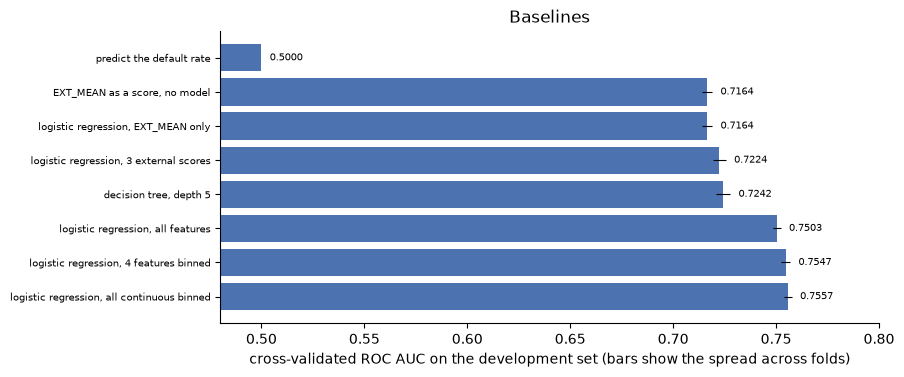

In [37]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
plot = board.iloc[::-1]
ax.barh(plot.index, plot['roc_auc'].astype(float), xerr=plot['fold_std'].astype(float), color='#4C72B0', error_kw={'elinewidth': 0.8, 'ecolor': 'black'})
ax.set_xlim(0.48, 0.80)
for i, (name, r) in enumerate(plot.iterrows()):
    ax.text(float(r['roc_auc']) + float(r['fold_std']) + 0.004, i, f"{r['roc_auc']:.4f}", va='center', fontsize=7)
ax.set_xlabel('cross-validated ROC AUC on the development set (bars show the spread across folds)')
ax.set_title('Baselines')
ax.tick_params(axis='y', labelsize=7)
sns.despine()
plt.show()

### 4.8 Looking inside the logistic regression

Three views of the plain logistic regression on all features: its largest coefficients, how well its probabilities match reality, and how it ranks applicants. The coefficients come from a model fitted on the whole development set. The other two use the out-of-fold predictions.

In [38]:
fitted_lr = make_model_pipeline(make_linear_preprocessor(), logistic()).fit(X_dev, y_dev)
names = fitted_lr.named_steps['preprocess'].get_feature_names_out()
coef = pd.Series(fitted_lr.named_steps['model'].coef_[0], index=names)

# numeric columns are standardised, so their coefficients are comparable: the change in log-odds for one standard deviation
numeric_coef = coef[LOG_FEATURES + SCALE_FEATURES].sort_values()
print('largest coefficients among the standardised numeric features')
print(pd.concat([numeric_coef.head(8), numeric_coef.tail(8)]).round(3).to_string())

print('\nlargest coefficients among flags and one-hot levels (0 or 1 columns)')
other = coef.drop(LOG_FEATURES + SCALE_FEATURES).sort_values()
print(pd.concat([other.head(6), other.tail(6)]).round(3).to_string())
print(f"\nintercept {fitted_lr.named_steps['model'].intercept_[0]:.3f}; coefficients with absolute value under 0.01: {int((coef.abs() < 0.01).sum())} of {len(coef)}")

largest coefficients among the standardised numeric features
ANNUITY_TO_CREDIT   -0.560
CREDIT_TO_INCOME    -0.420
EXT_SOURCE_3        -0.394
AMT_GOODS_PRICE     -0.321
AMT_CREDIT          -0.287
EXT_SOURCE_2        -0.254
EXT_MIN             -0.209
AMT_INCOME_TOTAL    -0.177
CNT_FAM_MEMBERS      0.083
CREDIT_TO_GOODS      0.098
EXT_MAX              0.103
N_CITY_MISMATCH      0.120
DAYS_EMPLOYED        0.137
ANNUITY_TO_INCOME    0.170
EXT_N_MISSING        0.225
AMT_ANNUITY          0.774

largest coefficients among flags and one-hot levels (0 or 1 columns)
FLAG_OWN_CAR_Y                        -0.558
CODE_GENDER_F                         -0.484
FLAG_EMP_PHONE                        -0.475
ORGANIZATION_TYPE_Military            -0.442
NAME_CONTRACT_TYPE_Revolving loans    -0.393
NAME_HOUSING_TYPE_Office apartment    -0.383
ORGANIZATION_TYPE_Self-employed        0.164
FLAG_WORK_PHONE                        0.171
FLAG_DOCUMENT_3                        0.193
OCCUPATION_TYPE_Low-skill Labore

In [39]:
pred = lr['oof']
tenth = pd.qcut(pred, 10, labels=[f"D{i}" for i in range(1, 11)])
lift = pd.DataFrame({'y': y_dev.values, 'p': pred}).groupby(tenth, observed=True).agg(rows=('y', 'size'), defaults=('y', 'sum'),
                                                                                     actual_default_pct=('y', 'mean'), predicted_pct=('p', 'mean'))
lift[['actual_default_pct', 'predicted_pct']] *= 100
lift['share_of_defaults_pct'] = lift['defaults'] / lift['defaults'].sum() * 100
print(f"mean predicted probability {pred.mean():.4f}, actual default rate {y_dev.mean():.4f}")
print(f"riskiest tenth holds {lift['share_of_defaults_pct'].iloc[-1]:.1f}% of defaults; riskiest three tenths hold {lift['share_of_defaults_pct'].iloc[-3:].sum():.1f}%")
print(f"largest gap between predicted and actual rate in any tenth: {(lift['predicted_pct'] - lift['actual_default_pct']).abs().max():.2f} points")
print(holdout)
assert holdout.log == []
lift.round(2)

mean predicted probability 0.0807, actual default rate 0.0807
riskiest tenth holds 32.4% of defaults; riskiest three tenths hold 63.9%
largest gap between predicted and actual rate in any tenth: 0.34 points
HoldoutVault(61,503 rows, 4,965 defaults, opened 0 times)


,rows,defaults,actual_default_pct,predicted_pct,share_of_defaults_pct
D1,24601,328,1.33,1.20,1.65
D2,24601,537,2.18,2.11,2.70
D3,24601,718,2.92,2.92,3.62
D4,24600,914,3.72,3.82,4.60
D5,24601,1226,4.98,4.87,6.17
D6,24601,1535,6.24,6.19,7.73
D7,24600,1911,7.77,7.95,9.62
D8,24601,2549,10.36,10.46,12.83
D9,24601,3699,15.04,14.69,18.63
D10,24601,6443,26.19,26.49,32.44


### Stage 4 findings

**The baselines, on the same five development folds**

| Baseline | Columns | ROC AUC | PR AUC | Log loss |
|---|---:|---:|---:|---:|
| Predict the default rate for everyone | 0 | 0.5000 | 0.081 | 0.2805 |
| `EXT_MEAN` as a score, no model | 1 | 0.7164 | 0.189 | |
| Logistic regression, `EXT_MEAN` only | 1 | 0.7164 | 0.189 | 0.2576 |
| Logistic regression, three external scores | 3 | 0.7224 | 0.200 | 0.2558 |
| Decision tree, depth 5 | 55 | 0.7242 | 0.196 | 0.2552 |
| Logistic regression, all features | 157 | 0.7503 | 0.231 | 0.2485 |
| Logistic regression, 4 features binned | 197 | 0.7547 | 0.236 | 0.2474 |
| Logistic regression, all continuous features binned | 412 | 0.7557 | 0.239 | 0.2470 |

**What each step adds**
- One number gets most of the way. `EXT_MEAN` alone scores 0.7164, and a logistic regression on it scores the same, because the model only rescales it. What the model adds is a probability: log loss falls from 0.2805 to 0.2576.
- The three external scores separately add 0.006 over their mean.
- A single decision tree of depth 5 reaches 0.7242, barely above the external scores alone. One small tree cannot use 55 features.
- Logistic regression on all features reaches 0.7503. That is 0.034 above `EXT_MEAN`, in all five folds, and it is the gain from the other 50 or so features.

**Logistic regression is stable and insensitive to its setting**
- The fold standard deviation is 0.0020, and the solver converges in about 60 iterations.
- The regularisation strength `C` makes no difference between 0.01 and 10 (0.7502 to 0.7503). Only very strong regularisation at 0.001 costs anything (0.0019). There is nothing to tune here.

**Binning helps, as the EDA predicted**
- Binning the four features with non-linear relationships (`ANNUITY_TO_CREDIT`, `AMT_CREDIT`, `AMT_ANNUITY`, `AMT_GOODS_PRICE`) adds 0.0045, in every fold, with a fold-by-fold spread of 0.0007.
- Binning all 30 continuous features adds 0.0054 in total. Most of the benefit comes from the first four.
- A linear model with binned features reaches 0.7557. This is the strongest baseline, and the score the models in stage 5 must clearly beat.

**The leak that stage 3 prevents is tiny here**
- Fitting the preprocessing on all rows instead of inside each fold changes the AUC by +0.00006 and the log loss by -0.00001.
- This preprocessing only computes medians, scaling values and level lists, none of which involve the target, and they barely move between folds. The rule costs nothing to follow and will matter much more for resampling in stage 6 and feature selection in stage 8.

**The probabilities are well calibrated**
- The mean predicted probability equals the actual default rate (8.07%).
- Predicted and actual rates agree to within 0.34 percentage points in every tenth of applicants.
- The riskiest tenth holds 32% of all defaults and the riskiest three tenths hold 64%.

**The coefficients cannot be read at face value**
- The largest are `AMT_ANNUITY` (+0.77) and `ANNUITY_TO_CREDIT` (-0.56), with `CREDIT_TO_INCOME`, `AMT_GOODS_PRICE` and `AMT_CREDIT` between -0.29 and -0.42. These five are built from the same three amounts, so the model is balancing them against each other.
- The same happens with the external scores: `EXT_MIN` is negative and `EXT_MAX` positive.
- `FLAG_EMP_PHONE` has a coefficient of -0.48, although the EDA found applicants with that flag default more. Several other columns carry the same "has an employer" information, and the model splits the effect between them.
- This is the redundancy from stage 9 of the EDA. It does not hurt the predictions. It does mean a coefficient cannot be quoted as "the effect of" a feature. A scorecard-style model would need the redundant columns removed first.

**Decisions**
- The main baseline is logistic regression on all features: 0.7503 plain and 0.7557 with binned features.
- The binned logistic regression goes forward into stage 5 as the linear candidate, alongside the tree-based models.
- A model in stage 5 counts as better only if it beats 0.7557 fold by fold. The fold-by-fold spread of a difference has been about 0.001, so a gain of a few thousandths is detectable.
- Keep `C` at its default.
- The holdout is still unopened.

## Stage 5: Candidate models

Which model family is best, before any tuning?

Six candidates are scored on the same five development folds: the binned logistic regression from stage 4, a random forest, and four gradient boosting libraries (scikit-learn, LightGBM, XGBoost and CatBoost).

The boosting libraries are compared in two rounds, because "default settings" means something different in each:

| Round | Settings | Why |
|---|---|---|
| A. Out of the box | Each library's own defaults, with only the random seed set | What you get with no effort. But the defaults differ: LightGBM and XGBoost build 100 trees, CatBoost builds 1,000 |
| B. Equal budget | The same learning rate (0.05) for all, up to 3,000 trees, stopping when the score stops improving | A fairer comparison. Each library gets to choose its own number of trees |

**Early stopping without leakage.** In round B a model must decide when to stop adding trees. If it watched the validation fold to decide, that fold would be helping to train the model that is then scored on it. So the decision uses a separate 15% slice of the training folds. The validation fold is not seen until the model is finished.

### 5.1 Early stopping inside the training folds

In [40]:
import lightgbm as lgb
from sklearn.base import ClassifierMixin
from sklearn.ensemble import RandomForestClassifier

class EarlyStopping(ClassifierMixin, BaseEstimator):
    # Wraps a boosting model. Of the rows it is given, 15% are set aside to decide when to stop adding trees.
    # It only ever receives training-fold rows, so the validation fold plays no part in that decision.
    def __init__(self, model, library, validation_fraction=0.15, patience=100, seed=SEED):
        self.model = model
        self.library = library
        self.validation_fraction = validation_fraction
        self.patience = patience
        self.seed = seed

    def fit(self, X, y, cat_features=None):
        y = np.asarray(y)
        grow, watch = train_test_split(np.arange(len(y)), test_size=self.validation_fraction, stratify=y, random_state=self.seed)
        X_grow, y_grow, X_watch, y_watch = X.iloc[grow], y[grow], X.iloc[watch], y[watch]
        model = clone(self.model)
        if self.library == 'lightgbm':
            model.fit(X_grow, y_grow, eval_set=[(X_watch, y_watch)], eval_metric='auc', callbacks=[lgb.early_stopping(self.patience, verbose=False)])
            trees = model.best_iteration_
        elif self.library == 'xgboost':
            model.set_params(early_stopping_rounds=self.patience, eval_metric='auc')
            model.fit(X_grow, y_grow, eval_set=[(X_watch, y_watch)], verbose=False)
            trees = model.best_iteration + 1
        elif self.library == 'catboost':
            model.fit(X_grow, y_grow, eval_set=(X_watch, y_watch), early_stopping_rounds=self.patience, cat_features=cat_features)
            trees = model.get_best_iteration() + 1
        else:
            raise ValueError(self.library)
        self.model_, self.n_trees_, self.classes_ = model, int(trees), np.array([0, 1])
        return self

    def predict_proba(self, X):
        return self.model_.predict_proba(X)

# LightGBM 4.7 announces that the eval_set argument will be renamed. The call still works, so that one message is silenced.
warnings.filterwarnings('ignore', message="The argument 'eval_set' is deprecated")

LEARNING_RATE, MAX_TREES = 0.05, 3000
print(f"round B: learning rate {LEARNING_RATE}, at most {MAX_TREES} trees, stop after 100 rounds without improvement on a 15% slice of the training folds")

round B: learning rate 0.05, at most 3000 trees, stop after 100 rounds without improvement on a 15% slice of the training folds


### 5.2 Round A: out of the box

The random forest is the one exception to "defaults". scikit-learn's default grows 100 fully deep trees, which is slow on 197,000 rows and overfits badly. It is given 300 trees and a minimum of 20 rows per leaf, which is a conventional starting point.

In [41]:
round_a = {
    'random forest': (make_model_pipeline(make_tree_preprocessor('code'),
                      RandomForestClassifier(n_estimators=300, min_samples_leaf=20, n_jobs=-1, random_state=SEED)), None),
    'scikit-learn boosting, default': (make_model_pipeline(make_tree_preprocessor('code'),
                      HistGradientBoostingClassifier(random_state=SEED, categorical_features=TEXT_FEATURES)), None),
    'LightGBM, default': (make_model_pipeline(make_tree_preprocessor('category'), LGBMClassifier(random_state=SEED, verbose=-1)), None),
    'XGBoost, default': (make_model_pipeline(make_tree_preprocessor('category'),
                      XGBClassifier(random_state=SEED, enable_categorical=True, tree_method='hist')), None),
    'CatBoost, default': (make_model_pipeline(make_tree_preprocessor('string'), CatBoostClassifier(random_seed=SEED, verbose=0)), CATBOOST_FIT_PARAMS),
}
for name, (pipe, fit_params) in round_a.items():
    register(name, cross_validate(pipe, fit_params=fit_params), columns=len(FEATURES), note='round A')
    print(f"{name:<32} AUC {results[name]['mean']['roc_auc']:.4f}   {results[name]['mean']['fit_seconds']:7.1f}s per fold   "
          f"{'loaded from cache' if results[name]['cached'] else 'fitted now'}")

random forest                    AUC 0.7489      94.7s per fold   loaded from cache


scikit-learn boosting, default   AUC 0.7593       6.1s per fold   loaded from cache


LightGBM, default                AUC 0.7612       3.9s per fold   loaded from cache


XGBoost, default                 AUC 0.7459       5.6s per fold   loaded from cache


CatBoost, default                AUC 0.7643     343.7s per fold   loaded from cache


### 5.3 Round B: equal budget with early stopping

In [42]:
round_b = {
    'scikit-learn boosting, early stopping': (make_model_pipeline(make_tree_preprocessor('code'),
        HistGradientBoostingClassifier(random_state=SEED, categorical_features=TEXT_FEATURES, learning_rate=LEARNING_RATE, max_iter=MAX_TREES,
                                       early_stopping=True, validation_fraction=0.15, n_iter_no_change=100, scoring='roc_auc')), None),
    'LightGBM, early stopping': (make_model_pipeline(make_tree_preprocessor('category'),
        EarlyStopping(LGBMClassifier(n_estimators=MAX_TREES, learning_rate=LEARNING_RATE, random_state=SEED, verbose=-1), 'lightgbm')), None),
    'XGBoost, early stopping': (make_model_pipeline(make_tree_preprocessor('category'),
        EarlyStopping(XGBClassifier(n_estimators=MAX_TREES, learning_rate=LEARNING_RATE, random_state=SEED, enable_categorical=True, tree_method='hist'), 'xgboost')), None),
    'CatBoost, early stopping': (make_model_pipeline(make_tree_preprocessor('string'),
        EarlyStopping(CatBoostClassifier(iterations=MAX_TREES, learning_rate=LEARNING_RATE, random_seed=SEED, verbose=0, eval_metric='AUC'), 'catboost')),
        CATBOOST_FIT_PARAMS),
}
for name, (pipe, fit_params) in round_b.items():
    register(name, cross_validate(pipe, fit_params=fit_params), columns=len(FEATURES), note='round B')
    r = results[name]
    print(f"{name:<38} AUC {r['mean']['roc_auc']:.4f}   {r['mean']['fit_seconds']:7.1f}s per fold   trees per fold {r['folds']['rounds'].astype(int).tolist()}   "
          f"{'loaded from cache' if r['cached'] else 'fitted now'}")

scikit-learn boosting, early stopping  AUC 0.7595      28.9s per fold   trees per fold [408, 271, 297, 268, 376]   loaded from cache


LightGBM, early stopping               AUC 0.7603       9.6s per fold   trees per fold [265, 308, 284, 129, 459]   loaded from cache


XGBoost, early stopping                AUC 0.7595      25.6s per fold   trees per fold [223, 278, 244, 143, 280]   loaded from cache


CatBoost, early stopping               AUC 0.7644     493.0s per fold   trees per fold [1158, 1259, 1237, 507, 1113]   loaded from cache


### 5.4 The comparison

`against_linear` is the fold-by-fold difference from the strongest baseline, the binned logistic regression (0.7557). `folds_better` counts the folds in which the model beats it.

In [43]:
LINEAR = 'logistic regression, all continuous binned'
candidates = [LINEAR, 'logistic regression, all features'] + list(round_a) + list(round_b)

board = leaderboard(candidates)[['roc_auc', 'fold_std', 'pr_auc', 'log_loss', 'brier', 'fit_seconds']]
versus = pd.DataFrame({n: compare(n, LINEAR) for n in board.index}).T
board['against_linear'] = versus['mean_difference']
board['difference_std'] = versus['difference_std']
board['folds_better'] = versus['folds_better'].astype(int)
# round A models build a fixed number of trees. Round B models, and scikit-learn's default, stop early and report how many they built.
FIXED_TREES = {'random forest': 300, 'LightGBM, default': 100, 'XGBoost, default': 100, 'CatBoost, default': 1000}
board['trees'] = [FIXED_TREES.get(n, np.nan if 'logistic' in n else results[n]['folds']['rounds'].mean()) for n in board.index]
board['minutes_for_5_folds'] = board['fit_seconds'] * N_SPLITS / 60

print('ROC AUC by fold')
print(pd.DataFrame({n: results[n]['folds']['roc_auc'] for n in board.index}).T.round(4).to_string())
board.round({'roc_auc': 4, 'fold_std': 4, 'pr_auc': 4, 'log_loss': 4, 'brier': 4, 'fit_seconds': 1, 'against_linear': 4, 'difference_std': 4, 'trees': 0, 'minutes_for_5_folds': 1})

ROC AUC by fold
fold                                             0       1       2       3       4
CatBoost, early stopping                    0.7642  0.7641  0.7642  0.7629  0.7665
CatBoost, default                           0.7641  0.7639  0.7629  0.7639  0.7668
LightGBM, default                           0.7607  0.7608  0.7601  0.7608  0.7634
LightGBM, early stopping                    0.7609  0.7597  0.7596  0.7604  0.7610
XGBoost, early stopping                     0.7593  0.7581  0.7600  0.7592  0.7609
scikit-learn boosting, early stopping       0.7590  0.7590  0.7580  0.7593  0.7622
scikit-learn boosting, default              0.7579  0.7600  0.7568  0.7599  0.7617
logistic regression, all continuous binned  0.7562  0.7538  0.7543  0.7551  0.7588
logistic regression, all features           0.7504  0.7498  0.7497  0.7479  0.7534
random forest                               0.7475  0.7511  0.7475  0.7474  0.7510
XGBoost, default                            0.7473  0.7451  0.7435  0.7

,roc_auc,fold_std,pr_auc,log_loss,brier,fit_seconds,against_linear,difference_std,folds_better,trees,minutes_for_5_folds
"CatBoost, early stopping",0.7644,0.0013,0.2478,0.2445,0.0676,493.0,0.0087,0.0013,5,1055.0,41.1
"CatBoost, default",0.7643,0.0015,0.2438,0.2449,0.0678,343.7,0.0087,0.0009,5,1000.0,28.6
"LightGBM, default",0.7612,0.0013,0.2449,0.2454,0.0677,3.9,0.0055,0.0010,5,100.0,0.3
"LightGBM, early stopping",0.7603,0.0006,0.2447,0.2457,0.0678,9.6,0.0047,0.0015,5,289.0,0.8
"XGBoost, early stopping",0.7595,0.0010,0.2428,0.2459,0.0678,25.6,0.0039,0.0013,5,234.0,2.1
"scikit-learn boosting, early stopping",0.7595,0.0016,0.2425,0.2459,0.0678,28.9,0.0038,0.0009,5,324.0,2.4
"scikit-learn boosting, default",0.7593,0.0019,0.2414,0.2460,0.0679,6.1,0.0036,0.0018,5,84.0,0.5
"logistic regression, all continuous binned",0.7557,0.0020,0.2387,0.2470,0.0680,17.4,0.0000,0.0000,0,NaN,1.4
"logistic regression, all features",0.7503,0.0020,0.2310,0.2485,0.0684,9.3,-0.0054,0.0012,0,NaN,0.8
random forest,0.7489,0.0020,0.2321,0.2490,0.0684,94.7,-0.0068,0.0023,0,300.0,7.9


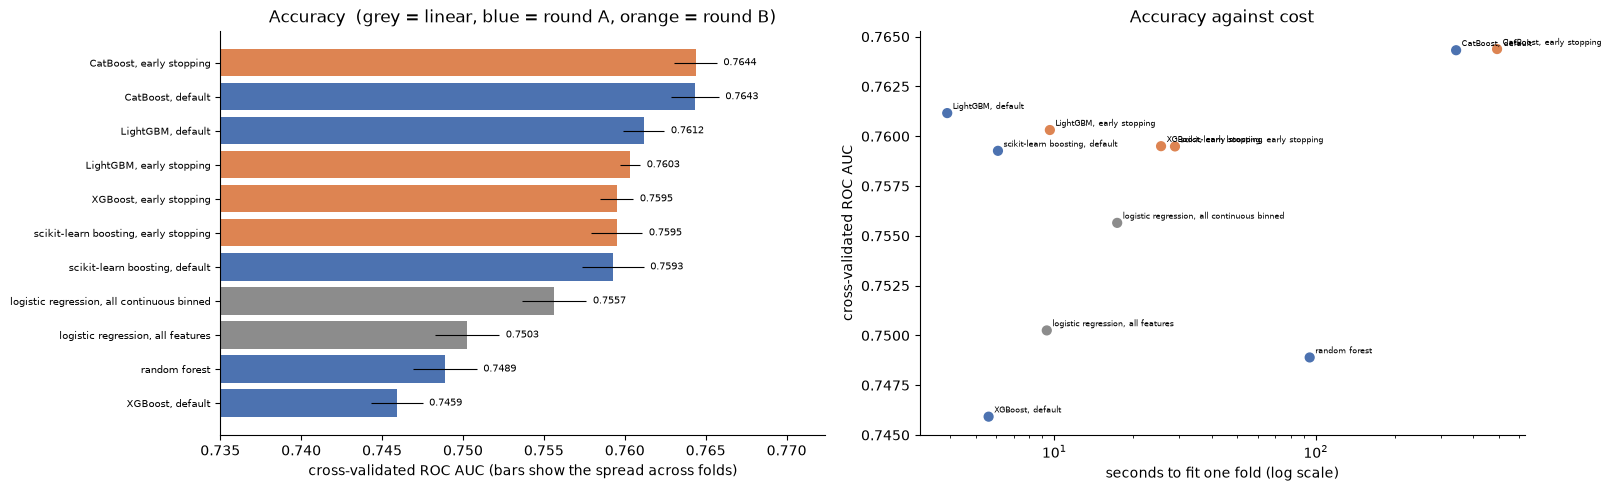

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), layout='constrained')
plot = board.iloc[::-1]
colors = ['#8C8C8C' if 'logistic' in n else '#DD8452' if 'early stopping' in n else '#4C72B0' for n in plot.index]
axes[0].barh(plot.index, plot['roc_auc'].astype(float), xerr=plot['fold_std'].astype(float), color=colors, error_kw={'elinewidth': 0.8, 'ecolor': 'black'})
axes[0].set_xlim(0.735, plot['roc_auc'].max() + 0.008)
for i, (name, r) in enumerate(plot.iterrows()):
    axes[0].text(float(r['roc_auc']) + float(r['fold_std']) + 0.0004, i, f"{r['roc_auc']:.4f}", va='center', fontsize=7)
axes[0].set_xlabel('cross-validated ROC AUC (bars show the spread across folds)')
axes[0].set_title('Accuracy  (grey = linear, blue = round A, orange = round B)')
axes[0].tick_params(axis='y', labelsize=7)

axes[1].scatter(board['fit_seconds'].astype(float), board['roc_auc'].astype(float), c=['#8C8C8C' if 'logistic' in n else '#DD8452' if 'early stopping' in n else '#4C72B0' for n in board.index], s=40)
for name, r in board.iterrows():
    axes[1].annotate(name, (float(r['fit_seconds']), float(r['roc_auc'])), fontsize=6, xytext=(4, 3), textcoords='offset points')
axes[1].set_xscale('log')
axes[1].set_xlabel('seconds to fit one fold (log scale)')
axes[1].set_ylabel('cross-validated ROC AUC')
axes[1].set_title('Accuracy against cost')
sns.despine()
plt.show()

### 5.5 Head to head among the leaders

The leaders are compared with each other directly, fold by fold. A gap smaller than its own fold-by-fold spread is not a real difference.

In [45]:
boosters = [n for n in board.index if 'logistic' not in n and 'random forest' not in n]
best = board.index[0]
head = pd.DataFrame({n: compare(best, n) for n in boosters if n != best}).T
head.index.name = f"'{best}' minus"
head['clear_win'] = (head['folds_better'] == N_SPLITS) & (head['mean_difference'] > 2 * head['difference_std'] / np.sqrt(N_SPLITS))
print(head.round(4).to_string())

print('\ngain from round B over round A, same library')
for library in ['scikit-learn boosting', 'LightGBM', 'XGBoost', 'CatBoost']:
    c = compare(f'{library}, early stopping', f'{library}, default')
    print(f"  {library:<22} {c['mean_difference']:+.4f}  (spread {c['difference_std']:.4f}, better in {c['folds_better']} of {N_SPLITS} folds)")

                                       mean_difference  difference_std  folds_better  smallest  largest  clear_win
'CatBoost, early stopping' minus                                                                                  
CatBoost, default                               0.0001          0.0009           3.0   -0.0011   0.0014      False
LightGBM, default                               0.0032          0.0008           5.0    0.0020   0.0041       True
LightGBM, early stopping                        0.0041          0.0012           5.0    0.0025   0.0055       True
XGBoost, early stopping                         0.0049          0.0010           5.0    0.0037   0.0060       True
scikit-learn boosting, early stopping           0.0049          0.0010           5.0    0.0036   0.0062       True
scikit-learn boosting, default                  0.0051          0.0018           5.0    0.0029   0.0074       True
XGBoost, default                                0.0185          0.0019          

### 5.6 Do the models agree, and does blending them help?

If two models rank applicants almost identically, combining them adds little. If they disagree while being similarly accurate, an average of the two can beat both. The blend below averages the ranks of the out-of-fold predictions.

In [46]:
from scipy.stats import rankdata

compared = [LINEAR, 'random forest', 'scikit-learn boosting, early stopping', 'LightGBM, early stopping', 'XGBoost, early stopping', 'CatBoost, early stopping']
short = {LINEAR: 'linear', 'random forest': 'forest', 'scikit-learn boosting, early stopping': 'sklearn', 'LightGBM, early stopping': 'LightGBM',
         'XGBoost, early stopping': 'XGBoost', 'CatBoost, early stopping': 'CatBoost'}
oof = pd.DataFrame({short[n]: results[n]['oof'] for n in compared})
print('rank correlation between out-of-fold predictions')
print(oof.corr(method='spearman').round(3).to_string())

def blend_auc(members):
    ranks = np.mean([rankdata(results[m]['oof']) for m in members], axis=0)
    return np.array([roc_auc_score(y_dev[dev_fold == k], ranks[dev_fold == k]) for k in range(N_SPLITS)])

best_single = results[best]['folds']['roc_auc'].values
blends = {
    'LightGBM + CatBoost': ['LightGBM, early stopping', 'CatBoost, early stopping'],
    'LightGBM + XGBoost + CatBoost': ['LightGBM, early stopping', 'XGBoost, early stopping', 'CatBoost, early stopping'],
    'all four boosting libraries': list(round_b),
    'best single model + linear': [best, LINEAR],
    'four boosting libraries + linear': list(round_b) + [LINEAR],
}
rows = {}
for label, members in blends.items():
    a = blend_auc(members)
    rows[label] = {'roc_auc': a.mean(), 'against_best_single': (a - best_single).mean(), 'difference_std': (a - best_single).std(ddof=1),
                   'folds_better': int((a > best_single).sum())}
print(f"\nbest single model: {best} ({best_single.mean():.4f})")
pd.DataFrame(rows).T.round(4)

rank correlation between out-of-fold predictions


          linear  forest  sklearn  LightGBM  XGBoost  CatBoost
linear     1.000   0.900    0.926     0.928    0.920     0.942
forest     0.900   1.000    0.905     0.908    0.893     0.915
sklearn    0.926   0.905    1.000     0.958    0.952     0.944
LightGBM   0.928   0.908    0.958     1.000    0.965     0.952
XGBoost    0.920   0.893    0.952     0.965    1.000     0.945
CatBoost   0.942   0.915    0.944     0.952    0.945     1.000



best single model: CatBoost, early stopping (0.7644)


,roc_auc,against_best_single,difference_std,folds_better
LightGBM + CatBoost,0.7648,0.0004,0.0003,5.0
LightGBM + XGBoost + CatBoost,0.7645,0.0001,0.0003,3.0
all four boosting libraries,0.7644,0.0001,0.0004,3.0
best single model + linear,0.7631,-0.0013,0.0006,0.0
four boosting libraries + linear,0.7644,0.0001,0.0006,3.0


### 5.7 Are the probabilities usable as they come?

AUC only measures ranking. A lender also needs the predicted probability to mean what it says. For each model: the average predicted probability against the actual default rate, and the largest gap between predicted and actual rate across tenths of applicants.

In [47]:
rows = {}
for n in [LINEAR, 'random forest'] + list(round_b):
    p = results[n]['oof']
    tenth = pd.qcut(p, 10, labels=False, duplicates='drop')
    by = pd.DataFrame({'y': y_dev.values, 'p': p}).groupby(tenth).mean() * 100
    rows[n] = {'mean_predicted_pct': p.mean() * 100, 'actual_pct': y_dev.mean() * 100, 'largest_gap_in_a_tenth_pts': (by['p'] - by['y']).abs().max(),
               'top_tenth_predicted_pct': by['p'].iloc[-1], 'top_tenth_actual_pct': by['y'].iloc[-1], 'log_loss': results[n]['mean']['log_loss']}
calibration = pd.DataFrame(rows).T
print(holdout)
assert holdout.log == []
calibration.round(3)

HoldoutVault(61,503 rows, 4,965 defaults, opened 0 times)


,mean_predicted_pct,actual_pct,largest_gap_in_a_tenth_pts,top_tenth_predicted_pct,top_tenth_actual_pct,log_loss
"logistic regression, all continuous binned",8.073,8.073,0.751,27.579,26.828,0.247
random forest,8.173,8.073,1.379,24.705,26.084,0.249
"scikit-learn boosting, early stopping",7.994,8.073,0.535,27.835,27.300,0.246
"LightGBM, early stopping",8.012,8.073,0.557,27.779,27.222,0.246
"XGBoost, early stopping",7.967,8.073,0.759,27.851,27.092,0.246
"CatBoost, early stopping",8.007,8.073,0.476,27.643,27.556,0.245


### Stage 5 findings

**The comparison**

| Model | ROC AUC | Against the linear baseline | Folds better | Trees | Minutes for 5 folds |
|---|---:|---:|---:|---:|---:|
| CatBoost, early stopping | 0.7644 | +0.0087 | 5 of 5 | 1,055 | 41.1 |
| CatBoost, default | 0.7643 | +0.0087 | 5 of 5 | 1,000 | 28.6 |
| LightGBM, default | 0.7612 | +0.0055 | 5 of 5 | 100 | 0.3 |
| LightGBM, early stopping | 0.7603 | +0.0047 | 5 of 5 | 289 | 0.8 |
| XGBoost, early stopping | 0.7595 | +0.0039 | 5 of 5 | 234 | 2.1 |
| scikit-learn boosting, early stopping | 0.7595 | +0.0038 | 5 of 5 | 324 | 2.4 |
| scikit-learn boosting, default | 0.7593 | +0.0036 | 5 of 5 | 84 | 0.5 |
| Logistic regression, binned (baseline) | 0.7557 | | | | 1.5 |
| Logistic regression, plain | 0.7503 | -0.0054 | 0 of 5 | | 0.8 |
| Random forest | 0.7489 | -0.0068 | 0 of 5 | 300 | 7.9 |
| XGBoost, default | 0.7459 | -0.0097 | 0 of 5 | 100 | 0.5 |

**Gradient boosting is the best family, but not by much**
- Seven of the eight boosting runs beat the binned logistic regression in all five folds. The gains are between 0.004 and 0.009.
- The whole table spans less than 0.02 of AUC. A linear model with binned features is within 0.009 of the best model here.
- The random forest is worse than the linear baseline and takes five times as long. It is dropped.

**CatBoost is the most accurate**
- It scores 0.7644 and beats every other model in all five folds: LightGBM by 0.003 to 0.004, XGBoost and scikit-learn boosting by 0.005. Those gaps are several times their fold-by-fold spread of about 0.001.
- Its default settings do as well as the equal-budget round (0.7643 against 0.7644).
- It is also the best calibrated, with the lowest log loss.

**It is also about 100 times slower than LightGBM**
- One five-fold run of CatBoost takes 29 to 41 minutes. LightGBM takes 20 to 50 seconds.
- That matters for stage 7. Fifty tuning trials would take around a day for CatBoost and under an hour for LightGBM.

**Out-of-the-box defaults are not a fair comparison**
- XGBoost's default (0.7459) is the worst boosting result and falls below the linear baseline. With a lower learning rate and early stopping it gains 0.0136 and reaches 0.7595. Its default learning rate of 0.3 is too aggressive for this data.
- For LightGBM, scikit-learn and CatBoost, the two rounds are level, within 0.001.
- LightGBM is slightly worse with early stopping (-0.0009). The early-stopped model trains on 85% of the training folds, because 15% is set aside to decide when to stop. With defaults it trains on all of them. This is a cost of the leak-free design, and stage 7 addresses it.

**The models largely agree, so blending adds little**
- Rank correlations between the boosting libraries' predictions are 0.94 to 0.97. The linear model is 0.92 to 0.94 with them.
- LightGBM and CatBoost averaged together score 0.7648. That is 0.0004 above CatBoost alone, in all five folds, so it is consistent but very small.
- Adding more models does not help further, and adding the linear model to CatBoost makes it worse (-0.0013).

**Probabilities are usable as they come**
- Every boosting model predicts an average default rate within 0.11 points of the actual 8.07%.
- Predicted and actual rates agree to within 0.5 to 0.8 points in every tenth of applicants. The random forest is the worst at 1.4 points.
- Stage 9 will check calibration properly on the chosen model. Nothing here suggests a problem.

**Decisions**
- Shortlist for stage 7: **CatBoost** and **LightGBM**.
- CatBoost is the leader on accuracy. LightGBM is the practical alternative: second on accuracy, and cheap enough to tune thoroughly, which may close a gap of 0.003.
- Dropped: random forest (worse than the baseline), XGBoost and scikit-learn boosting (level with or behind LightGBM, with no compensating advantage), and logistic regression as a candidate. The binned logistic regression stays as the reference that shows what the added complexity buys.
- Blending is noted as worth 0.0004. It is not pursued, since it would double the cost and the complexity of the final model for a gain that small. It can be revisited at the end.
- Because CatBoost is so slow, stage 7 cannot treat the two models the same way. LightGBM gets a full search. CatBoost gets a small, targeted one.
- The holdout is still unopened.

**Correction, added in stage 7**
- Stage 5 describes round B as stopping "when the score stops improving". For LightGBM that was not accurate. The wrapper asked it to watch AUC, but LightGBM also watched log loss and stopped when either one stalled. XGBoost, CatBoost and scikit-learn boosting each watched a single measure, as described.
- For the stage 5 comparison this made no difference. Section 7.3 re-scores "LightGBM, early stopping" with a corrected wrapper: 0.7603 with 292 trees, against 0.7603 with 289. The model there has no imbalance settings, so the two measures stall at about the same point.
- The stage 5 table, ranking and shortlist stand as written. The flaw mattered in stage 7, where it is explained and corrected.

## Stage 6: Class imbalance

Do class weights or resampling help, and what do they do to the predicted probabilities?

Only 8.07% of applications default, about 11 repaid loans for each one. Two families of technique are commonly used to "fix" this:

| Technique | What it does |
|---|---|
| **Class weights** | Every default counts more than every repaid loan when the model is trained. "Balanced" weights make the two classes count equally in total |
| **Undersampling** | Throw away repaid loans until the classes are closer in size |
| **Oversampling** | Duplicate defaults, or invent synthetic ones (SMOTE), until the classes are closer in size |

The question is whether any of them improves the model, measured two ways: how well it **ranks** applicants (ROC AUC and PR AUC) and how well its **probabilities** match reality (log loss, and the average predicted default rate against the true 8.07%).

**Leakage.** Resampling changes the rows, so where it happens matters more than for anything so far. If defaults are duplicated before the data is split into folds, copies of the same applicant land in both the training folds and the validation fold, and the model is scored on rows it has memorised. Here the resampling step sits inside the pipeline, so it is applied to the training folds only. The validation fold is never resampled: it keeps its real 8.07% default rate. Section 6.6 shows what happens when this is done wrongly.

### 6.1 Resampling inside the pipeline

In [48]:
from imblearn.pipeline import Pipeline as SamplingPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE

def make_sampled_pipeline(preprocessor, sampler, model):
    # the sampler runs during fit only. At prediction time the pipeline skips it.
    return SamplingPipeline([('preprocess', preprocessor), ('sample', sampler), ('model', model)])

class UndersampleBagging(ClassifierMixin, BaseEstimator):
    # Several models, each trained on all the defaults plus a different random sample of repaid loans.
    # Their predictions are averaged. This uses undersampling without discarding most of the data for good.
    def __init__(self, model, n_models=10, negatives_per_positive=1.0, seed=SEED):
        self.model = model
        self.n_models = n_models
        self.negatives_per_positive = negatives_per_positive
        self.seed = seed

    def fit(self, X, y):
        y = np.asarray(y)
        positives, negatives = np.where(y == 1)[0], np.where(y == 0)[0]
        rng = np.random.default_rng(self.seed)
        self.models_ = []
        for _ in range(self.n_models):
            chosen = rng.choice(negatives, size=int(len(positives) * self.negatives_per_positive), replace=False)
            rows = np.sort(np.concatenate([positives, chosen]))
            self.models_.append(clone(self.model).fit(X.iloc[rows], y[rows]))
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        return np.mean([m.predict_proba(X) for m in self.models_], axis=0)

# what each sampler does to one set of training folds, and that the validation fold is left alone
fit_rows, val_rows = dev_fold != 0, dev_fold == 0
encoded = make_tree_preprocessor('category').fit(X_dev[fit_rows]).transform(X_dev[fit_rows])
RATIO = float((y_dev == 0).sum() / (y_dev == 1).sum())
samplers = {
    'none': None,
    'undersample to 1:1': RandomUnderSampler(sampling_strategy=1.0, random_state=SEED),
    'undersample to 1:3': RandomUnderSampler(sampling_strategy=1 / 3, random_state=SEED),
    'oversample to 1:1': RandomOverSampler(sampling_strategy=1.0, random_state=SEED),
}
rows = {}
for label, sampler in samplers.items():
    Xs, ys = (encoded, y_dev[fit_rows]) if sampler is None else clone(sampler).fit_resample(encoded, y_dev[fit_rows])
    rows[label] = {'training_rows': len(ys), 'defaults': int(np.sum(ys)), 'repaid': int(len(ys) - np.sum(ys)), 'default_pct': np.mean(ys) * 100,
                   'column_types_kept': list(Xs.dtypes.astype(str)) == list(encoded.dtypes.astype(str))}
print(pd.DataFrame(rows).T.to_string())
print(f"\nvalidation fold, never resampled: {int(val_rows.sum()):,} rows, {y_dev[val_rows].mean():.2%} default")
print(f"repaid loans per default in the development set: {RATIO:.2f}")

probe = make_sampled_pipeline(make_tree_preprocessor('category'), RandomUnderSampler(sampling_strategy=1.0, random_state=SEED),
                              LGBMClassifier(random_state=SEED, verbose=-1)).fit(X_dev[fit_rows], y_dev[fit_rows])
print(f"a fitted pipeline with undersampling returns one prediction per validation row: {len(probe.predict_proba(X_dev[val_rows])) == int(val_rows.sum())}")

                   training_rows defaults  repaid default_pct column_types_kept
none                      196806    15888  180918    8.072925              True
undersample to 1:1         31776    15888   15888        50.0              True
undersample to 1:3         63552    15888   47664        25.0              True
oversample to 1:1         361836   180918  180918        50.0              True

validation fold, never resampled: 49,202 rows, 8.07% default
repaid loans per default in the development set: 11.39


a fitted pipeline with undersampling returns one prediction per validation row: True


### 6.2 LightGBM with each technique

LightGBM is used as the test model because it is fast enough to try everything. Each variant is the default LightGBM from stage 5 with one change. The first row is that model unchanged.

In [49]:
def lgbm(**extra):
    return LGBMClassifier(random_state=SEED, verbose=-1, **extra)

tree_pre = lambda: make_tree_preprocessor('category')
imbalance_lgbm = {
    'LightGBM, default': None,   # already scored in stage 5
    'LightGBM, balanced class weights': make_model_pipeline(tree_pre(), lgbm(class_weight='balanced')),
    'LightGBM, defaults weighted 3.4x': make_model_pipeline(tree_pre(), lgbm(scale_pos_weight=round(float(np.sqrt(RATIO)), 2))),
    'LightGBM, undersample to 1:1': make_sampled_pipeline(tree_pre(), RandomUnderSampler(sampling_strategy=1.0, random_state=SEED), lgbm()),
    'LightGBM, undersample to 1:3': make_sampled_pipeline(tree_pre(), RandomUnderSampler(sampling_strategy=1 / 3, random_state=SEED), lgbm()),
    'LightGBM, oversample to 1:1': make_sampled_pipeline(tree_pre(), RandomOverSampler(sampling_strategy=1.0, random_state=SEED), lgbm()),
    'LightGBM, 10 undersampled models averaged': make_model_pipeline(tree_pre(), UndersampleBagging(lgbm(), n_models=10)),
}
for name, pipe in imbalance_lgbm.items():
    if pipe is not None:
        register(name, cross_validate(pipe), columns=len(FEATURES), note='stage 6')

# how much each technique multiplies the odds of default that the model sees in training
ODDS_MULTIPLIER = {
    'LightGBM, default': 1.0,
    'LightGBM, balanced class weights': RATIO,
    'LightGBM, defaults weighted 3.4x': round(float(np.sqrt(RATIO)), 2),
    'LightGBM, undersample to 1:1': RATIO,
    'LightGBM, undersample to 1:3': RATIO / 3,
    'LightGBM, oversample to 1:1': RATIO,
    'LightGBM, 10 undersampled models averaged': RATIO,
}

def correct_for_prior(p, multiplier):
    # undo a known inflation of the odds: odds_true = odds_predicted / multiplier
    p = np.clip(p, 1e-9, 1 - 1e-9)
    return p / (p + multiplier * (1 - p))

def imbalance_table(names, reference, multipliers):
    rows = {}
    for n in names:
        r, c = results[n], compare(n, reference)
        p = r['oof']
        corrected = correct_for_prior(p, multipliers[n])
        rows[n] = {'roc_auc': r['mean']['roc_auc'], 'auc_change': c['mean_difference'], 'folds_better': c['folds_better'],
                   'pr_auc': r['mean']['pr_auc'], 'log_loss': r['mean']['log_loss'], 'mean_predicted_pct': p.mean() * 100,
                   'log_loss_after_correction': log_loss(y_dev, np.clip(corrected, 1e-7, 1 - 1e-7)),
                   'mean_predicted_pct_after_correction': corrected.mean() * 100, 'fit_seconds': r['mean']['fit_seconds']}
    return pd.DataFrame(rows).T

lgbm_table = imbalance_table(list(imbalance_lgbm), 'LightGBM, default', ODDS_MULTIPLIER)
print(f"actual default rate: {y_dev.mean() * 100:.2f}%   log loss of always predicting it: 0.2805")
lgbm_table.round({'roc_auc': 4, 'auc_change': 4, 'pr_auc': 4, 'log_loss': 4, 'mean_predicted_pct': 2, 'log_loss_after_correction': 4,
                  'mean_predicted_pct_after_correction': 2, 'fit_seconds': 1})

actual default rate: 8.07%   log loss of always predicting it: 0.2805


,roc_auc,auc_change,folds_better,pr_auc,log_loss,mean_predicted_pct,log_loss_after_correction,mean_predicted_pct_after_correction,fit_seconds
"LightGBM, default",0.7612,0.0000,0.0,0.2449,0.2454,8.06,0.2454,8.06,3.9
"LightGBM, balanced class weights",0.7614,0.0003,3.0,0.2464,0.5502,39.38,0.2456,7.43,9.9
"LightGBM, defaults weighted 3.4x",0.7623,0.0012,4.0,0.2464,0.3059,19.81,0.2451,7.78,10.9
"LightGBM, undersample to 1:1",0.7563,-0.0048,0.0,0.2352,0.5856,41.46,0.2470,8.14,4.1
"LightGBM, undersample to 1:3",0.7608,-0.0003,2.0,0.2428,0.3269,22.04,0.2456,8.05,6.0
"LightGBM, oversample to 1:1",0.7593,-0.0019,1.0,0.2441,0.5477,39.18,0.2463,7.37,21.5
"LightGBM, 10 undersampled models averaged",0.7640,0.0029,5.0,0.2490,0.5794,41.46,0.2446,7.96,30.4


### 6.2b Is the gain from undersampling, or from averaging?

Averaging ten undersampled models is the only technique above that ranks better in every fold. But it differs from the plain model in two ways at once: each model sees balanced classes, and ten models are averaged. Averaging several models helps almost any model, with or without class imbalance.

Two controls separate the effects. Both average ten LightGBM models, as the undersampled version does, and neither changes the class balance:
- each model trained on a random 16% of the rows, the same number of rows an undersampled model sees, at the real default rate;
- each model trained on a random 50% of the rows, at the real default rate.

In [50]:
class SubsampleBagging(ClassifierMixin, BaseEstimator):
    # Several models, each trained on a different random sample of the rows, keeping the real class balance. Predictions are averaged.
    def __init__(self, model, n_models=10, fraction=0.5, seed=SEED):
        self.model = model
        self.n_models = n_models
        self.fraction = fraction
        self.seed = seed

    def fit(self, X, y):
        y = np.asarray(y)
        self.models_ = []
        for i in range(self.n_models):
            rows, _ = train_test_split(np.arange(len(y)), train_size=self.fraction, stratify=y, random_state=self.seed + i)
            rows = np.sort(rows)
            self.models_.append(clone(self.model).fit(X.iloc[rows], y[rows]))
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        return np.mean([m.predict_proba(X) for m in self.models_], axis=0)

same_size = 2 / (1 + RATIO)      # an undersampled model sees every default and as many repaid loans: this share of the rows
controls = {
    f'LightGBM, 10 models on {same_size:.0%} of rows, real balance': make_model_pipeline(tree_pre(), SubsampleBagging(lgbm(), n_models=10, fraction=same_size)),
    'LightGBM, 10 models on 50% of rows, real balance': make_model_pipeline(tree_pre(), SubsampleBagging(lgbm(), n_models=10, fraction=0.5)),
}
for name, pipe in controls.items():
    register(name, cross_validate(pipe), columns=len(FEATURES), note='stage 6 control')

bagged = 'LightGBM, 10 undersampled models averaged'
rows = {}
for n in ['LightGBM, default', bagged] + list(controls):
    r, c = results[n], compare(n, 'LightGBM, default')
    rows[n] = {'rows_per_model': {'LightGBM, default': 1.0, bagged: same_size}.get(n, same_size if '16%' in n else 0.5),
               'default_rate_seen_pct': 50.0 if n == bagged else y_dev.mean() * 100,
               'roc_auc': r['mean']['roc_auc'], 'against_single_model': c['mean_difference'], 'folds_better': c['folds_better'],
               'pr_auc': r['mean']['pr_auc'], 'mean_predicted_pct': r['oof'].mean() * 100, 'fit_seconds': r['mean']['fit_seconds']}
control_table = pd.DataFrame(rows).T
print('undersampled bagging against each control, fold by fold:')
for n in controls:
    c = compare(bagged, n)
    print(f"  minus '{n}': {c['mean_difference']:+.4f} (spread {c['difference_std']:.4f}, better in {c['folds_better']} of {N_SPLITS} folds)")
control_table.round({'rows_per_model': 2, 'default_rate_seen_pct': 1, 'roc_auc': 4, 'against_single_model': 4, 'pr_auc': 4, 'mean_predicted_pct': 2, 'fit_seconds': 1})

undersampled bagging against each control, fold by fold:
  minus 'LightGBM, 10 models on 16% of rows, real balance': +0.0068 (spread 0.0010, better in 5 of 5 folds)
  minus 'LightGBM, 10 models on 50% of rows, real balance': +0.0020 (spread 0.0008, better in 5 of 5 folds)


,rows_per_model,default_rate_seen_pct,roc_auc,against_single_model,folds_better,pr_auc,mean_predicted_pct,fit_seconds
"LightGBM, default",1.00,8.1,0.7612,0.0000,0.0,0.2449,8.06,3.9
"LightGBM, 10 undersampled models averaged",0.16,50.0,0.7640,0.0029,5.0,0.2490,41.46,30.4
"LightGBM, 10 models on 16% of rows, real balance",0.16,8.1,0.7572,-0.0040,0.0,0.2412,7.70,6.3
"LightGBM, 10 models on 50% of rows, real balance",0.50,8.1,0.7620,0.0008,4.0,0.2473,8.01,11.3


### 6.3 What happens to the probabilities

The same applicants, scored by the unweighted model and by the model with balanced class weights. The ranking is nearly the same. The numbers attached to it are not.

rank correlation between the two models' predictions: 0.9618
     actual_default_pct  unweighted_predicts_pct  balanced_weights_predicts_pct  balanced_after_correction_pct
D1                 1.15                     1.39                          11.50                           1.15
D2                 1.95                     2.15                          17.45                           1.85
D3                 2.63                     2.83                          22.35                           2.50
D4                 3.66                     3.60                          27.35                           3.26
D5                 4.73                     4.55                          32.89                           4.22
D6                 5.87                     5.81                          39.26                           5.50
D7                 7.89                     7.55                          46.48                           7.28
D8                10.41                    10.17   

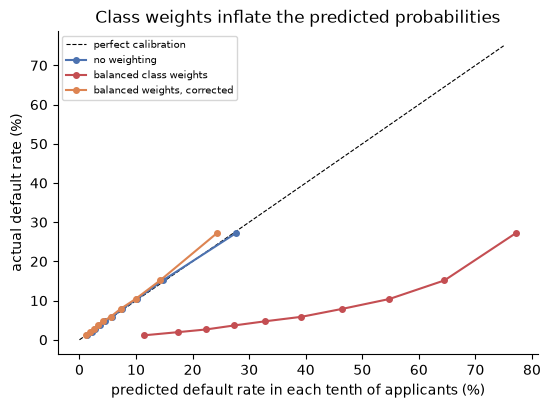

In [51]:
plain, weighted = results['LightGBM, default']['oof'], results['LightGBM, balanced class weights']['oof']
tenth = pd.qcut(plain, 10, labels=[f"D{i}" for i in range(1, 11)])
by_tenth = pd.DataFrame({'actual_default_pct': y_dev.values, 'unweighted_predicts_pct': plain, 'balanced_weights_predicts_pct': weighted,
                         'balanced_after_correction_pct': correct_for_prior(weighted, RATIO)}).groupby(tenth, observed=True).mean() * 100
print(f"rank correlation between the two models' predictions: {pd.Series(plain).corr(pd.Series(weighted), method='spearman'):.4f}")
print(by_tenth.round(2).to_string())

fig, ax = plt.subplots(figsize=(6.2, 4.2))
ax.plot([0, 75], [0, 75], color='black', linewidth=0.8, linestyle='--', label='perfect calibration')
for column, color, label in [('unweighted_predicts_pct', '#4C72B0', 'no weighting'), ('balanced_weights_predicts_pct', '#C44E52', 'balanced class weights'),
                             ('balanced_after_correction_pct', '#DD8452', 'balanced weights, corrected')]:
    ax.plot(by_tenth[column], by_tenth['actual_default_pct'], marker='o', markersize=4, color=color, label=label)
ax.set_xlabel('predicted default rate in each tenth of applicants (%)')
ax.set_ylabel('actual default rate (%)')
ax.set_title('Class weights inflate the predicted probabilities')
ax.legend(fontsize=7)
sns.despine()
plt.show()

### 6.4 "But the unweighted model never predicts a default"

The usual argument for class weights is that an unweighted model, cut at the default threshold of 0.5, flags almost no one. That is true, and it is a statement about the threshold, not the model. The table compares the two models at 0.5, and then compares them when the unweighted model's threshold is lowered until it catches the same share of defaults.

In [52]:
def at_threshold(p, t):
    flagged = p >= t
    caught = (flagged & (y_dev.values == 1)).sum()
    return {'threshold': t, 'flagged_pct': flagged.mean() * 100, 'recall_pct': caught / y_dev.sum() * 100,
            'precision_pct': caught / max(flagged.sum(), 1) * 100}

rows = {'unweighted, threshold 0.5': at_threshold(plain, 0.5), 'balanced weights, threshold 0.5': at_threshold(weighted, 0.5)}
target_recall = rows['balanced weights, threshold 0.5']['recall_pct']
matched_threshold = np.quantile(plain[y_dev.values == 1], 1 - target_recall / 100)
rows['unweighted, threshold lowered to match that recall'] = at_threshold(plain, matched_threshold)
rows['unweighted, threshold at the default rate (0.0807)'] = at_threshold(plain, y_dev.mean())
pd.DataFrame(rows).T.round(3)

,threshold,flagged_pct,recall_pct,precision_pct
"unweighted, threshold 0.5",0.500,0.309,2.125,55.526
"balanced weights, threshold 0.5",0.500,31.094,66.601,17.292
"unweighted, threshold lowered to match that recall",0.084,31.036,66.601,17.324
"unweighted, threshold at the default rate (0.0807)",0.081,32.443,68.011,16.923


### 6.5 Does the conclusion hold for other models?

The same test on logistic regression, where SMOTE can also be tried (it needs complete numeric data, which the linear pipeline provides), and one run of CatBoost with balanced weights, since CatBoost is the leading candidate.

In [53]:
linear_pre = lambda: make_linear_preprocessor()
imbalance_other = {
    'logistic regression, balanced class weights': (make_model_pipeline(linear_pre(), LogisticRegression(max_iter=2000, class_weight='balanced')), None),
    'logistic regression, undersample to 1:1': (make_sampled_pipeline(linear_pre(), RandomUnderSampler(sampling_strategy=1.0, random_state=SEED), logistic()), None),
    'logistic regression, SMOTE to 1:1': (make_sampled_pipeline(linear_pre(), SMOTE(sampling_strategy=1.0, random_state=SEED), logistic()), None),
    'CatBoost, default, balanced class weights': (make_model_pipeline(make_tree_preprocessor('string'),
        CatBoostClassifier(random_seed=SEED, verbose=0, auto_class_weights='Balanced')), CATBOOST_FIT_PARAMS),
}
for name, (pipe, fit_params) in imbalance_other.items():
    register(name, cross_validate(pipe, fit_params=fit_params), columns=157 if 'logistic' in name else len(FEATURES), note='stage 6')
    print(f"{name:<46} AUC {results[name]['mean']['roc_auc']:.4f}   {results[name]['mean']['fit_seconds']:7.1f}s per fold   "
          f"{'loaded from cache' if results[name]['cached'] else 'fitted now'}")

lr_names = ['logistic regression, all features'] + [n for n in imbalance_other if 'logistic' in n]
lr_table = imbalance_table(lr_names, 'logistic regression, all features', {n: (1.0 if n == 'logistic regression, all features' else RATIO) for n in lr_names})
cat_names = ['CatBoost, default', 'CatBoost, default, balanced class weights']
cat_table = imbalance_table(cat_names, 'CatBoost, default', {'CatBoost, default': 1.0, 'CatBoost, default, balanced class weights': RATIO})
other_table = pd.concat([lr_table, cat_table])
other_table.round({'roc_auc': 4, 'auc_change': 4, 'pr_auc': 4, 'log_loss': 4, 'mean_predicted_pct': 2, 'log_loss_after_correction': 4,
                   'mean_predicted_pct_after_correction': 2, 'fit_seconds': 1})

logistic regression, balanced class weights    AUC 0.7502      20.4s per fold   loaded from cache


logistic regression, undersample to 1:1        AUC 0.7492       8.3s per fold   loaded from cache


logistic regression, SMOTE to 1:1              AUC 0.7422      41.1s per fold   loaded from cache


CatBoost, default, balanced class weights      AUC 0.7595     637.9s per fold   loaded from cache


,roc_auc,auc_change,folds_better,pr_auc,log_loss,mean_predicted_pct,log_loss_after_correction,mean_predicted_pct_after_correction,fit_seconds
"logistic regression, all features",0.7503,0.0000,0.0,0.2310,0.2485,8.07,0.2485,8.07,9.3
"logistic regression, balanced class weights",0.7502,-0.0001,2.0,0.2296,0.5902,41.95,0.2486,8.08,20.4
"logistic regression, undersample to 1:1",0.7492,-0.0011,0.0,0.2285,0.5920,42.03,0.2489,8.11,8.3
"logistic regression, SMOTE to 1:1",0.7422,-0.0081,0.0,0.2240,0.5804,40.55,0.2514,8.09,41.1
"CatBoost, default",0.7643,0.0000,0.0,0.2438,0.2449,7.95,0.2449,7.95,343.7
"CatBoost, default, balanced class weights",0.7595,-0.0048,0.0,0.2460,0.5017,35.41,0.2481,6.76,637.9


### 6.6 The wrong way: resampling before the split

To show what the pipeline structure protects against, the defaults are duplicated across the whole development set first, and only then is the data split into folds. Copies of the same applicant now sit on both sides of every split. The model and its settings are identical to the correct version in 6.2.

In [54]:
X_leaky, y_leaky = RandomOverSampler(sampling_strategy=1.0, random_state=SEED).fit_resample(X_dev, y_dev)
leaky_fold = make_folds(np.asarray(y_leaky))
leaky = cross_validate(make_model_pipeline(tree_pre(), lgbm()), X_data=X_leaky.reset_index(drop=True), y_data=pd.Series(np.asarray(y_leaky)), fold=leaky_fold)

# how many validation rows have an identical copy in the training folds?
twin = pd.Series(X_leaky.index if X_leaky.index.name == 'SK_ID_CURR' else np.arange(len(X_leaky)))
row_key = pd.util.hash_pandas_object(X_leaky.reset_index(drop=True), index=False).values
copies_in_training = []
for k in range(N_SPLITS):
    val_k = leaky_fold == k
    copies_in_training.append(np.isin(row_key[val_k], row_key[~val_k]).mean())

honest = results['LightGBM, oversample to 1:1']
print(pd.DataFrame({'oversampling inside the pipeline (correct)': honest['folds']['roc_auc'].values,
                    'oversampling before the split (wrong)': leaky['folds']['roc_auc'].values}).round(4).to_string())
print(f"\ncorrect: AUC {honest['mean']['roc_auc']:.4f}     wrong: AUC {leaky['mean']['roc_auc']:.4f}     inflation: {leaky['mean']['roc_auc'] - honest['mean']['roc_auc']:+.4f}")
print(f"validation rows with an identical copy in the training folds, wrong version: {np.mean(copies_in_training):.1%}")
print(f"default rate in the validation folds, wrong version: {np.asarray(y_leaky).mean():.1%} (the real rate is {y_dev.mean():.2%})")
del X_leaky, y_leaky

   oversampling inside the pipeline (correct)  oversampling before the split (wrong)
0                                      0.7608                                 0.8087
1                                      0.7583                                 0.8066
2                                      0.7600                                 0.8029
3                                      0.7584                                 0.8064
4                                      0.7590                                 0.8058

correct: AUC 0.7593     wrong: AUC 0.8061     inflation: +0.0468
validation rows with an identical copy in the training folds, wrong version: 50.0%
default rate in the validation folds, wrong version: 50.0% (the real rate is 8.07%)


### 6.7 Summary

In [55]:
summary = pd.concat([lgbm_table, other_table])[['roc_auc', 'auc_change', 'folds_better', 'pr_auc', 'log_loss', 'mean_predicted_pct', 'log_loss_after_correction']]
summary['verdict'] = np.where(summary['auc_change'] == 0, 'reference',
                     np.where((summary['auc_change'] > 0.001) & (summary['folds_better'] == N_SPLITS), 'ranks better',
                     np.where(summary['auc_change'] < -0.001, 'ranks worse', 'no real change in ranking')))
print(holdout)
assert holdout.log == []
summary.round({'roc_auc': 4, 'auc_change': 4, 'pr_auc': 4, 'log_loss': 4, 'mean_predicted_pct': 2, 'log_loss_after_correction': 4})

HoldoutVault(61,503 rows, 4,965 defaults, opened 0 times)


,roc_auc,auc_change,folds_better,pr_auc,log_loss,mean_predicted_pct,log_loss_after_correction,verdict
"LightGBM, default",0.7612,0.0000,0.0,0.2449,0.2454,8.06,0.2454,reference
"LightGBM, balanced class weights",0.7614,0.0003,3.0,0.2464,0.5502,39.38,0.2456,no real change in ranking
"LightGBM, defaults weighted 3.4x",0.7623,0.0012,4.0,0.2464,0.3059,19.81,0.2451,no real change in ranking
"LightGBM, undersample to 1:1",0.7563,-0.0048,0.0,0.2352,0.5856,41.46,0.2470,ranks worse
"LightGBM, undersample to 1:3",0.7608,-0.0003,2.0,0.2428,0.3269,22.04,0.2456,no real change in ranking
"LightGBM, oversample to 1:1",0.7593,-0.0019,1.0,0.2441,0.5477,39.18,0.2463,ranks worse
"LightGBM, 10 undersampled models averaged",0.7640,0.0029,5.0,0.2490,0.5794,41.46,0.2446,ranks better
"logistic regression, all features",0.7503,0.0000,0.0,0.2310,0.2485,8.07,0.2485,reference
"logistic regression, balanced class weights",0.7502,-0.0001,2.0,0.2296,0.5902,41.95,0.2486,no real change in ranking
"logistic regression, undersample to 1:1",0.7492,-0.0011,0.0,0.2285,0.5920,42.03,0.2489,ranks worse


### Stage 6 findings

**Single-shot rebalancing does not improve ranking**

| Technique | LightGBM | Logistic regression | CatBoost |
|---|---:|---:|---:|
| Balanced class weights | +0.0003 | -0.0001 | -0.0048 |
| Defaults weighted 3.4 times | +0.0012 | | |
| Undersample to 1:1 | -0.0048 | -0.0011 | |
| Undersample to 1:3 | -0.0003 | | |
| Oversample to 1:1 by duplication | -0.0019 | | |
| SMOTE to 1:1 | | -0.0081 | |

(Change in ROC AUC against the same model with nothing done, same five folds.)

- Balanced class weights make no difference to LightGBM or logistic regression, and make CatBoost worse in all five folds. They also nearly double CatBoost's training time.
- Undersampling to 1:1 loses 0.005, because it throws away 91% of the repaid loans.
- Duplicating defaults loses 0.002. SMOTE loses 0.008 and is the worst result in this stage.
- The mild weighting is the best of these at +0.0012, better in four of five folds. That is suggestive, not established.

**Every rebalancing technique distorts the probabilities**
- The unweighted models predict an average default rate of 8.0% to 8.1%, against a true 8.07%.
- With balanced weights or 1:1 resampling the average prediction is 35% to 42%. Log loss more than doubles, from about 0.245 to between 0.50 and 0.59, which is far worse than predicting 8.07% for everyone (0.2805).
- The ranking is nearly unchanged (rank correlation 0.96 with the unweighted model). Only the numbers attached to it are wrong.
- A correction for the known shift in the odds repairs most of it. Log loss returns to within 0.001 of the unweighted model for LightGBM and logistic regression. For CatBoost the corrected model is still worse (0.2481 against 0.2449) and under-predicts (6.8%).

**Class weights are the same as moving the threshold**
- At a 0.5 cut-off the unweighted model flags 0.3% of applicants and catches 2% of defaults. The balanced model flags 31% and catches 67%.
- Lower the unweighted model's threshold to 0.084 and it catches the same 67% of defaults with the same precision (17.3% for both).
- So the usual reason for class weights, that the model "never predicts a default", is a property of the 0.5 threshold. The threshold is a separate decision, made in stage 10.

**One technique does help: many undersampled models, averaged**

| Model | Rows each model sees | Default rate it sees | ROC AUC | Against a single LightGBM |
|---|---:|---:|---:|---:|
| Single LightGBM | 100% | 8.1% | 0.7612 | |
| 10 undersampled models averaged | 16% | 50% | 0.7640 | +0.0029, 5 of 5 folds |
| Control: 10 models on 16% of rows | 16% | 8.1% | 0.7572 | -0.0040, 0 of 5 folds |
| Control: 10 models on 50% of rows | 50% | 8.1% | 0.7620 | +0.0008, 4 of 5 folds |

- The gain is not simply from averaging ten models. Averaging ten models trained at the real default rate gains 0.0008 at best, and loses 0.0040 when each model gets the same number of rows as an undersampled one.
- The undersampled version beats both controls in every fold, by 0.0068 and by 0.0020.
- The difference is which rows are kept. Every undersampled model sees all 15,888 defaults in the training folds. A random 16% sample sees about 2,500. The defaults are the scarce information, and this arrangement gives every model all of them while varying only the repaid loans.
- At 0.7640 this is the best LightGBM result so far, level with CatBoost (0.7643), at 30 seconds per fold instead of 340.
- Its raw probabilities are as distorted as any other 1:1 technique (41%). After correction its log loss is 0.2446, the best in this stage, and its average prediction is 7.96%.
- This was tested on LightGBM with default settings only. Whether it survives tuning is a question for stage 7.

**The leakage demonstration**
- Duplicating defaults before splitting into folds gives an AUC of 0.8061. Doing the same thing inside the pipeline gives 0.7593.
- The difference of 0.047 is entirely fake. It is more than twice the gap between the best and the worst model in the whole of stage 5 (0.0185).
- In the wrong version half of all validation rows have an identical copy in the training folds, and the validation folds are 50% defaults when the real rate is 8.07%.
- This is the leak that the pipeline structure from stage 3 exists to prevent. In stage 4 the same mistake with medians and scaling moved the score by 0.00006. With resampling it moves it by 0.047.

**Decisions**
- No class weights and no resampling in the standard pipelines. They do not improve ranking and they break the probabilities.
- Class weights are ruled out for CatBoost specifically. They cost accuracy and time.
- Handle the imbalance through the metric and the threshold: ROC AUC and PR AUC for model selection, and a deliberately chosen cut-off in stage 10 in place of 0.5.
- Carry one idea into stage 7: giving each model all the defaults and a sample of the repaid loans. LightGBM can do this natively within a single model, by sampling repaid loans more thinly than defaults at each round. It goes into the LightGBM search space as an option, along with a mild weight on defaults.
- If the tuned model ends up using either, its probabilities must be corrected afterwards. Stage 9 checks calibration on whatever stage 7 selects.
- Any resampling stays inside the pipeline.
- The holdout is still unopened.

## Stage 7: Hyperparameter tuning

How much better are the two shortlisted models once tuned?

| Model | Search | Why |
|---|---|---|
| LightGBM | 50 trials with Optuna, each a full five-fold run | A five-fold run takes under a minute, so a real search is affordable |
| CatBoost | Four targeted changes around its defaults, on three of the five folds | A five-fold run takes 20 to 40 minutes. Its defaults are already strong, so the search checks the settings most likely to matter |

**Three ways tuning can mislead, and what is done about each**

1. **Stopping on the validation fold.** As in stage 5, the number of trees is decided on a 15% slice of the training folds. The validation fold is not used.
2. **Picking the best of many tries.** Fifty configurations are scored on the same five folds, and the best of fifty always looks a little better than it is. Two checks: the winning configuration is re-scored on a fresh split of the development set into five different folds, and the holdout in stage 11 has no part in any of this.
3. **Tuning on less data than the final model uses.** A model that stops early trains on 85% of the training folds. Once the search is over, the winner is refitted on all of the training folds with a fixed number of trees, and that refitted model is the one that is compared and carried forward.

Every trial goes through `cross_validate()`, so each one is saved. Re-running the notebook replays the search from the cache.

**This stage contains two LightGBM searches.** The first one turned out to have a flaw in how it decided when to stop adding trees. It is kept here, with the evidence that exposed the flaw, followed by the correction and a second search. The second search is the one the conclusions rest on.

### 7.1 LightGBM: the search space

The learning rate is fixed at 0.05 during the search and the number of trees is found by early stopping, so the search is over the shape of the trees and the regularisation. Two settings come from stage 6: how thinly repaid loans are sampled at each round while every default is kept, and a weight on defaults.

In [56]:
# Optuna's progress-bar library prints a notice about notebook widgets when imported. No progress bars are used here.
warnings.filterwarnings('ignore', message='IProgress not found')
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

N_LGBM_TRIALS = 50
SEARCH_LEARNING_RATE = 0.05

def suggest_lgbm(trial):
    return {
        'num_leaves': trial.suggest_int('num_leaves', 8, 128, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 12),
        'min_child_samples': trial.suggest_int('min_child_samples', 20, 1000, log=True),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.3, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 100.0, log=True),
        'min_split_gain': trial.suggest_float('min_split_gain', 0.0, 0.5),
        'cat_smooth': trial.suggest_float('cat_smooth', 1.0, 100.0, log=True),
        'neg_bagging_fraction': trial.suggest_float('neg_bagging_fraction', 0.1, 1.0),
        'scale_pos_weight': trial.suggest_float('scale_pos_weight', 1.0, 5.0),
    }

# LightGBM's defaults, expressed in the search space, are tried first so the search starts from a known point
LGBM_DEFAULTS = {'num_leaves': 31, 'max_depth': 12, 'min_child_samples': 20, 'colsample_bytree': 1.0, 'reg_alpha': 1e-3, 'reg_lambda': 1e-3,
                 'min_split_gain': 0.0, 'cat_smooth': 10.0, 'neg_bagging_fraction': 1.0, 'scale_pos_weight': 1.0}

def lgbm_model(params, n_estimators, learning_rate=SEARCH_LEARNING_RATE):
    # every default is kept at each round (pos_bagging_fraction=1) and repaid loans are sampled at neg_bagging_fraction
    return LGBMClassifier(random_state=SEED, verbose=-1, learning_rate=learning_rate, n_estimators=n_estimators,
                          pos_bagging_fraction=1.0, bagging_freq=1, **params)

def lgbm_search_pipeline(params, stopper=None):
    # stopper: the early stopping wrapper to use. The first search used EarlyStopping. Section 7.3 introduces a corrected one.
    stopper = EarlyStopping if stopper is None else stopper
    return make_model_pipeline(make_tree_preprocessor('category'), stopper(lgbm_model(params, MAX_TREES), 'lightgbm'))

space = pd.DataFrame({'range': ['8 to 128', '3 to 12', '20 to 1,000', '0.3 to 1.0', '0.001 to 10', '0.001 to 100', '0 to 0.5', '1 to 100', '0.1 to 1.0', '1 to 5'],
                      'LightGBM default': [31, 'no limit', 20, 1.0, 0, 0, 0, 10, 1.0, 1],
                      'what it controls': ['leaves per tree', 'depth of a tree', 'minimum rows in a leaf', 'share of features tried per tree',
                                           'L1 penalty on leaf values', 'L2 penalty on leaf values', 'minimum gain to make a split',
                                           'smoothing for categorical splits', 'share of repaid loans sampled per round (stage 6)',
                                           'weight on defaults (stage 6)']}, index=list(LGBM_DEFAULTS))
space

,range,LightGBM default,what it controls
num_leaves,8 to 128,31,leaves per tree
max_depth,3 to 12,no limit,depth of a tree
min_child_samples,"20 to 1,000",20,minimum rows in a leaf
colsample_bytree,0.3 to 1.0,1.0,share of features tried per tree
reg_alpha,0.001 to 10,0,L1 penalty on leaf values
reg_lambda,0.001 to 100,0,L2 penalty on leaf values
min_split_gain,0 to 0.5,0,minimum gain to make a split
cat_smooth,1 to 100,10,smoothing for categorical splits
neg_bagging_fraction,0.1 to 1.0,1.0,share of repaid loans sampled per round (stage 6)
scale_pos_weight,1 to 5,1,weight on defaults (stage 6)


### 7.2 LightGBM: the first search

In [57]:
def run_lgbm_search(stopper=None):
    def objective(trial):
        params = suggest_lgbm(trial)
        r = cross_validate(lgbm_search_pipeline(params, stopper))
        trial.set_user_attr('fold_auc', r['folds']['roc_auc'].round(5).tolist())
        trial.set_user_attr('fold_std', float(r['std']['roc_auc']))
        trial.set_user_attr('trees', float(r['folds']['rounds'].mean()))
        trial.set_user_attr('fit_seconds', float(r['mean']['fit_seconds']))
        trial.set_user_attr('pr_auc', float(r['mean']['pr_auc']))
        trial.set_user_attr('mean_predicted_pct', float(np.nanmean(r['oof']) * 100))
        trial.set_user_attr('cached', bool(r['cached']))
        return float(r['mean']['roc_auc'])

    started = time.time()
    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
    study.enqueue_trial(LGBM_DEFAULTS)
    study.optimize(objective, n_trials=N_LGBM_TRIALS)
    table = study.trials_dataframe(attrs=('number', 'value', 'params', 'user_attrs'))
    table.columns = [c.replace('params_', '').replace('user_attrs_', '') for c in table.columns]
    table = table.rename(columns={'value': 'roc_auc'}).set_index('number')
    print(f"{len(table)} trials in {(time.time() - started) / 60:.1f} minutes ({int(table['cached'].sum())} loaded from cache); "
          f"fitting time recorded for all trials: {table['fit_seconds'].sum() * N_SPLITS / 60:.0f} minutes")
    print(f"trial 0 (LightGBM defaults): {table.loc[0, 'roc_auc']:.4f}")
    print(f"best trial: number {study.best_trial.number}, AUC {study.best_value:.4f}")
    print(f"trials better than the defaults: {int((table['roc_auc'] > table.loc[0, 'roc_auc']).sum())} of {len(table) - 1}")
    return study, table

shown = ['roc_auc', 'fold_std', 'trees', 'fit_seconds'] + list(LGBM_DEFAULTS)
first_study, first_trials = run_lgbm_search()
first_trials.sort_values('roc_auc', ascending=False).head(8)[shown].round(4)

50 trials in 0.3 minutes (50 loaded from cache); fitting time recorded for all trials: 24 minutes
trial 0 (LightGBM defaults): 0.7605
best trial: number 48, AUC 0.7659
trials better than the defaults: 21 of 49


,roc_auc,fold_std,trees,fit_seconds,num_leaves,max_depth,min_child_samples,colsample_bytree,reg_alpha,reg_lambda,min_split_gain,cat_smooth,neg_bagging_fraction,scale_pos_weight
number,,,,,,,,,,,,,,
48,0.7659,0.0019,758.8,12.8220,13,11,48,0.5878,0.0020,47.0941,0.0908,48.5709,0.7371,1.1585
43,0.7657,0.0015,1076.6,15.3815,8,11,48,0.4832,0.0016,76.4506,0.1702,22.1005,0.8965,1.4795
36,0.7657,0.0020,654.0,8.9395,16,12,49,0.6211,0.0025,25.2292,0.0660,24.8358,0.7102,1.0599
22,0.7656,0.0018,660.2,10.9714,16,12,60,0.4984,0.0019,39.8215,0.1763,14.0415,0.8174,1.4471
46,0.7654,0.0016,504.0,9.0110,17,11,104,0.5904,0.0026,14.9487,0.1819,13.7206,0.7275,1.1896
29,0.7654,0.0019,623.2,8.2522,16,11,50,0.6497,0.0018,55.3945,0.1073,16.1947,0.7446,1.2262
44,0.7653,0.0017,685.0,11.4904,12,11,81,0.5392,0.0018,44.6881,0.0710,15.6090,0.8186,1.4925
38,0.7653,0.0016,844.0,12.8300,11,11,57,0.5777,0.0017,65.4427,0.0902,22.1289,0.8671,1.1784


**The weakest trials expose a problem.** The best trials look reasonable. The worst ones do not: they stopped after a handful of trees.

In [58]:
print(first_trials.sort_values('roc_auc').head(8)[shown].round(4).to_string())

short = first_trials['trees'] < 150
print(f"\ntrials that stopped before 150 trees: {int(short.sum())} of {len(first_trials)}, mean AUC {first_trials.loc[short, 'roc_auc'].mean():.4f} "
      f"(the rest: {first_trials.loc[~short, 'roc_auc'].mean():.4f})")
print(pd.DataFrame({'stopped before 150 trees (median)': first_trials[short][['trees', 'scale_pos_weight', 'neg_bagging_fraction']].median(),
                    'ran longer (median)': first_trials[~short][['trees', 'scale_pos_weight', 'neg_bagging_fraction']].median()}).round(3).to_string())
print('\nrank correlation between a trial\'s score and each setting:')
print(first_trials[list(LGBM_DEFAULTS) + ['trees']].corrwith(first_trials['roc_auc'], method='spearman').sort_values().round(2).to_string())

        roc_auc  fold_std  trees  fit_seconds  num_leaves  max_depth  min_child_samples  colsample_bytree  reg_alpha  reg_lambda  min_split_gain  cat_smooth  neg_bagging_fraction  scale_pos_weight
number                                                                                                                                                                                              
6        0.6838    0.0128    1.0       1.9896         118         10                788            0.9264     0.2464     40.6791          0.0442      2.4658                0.1407            2.3013
7        0.6967    0.0024    1.0       2.0292          23          5                510            0.5497     0.0133      0.5170          0.0705     40.2155                0.1671            4.9475
2        0.7186    0.0026    3.0       2.4305           8         12                517            0.4486     0.0053      0.0083          0.1521     11.2076                0.4888            2.1649
10       0.7253

### 7.3 What went wrong, and the correction

A model does not get worse at ranking applicants after its first tree. Something other than ranking was ending those trials.

The early stopping wrapper from stage 5 asks LightGBM to watch AUC on the 15% slice. But LightGBM also watches its own default measure, log loss, and it stops as soon as **either** has gone 100 rounds without improving. A weight on defaults, or thin sampling of repaid loans, deliberately inflates the predicted probabilities. That makes log loss worse from the very first tree while AUC is still climbing. So every trial that used those settings strongly was cut off almost at once.

The cell below shows it directly on one fold, with a weight of 3 on defaults and everything else at its default.

log loss on the 15% slice is best at round 6 and then rises
AUC on the 15% slice is best at round 149


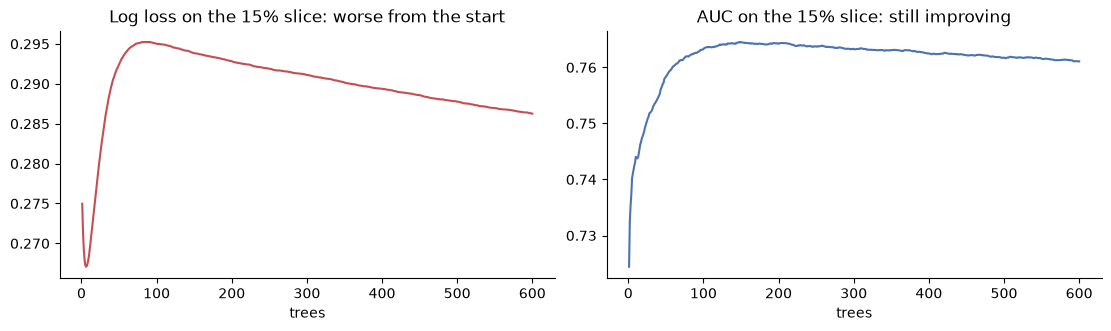

In [59]:
fit_rows, val_rows = dev_fold != 0, dev_fold == 0
encoder = make_tree_preprocessor('category').fit(X_dev[fit_rows])
grow, watch = train_test_split(np.arange(int(fit_rows.sum())), test_size=0.15, stratify=y_dev[fit_rows].values, random_state=SEED)
X_fit, y_fit = encoder.transform(X_dev[fit_rows]), y_dev[fit_rows].values

traced = LGBMClassifier(random_state=SEED, verbose=-1, learning_rate=SEARCH_LEARNING_RATE, n_estimators=600, scale_pos_weight=3.0,
                        metric=['binary_logloss', 'auc'])
traced.fit(X_fit.iloc[grow], y_fit[grow], eval_set=[(X_fit.iloc[watch], y_fit[watch])])
curve = pd.DataFrame(traced.evals_result_['valid_0'])
print(f"log loss on the 15% slice is best at round {int(curve['binary_logloss'].idxmin()) + 1} and then rises")
print(f"AUC on the 15% slice is best at round {int(curve['auc'].idxmax()) + 1}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), layout='constrained')
axes[0].plot(curve.index + 1, curve['binary_logloss'], color='#C44E52')
axes[0].set_title('Log loss on the 15% slice: worse from the start')
axes[1].plot(curve.index + 1, curve['auc'], color='#4C72B0')
axes[1].set_title('AUC on the 15% slice: still improving')
for ax in axes:
    ax.set_xlabel('trees')
sns.despine()
plt.show()

**The correction.** A second wrapper makes LightGBM watch AUC and nothing else. It uses the same 15% slice of the training folds, so it is exactly as leak-free as the first. XGBoost, CatBoost and scikit-learn boosting were each watching a single measure already and are not affected.

The original wrapper is left as it was, so that every earlier result stays reproducible.

In [60]:
class EarlyStoppingOnAUC(EarlyStopping):
    # For LightGBM: stop when AUC on the 15% slice stops improving, and ignore every other measure.
    def fit(self, X, y, cat_features=None):
        if self.library != 'lightgbm':
            return super().fit(X, y, cat_features=cat_features)
        y = np.asarray(y)
        grow, watch = train_test_split(np.arange(len(y)), test_size=self.validation_fraction, stratify=y, random_state=self.seed)
        model = clone(self.model).set_params(metric='auc')
        model.fit(X.iloc[grow], y[grow], eval_set=[(X.iloc[watch], y[watch])],
                  callbacks=[lgb.early_stopping(self.patience, first_metric_only=True, verbose=False)])
        self.model_, self.n_trees_, self.classes_ = model, int(model.best_iteration_), np.array([0, 1])
        return self

# the same configuration through both wrappers, one fold
demo = {'num_leaves': 31, 'max_depth': 12, 'min_child_samples': 20, 'colsample_bytree': 1.0, 'reg_alpha': 1e-3, 'reg_lambda': 1e-3,
        'min_split_gain': 0.0, 'cat_smooth': 10.0, 'neg_bagging_fraction': 1.0, 'scale_pos_weight': 3.0}
rows = {}
for label, stopper in [('original wrapper', EarlyStopping), ('corrected wrapper', EarlyStoppingOnAUC)]:
    fitted_pipe = lgbm_search_pipeline(demo, stopper).fit(X_dev[fit_rows], y_dev[fit_rows])
    rows[label] = {'trees': fitted_pipe.named_steps['model'].n_trees_,
                   'fold_0_auc': roc_auc_score(y_dev[val_rows], fitted_pipe.predict_proba(X_dev[val_rows])[:, 1])}
print('defaults weighted 3 times, everything else at its default:')
print(pd.DataFrame(rows).T.round(4).to_string())

# the effect on the stage 5 comparison, where LightGBM used its defaults
corrected_stage5 = cross_validate(make_model_pipeline(make_tree_preprocessor('category'),
    EarlyStoppingOnAUC(LGBMClassifier(n_estimators=MAX_TREES, learning_rate=LEARNING_RATE, random_state=SEED, verbose=-1), 'lightgbm')))
register('LightGBM, early stopping on AUC only', corrected_stage5, columns=len(FEATURES), note='stage 7 correction')
c = compare('LightGBM, early stopping on AUC only', 'LightGBM, early stopping')
print(f"\nstage 5 'LightGBM, early stopping': {results['LightGBM, early stopping']['mean']['roc_auc']:.4f} with {results['LightGBM, early stopping']['folds']['rounds'].mean():.0f} trees")
print(f"same model, corrected stopping:     {corrected_stage5['mean']['roc_auc']:.4f} with {corrected_stage5['folds']['rounds'].mean():.0f} trees   "
      f"(difference {c['mean_difference']:+.4f}, better in {c['folds_better']} of {N_SPLITS} folds)")

defaults weighted 3 times, everything else at its default:
                   trees  fold_0_auc
original wrapper     6.0      0.7339
corrected wrapper  130.0      0.7612



stage 5 'LightGBM, early stopping': 0.7603 with 289 trees
same model, corrected stopping:     0.7603 with 292 trees   (difference +0.0000, better in 1 of 5 folds)


### 7.4 LightGBM: the second search, with corrected stopping

The same search space, the same number of trials, the same starting point and the same random seed. The only change is the stopping rule.

In [61]:
lgbm_study, trials = run_lgbm_search(EarlyStoppingOnAUC)
print(f"\ntrials that stopped before 150 trees: {int((trials['trees'] < 150).sum())} (first search: {int((first_trials['trees'] < 150).sum())})")
trials.sort_values('roc_auc', ascending=False).head(10)[shown + ['mean_predicted_pct']].round(4)

50 trials in 0.3 minutes (50 loaded from cache); fitting time recorded for all trials: 38 minutes
trial 0 (LightGBM defaults): 0.7605
best trial: number 41, AUC 0.7663
trials better than the defaults: 49 of 49

trials that stopped before 150 trees: 0 (first search: 25)


,roc_auc,fold_std,trees,fit_seconds,num_leaves,max_depth,min_child_samples,colsample_bytree,reg_alpha,reg_lambda,min_split_gain,cat_smooth,neg_bagging_fraction,scale_pos_weight,mean_predicted_pct
number,,,,,,,,,,,,,,,
41,0.7663,0.0017,804.0,10.8258,10,10,803,0.3019,0.0048,0.4351,0.0095,24.2843,0.6151,1.2018,13.5702
45,0.7661,0.0015,844.0,10.1229,9,11,689,0.3685,0.0067,0.1957,0.0805,37.0381,0.6711,1.1293,12.1431
32,0.7660,0.0016,1021.0,13.8935,8,12,925,0.3979,0.0012,0.0467,0.2076,9.9423,0.6734,1.8963,17.5845
46,0.7659,0.0016,812.2,11.2567,9,11,830,0.4080,0.0072,0.2216,0.0340,35.5863,0.7058,1.8025,16.4595
22,0.7659,0.0011,535.8,8.6587,15,11,754,0.3700,0.0024,0.2929,0.1287,14.2566,0.6991,1.6081,15.2366
37,0.7659,0.0018,815.6,10.7331,10,11,895,0.3338,0.0022,0.2588,0.0124,12.1799,0.8479,1.3890,11.8814
35,0.7659,0.0016,818.0,10.7884,10,10,750,0.3415,0.0025,0.3231,0.0407,21.1211,0.6606,1.3321,13.8743
28,0.7659,0.0014,511.8,7.9189,16,12,620,0.3207,0.0036,0.0646,0.1100,15.8893,0.3991,2.4614,28.6820
39,0.7657,0.0015,698.8,10.6875,11,11,719,0.4571,0.0027,0.3286,0.0001,13.2376,0.6833,1.2958,13.2523


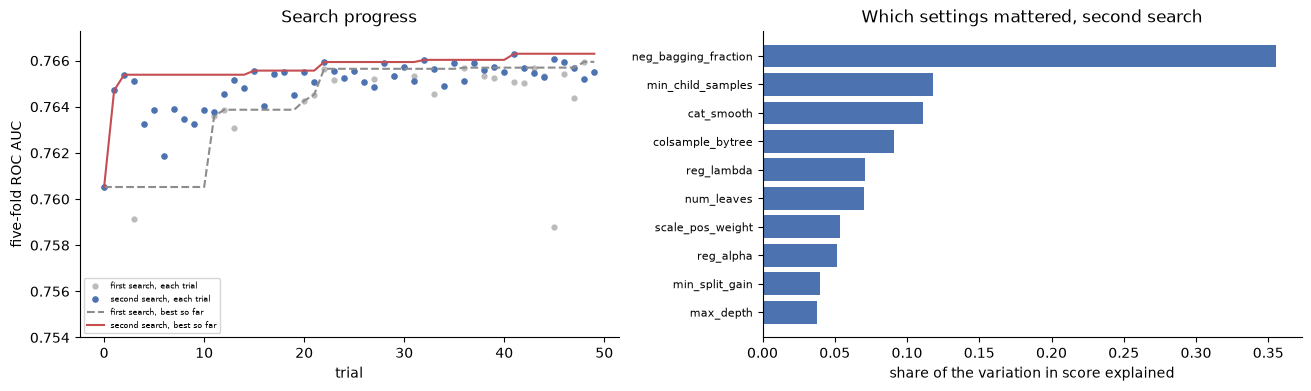

importance of each setting, second search:
neg_bagging_fraction    0.355
min_child_samples       0.118
cat_smooth              0.111
colsample_bytree        0.091
reg_lambda              0.071
num_leaves              0.071
scale_pos_weight        0.054
reg_alpha               0.052
min_split_gain          0.040
max_depth               0.038

range of each setting among the ten best trials:
                       lowest  highest  best trial  best of first search
num_leaves              8.000   24.000      10.000                13.000
max_depth              10.000   12.000      10.000                11.000
min_child_samples     620.000  925.000     803.000                48.000
colsample_bytree        0.302    0.457       0.302                 0.588
reg_alpha               0.001    0.007       0.005                 0.002
reg_lambda              0.018    0.435       0.435                47.094
min_split_gain          0.000    0.208       0.009                 0.091
cat_smooth             

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), layout='constrained')
axes[0].scatter(first_trials.index, first_trials['roc_auc'], s=12, color='#BBBBBB', label='first search, each trial')
axes[0].scatter(trials.index, trials['roc_auc'], s=14, color='#4C72B0', label='second search, each trial')
axes[0].plot(first_trials.index, first_trials['roc_auc'].cummax(), color='#8C8C8C', linestyle='--', label='first search, best so far')
axes[0].plot(trials.index, trials['roc_auc'].cummax(), color='#C44E52', label='second search, best so far')
axes[0].set_ylim(min(trials['roc_auc'].quantile(0.1), 0.755) - 0.001, max(trials['roc_auc'].max(), first_trials['roc_auc'].max()) + 0.001)
axes[0].set_xlabel('trial')
axes[0].set_ylabel('five-fold ROC AUC')
axes[0].set_title('Search progress')
axes[0].legend(fontsize=6)

importance = pd.Series(optuna.importance.get_param_importances(lgbm_study)).sort_values()
axes[1].barh(importance.index, importance.values, color='#4C72B0')
axes[1].set_xlabel('share of the variation in score explained')
axes[1].set_title('Which settings mattered, second search')
axes[1].tick_params(axis='y', labelsize=8)
sns.despine()
plt.show()

print('importance of each setting, second search:')
print(importance.sort_values(ascending=False).round(3).to_string())
top = trials.sort_values('roc_auc', ascending=False).head(10)
print('\nrange of each setting among the ten best trials:')
print(pd.DataFrame({'lowest': top[list(LGBM_DEFAULTS)].min(), 'highest': top[list(LGBM_DEFAULTS)].max(), 'best trial': top[list(LGBM_DEFAULTS)].iloc[0],
                    'best of first search': first_trials.sort_values('roc_auc', ascending=False)[list(LGBM_DEFAULTS)].iloc[0]}).round(3).to_string())
print('\nrank correlation between a trial\'s score and each setting, second search:')
print(trials[list(LGBM_DEFAULTS) + ['trees']].corrwith(trials['roc_auc'], method='spearman').sort_values().round(2).to_string())
print(f"\nsecond search: spread of scores across all trials {trials['roc_auc'].min():.4f} to {trials['roc_auc'].max():.4f} (first search: {first_trials['roc_auc'].min():.4f} to {first_trials['roc_auc'].max():.4f})")

### 7.5 LightGBM: refit the winners on all of the training folds

During a search each model trains on 85% of the training folds, because the rest decides when to stop. Now that the number of trees is known, each search's winner is refitted without early stopping, on all of the training folds, with the tree count scaled up for the extra data. A second version of each uses a lower learning rate with proportionally more trees, which usually gains a little.

In [63]:
tree_pre = lambda: make_tree_preprocessor('category')

def refit_winner(study, label):
    params, searched = dict(study.best_trial.params), study.best_trial.user_attrs['trees']
    n_trees = int(round(searched / 0.85))
    print(f"{label}: best trial stopped at {searched:.0f} trees on average, refit with {n_trees}")
    register(label, cross_validate(make_model_pipeline(tree_pre(), lgbm_model(params, n_trees))), columns=len(FEATURES), note='stage 7')
    register(f'{label}, learning rate 0.02',
             cross_validate(make_model_pipeline(tree_pre(), lgbm_model(params, int(round(n_trees * 2.5)), learning_rate=0.02))),
             columns=len(FEATURES), note='stage 7')
    return params, n_trees

first_params, first_trees = refit_winner(first_study, 'LightGBM, tuned (first search)')
best_params, final_trees = refit_winner(lgbm_study, 'LightGBM, tuned')

names = ['LightGBM, default', 'LightGBM, tuned (first search)', 'LightGBM, tuned (first search), learning rate 0.02',
         'LightGBM, tuned', 'LightGBM, tuned, learning rate 0.02']
table = leaderboard(names, sort=False)[['roc_auc', 'fold_std', 'pr_auc', 'log_loss', 'fit_seconds']]
table = table.join(pd.DataFrame({n: compare(n, 'LightGBM, default') for n in names}).T[['mean_difference', 'difference_std', 'folds_better']])
table['mean_predicted_pct'] = [results[n]['oof'].mean() * 100 for n in names]
print('\nROC AUC by fold')
print(pd.DataFrame({n: results[n]['folds']['roc_auc'] for n in names}).T.round(4).to_string())
c = compare('LightGBM, tuned, learning rate 0.02', 'LightGBM, tuned (first search), learning rate 0.02')
print(f"\nsecond search minus first search, at learning rate 0.02: {c['mean_difference']:+.4f} (spread {c['difference_std']:.4f}, better in {c['folds_better']} of {N_SPLITS} folds)")
table.round(4)

LightGBM, tuned (first search): best trial stopped at 759 trees on average, refit with 893


LightGBM, tuned: best trial stopped at 804 trees on average, refit with 946



ROC AUC by fold
fold                                                     0       1       2       3       4
LightGBM, default                                   0.7607  0.7608  0.7601  0.7608  0.7634
LightGBM, tuned (first search)                      0.7674  0.7655  0.7667  0.7690  0.7692
LightGBM, tuned (first search), learning rate 0.02  0.7682  0.7663  0.7672  0.7694  0.7701
LightGBM, tuned                                     0.7675  0.7654  0.7669  0.7683  0.7702
LightGBM, tuned, learning rate 0.02                 0.7680  0.7662  0.7677  0.7688  0.7708

second search minus first search, at learning rate 0.02: +0.0001 (spread 0.0005, better in 2 of 5 folds)


,roc_auc,fold_std,pr_auc,log_loss,fit_seconds,mean_difference,difference_std,folds_better,mean_predicted_pct
"LightGBM, default",0.7612,0.0013,0.2449,0.2454,3.8900,0.0000,0.0000,0.0,8.0550
"LightGBM, tuned (first search)",0.7676,0.0015,0.2528,0.2505,12.2135,0.0064,0.0013,5.0,11.4832
"LightGBM, tuned (first search), learning rate 0.02",0.7682,0.0016,0.2534,0.2504,29.5661,0.0071,0.0011,5.0,11.4824
"LightGBM, tuned",0.7677,0.0018,0.2530,0.2601,10.6587,0.0065,0.0011,5.0,13.5636
"LightGBM, tuned, learning rate 0.02",0.7683,0.0017,0.2537,0.2598,25.2611,0.0071,0.0010,5.0,13.5547


### 7.6 LightGBM: is the gain real, or the luck of fifty tries?

The winner was chosen because it scored best on one particular split of the development set into five folds. If that was partly luck, the advantage will shrink on a different split. The default and the tuned model are both re-scored on five new folds, drawn from the same development rows with a different random seed. Neither was tuned on this split.

In [64]:
fresh_fold = make_folds(y_dev.values, seed=SEED + 1)
print(f"rows that share a fold with the same neighbours as before: the two splits agree on {np.mean(fresh_fold == dev_fold):.0%} of fold labels (20% expected by chance)")

fresh = {
    'LightGBM, default': cross_validate(make_model_pipeline(tree_pre(), LGBMClassifier(random_state=SEED, verbose=-1)), fold=fresh_fold),
    'LightGBM, tuned': cross_validate(make_model_pipeline(tree_pre(), lgbm_model(best_params, final_trees)), fold=fresh_fold),
}
gain_search = results['LightGBM, tuned']['folds']['roc_auc'].values - results['LightGBM, default']['folds']['roc_auc'].values
gain_fresh = fresh['LightGBM, tuned']['folds']['roc_auc'].values - fresh['LightGBM, default']['folds']['roc_auc'].values
check = pd.DataFrame({
    'default': [results['LightGBM, default']['mean']['roc_auc'], fresh['LightGBM, default']['mean']['roc_auc']],
    'tuned': [results['LightGBM, tuned']['mean']['roc_auc'], fresh['LightGBM, tuned']['mean']['roc_auc']],
    'gain_from_tuning': [gain_search.mean(), gain_fresh.mean()],
    'gain_std': [gain_search.std(ddof=1), gain_fresh.std(ddof=1)],
    'folds_better': [int((gain_search > 0).sum()), int((gain_fresh > 0).sum())],
}, index=['folds used for the search', 'fresh folds'])
print(f"share of the gain that survives on fresh folds: {gain_fresh.mean() / gain_search.mean():.0%}")
check.round(4)

rows that share a fold with the same neighbours as before: the two splits agree on 20% of fold labels (20% expected by chance)


share of the gain that survives on fresh folds: 107%


,default,tuned,gain_from_tuning,gain_std,folds_better
folds used for the search,0.7612,0.7677,0.0065,0.0011,5
fresh folds,0.7610,0.7680,0.0069,0.0014,5


### 7.7 CatBoost: a targeted search

CatBoost is too slow for a broad search, so four changes are tried one at a time around its default configuration, on folds 0, 1 and 2. Each model still trains on the other four folds, so its scores can be compared fold by fold with the full runs from stage 5. The learning rate is 0.08 with early stopping.

| Change | Why it might matter |
|---|---|
| Shallower trees (depth 4) | Simpler trees can generalise better when the signal is weak |
| Deeper trees (depth 8) | More interactions between features |
| Stronger regularisation (L2 of 10) | The default of 3 may be light for 55 partly redundant features |
| Feature sampling (half the features per split) | Decorrelates the trees, which helped in the EDA's redundancy analysis |

If one of them beats the reference configuration in all three folds, it is confirmed with a full five-fold run.

In [65]:
CAT_FOLDS = [0, 1, 2]
CAT_LEARNING_RATE = 0.08

def catboost_search_pipeline(**settings):
    model = CatBoostClassifier(iterations=MAX_TREES, learning_rate=CAT_LEARNING_RATE, random_seed=SEED, verbose=0, eval_metric='AUC',
                               allow_writing_files=False, **settings)
    return make_model_pipeline(make_tree_preprocessor('string'), EarlyStopping(model, 'catboost'))

cat_configs = {
    'reference (depth 6, L2 3)': {},
    'depth 4': {'depth': 4},
    'depth 8': {'depth': 8},
    'L2 regularisation 10': {'l2_leaf_reg': 10},
    'half the features per split': {'rsm': 0.5},
}
cat_search = {}
for label, settings in cat_configs.items():
    cat_search[label] = cross_validate(catboost_search_pipeline(**settings), fit_params=CATBOOST_FIT_PARAMS, only_folds=CAT_FOLDS)
    r = cat_search[label]
    print(f"{label:<30} AUC on folds 0-2: {r['mean']['roc_auc']:.4f}   {r['mean']['fit_seconds']:6.0f}s per fold   trees {r['folds']['rounds'].astype(int).tolist()}   "
          f"{'loaded from cache' if r['cached'] else 'fitted now'}")

reference = cat_search['reference (depth 6, L2 3)']['folds']['roc_auc']
rows = {}
for label, r in cat_search.items():
    diff = r['folds']['roc_auc'] - reference
    rows[label] = {'fold_0': r['folds']['roc_auc'].loc[0], 'fold_1': r['folds']['roc_auc'].loc[1], 'fold_2': r['folds']['roc_auc'].loc[2],
                   'mean': r['mean']['roc_auc'], 'against_reference': diff.mean(), 'folds_better': int((diff > 0).sum()),
                   'minutes_per_fold': r['mean']['fit_seconds'] / 60}
for label, name in [('stage 5: CatBoost, default', 'CatBoost, default'), ('stage 5: CatBoost, early stopping (rate 0.05)', 'CatBoost, early stopping')]:
    f = results[name]['folds']['roc_auc'].loc[CAT_FOLDS]
    rows[label] = {'fold_0': f.loc[0], 'fold_1': f.loc[1], 'fold_2': f.loc[2], 'mean': f.mean(), 'against_reference': (f - reference).mean(),
                   'folds_better': int((f - reference > 0).sum()), 'minutes_per_fold': results[name]['mean']['fit_seconds'] / 60}
cat_table = pd.DataFrame(rows).T
cat_table.round({'fold_0': 4, 'fold_1': 4, 'fold_2': 4, 'mean': 4, 'against_reference': 4, 'minutes_per_fold': 1})

reference (depth 6, L2 3)      AUC on folds 0-2: 0.7633      182s per fold   trees [500, 1112, 551]   loaded from cache


depth 4                        AUC on folds 0-2: 0.7638      193s per fold   trees [850, 1187, 1200]   loaded from cache


depth 8                        AUC on folds 0-2: 0.7611      124s per fold   trees [240, 385, 302]   loaded from cache


L2 regularisation 10           AUC on folds 0-2: 0.7638      189s per fold   trees [606, 886, 598]   loaded from cache


half the features per split    AUC on folds 0-2: 0.7628      172s per fold   trees [785, 783, 555]   loaded from cache


,fold_0,fold_1,fold_2,mean,against_reference,folds_better,minutes_per_fold
"reference (depth 6, L2 3)",0.7629,0.7636,0.7633,0.7633,0.0000,0.0,3.0
depth 4,0.7637,0.7640,0.7638,0.7638,0.0006,3.0,3.2
depth 8,0.7612,0.7617,0.7605,0.7611,-0.0021,0.0,2.1
L2 regularisation 10,0.7632,0.7647,0.7634,0.7638,0.0005,3.0,3.1
half the features per split,0.7627,0.7631,0.7627,0.7628,-0.0004,0.0,2.9
"stage 5: CatBoost, default",0.7641,0.7639,0.7629,0.7636,0.0004,2.0,5.7
"stage 5: CatBoost, early stopping (rate 0.05)",0.7642,0.7641,0.7642,0.7642,0.0009,3.0,8.2


In [66]:
candidates = cat_table.drop(index=[i for i in cat_table.index if i.startswith(('reference', 'stage 5'))])
winner = candidates['against_reference'].idxmax()
convincing = candidates.loc[winner, 'folds_better'] == len(CAT_FOLDS) and candidates.loc[winner, 'against_reference'] > 0.0005
print(f"best change: '{winner}', {candidates.loc[winner, 'against_reference']:+.4f} against the reference, better in {int(candidates.loc[winner, 'folds_better'])} of {len(CAT_FOLDS)} folds")

if convincing:
    print('It beats the reference in every fold, so it is confirmed on all five folds.')
    register('CatBoost, tuned', cross_validate(catboost_search_pipeline(**cat_configs[winner]), fit_params=CATBOOST_FIT_PARAMS),
             columns=len(FEATURES), note=f'stage 7: {winner}')
    CATBOOST_BEST = 'CatBoost, tuned'
    c = compare('CatBoost, tuned', 'CatBoost, early stopping')
    print(f"five folds: {results['CatBoost, tuned']['mean']['roc_auc']:.4f}, against stage 5 CatBoost with early stopping {c['mean_difference']:+.4f} "
          f"(spread {c['difference_std']:.4f}, better in {c['folds_better']} of {N_SPLITS} folds)")
else:
    print('No change beats the reference convincingly. CatBoost keeps its stage 5 configuration.')
    CATBOOST_BEST = 'CatBoost, early stopping'
print('CatBoost model carried forward:', CATBOOST_BEST)

best change: 'depth 4', +0.0006 against the reference, better in 3 of 3 folds
It beats the reference in every fold, so it is confirmed on all five folds.


five folds: 0.7645, against stage 5 CatBoost with early stopping +0.0001 (spread 0.0007, better in 2 of 5 folds)
CatBoost model carried forward: CatBoost, tuned


### 7.8 The tuned models compared

In [67]:
LGBM_BEST = max(['LightGBM, tuned', 'LightGBM, tuned, learning rate 0.02'], key=lambda n: results[n]['mean']['roc_auc'])
finalists = [LINEAR, 'LightGBM, default', 'LightGBM, tuned (first search), learning rate 0.02', 'LightGBM, tuned', 'LightGBM, tuned, learning rate 0.02',
             'CatBoost, default', 'CatBoost, early stopping']
if CATBOOST_BEST not in finalists:
    finalists.append(CATBOOST_BEST)

final = leaderboard(finalists)[['roc_auc', 'fold_std', 'pr_auc', 'log_loss', 'fit_seconds']]
final['minutes_for_5_folds'] = final['fit_seconds'] * N_SPLITS / 60
final['mean_predicted_pct'] = [results[n]['oof'].mean() * 100 for n in final.index]
print('ROC AUC by fold')
print(pd.DataFrame({n: results[n]['folds']['roc_auc'] for n in final.index}).T.round(4).to_string())

head = compare(LGBM_BEST, CATBOOST_BEST)
print(f"\n'{LGBM_BEST}' minus '{CATBOOST_BEST}': {head['mean_difference']:+.4f} (spread {head['difference_std']:.4f}, better in {head['folds_better']} of {N_SPLITS} folds)")

both = np.mean([rankdata(results[LGBM_BEST]['oof']), rankdata(results[CATBOOST_BEST]['oof'])], axis=0)
blend = np.array([roc_auc_score(y_dev[dev_fold == k], both[dev_fold == k]) for k in range(N_SPLITS)])
top_single = max(results[LGBM_BEST]['mean']['roc_auc'], results[CATBOOST_BEST]['mean']['roc_auc'])
best_folds = results[LGBM_BEST if results[LGBM_BEST]['mean']['roc_auc'] >= results[CATBOOST_BEST]['mean']['roc_auc'] else CATBOOST_BEST]['folds']['roc_auc'].values
print(f"blend of the two: {blend.mean():.4f}, {blend.mean() - top_single:+.4f} against the better single model, better in {int((blend > best_folds).sum())} of {N_SPLITS} folds")
print(f"rank correlation between their predictions: {pd.Series(results[LGBM_BEST]['oof']).corr(pd.Series(results[CATBOOST_BEST]['oof']), method='spearman'):.4f}")
print(holdout)
assert holdout.log == []
final.round({'roc_auc': 4, 'fold_std': 4, 'pr_auc': 4, 'log_loss': 4, 'fit_seconds': 1, 'minutes_for_5_folds': 1, 'mean_predicted_pct': 2})

ROC AUC by fold
fold                                                     0       1       2       3       4
LightGBM, tuned, learning rate 0.02                 0.7680  0.7662  0.7677  0.7688  0.7708
LightGBM, tuned (first search), learning rate 0.02  0.7682  0.7663  0.7672  0.7694  0.7701
LightGBM, tuned                                     0.7675  0.7654  0.7669  0.7683  0.7702
CatBoost, tuned                                     0.7637  0.7640  0.7638  0.7641  0.7668
CatBoost, early stopping                            0.7642  0.7641  0.7642  0.7629  0.7665
CatBoost, default                                   0.7641  0.7639  0.7629  0.7639  0.7668
LightGBM, default                                   0.7607  0.7608  0.7601  0.7608  0.7634
logistic regression, all continuous binned          0.7562  0.7538  0.7543  0.7551  0.7588

'LightGBM, tuned, learning rate 0.02' minus 'CatBoost, tuned': +0.0038 (spread 0.0010, better in 5 of 5 folds)


blend of the two: 0.7679, -0.0004 against the better single model, better in 1 of 5 folds
rank correlation between their predictions: 0.9701
HoldoutVault(61,503 rows, 4,965 defaults, opened 0 times)


,roc_auc,fold_std,pr_auc,log_loss,fit_seconds,minutes_for_5_folds,mean_predicted_pct
"LightGBM, tuned, learning rate 0.02",0.7683,0.0017,0.2537,0.2598,25.3,2.1,13.55
"LightGBM, tuned (first search), learning rate 0.02",0.7682,0.0016,0.2534,0.2504,29.6,2.5,11.48
"LightGBM, tuned",0.7677,0.0018,0.2530,0.2601,10.7,0.9,13.56
"CatBoost, tuned",0.7645,0.0013,0.2479,0.2445,251.2,20.9,8.04
"CatBoost, early stopping",0.7644,0.0013,0.2478,0.2445,493.0,41.1,8.01
"CatBoost, default",0.7643,0.0015,0.2438,0.2449,343.7,28.6,7.95
"LightGBM, default",0.7612,0.0013,0.2449,0.2454,3.9,0.3,8.06
"logistic regression, all continuous binned",0.7557,0.0020,0.2387,0.2470,17.4,1.4,8.07


### Stage 7 findings

**The tuned models**

| Model | ROC AUC | Against LightGBM defaults | Minutes for 5 folds | Average predicted default rate |
|---|---:|---:|---:|---:|
| LightGBM, tuned, learning rate 0.02 | 0.7683 | +0.0071 | 2.1 | 13.6% |
| LightGBM, tuned, learning rate 0.05 | 0.7677 | +0.0065 | 0.9 | 13.6% |
| LightGBM, tuned in the first search, learning rate 0.02 | 0.7682 | +0.0071 | 2.5 | 11.5% |
| CatBoost, tuned | 0.7645 | +0.0033 | 20.9 | 8.0% |
| CatBoost, stage 5 | 0.7644 | +0.0032 | 41.1 | 8.0% |
| LightGBM, default | 0.7612 | | 0.3 | 8.1% |
| Logistic regression, binned (stage 4 baseline) | 0.7557 | -0.0055 | 0.8 | 8.1% |

**Tuning reversed the stage 5 order**
- Tuned LightGBM beats CatBoost by 0.0038, in all five folds, with a fold-by-fold spread of 0.0010. In stage 5 CatBoost led by 0.003.
- LightGBM gained 0.0071 from tuning, in all five folds.
- CatBoost gained nothing. The best of its four changes, shallower trees, won all three search folds by 0.0006. On five folds it is level with the stage 5 model (+0.0001, better in 2 of 5). It is kept only because it trains in half the time.
- Blending the two is slightly worse than LightGBM alone (0.7679, better in 1 of 5 folds). The stage 5 case for blending has gone.

**A flaw in the first search, and its correction**
- The first LightGBM search stopped half its trials (25 of 50) before 150 trees, and the worst after a single tree.
- The cause was the early stopping wrapper. LightGBM was watching log loss as well as AUC and stopped when either stalled. A weight on defaults, or thin sampling of repaid loans, inflates the predicted probabilities, which makes log loss worse from the first tree while AUC is still rising.
- Section 7.3 shows it on one fold. With defaults weighted 3 times, log loss was best at tree 6 and AUC at tree 149. The original wrapper stopped at 6 trees (AUC 0.7339). The corrected one ran 130 (AUC 0.7612).
- So the first search never gave the stage 6 imbalance settings a fair trial. It reported that a weight on defaults hurt, with a rank correlation of -0.78 between that setting and the score. That was the stopping rule, not the setting.
- This was not leakage. Every trial was scored honestly on its validation fold. The scores were real. The search was biased in which configurations it could explore.
- The second search uses a wrapper that watches AUC only, on the same 15% slice of the training folds. No trial stopped before 150 trees, all 49 beat the defaults, and the worst trial scored 0.7605 where the first search's worst scored 0.6838.

**The flaw cost nothing in the end**
- The two searches' winners are level: 0.7683 against 0.7682, a difference of 0.0001, better in 2 of 5 folds.
- They reached it by different routes. The first search's winner uses strong L2 regularisation (47) with small leaves allowed (48 rows). The second uses very large leaves (803 rows), only 30% of features per tree, and almost no L2 (0.4).
- Two different ways of restraining the model arriving at the same score suggests that about 0.768 is what these 55 features can give with LightGBM. More tuning is unlikely to move it.

**What the corrected search chose**
- Small trees: 10 leaves, against a default of 31.
- Large leaves: at least 803 rows each, against a default of 20.
- Few features per tree: 30%.
- Both stage 6 ideas, in mild form: 62% of repaid loans sampled per round with every default kept, and defaults weighted 1.2 times.
- How thinly repaid loans are sampled was the single most important setting, explaining 36% of the variation in score. This confirms the stage 6 finding inside a single tuned model.
- The ten best trials agree on the shape of the model: 8 to 24 leaves, at least 620 rows per leaf, 30% to 46% of features per tree. They vary more on the two imbalance settings (40% to 85% of repaid loans sampled, defaults weighted 1.1 to 2.5 times). The result does not hinge on one lucky configuration.

**The gain is real**
- On a fresh split of the development set into five different folds, which no search saw, tuning gained 0.0069. On the folds used for the search it gained 0.0065. All of the gain survives.
- Refitting the winner on all of the training folds, in place of the 85% used during the search, added 0.0014 (0.7663 to 0.7677). Lowering the learning rate to 0.02 with 2.5 times the trees added a further 0.0006, in all five folds.

**The probabilities are inflated**
- Tuned LightGBM predicts an average default rate of 13.6%, against a true 8.07%. Its log loss (0.2598) is worse than the default model's (0.2454), even though it ranks applicants better.
- This is the expected side effect of the two imbalance settings, as in stage 6. It does not affect ranking. It does mean the predictions cannot be read as default probabilities until they are corrected.
- CatBoost's probabilities are fine as they come (8.0%, log loss 0.2445).

**Limits**
- The comparison is not even-handed. LightGBM had two 50-trial searches over ten settings. CatBoost had four single changes on three folds. A wider CatBoost search might recover part of the 0.0038 gap. Its response to each change was nearly flat, between -0.0021 and +0.0006, which suggests there is not much to find.
- The two CatBoost changes that helped slightly, shallower trees and stronger regularisation, were not tried together.
- The fresh-fold check uses the same development rows in a different arrangement. It guards against tuning to one particular split. It is not new data, and the holdout in stage 11 is.
- All of this was tuned on the 55 features chosen in the EDA. Stage 8 looks at whether the list can be shortened for the tuned model.

**Verification**
- The notebook was run twice more after the correction. The second run fitted nothing new: all 100 search trials and every other model reloaded from the cache, in 5 minutes against 52.
- A cell-by-cell comparison of the two runs found every score identical. The only differences are recorded fitting times in the stage 3 and 4 cells that are deliberately refitted on each run.
- The first search replays with the same result as before the correction (best trial 48, 0.7659), so the two searches remain comparable.
- Stages 1 to 6 are unchanged.

**Decisions**
- The model carried forward is **LightGBM, tuned, learning rate 0.02**: the second search's configuration, 2,365 trees, no early stopping, trained on all the rows it is given.
- CatBoost is dropped as the final model. It is 0.0038 behind and ten times slower. It remains in the comparison table as a reference.
- No blending.
- Stage 9 must correct the probabilities of the tuned model. This is now required, not optional.
- For any further LightGBM work, early stopping uses `EarlyStoppingOnAUC`. The original `EarlyStopping` is kept unchanged so that earlier results reproduce.
- The holdout is still unopened.

## Stage 8: Feature importance and pruning

Which features does the tuned model rely on, and can the list be shortened?

A shorter feature list is worth having if it costs nothing: fewer inputs to collect and validate when the model is served, less redundancy to confuse explanations, and less to go wrong. The EDA flagged 18 of the 55 features as contributing almost nothing to an untuned model. This stage checks that against the tuned model.

**Leakage.** Choosing features is a form of training. If features are ranked using all the development rows and the shortened list is then scored by cross-validation, the validation folds have helped choose the features they are scored on, and the result flatters the shortened list. Three kinds of test are used here, and they differ in how exposed they are to this:

| Test | How the features are chosen | Leak-free? |
|---|---|---|
| Group ablations | Groups named in advance by subject (all loan ratios, all text columns, and so on) | Yes. No data is used to choose |
| Pruning curves | Ranked by importance **inside each training fold**, as a step in the pipeline. Two rankings are tried: gain, and permutation importance | Yes. Each validation fold is scored by a model whose features were chosen without it |
| The EDA's 18 candidates | A fixed list from the EDA, which saw all rows | Nearly. The list was drawn up before this notebook, with a different model, but not inside the folds |

Section 8.4 also does the selection the wrong way on purpose, to measure what the correct structure protects against.

All tests in this stage use the tuned LightGBM at learning rate 0.05 (946 trees, 0.7677). It has the same settings as the final model and is 2.5 times faster. The chosen feature list is confirmed on the final model at the end.

### 8.1 What the tuned model relies on

Two measures, both computed fold by fold:
- **Gain**: how much each feature's splits reduced the training loss, as a share of the total. It comes from the model fitted on the four training folds.
- **Permutation importance**: how much the AUC on the validation fold drops when that feature's values are shuffled. This measures what the model actually needs in order to predict, on rows it has not seen.

Both understate a feature that has a close substitute in the table, because the model can lean on the substitute.

In [68]:
FAST = lambda: lgbm_model(best_params, final_trees)                                             # tuned, learning rate 0.05
FINAL = lambda: lgbm_model(best_params, int(round(final_trees * 2.5)), learning_rate=0.02)      # the model carried forward from stage 7
ENGINEERED_SET = set(ENGINEERED)
base_pipeline = make_model_pipeline(tree_pre(), FAST())
BASE = 'LightGBM, tuned'          # the same pipeline, already scored in stage 7

def cached_object(tag, compute):
    # stores the result of a slow computation that does not go through cross_validate
    path = CACHE_DIR / f"{hashlib.md5(tag.encode()).hexdigest()}.joblib"
    if path.exists():
        return joblib.load(path), True
    value = compute()
    joblib.dump(value, path, compress=3)
    return value, False

def fold_importance():
    gain, perm = {}, {}
    rng = np.random.default_rng(SEED)
    for k in range(N_SPLITS):
        fit_k, val_k = dev_fold != k, dev_fold == k
        pipe = clone(base_pipeline).fit(X_dev[fit_k], y_dev[fit_k])          # training folds only
        model = pipe.named_steps['model']
        gain[k] = pd.Series(model.booster_.feature_importance(importance_type='gain'), index=FEATURES)
        X_val, y_val = pipe.named_steps['preprocess'].transform(X_dev[val_k]), y_dev[val_k].values
        reference_auc = roc_auc_score(y_val, model.predict_proba(X_val)[:, 1])
        drops = {}
        for c in FEATURES:
            repeats = []
            for _ in range(2):
                shuffled = X_val.copy()
                shuffled[c] = shuffled[c].values[rng.permutation(len(shuffled))]
                repeats.append(reference_auc - roc_auc_score(y_val, model.predict_proba(shuffled)[:, 1]))
            drops[c] = np.mean(repeats)
        perm[k] = pd.Series(drops)
    return {'gain': pd.DataFrame(gain), 'perm': pd.DataFrame(perm)}

started = time.time()
imp, was_cached = cached_object('stage8-importance-v1-' + cache_key(base_pipeline, None, X_dev, y_dev, dev_fold), fold_importance)
print(f"importance for 5 fold models: {'loaded from cache' if was_cached else f'computed in {(time.time() - started) / 60:.1f} minutes'}")

gain_share = imp['gain'] / imp['gain'].sum() * 100
importance = pd.DataFrame({
    'engineered': [c in ENGINEERED_SET for c in FEATURES],
    'gain_pct': gain_share.mean(axis=1),
    'gain_rank': gain_share.mean(axis=1).rank(ascending=False).astype(int),
    'auc_drop': imp['perm'].mean(axis=1),
    'auc_drop_std': imp['perm'].std(axis=1, ddof=1),
    'folds_positive': (imp['perm'] > 0).sum(axis=1),
    'perm_rank': imp['perm'].mean(axis=1).rank(ascending=False).astype(int),
}, index=FEATURES).sort_values('auc_drop', ascending=False)

print(f"rank agreement between the two measures (Spearman): {importance['gain_pct'].corr(importance['auc_drop'], method='spearman'):.2f}")
print(f"share of total gain in the top 5 / top 10 / top 20 features: {importance['gain_pct'].nlargest(5).sum():.0f}% / {importance['gain_pct'].nlargest(10).sum():.0f}% / {importance['gain_pct'].nlargest(20).sum():.0f}%")
print(f"engineered features: {int(importance['engineered'].sum())} of {len(importance)}, holding {importance.loc[importance['engineered'], 'gain_pct'].sum():.0f}% of the gain "
      f"and {importance.loc[importance['engineered'], 'auc_drop'].clip(lower=0).sum() / importance['auc_drop'].clip(lower=0).sum():.0%} of the permutation importance")
print(f"features whose shuffling costs under 0.0002 AUC: {int((importance['auc_drop'] < 0.0002).sum())}; under 0.0001: {int((importance['auc_drop'] < 0.0001).sum())}; "
      f"not positive in all five folds: {int((importance['folds_positive'] < N_SPLITS).sum())}")
with pd.option_context('display.max_rows', 60):
    display(importance.round({'gain_pct': 2, 'auc_drop': 5, 'auc_drop_std': 5}))

importance for 5 fold models: loaded from cache
rank agreement between the two measures (Spearman): 0.87
share of total gain in the top 5 / top 10 / top 20 features: 54% / 71% / 87%
engineered features: 14 of 55, holding 57% of the gain and 50% of the permutation importance
features whose shuffling costs under 0.0002 AUC: 19; under 0.0001: 15; not positive in all five folds: 17


,engineered,gain_pct,gain_rank,auc_drop,auc_drop_std,folds_positive,perm_rank
EXT_MEAN,True,20.01,1,0.01928,0.00223,5,1
ANNUITY_TO_CREDIT,True,7.71,3,0.01752,0.00183,5,2
EXT_SOURCE_3,False,5.82,5,0.00952,0.00127,5,3
DAYS_BIRTH,False,2.11,12,0.00480,0.00079,5,4
CREDIT_TO_GOODS,True,3.26,8,0.00414,0.00087,5,5
CODE_GENDER,False,1.21,17,0.00395,0.00062,5,6
EXT_MAX,True,12.74,2,0.00383,0.00042,5,7
EXT_SOURCE_1,False,2.43,10,0.00376,0.00078,5,8
DAYS_EMPLOYED,False,3.27,7,0.00353,0.00035,5,9
AMT_GOODS_PRICE,False,2.03,13,0.00298,0.00044,5,10


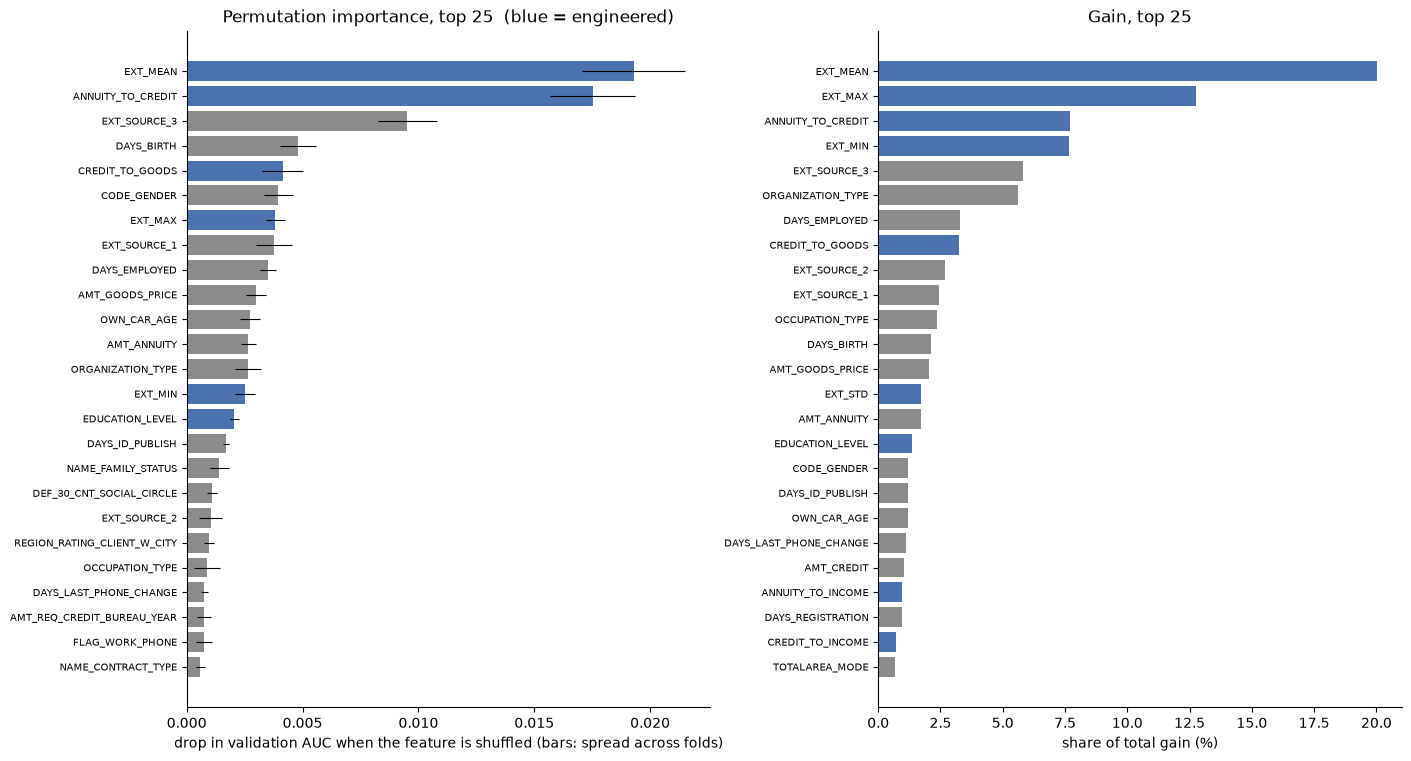

the EDA's 18 candidates, in the tuned model:
                         gain_pct  gain_rank  auc_drop  perm_rank  folds_positive
AMT_INCOME_TOTAL             0.55         31   0.00039         31               5
FLOORSMAX_AVG                0.46         34   0.00025         36               5
ENQUIRIES_MISSING            0.13         46   0.00015         38               5
LIVINGAREA_AVG               0.62         27   0.00013         39               4
FLAG_OWN_CAR                 0.23         41   0.00012         40               4
TOTALAREA_MODE               0.66         25   0.00009         41               4
HOUR_APPR_PROCESS_START      0.30         38   0.00008         42               3
FLAG_PHONE                   0.05         50   0.00005         44               4
CNT_FAM_MEMBERS              0.11         48   0.00005         45               5
NAME_INCOME_TYPE             0.20         43   0.00005         46               4
NAME_TYPE_SUITE              0.13         47   0.0000

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7.5), layout='constrained')
top = importance.sort_values('auc_drop', ascending=False).head(25).iloc[::-1]
axes[0].barh(top.index, top['auc_drop'], xerr=top['auc_drop_std'], color=np.where(top['engineered'], '#4C72B0', '#8C8C8C'), error_kw={'elinewidth': 0.8, 'ecolor': 'black'})
axes[0].set_xlabel('drop in validation AUC when the feature is shuffled (bars: spread across folds)')
axes[0].set_title('Permutation importance, top 25  (blue = engineered)')
top = importance.sort_values('gain_pct', ascending=False).head(25).iloc[::-1]
axes[1].barh(top.index, top['gain_pct'], color=np.where(top['engineered'], '#4C72B0', '#8C8C8C'))
axes[1].set_xlabel('share of total gain (%)')
axes[1].set_title('Gain, top 25')
for ax in axes:
    ax.tick_params(axis='y', labelsize=7)
sns.despine()
plt.show()

# the 18 features the EDA flagged (ranks 38 to 55 in its permutation importance of an untuned model)
EDA_CANDIDATES = ['TOTALAREA_MODE', 'LIVINGAREA_AVG', 'FLOORSMAX_AVG', 'HOUR_APPR_PROCESS_START', 'N_BUILDING_MISSING', 'CNT_FAM_MEMBERS',
                  'CNT_CHILDREN', 'FLAG_DOCUMENT_6', 'REG_CITY_NOT_WORK_CITY', 'N_CITY_MISMATCH', 'ENQUIRIES_MISSING', 'FLAG_EMP_PHONE',
                  'AMT_INCOME_TOTAL', 'LIVE_CITY_NOT_WORK_CITY', 'NAME_INCOME_TYPE', 'FLAG_OWN_CAR', 'FLAG_PHONE', 'NAME_TYPE_SUITE']
assert len(EDA_CANDIDATES) == 18 and set(EDA_CANDIDATES) <= set(FEATURES)
flagged = importance.loc[EDA_CANDIDATES, ['gain_pct', 'gain_rank', 'auc_drop', 'perm_rank', 'folds_positive']]
print("the EDA's 18 candidates, in the tuned model:")
print(flagged.sort_values('perm_rank').round({'gain_pct': 2, 'auc_drop': 5}).to_string())
print(f"\nof the 18, in the tuned model's bottom 18 by permutation importance: {int((flagged['perm_rank'] > 37).sum())}; by gain: {int((flagged['gain_rank'] > 37).sum())}")
print(f"together they hold {flagged['gain_pct'].sum():.1f}% of the gain")

### 8.2 Group ablations

Each group of features is removed in turn and the model is retrained and rescored on the same folds. The groups are defined by subject, not by any measured importance, so this test involves no selection and no leakage. It also answers a different question from permutation importance: not "what does the fitted model use" but "what can the model not do without, once it has the chance to compensate".

In [70]:
class KeepColumns(BaseEstimator, TransformerMixin):
    # keeps a fixed list of columns
    def __init__(self, columns):
        self.columns = columns
    def fit(self, X, y=None):
        missing = [c for c in self.columns if c not in X.columns]
        if missing:
            raise ValueError(f"columns not in the data: {missing}")
        self.columns_ = list(self.columns)      # recorded so that scikit-learn knows the step has been fitted
        return self
    def transform(self, X):
        return X[self.columns_]

def with_columns(columns, model):
    return make_model_pipeline(Pipeline([('encode', tree_pre()), ('keep', KeepColumns(list(columns)))]), model)

EXT_SUMMARIES = ['EXT_MEAN', 'EXT_MIN', 'EXT_MAX', 'EXT_STD', 'EXT_N_MISSING']
LOAN_RATIOS = ['ANNUITY_TO_CREDIT', 'CREDIT_TO_GOODS', 'CREDIT_TO_INCOME', 'ANNUITY_TO_INCOME']
RAW_AMOUNTS = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']
groups_to_drop = {
    'external score summaries (5)': EXT_SUMMARIES,
    'raw external scores (3)': EXT,
    'every external score feature (8)': EXT + EXT_SUMMARIES,
    'ANNUITY_TO_CREDIT alone': ['ANNUITY_TO_CREDIT'],
    'loan ratios (4)': LOAN_RATIOS,
    'raw amounts (4)': RAW_AMOUNTS,
    'missingness features (3)': ['N_MISSING', 'N_BUILDING_MISSING', 'ENQUIRIES_MISSING'],
    'building features (4)': ['FLOORSMAX_AVG', 'LIVINGAREA_AVG', 'TOTALAREA_MODE', 'N_BUILDING_MISSING'],
    'address features (4)': ['REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'N_CITY_MISMATCH'],
    'contact and document flags (5)': ['FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_PHONE', 'FLAG_DOCUMENT_3', 'FLAG_DOCUMENT_6'],
    'all text columns (9)': list(TEXT_FEATURES),
    'gender': ['CODE_GENDER'],
    'gender, age and family (5)': ['CODE_GENDER', 'DAYS_BIRTH', 'NAME_FAMILY_STATUS', 'CNT_CHILDREN', 'CNT_FAM_MEMBERS'],
    "the EDA's 18 candidates": EDA_CANDIDATES,
}
ablation = {}
for label, dropped in groups_to_drop.items():
    assert set(dropped) <= set(FEATURES), label
    kept = [c for c in FEATURES if c not in dropped]
    name = f'without {label}'
    register(name, cross_validate(with_columns(kept, FAST())), columns=len(kept), note='stage 8 ablation')
    c = compare(name, BASE)
    ablation[label] = {'features_left': len(kept), 'roc_auc': results[name]['mean']['roc_auc'], 'change': c['mean_difference'],
                       'change_std': c['difference_std'], 'folds_worse': N_SPLITS - c['folds_better'],
                       'sum_of_single_shuffles': -importance.loc[dropped, 'auc_drop'].sum()}
ablation = pd.DataFrame(ablation).T.sort_values('change')
print(f"all 55 features: {results[BASE]['mean']['roc_auc']:.4f}")
ablation.round({'roc_auc': 4, 'change': 4, 'change_std': 4, 'sum_of_single_shuffles': 4})

all 55 features: 0.7677


,features_left,roc_auc,change,change_std,folds_worse,sum_of_single_shuffles
every external score feature (8),47.0,0.7193,-0.0483,0.0034,5.0,-0.0404
loan ratios (4),51.0,0.7596,-0.0081,0.0014,5.0,-0.0222
ANNUITY_TO_CREDIT alone,54.0,0.7607,-0.0070,0.0006,5.0,-0.0175
"gender, age and family (5)",50.0,0.7643,-0.0034,0.0010,5.0,-0.0102
raw external scores (3),52.0,0.7652,-0.0025,0.0003,5.0,-0.0143
all text columns (9),46.0,0.7656,-0.0021,0.0011,5.0,-0.0099
raw amounts (4),51.0,0.7662,-0.0014,0.0012,5.0,-0.0064
gender,54.0,0.7666,-0.0010,0.0007,5.0,-0.0040
contact and document flags (5),50.0,0.7673,-0.0003,0.0008,4.0,-0.0013
address features (4),51.0,0.7675,-0.0002,0.0006,3.0,-0.0004


### 8.3 Pruning curves, with selection inside each training fold

The pipeline gains a step that chooses the features. Fitted on the training folds, it trains a model, ranks the features, and keeps the top *k*. The final model is then trained on those features only. Because the step is inside the pipeline, `cross_validate()` reruns the choice from scratch for every fold, without the validation fold.

Two rankings are tried. The first uses **gain**, which comes free with the fitted model.

In [71]:
class ImportanceSelector(BaseEstimator, TransformerMixin):
    # Fits a model on the rows it is given, ranks the features by gain, and keeps the top `keep`.
    def __init__(self, model, keep):
        self.model = model
        self.keep = keep
    def fit(self, X, y):
        fitted = clone(self.model).fit(X, y)
        gain = pd.Series(fitted.booster_.feature_importance(importance_type='gain'), index=list(X.columns))
        chosen = set(gain.sort_values(ascending=False).index[:self.keep])
        self.selected_ = [c for c in X.columns if c in chosen]
        return self
    def transform(self, X):
        return X[self.selected_]

def with_selector(keep, model):
    return make_model_pipeline(Pipeline([('encode', tree_pre()), ('select', ImportanceSelector(FAST(), keep))]), model)

KEEP_OPTIONS = [45, 40, 35, 30, 25, 20, 15, 10]
curve = {55: {'roc_auc': results[BASE]['mean']['roc_auc'], 'change': 0.0, 'change_std': 0.0, 'folds_worse': 0, 'pr_auc': results[BASE]['mean']['pr_auc']}}
for keep in KEEP_OPTIONS:
    name = f'top {keep} features, chosen inside each fold'
    register(name, cross_validate(with_selector(keep, FAST())), columns=keep, note='stage 8 pruning')
    c = compare(name, BASE)
    curve[keep] = {'roc_auc': results[name]['mean']['roc_auc'], 'change': c['mean_difference'], 'change_std': c['difference_std'],
                   'folds_worse': N_SPLITS - c['folds_better'], 'pr_auc': results[name]['mean']['pr_auc']}
curve = pd.DataFrame(curve).T
curve.index.name = 'features_kept'

# how consistent is the choice from fold to fold? Each fold's ranking is the one its selector would have made.
fold_rank = gain_share.rank(ascending=False)
stability = {}
for keep in KEEP_OPTIONS:
    chosen = (fold_rank <= keep)
    stability[keep] = {'in_all_5_folds': int((chosen.sum(axis=1) == N_SPLITS).sum()), 'in_some_folds_only': int(((chosen.sum(axis=1) > 0) & (chosen.sum(axis=1) < N_SPLITS)).sum())}
curve = curve.join(pd.DataFrame(stability).T)
curve.round({'roc_auc': 4, 'change': 4, 'change_std': 4, 'pr_auc': 4})

,roc_auc,change,change_std,folds_worse,pr_auc,in_all_5_folds,in_some_folds_only
features_kept,,,,,,,
55,0.7677,0.0000,0.0000,0.0,0.2530,NaN,NaN
45,0.7680,0.0003,0.0008,1.0,0.2531,43.0,5.0
40,0.7675,-0.0002,0.0008,3.0,0.2529,37.0,5.0
35,0.7667,-0.0010,0.0006,5.0,0.2518,34.0,2.0
30,0.7651,-0.0026,0.0010,5.0,0.2502,27.0,5.0
25,0.7641,-0.0036,0.0008,5.0,0.2481,22.0,7.0
20,0.7639,-0.0038,0.0008,5.0,0.2468,19.0,2.0
15,0.7597,-0.0079,0.0014,5.0,0.2421,15.0,0.0
10,0.7536,-0.0140,0.0021,5.0,0.2345,9.0,2.0


The second ranking uses **permutation importance**. To keep it leak-free, the selector sets aside 20% of the training folds, fits a model on the other 80%, and measures on the 20% how much the AUC drops when each feature is shuffled. The validation fold is not involved.

The EDA's fixed list is shown alongside. It keeps 37 features, so 37 is included as one of the sizes.

In [72]:
class PermutationSelector(BaseEstimator, TransformerMixin):
    # Ranks features by permutation importance measured on a slice of the rows it is given, and keeps the top `keep`.
    def __init__(self, model, keep, validation_fraction=0.2, seed=SEED):
        self.model = model
        self.keep = keep
        self.validation_fraction = validation_fraction
        self.seed = seed
    def fit(self, X, y):
        y = np.asarray(y)
        grow, watch = train_test_split(np.arange(len(y)), test_size=self.validation_fraction, stratify=y, random_state=self.seed)
        fitted = clone(self.model).fit(X.iloc[grow], y[grow])
        X_watch, y_watch = X.iloc[watch], y[watch]
        reference_auc = roc_auc_score(y_watch, fitted.predict_proba(X_watch)[:, 1])
        rng = np.random.default_rng(self.seed)
        drops = {}
        for c in X.columns:
            shuffled = X_watch.copy()
            shuffled[c] = shuffled[c].values[rng.permutation(len(shuffled))]
            drops[c] = reference_auc - roc_auc_score(y_watch, fitted.predict_proba(shuffled)[:, 1])
        self.importances_ = pd.Series(drops)
        chosen = set(self.importances_.sort_values(ascending=False).index[:self.keep])
        self.selected_ = [c for c in X.columns if c in chosen]
        return self
    def transform(self, X):
        return X[self.selected_]

def with_permutation_selector(keep, model):
    return make_model_pipeline(Pipeline([('encode', tree_pre()), ('select', PermutationSelector(FAST(), keep))]), model)

PERM_KEEP = [40, 37, 30, 20]
perm_curve = {}
for keep in PERM_KEEP:
    name = f'top {keep} features by permutation, chosen inside each fold'
    register(name, cross_validate(with_permutation_selector(keep, FAST())), columns=keep, note='stage 8 pruning')
    c = compare(name, BASE)
    perm_curve[keep] = {'by_permutation_inside_fold': results[name]['mean']['roc_auc'], 'change': c['mean_difference'], 'change_std': c['difference_std'],
                        'folds_worse': N_SPLITS - c['folds_better'],
                        'by_gain_inside_fold': curve.loc[keep, 'roc_auc'] if keep in curve.index else np.nan,
                        'seconds_per_fold': results[name]['mean']['fit_seconds']}
perm_curve = pd.DataFrame(perm_curve).T
perm_curve.index.name = 'features_kept'
eda = ablation.loc["the EDA's 18 candidates"]
print(f"all 55 features: {results[BASE]['mean']['roc_auc']:.4f}")
print(f"the EDA's fixed list of 37: {eda['roc_auc']:.4f} ({eda['change']:+.4f}, worse in {int(eda['folds_worse'])} of {N_SPLITS} folds)")
perm_curve.round(4)

all 55 features: 0.7677
the EDA's fixed list of 37: 0.7677 (+0.0000, worse in 3 of 5 folds)


,by_permutation_inside_fold,change,change_std,folds_worse,by_gain_inside_fold,seconds_per_fold
features_kept,,,,,,
40,0.7679,0.0002,0.0007,1.0,0.7675,61.7895
37,0.7678,0.0001,0.0006,2.0,NaN,56.2854
30,0.7673,-0.0003,0.0010,3.0,0.7651,53.8155
20,0.7651,-0.0026,0.0006,5.0,0.7639,49.4302


### 8.4 The wrong way: choosing features on the validation folds

To measure what the structure above protects against, the features are chosen once, using the permutation importance from section 8.1. That importance was measured on the validation folds. The shortened list is then scored on those same folds.

The comparison is with the permutation selector from section 8.3, so both sides rank features the same way. The only difference is where the ranking was measured: inside each training fold, or on the validation folds themselves.

In [73]:
leaky_order = importance.sort_values('auc_drop', ascending=False).index.tolist()
leak = {}
for keep in PERM_KEEP:
    name = f'top {keep} features, chosen on the validation folds'
    register(name, cross_validate(with_columns([c for c in FEATURES if c in set(leaky_order[:keep])], FAST())), columns=keep, note='stage 8, wrong on purpose')
    proper = f'top {keep} features by permutation, chosen inside each fold'
    c = compare(name, proper)
    leak[keep] = {'chosen_inside_each_fold': results[proper]['mean']['roc_auc'], 'chosen_on_validation_folds': results[name]['mean']['roc_auc'],
                  'inflation': c['mean_difference'], 'inflation_std': c['difference_std'], 'folds_higher': c['folds_better'],
                  'against_all_55': results[name]['mean']['roc_auc'] - results[BASE]['mean']['roc_auc']}
leak = pd.DataFrame(leak).T
leak.index.name = 'features_kept'
leak.round(4)

,chosen_inside_each_fold,chosen_on_validation_folds,inflation,inflation_std,folds_higher,against_all_55
features_kept,,,,,,
40,0.7679,0.7684,0.0005,0.0005,4.0,0.0007
37,0.7678,0.7684,0.0006,0.0007,3.0,0.0008
30,0.7673,0.7682,0.0009,0.0007,4.0,0.0005
20,0.7651,0.7670,0.0020,0.0007,5.0,-0.0006


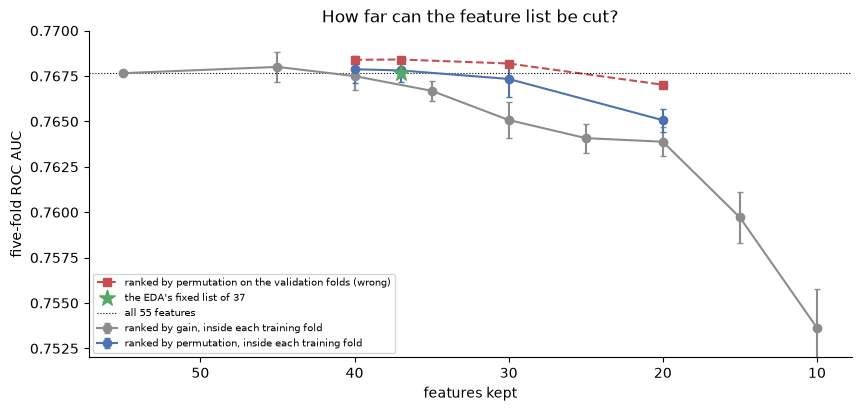

In [74]:
fig, ax = plt.subplots(figsize=(8.5, 4), layout='constrained')
ax.errorbar(curve.index, curve['roc_auc'], yerr=curve['change_std'], marker='o', color='#8C8C8C', capsize=2, label='ranked by gain, inside each training fold')
ax.errorbar(perm_curve.index, perm_curve['by_permutation_inside_fold'], yerr=perm_curve['change_std'], marker='o', color='#4C72B0', capsize=2,
            label='ranked by permutation, inside each training fold')
ax.plot(leak.index, leak['chosen_on_validation_folds'], marker='s', linestyle='--', color='#C44E52', label='ranked by permutation on the validation folds (wrong)')
ax.scatter([37], [ablation.loc["the EDA's 18 candidates", 'roc_auc']], marker='*', s=140, color='#55A868', zorder=5, label="the EDA's fixed list of 37")
ax.axhline(results[BASE]['mean']['roc_auc'], color='black', linewidth=0.8, linestyle=':', label='all 55 features')
ax.set_ylim(0.752, 0.770)
ax.invert_xaxis()
ax.set_xlabel('features kept')
ax.set_ylabel('five-fold ROC AUC')
ax.set_title('How far can the feature list be cut?')
ax.legend(fontsize=7, loc='lower left')
sns.despine()
plt.show()

### 8.5 Confirming the shortened list on the final model

Everything above used the faster version of the tuned model. The shortened list is now scored on the model that is actually carried forward (learning rate 0.02, 2,365 trees), on the folds used throughout and on the fresh folds from stage 7, against the same model with all 55 features.

The list tested is the EDA's: the 55 features minus its 18 candidates. It is a fixed list, so the served model needs no selection step, and it was written down before this notebook existed.

In [75]:
PRUNED_FEATURES = [c for c in FEATURES if c not in EDA_CANDIDATES]
FULL_FINAL = 'LightGBM, tuned, learning rate 0.02'      # all 55 features, scored in stage 7
register('final model, 37 features', cross_validate(with_columns(PRUNED_FEATURES, FINAL())), columns=len(PRUNED_FEATURES), note='stage 8')

full_fresh = cross_validate(make_model_pipeline(tree_pre(), FINAL()), fold=fresh_fold)
pruned_fresh = cross_validate(with_columns(PRUNED_FEATURES, FINAL()), fold=fresh_fold)

def paired(a, b):
    d = a['folds']['roc_auc'].values - b['folds']['roc_auc'].values
    return {'all_55': b['mean']['roc_auc'], 'pruned_37': a['mean']['roc_auc'], 'change': d.mean(), 'change_std': d.std(ddof=1),
            'folds_worse': int((d < 0).sum()), 'pr_auc_55': b['mean']['pr_auc'], 'pr_auc_37': a['mean']['pr_auc'],
            'seconds_per_fold_55': b['mean']['fit_seconds'], 'seconds_per_fold_37': a['mean']['fit_seconds']}

confirm = pd.DataFrame({'folds used throughout': paired(results['final model, 37 features'], results[FULL_FINAL]),
                        'fresh folds': paired(pruned_fresh, full_fresh)}).T
print(f"{len(PRUNED_FEATURES)} features kept: {sum(c in ENGINEERED_SET for c in PRUNED_FEATURES)} engineered, "
      f"{sum(c in TEXT_FEATURES for c in PRUNED_FEATURES)} text, {sum(c not in ENGINEERED_SET for c in PRUNED_FEATURES)} raw")
print('ROC AUC by fold, folds used throughout')
print(pd.DataFrame({'all 55': results[FULL_FINAL]['folds']['roc_auc'], 'pruned 37': results['final model, 37 features']['folds']['roc_auc']}).T.round(4).to_string())
print(f"average predicted default rate: {results[FULL_FINAL]['oof'].mean() * 100:.2f}% with 55 features, {results['final model, 37 features']['oof'].mean() * 100:.2f}% with 37")
print(f"rank correlation between the two models' predictions: {pd.Series(results[FULL_FINAL]['oof']).corr(pd.Series(results['final model, 37 features']['oof']), method='spearman'):.4f}")
print('\nfeatures kept:')
for g, members in pd.Series({c: ('engineered' if c in ENGINEERED_SET else 'text' if c in TEXT_FEATURES else 'raw numeric') for c in PRUNED_FEATURES}).groupby(lambda c: 'engineered' if c in ENGINEERED_SET else 'text' if c in TEXT_FEATURES else 'raw numeric'):
    print(f"  {g} ({len(members)}): {', '.join(members.index)}")
print(holdout)
assert holdout.log == []
confirm.round(4)

37 features kept: 11 engineered, 6 text, 26 raw
ROC AUC by fold, folds used throughout
fold            0       1       2       3       4
all 55     0.7680  0.7662  0.7677  0.7688  0.7708
pruned 37  0.7674  0.7672  0.7681  0.7687  0.7713
average predicted default rate: 13.55% with 55 features, 13.57% with 37
rank correlation between the two models' predictions: 0.9926

features kept:


  engineered (11): EXT_MEAN, EXT_MIN, EXT_MAX, EXT_STD, EXT_N_MISSING, ANNUITY_TO_CREDIT, CREDIT_TO_GOODS, CREDIT_TO_INCOME, ANNUITY_TO_INCOME, N_MISSING, EDUCATION_LEVEL
  raw numeric (20): AMT_CREDIT, AMT_ANNUITY, AMT_GOODS_PRICE, REGION_POPULATION_RELATIVE, DAYS_BIRTH, DAYS_EMPLOYED, DAYS_REGISTRATION, DAYS_ID_PUBLISH, OWN_CAR_AGE, FLAG_WORK_PHONE, REGION_RATING_CLIENT_W_CITY, REG_CITY_NOT_LIVE_CITY, EXT_SOURCE_1, EXT_SOURCE_2, EXT_SOURCE_3, OBS_30_CNT_SOCIAL_CIRCLE, DEF_30_CNT_SOCIAL_CIRCLE, DAYS_LAST_PHONE_CHANGE, FLAG_DOCUMENT_3, AMT_REQ_CREDIT_BUREAU_YEAR
  text (6): NAME_CONTRACT_TYPE, CODE_GENDER, NAME_FAMILY_STATUS, NAME_HOUSING_TYPE, OCCUPATION_TYPE, ORGANIZATION_TYPE
HoldoutVault(61,503 rows, 4,965 defaults, opened 0 times)


,all_55,pruned_37,change,change_std,folds_worse,pr_auc_55,pr_auc_37,seconds_per_fold_55,seconds_per_fold_37
folds used throughout,0.7683,0.7685,0.0002,0.0006,2.0,0.2537,0.2539,25.2611,12.7043
fresh folds,0.7685,0.7691,0.0006,0.0008,1.0,0.2547,0.2550,24.8963,12.7877


### 8.6 Dropping `N_MISSING`, to reduce the raw data the model needs

A shorter feature list is not the same as needing less raw data. `N_MISSING` counts the empty cells across all 120 raw application columns, so as long as it is a feature, the served model needs the complete application record. It is also weak in the tuned model: shuffling it costs 0.00006 AUC.

It was not on the EDA's list, so it has not been tested for removal. This section tests it.

**The rule, set before looking at the result:** `N_MISSING` is dropped if the 36-feature model is no more than 0.0003 below the 37-feature model on both the folds used throughout and the fresh folds. This is a single, pre-specified comparison of two fixed lists, so no features are being selected on the validation data.

In [76]:
WITHOUT_N_MISSING = [c for c in PRUNED_FEATURES if c != 'N_MISSING']
assert len(WITHOUT_N_MISSING) == 36

register('final model, 36 features', cross_validate(with_columns(WITHOUT_N_MISSING, FINAL())), columns=36, note='stage 8')
without_fresh = cross_validate(with_columns(WITHOUT_N_MISSING, FINAL()), fold=fresh_fold)

def versus(a, b):
    d = a['folds']['roc_auc'].values - b['folds']['roc_auc'].values
    return {'with_N_MISSING_37': b['mean']['roc_auc'], 'without_36': a['mean']['roc_auc'], 'change': d.mean(), 'change_std': d.std(ddof=1),
            'folds_worse': int((d < 0).sum()), 'pr_auc_37': b['mean']['pr_auc'], 'pr_auc_36': a['mean']['pr_auc']}

n_missing_test = pd.DataFrame({'folds used throughout': versus(results['final model, 36 features'], results['final model, 37 features']),
                               'fresh folds': versus(without_fresh, pruned_fresh)}).T
print('ROC AUC by fold, folds used throughout')
print(pd.DataFrame({'37 features': results['final model, 37 features']['folds']['roc_auc'],
                    '36 features': results['final model, 36 features']['folds']['roc_auc']}).T.round(4).to_string())
print(f"rank correlation between the two models' predictions: "
      f"{pd.Series(results['final model, 37 features']['oof']).corr(pd.Series(results['final model, 36 features']['oof']), method='spearman'):.4f}")

print('ROC AUC by fold, fresh folds')
print(pd.DataFrame({'37 features': pruned_fresh['folds']['roc_auc'], '36 features': without_fresh['folds']['roc_auc'],
                    'difference': without_fresh['folds']['roc_auc'] - pruned_fresh['folds']['roc_auc']}).T.round(5).to_string())
print('change to five decimals:', {k: round(float(v), 5) for k, v in n_missing_test['change'].items()})

DROP_N_MISSING = bool((n_missing_test['change'] >= -0.0003).all())
print(f"\nrule: drop if the change is no worse than -0.0003 on both fold sets -> {'DROP N_MISSING' if DROP_N_MISSING else 'KEEP N_MISSING'}")
FINAL_FEATURES = WITHOUT_N_MISSING if DROP_N_MISSING else PRUNED_FEATURES
FINAL_NAME = 'final model, 36 features' if DROP_N_MISSING else 'final model, 37 features'

# the raw application columns each feature list needs
ALL_RAW_COLUMNS = [c for c in raw_test.columns if c != 'SK_ID_CURR']
BUILT_FROM = {'EXT_MEAN': EXT, 'EXT_MIN': EXT, 'EXT_MAX': EXT, 'EXT_STD': EXT, 'EXT_N_MISSING': EXT,
              'ANNUITY_TO_CREDIT': ['AMT_ANNUITY', 'AMT_CREDIT'], 'CREDIT_TO_GOODS': ['AMT_CREDIT', 'AMT_GOODS_PRICE'],
              'CREDIT_TO_INCOME': ['AMT_CREDIT', 'AMT_INCOME_TOTAL'], 'ANNUITY_TO_INCOME': ['AMT_ANNUITY', 'AMT_INCOME_TOTAL'],
              'EDUCATION_LEVEL': ['NAME_EDUCATION_TYPE'], 'N_MISSING': ALL_RAW_COLUMNS,
              'N_BUILDING_MISSING': [c for c in ALL_RAW_COLUMNS if c.endswith(('_AVG', '_MODE', '_MEDI'))],
              'ENQUIRIES_MISSING': ['AMT_REQ_CREDIT_BUREAU_YEAR'], 'N_CITY_MISMATCH': CITY}
def raw_columns_needed(features):
    needed = set()
    for f in features:
        needed.update(BUILT_FROM.get(f, [f]))
    assert needed <= set(ALL_RAW_COLUMNS), needed - set(ALL_RAW_COLUMNS)
    return sorted(needed)

needs = pd.Series({'all 55 features': len(raw_columns_needed(FEATURES)), '37 features': len(raw_columns_needed(PRUNED_FEATURES)),
                   '36 features, without N_MISSING': len(raw_columns_needed(WITHOUT_N_MISSING))}, name='raw application columns needed')
print(f"\nthe raw application file has {len(ALL_RAW_COLUMNS)} columns besides the ID")
print(needs.to_string())
RAW_COLUMNS_NEEDED = raw_columns_needed(FINAL_FEATURES)
print(f"\nfeature list carried forward: {len(FINAL_FEATURES)} features, built from {len(RAW_COLUMNS_NEEDED)} raw columns:")
print(', '.join(RAW_COLUMNS_NEEDED))
print(holdout)
assert holdout.log == []
n_missing_test.round(4)

ROC AUC by fold, folds used throughout
fold              0       1       2       3       4
37 features  0.7674  0.7672  0.7681  0.7687  0.7713
36 features  0.7676  0.7668  0.7682  0.7689  0.7710
rank correlation between the two models' predictions: 0.9954
ROC AUC by fold, fresh folds
fold               0        1        2        3        4
37 features  0.77382  0.77563  0.76571  0.76590  0.76467
36 features  0.77297  0.77558  0.76597  0.76536  0.76457
difference  -0.00086 -0.00005  0.00026 -0.00054 -0.00010
change to five decimals: {'folds used throughout': -0.0, 'fresh folds': -0.00026}

rule: drop if the change is no worse than -0.0003 on both fold sets -> DROP N_MISSING

the raw application file has 120 columns besides the ID


all 55 features                   120
37 features                       120
36 features, without N_MISSING     28

feature list carried forward: 36 features, built from 28 raw columns:
AMT_ANNUITY, AMT_CREDIT, AMT_GOODS_PRICE, AMT_INCOME_TOTAL, AMT_REQ_CREDIT_BUREAU_YEAR, CODE_GENDER, DAYS_BIRTH, DAYS_EMPLOYED, DAYS_ID_PUBLISH, DAYS_LAST_PHONE_CHANGE, DAYS_REGISTRATION, DEF_30_CNT_SOCIAL_CIRCLE, EXT_SOURCE_1, EXT_SOURCE_2, EXT_SOURCE_3, FLAG_DOCUMENT_3, FLAG_WORK_PHONE, NAME_CONTRACT_TYPE, NAME_EDUCATION_TYPE, NAME_FAMILY_STATUS, NAME_HOUSING_TYPE, OBS_30_CNT_SOCIAL_CIRCLE, OCCUPATION_TYPE, ORGANIZATION_TYPE, OWN_CAR_AGE, REGION_POPULATION_RELATIVE, REGION_RATING_CLIENT_W_CITY, REG_CITY_NOT_LIVE_CITY
HoldoutVault(61,503 rows, 4,965 defaults, opened 0 times)


,with_N_MISSING_37,without_36,change,change_std,folds_worse,pr_auc_37,pr_auc_36
folds used throughout,0.7685,0.7685,-0.0000,0.0003,2.0,0.2539,0.2539
fresh folds,0.7691,0.7689,-0.0003,0.0004,4.0,0.2550,0.2551


### Stage 8 findings

**What the tuned model relies on**

| Rank | Feature | AUC drop when shuffled | Share of gain |
|---:|---|---:|---:|
| 1 | `EXT_MEAN` | 0.0193 | 20.0% |
| 2 | `ANNUITY_TO_CREDIT` | 0.0175 | 7.7% |
| 3 | `EXT_SOURCE_3` | 0.0095 | 5.8% |
| 4 | `DAYS_BIRTH` | 0.0048 | 2.1% |
| 5 | `CREDIT_TO_GOODS` | 0.0041 | 3.3% |
| 6 | `CODE_GENDER` | 0.0040 | 1.2% |
| 7 | `EXT_MAX` | 0.0038 | 12.7% |
| 8 | `EXT_SOURCE_1` | 0.0038 | 2.4% |

- The model's reliance is concentrated. The top 5 features hold 54% of the gain and the top 20 hold 87%.
- The 14 engineered features hold 57% of the gain and half of the permutation importance.
- `ANNUITY_TO_CREDIT` is now almost level with `EXT_MEAN`. In the EDA's untuned model `EXT_MEAN` mattered about five times as much. Tuning let the model use the ratio's fine structure.
- At the other end, 19 features cost under 0.0002 AUC when shuffled, and 17 do not help in all five folds.
- The two measures broadly agree (rank agreement 0.87) but not on the redundant features. `EXT_MAX` and `EXT_MIN` rank 2nd and 4th by gain and 7th and 14th by permutation.

**What the model needs is not the same as what it uses**

| Group removed, model retrained | ROC AUC | Change | Folds worse |
|---|---:|---:|---:|
| Every external score feature (8) | 0.7193 | -0.0483 | 5 of 5 |
| Loan ratios (4) | 0.7596 | -0.0081 | 5 of 5 |
| `ANNUITY_TO_CREDIT` alone | 0.7607 | -0.0070 | 5 of 5 |
| Gender, age and family (5) | 0.7643 | -0.0034 | 5 of 5 |
| Raw external scores (3) | 0.7652 | -0.0025 | 5 of 5 |
| All text columns (9) | 0.7656 | -0.0021 | 5 of 5 |
| Raw amounts (4) | 0.7662 | -0.0014 | 5 of 5 |
| Gender | 0.7666 | -0.0010 | 5 of 5 |
| Contact and document flags (5) | 0.7673 | -0.0003 | 4 of 5 |
| Address features (4) | 0.7675 | -0.0002 | 3 of 5 |
| The EDA's 18 candidates | 0.7677 | 0.0000 | 3 of 5 |
| Missingness features (3) | 0.7680 | +0.0003 | 1 of 5 |
| Building features (4) | 0.7681 | +0.0005 | 2 of 5 |
| External score summaries (5) | 0.7683 | +0.0006 | 1 of 5 |

- The external scores carry the model. Without them it scores 0.7193, below the stage 4 logistic regression.
- `ANNUITY_TO_CREDIT` cannot be replaced. Removing that one feature costs 0.0070, and the model cannot rebuild it from the raw amounts.
- `EXT_MEAN` is the most-used feature and can be removed for nothing. Shuffling it costs 0.019. Removing all five external score summaries and retraining changes nothing, because the model rebuilds them from the three raw scores. The reverse does not hold: removing the raw scores costs 0.0025.
- So permutation importance says what a fitted model leans on, and ablation says what a model cannot do without. They answer different questions, and for pruning the second is the one that matters.
- Removing gender costs 0.0010. Removing gender, age and family status together costs 0.0034. That is the price in accuracy of a model that does not use those attributes.

**The feature list can be cut from 55 to 37 at no cost**

| | All 55 | Pruned to 37 | Change | Folds worse |
|---|---:|---:|---:|---:|
| Final model, folds used throughout | 0.7683 | 0.7685 | +0.0002 | 2 of 5 |
| Final model, fresh folds | 0.7685 | 0.7691 | +0.0006 | 1 of 5 |

- The 37 are the 55 features minus the EDA's 18 candidates. 16 of those 18 are still in the tuned model's bottom 18.
- The two models rank applicants almost identically (rank correlation 0.993), and the pruned model trains in half the time.
- A leak-free selector asked to keep 37 features reaches 0.7678, the same as the fixed list. That supports the size of the cut without depending on which list is used.
- Cutting further starts to cost. At 30 features the best leak-free selection loses 0.0003, and at 20 it loses 0.0026 in every fold.

**One more feature goes, and the raw data needed falls from 120 columns to 28**

| | 37 features | 36 features, without `N_MISSING` | Change | Folds worse |
|---|---:|---:|---:|---:|
| Final model, folds used throughout | 0.7685 | 0.7685 | 0.00000 | 2 of 5 |
| Final model, fresh folds | 0.7691 | 0.7689 | -0.00026 | 4 of 5 |

- `N_MISSING` counts empty cells across all 120 raw application columns. While it is a feature, serving the model needs the complete application record, however short the feature list is.
- Without it, the 36 features are built from 28 raw columns.
- The rule was fixed before the result: drop it if the 36-feature model is no more than 0.0003 below the 37-feature one on both sets of folds. It passes.
- The pass is narrow on the fresh folds. The change there is -0.00026 against a threshold of -0.0003, and four of the five folds are slightly worse (-0.00086, -0.00005, +0.00026, -0.00054, -0.00010). On the folds used throughout there is no change at all.
- With a fold-by-fold spread of 0.0004, a mean of -0.00026 over five folds is about 1.4 standard errors from zero. It cannot be told apart from no effect, but the honest reading is that dropping `N_MISSING` costs somewhere between nothing and 0.0003.
- The two models rank applicants almost identically (rank correlation 0.995), and the 36-feature model still scores above the full 55-feature model on both sets of folds.

**Permutation importance is the better guide for pruning**
- With features chosen inside each training fold, ranking by permutation importance loses 0.0003 at 30 features. Ranking by gain loses 0.0026.
- Gain rewards features the model splits on often, which favours redundant ones. It keeps `EXT_MAX` and `EXT_MIN` and discards weaker features that carry information nothing else has.

**The leak that selection inside the folds prevents**

| Features kept | Chosen inside each fold | Chosen on the validation folds | Inflation |
|---:|---:|---:|---:|
| 40 | 0.7679 | 0.7684 | +0.0005 |
| 37 | 0.7678 | 0.7684 | +0.0006 |
| 30 | 0.7673 | 0.7682 | +0.0009 |
| 20 | 0.7651 | 0.7670 | +0.0020 |

- Both columns rank by permutation importance. The only difference is where it was measured.
- The inflation is between 0.0005 and 0.0020 and grows as more features are cut. It is smaller than the resampling leak in stage 6 (0.047), and larger than the preprocessing leak in stage 4 (0.00006).
- It is enough to change the conclusion. At 30 to 40 features the leaky version scores above the full model, which would suggest that pruning improves accuracy. The leak-free result is that pruning does no harm.
- An earlier version of this comparison set gain-based selection inside the folds against permutation-based selection on the validation folds and reported an inflation of 0.003. Most of that was the difference between the two ranking methods. The comparison was redone with the method held fixed.

**Limits**
- The fixed list of 37 was drawn up in the EDA, which saw every training row including the holdout, and it was adopted here after its cross-validation score was seen. Both are mild forms of the selection leak. The independent leak-free selector agreeing with it at the same size is the main reassurance. The holdout in stage 11 scores the 37-feature model and is the real check.
- The model's settings were tuned on 55 features and have not been retuned for 37. With 18 near-useless features removed, the best settings are unlikely to have moved much, but this was not tested.
- Importance and ablations were measured on the faster version of the tuned model (learning rate 0.05). Only the final comparison used the model carried forward.
- Permutation importance was measured with two shuffles per feature per fold. The ranking among the weakest features is not precise.
- The `N_MISSING` decision rests on a difference too small to measure reliably. If the last 0.0003 of AUC mattered more than the simplicity of the served model, keeping it would be defensible. Setting `DROP_N_MISSING = False` in section 8.6 restores the 37-feature list for every later stage.
- The 28 raw columns still include `AMT_INCOME_TOTAL` and `NAME_EDUCATION_TYPE`, which are not model features themselves. They are needed to compute the income ratios and `EDUCATION_LEVEL`.
- Removing a protected attribute does not make a model fair. Other features, such as occupation, can stand in for it. The ablation gives the cost in accuracy and nothing more.

**Verification**
- The notebook was run again after the corrections, and once more after section 8.6 was added. The last run refitted nothing: the cache stayed at 188 files and the run took 5 minutes.
- All 76 code cells ran in order with no errors and no warnings.
- Every score matches the run that fitted this stage. The cells that differ do so only in recorded fitting times, in the stage 3 and 4 cells that are refitted on each run.
- Stages 1 to 7 give the same results as when stage 7 was signed off, and sections 8.1 to 8.5 are unchanged by the addition of 8.6.

**Decisions**
- The final feature list is the 36 features in section 8.6: 10 engineered, 20 raw numeric and 6 text. They are built from 28 raw application columns, which are listed there.
- Dropped: `N_MISSING`, the three building features and the building missing count, the four address features except `REG_CITY_NOT_LIVE_CITY`, `AMT_INCOME_TOTAL` (the income ratios stay), `CNT_CHILDREN`, `CNT_FAM_MEMBERS`, `HOUR_APPR_PROCESS_START`, `ENQUIRIES_MISSING`, `FLAG_EMP_PHONE`, `FLAG_PHONE`, `FLAG_OWN_CAR`, `FLAG_DOCUMENT_6`, `NAME_INCOME_TYPE` and `NAME_TYPE_SUITE`.
- The external score summaries stay, although the model does not need them. They cost nothing, they are what a simpler model would use, and one summary is easier to explain than three raw scores.
- Gender, age and family status stay in for the competition model. Their cost is now known if a version without them is ever wanted.
- The model carried forward is the tuned LightGBM at learning rate 0.02 on these 36 features: 0.7685 on the folds used throughout. Later stages refer to it through `FINAL_FEATURES` and `FINAL_NAME`.
- Its probabilities are still inflated (13.6% against 8.07%). Stage 9 corrects that.
- The holdout is still unopened.

## Stage 9: Calibration

Can the predicted probabilities be read as real default rates?

The tuned model ranks applicants well, but it says the average applicant has a 13.6% chance of defaulting when the true rate is 8.07%. Ranking is all the competition metric needs. A lender needs more: to price a loan, set a limit or estimate losses, a predicted 10% has to mean that about one in ten such applicants defaults.

The inflation has a known cause. Stage 7 chose to sample repaid loans thinly and to weight defaults slightly, which helps ranking and distorts the probabilities. This stage measures the distortion and compares four ways of removing it:

| Method | What it does | Fitted on data? |
|---|---|---|
| Prior correction | Reverses the known shift in the odds, using the model's own two imbalance settings | No |
| Platt scaling | Fits a two-parameter curve mapping the model's score to a probability | Yes |
| Isotonic regression | Fits a free-form, step-shaped mapping | Yes |
| No imbalance settings | Retrains the model with the two settings switched off, so nothing needs correcting | Not a correction |

**Leakage.** A calibrator is a small model stacked on top of the main one, so it can leak in two ways. If it is fitted on rows the main model was trained on, it learns from predictions that are too confident. If it is scored on the rows it was fitted on, its own fit flatters it. The calibration here is nested inside each training fold: within the four training folds, the main model is cross-validated to get predictions on rows it has not seen, and the calibrator is fitted on those. The main model is then refitted on all four folds, and the pair is scored on the fifth, which neither has touched. Section 9.5 shows what the shortcut gives.

### 9.1 How miscalibrated is the tuned model?

In [77]:
from sklearn.isotonic import IsotonicRegression

def logit(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-7, 1 - 1e-7)
    return np.log(p / (1 - p))

def calibration_report(y_true, p, bins=20):
    y_true, p = np.asarray(y_true), np.clip(np.asarray(p, dtype=float), 1e-7, 1 - 1e-7)
    groups = pd.qcut(p, bins, labels=False, duplicates='drop')
    by = pd.DataFrame({'y': y_true, 'p': p}).groupby(groups).agg(n=('y', 'size'), actual=('y', 'mean'), predicted=('p', 'mean'))
    line = LogisticRegression(C=1e6, max_iter=1000).fit(logit(p).reshape(-1, 1), y_true)
    return {'roc_auc': roc_auc_score(y_true, p), 'log_loss': log_loss(y_true, p), 'brier': brier_score_loss(y_true, p),
            'mean_predicted_pct': p.mean() * 100,
            'expected_calibration_error_pts': float((by['n'] / by['n'].sum() * (by['predicted'] - by['actual']).abs()).sum() * 100),
            'largest_gap_pts': float((by['predicted'] - by['actual']).abs().max() * 100),
            'slope': float(line.coef_[0, 0]), 'intercept': float(line.intercept_[0])}

def reliability(y_true, p, bins=20):
    groups = pd.qcut(p, bins, labels=False, duplicates='drop')
    return pd.DataFrame({'y': np.asarray(y_true), 'p': p}).groupby(groups).agg(predicted_pct=('p', 'mean'), actual_pct=('y', 'mean'), rows=('y', 'size')) * [100, 100, 1]

raw_pred = results[FINAL_NAME]['oof']
print(f"model: {FINAL_NAME}, {len(FINAL_FEATURES)} features")
print(f"actual default rate {y_dev.mean() * 100:.2f}%, average prediction {raw_pred.mean() * 100:.2f}%")
print('\nby tenth of predicted risk:')
print(reliability(y_dev, raw_pred, bins=10).round(2).T.to_string())

before = pd.DataFrame({
    'tuned LightGBM, as it comes': calibration_report(y_dev, raw_pred),
    'LightGBM, default settings': calibration_report(y_dev, results['LightGBM, default']['oof']),
    'CatBoost, tuned': calibration_report(y_dev, results[CATBOOST_BEST]['oof']),
    'logistic regression, binned': calibration_report(y_dev, results[LINEAR]['oof']),
}).T
print('\nslope 1 and intercept 0 mean the scores need no adjustment. Log loss of predicting 8.07% for everyone: 0.2805')
before.round(4)

model: final model, 36 features, 36 features
actual default rate 8.07%, average prediction 13.56%

by tenth of predicted risk:
                      0         1         2         3         4         5         6         7         8         9
predicted_pct      2.15      3.66      5.03      6.55      8.36     10.67     13.71     18.07     25.14     42.30
actual_pct         1.05      1.74      2.55      3.35      4.62      5.91      7.73     10.89     14.98     27.91
rows           24601.00  24601.00  24601.00  24600.00  24601.00  24601.00  24600.00  24601.00  24601.00  24601.00



slope 1 and intercept 0 mean the scores need no adjustment. Log loss of predicting 8.07% for everyone: 0.2805


,roc_auc,log_loss,brier,mean_predicted_pct,expected_calibration_error_pts,largest_gap_pts,slope,intercept
"tuned LightGBM, as it comes",0.7685,0.2598,0.0719,13.5634,5.4905,16.0120,1.0073,-0.6423
"LightGBM, default settings",0.7611,0.2454,0.0677,8.0550,0.2428,0.9518,1.0030,0.0088
"CatBoost, tuned",0.7644,0.2445,0.0675,8.0370,0.2752,0.7844,1.0095,0.0250
"logistic regression, binned",0.7556,0.2470,0.0680,8.0734,0.2030,1.3290,0.9714,-0.0597


### 9.2 The four approaches

The model's own settings say how far the odds were pushed. Each round kept every default and a share `neg_bagging_fraction` of the repaid loans, and gave each default a weight of `scale_pos_weight`. Together they multiply the odds of default that the model sees by `scale_pos_weight / neg_bagging_fraction`. The prior correction divides the predicted odds by that number.

Platt scaling and isotonic regression are fitted, so they go through the nested procedure described above. `CalibratedModel` does this: given the training folds, it cross-validates the main model inside them to get unseen predictions, fits the calibrator on those, and then refits the main model on all of them.

In [78]:
ODDS_MULTIPLIER_FINAL = best_params['scale_pos_weight'] / best_params['neg_bagging_fraction']
print(f"scale_pos_weight {best_params['scale_pos_weight']:.4f} / neg_bagging_fraction {best_params['neg_bagging_fraction']:.4f} = odds multiplied by {ODDS_MULTIPLIER_FINAL:.3f}")
print(f"observed: odds of the average prediction {raw_pred.mean() / (1 - raw_pred.mean()):.4f} against odds of the true rate {y_dev.mean() / (1 - y_dev.mean()):.4f}, "
      f"ratio {(raw_pred.mean() / (1 - raw_pred.mean())) / (y_dev.mean() / (1 - y_dev.mean())):.3f}")

class CalibratedModel(ClassifierMixin, BaseEstimator):
    # A model followed by a calibration step.
    #   'prior'    divides the predicted odds by a fixed number. Nothing is fitted.
    #   'platt'    fits a logistic curve on the model's log-odds.
    #   'isotonic' fits a monotone step function.
    # For the fitted methods, the calibrator is trained on predictions for rows the model has not seen, obtained by
    # cross-validating the model inside the rows passed to fit. The model is then refitted on all of those rows.
    def __init__(self, model, method='platt', odds_multiplier=1.0, inner_folds=4, seed=SEED):
        self.model = model
        self.method = method
        self.odds_multiplier = odds_multiplier
        self.inner_folds = inner_folds
        self.seed = seed

    def fit(self, X, y):
        y = np.asarray(y)
        if self.method in ('platt', 'isotonic'):
            unseen = np.empty(len(y))
            for fit_idx, cal_idx in StratifiedKFold(self.inner_folds, shuffle=True, random_state=self.seed).split(X, y):
                unseen[cal_idx] = clone(self.model).fit(X.iloc[fit_idx], y[fit_idx]).predict_proba(X.iloc[cal_idx])[:, 1]
            if self.method == 'platt':
                self.calibrator_ = LogisticRegression(C=1e6, max_iter=1000).fit(logit(unseen).reshape(-1, 1), y)
            else:
                self.calibrator_ = IsotonicRegression(y_min=0.0, y_max=1.0, out_of_bounds='clip').fit(unseen, y)
        elif self.method != 'prior':
            raise ValueError(self.method)
        self.model_ = clone(self.model).fit(X, y)
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        p = self.model_.predict_proba(X)[:, 1]
        if self.method == 'prior':
            q = p / (p + self.odds_multiplier * (1 - p))
        elif self.method == 'platt':
            q = self.calibrator_.predict_proba(logit(p).reshape(-1, 1))[:, 1]
        else:
            q = self.calibrator_.predict(p)
        return np.column_stack([1 - q, q])

no_imbalance = {**best_params, 'neg_bagging_fraction': 1.0, 'scale_pos_weight': 1.0}
calibration_runs = {
    'prior correction': with_columns(FINAL_FEATURES, CalibratedModel(FINAL(), method='prior', odds_multiplier=ODDS_MULTIPLIER_FINAL)),
    'Platt scaling': with_columns(FINAL_FEATURES, CalibratedModel(FINAL(), method='platt')),
    'isotonic regression': with_columns(FINAL_FEATURES, CalibratedModel(FINAL(), method='isotonic')),
    'no imbalance settings': with_columns(FINAL_FEATURES, lgbm_model(no_imbalance, int(round(final_trees * 2.5)), learning_rate=0.02)),
}
for label, pipe in calibration_runs.items():
    register(f'final model, {label}', cross_validate(pipe), columns=len(FINAL_FEATURES), note='stage 9')
    r = results[f'final model, {label}']
    print(f"{label:<24} AUC {r['mean']['roc_auc']:.4f}   log loss {r['mean']['log_loss']:.4f}   {r['mean']['fit_seconds']:6.1f}s per fold   "
          f"{'loaded from cache' if r['cached'] else 'fitted now'}")

scale_pos_weight 1.2018 / neg_bagging_fraction 0.6151 = odds multiplied by 1.954
observed: odds of the average prediction 0.1569 against odds of the true rate 0.0878, ratio 1.787


prior correction         AUC 0.7685   log loss 0.2432     14.8s per fold   loaded from cache


Platt scaling            AUC 0.7685   log loss 0.2432     67.5s per fold   loaded from cache


isotonic regression      AUC 0.7684   log loss 0.2435     69.5s per fold   loaded from cache


no imbalance settings    AUC 0.7683   log loss 0.2432     13.5s per fold   loaded from cache


### 9.3 Results

All figures are from predictions on validation folds, made by a model and a calibrator that never saw those rows. A method that only reshapes the scores without reordering them leaves AUC unchanged.

In [79]:
methods = ['prior correction', 'Platt scaling', 'isotonic regression', 'no imbalance settings']
calibrated = pd.DataFrame({'as it comes': calibration_report(y_dev, raw_pred),
                           **{m: calibration_report(y_dev, results[f'final model, {m}']['oof']) for m in methods}}).T
versus_raw = {m: compare(f'final model, {m}', FINAL_NAME) for m in methods}
calibrated['auc_change'] = [0.0] + [versus_raw[m]['mean_difference'] for m in methods]
# a fold counts as worse only if its AUC actually fell. Methods that keep the ranking leave every fold unchanged.
raw_fold_auc = results[FINAL_NAME]['folds']['roc_auc'].values
calibrated['auc_folds_worse'] = [0] + [int((results[f'final model, {m}']['folds']['roc_auc'].values < raw_fold_auc - 1e-9).sum()) for m in methods]
calibrated['distinct_values'] = [len(np.unique(np.round(raw_pred, 9)))] + [len(np.unique(np.round(results[f'final model, {m}']['oof'], 9))) for m in methods]
fold_ll = pd.DataFrame({m: results[f'final model, {m}']['folds']['log_loss'] for m in methods})
print('log loss by fold')
print(fold_ll.T.round(5).to_string())
calibrated.round({'roc_auc': 4, 'log_loss': 5, 'brier': 5, 'mean_predicted_pct': 2, 'expected_calibration_error_pts': 3, 'largest_gap_pts': 2,
                  'slope': 3, 'intercept': 3, 'auc_change': 5})

log loss by fold
fold                         0        1        2        3        4
prior correction       0.24394  0.24324  0.24288  0.24335  0.24252
Platt scaling          0.24393  0.24324  0.24289  0.24333  0.24251
isotonic regression    0.24411  0.24334  0.24289  0.24380  0.24325
no imbalance settings  0.24388  0.24334  0.24306  0.24325  0.24247


,roc_auc,log_loss,brier,mean_predicted_pct,expected_calibration_error_pts,largest_gap_pts,slope,intercept,auc_change,auc_folds_worse,distinct_values
as it comes,0.7685,0.25984,0.07186,13.56,5.490,16.01,1.007,-0.642,0.00000,0,245893
prior correction,0.7685,0.24319,0.06728,7.96,0.240,0.97,1.008,0.033,0.00000,0,245775
Platt scaling,0.7685,0.24318,0.06728,8.09,0.220,0.77,1.013,0.025,0.00000,0,245785
isotonic regression,0.7681,0.24348,0.06731,8.10,0.135,0.33,1.003,0.002,-0.00017,5,552
no imbalance settings,0.7683,0.24320,0.06727,8.05,0.232,0.77,1.007,0.017,-0.00020,3,245789


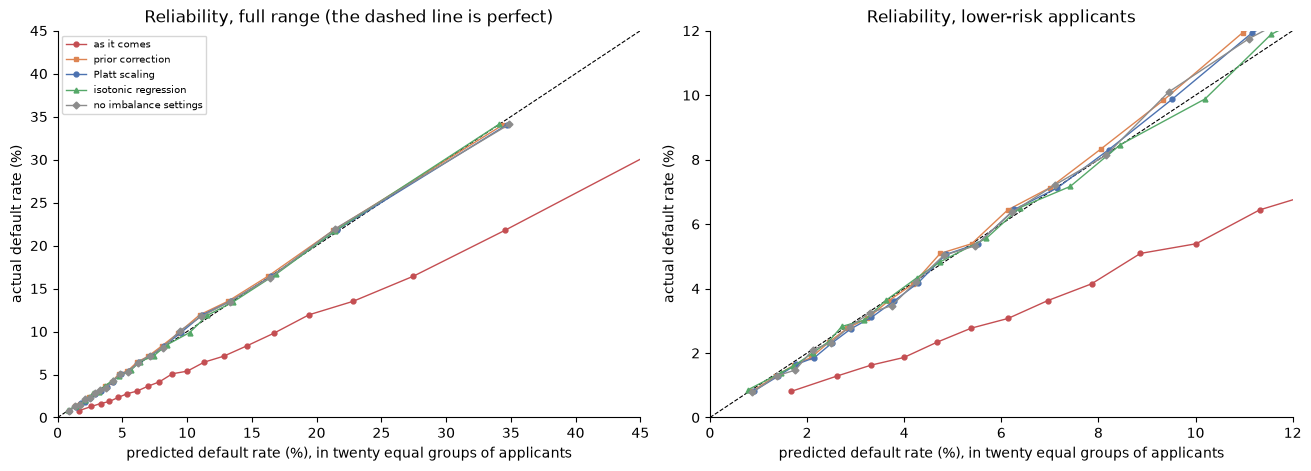

In [80]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), layout='constrained')
styles = {'as it comes': ('#C44E52', 'o'), 'prior correction': ('#DD8452', 's'), 'Platt scaling': ('#4C72B0', 'o'), 'isotonic regression': ('#55A868', '^'),
          'no imbalance settings': ('#8C8C8C', 'D')}
preds = {'as it comes': raw_pred, **{m: results[f'final model, {m}']['oof'] for m in methods}}
for ax, limit in zip(axes, [45, 12]):
    ax.plot([0, limit], [0, limit], color='black', linewidth=0.8, linestyle='--')
    for name, p in preds.items():
        r = reliability(y_dev, p)
        ax.plot(r['predicted_pct'], r['actual_pct'], marker=styles[name][1], markersize=3.5, linewidth=1, color=styles[name][0], label=name)
    ax.set_xlim(0, limit); ax.set_ylim(0, limit)
    ax.set_xlabel('predicted default rate (%), in twenty equal groups of applicants')
    ax.set_ylabel('actual default rate (%)')
axes[0].set_title('Reliability, full range (the dashed line is perfect)')
axes[1].set_title('Reliability, lower-risk applicants')
axes[0].legend(fontsize=7)
sns.despine()
plt.show()

### 9.4 Is it calibrated for different kinds of applicant?

Being right on average is not enough. A model can predict 8.07% overall while overstating risk for one group and understating it for another. The table compares predicted and actual default rates within groups, for the model as it comes and after each correction. A positive gap means the model overstates risk for that group.

In [81]:
age = (-X_dev['DAYS_BIRTH'] / 365.25)
segments = {
    'loan type': X_dev['NAME_CONTRACT_TYPE'],
    'gender': X_dev['CODE_GENDER'].fillna('(missing)'),
    'age': pd.cut(age, [0, 30, 40, 50, 60, 100], labels=['under 30', '30 to 40', '40 to 50', '50 to 60', 'over 60']).astype(str),
    'external scores missing': X_dev['EXT_N_MISSING'].astype(int).astype(str),
    'has an employer': np.where(X_dev['DAYS_EMPLOYED'].isna(), 'no', 'yes'),
    'education': X_dev['EDUCATION_LEVEL'].map({0: 'lower secondary', 1: 'secondary', 2: 'incomplete higher', 3: 'higher', 4: 'academic degree'}),
}
rows = []
for segment, values in segments.items():
    values = pd.Series(np.asarray(values), index=X_dev.index)
    for level, idx in values.groupby(values).groups.items():
        mask = X_dev.index.isin(idx)
        if mask.sum() < 500:
            continue
        row = {'segment': segment, 'group': level, 'rows': int(mask.sum()), 'actual_pct': y_dev.values[mask].mean() * 100}
        for name in ['as it comes', 'prior correction', 'Platt scaling', 'isotonic regression']:
            row[f'gap: {name}'] = preds[name][mask].mean() * 100 - row['actual_pct']
        rows.append(row)
by_segment = pd.DataFrame(rows).set_index(['segment', 'group'])
gap_cols = [c for c in by_segment.columns if c.startswith('gap')]
print('largest absolute gap in any group, percentage points:')
print(by_segment[gap_cols].abs().max().round(2).to_string())
print('\naverage absolute gap across groups, weighted by rows:')
print((by_segment[gap_cols].abs().multiply(by_segment['rows'], axis=0).sum() / by_segment['rows'].sum()).round(3).to_string())
by_segment.round(2)

largest absolute gap in any group, percentage points:
gap: as it comes            7.41
gap: prior correction       0.45
gap: Platt scaling          0.29
gap: isotonic regression    0.27

average absolute gap across groups, weighted by rows:
gap: as it comes            5.490
gap: prior correction       0.117
gap: Platt scaling          0.025
gap: isotonic regression    0.027


rows  actual_pct  \
segment                 group                                   
loan type               Cash loans         222560        8.34   
                        Revolving loans     23448        5.49   
gender                  F                  161887        7.00   
                        M                   84119       10.14   
age                     30 to 40            65858        9.59   
                        40 to 50            61282        7.66   
                        50 to 60            54489        6.06   
                        over 60             28098        4.91   
                        under 30            36281       11.48   
external scores missing 0                   87631        7.32   
                        1                  128962        8.16   
                        2                   29276        9.94   
has an employer         no                  44143        5.37   
                        yes                201865        8.66   
education               higher              59802        5.39   
                        incomplete higher    8289        8.63   
                        lower secondary      3025       11.07   
                        secondary          174768        8.92   

                                           gap: as it comes  \
segment                 group                                 
loan type               Cash loans                     5.62   
                        Revolving loans                4.27   
gender                  F                              4.95   
                        M                              6.52   
age                     30 to 40                       6.20   
                        40 to 50                       5.23   
                        50 to 60                       4.51   
                        over 60                        3.81   
                        under 30                       7.41   
external scores missing 0                              5.05   
                        1                              5.53   
                        2                              6.62   
has an employer         no                             4.12   
                        yes                            5.79   
education               higher                         4.02   
                        incomplete higher              5.77   
                        lower secondary                6.57   
                        secondary                      5.96   

                                           gap: prior correction  \
segment                 group                                      
loan type               Cash loans                         -0.13   
                        Revolving loans                    -0.00   
gender                  F                                  -0.08   
                        M                                  -0.18   
age                     30 to 40                           -0.17   
                        40 to 50                           -0.14   
                        50 to 60                           -0.06   
                        over 60                            -0.08   
                        under 30                           -0.10   
external scores missing 0                                  -0.11   
                        1                                  -0.12   
                        2                                  -0.12   
has an employer         no                                 -0.08   
                        yes                                -0.13   
education               higher                             -0.07   
                        incomplete higher                  -0.23   
                        lower secondary                    -0.45   
                        secondary                          -0.13   

                                           gap: Platt scaling  \
segment                 group                            

### 9.5 The shortcut: calibrating on the rows being scored

For comparison, the calibrator is fitted directly on the validation-fold predictions and then scored on those same predictions. This skips the nesting. The main model's predictions are the same in both columns. Only how the calibrator was fitted differs.

In [82]:
shortcut = {}
for method in ['Platt scaling', 'isotonic regression']:
    if method == 'Platt scaling':
        fitted_here = LogisticRegression(C=1e6, max_iter=1000).fit(logit(raw_pred).reshape(-1, 1), y_dev).predict_proba(logit(raw_pred).reshape(-1, 1))[:, 1]
    else:
        fitted_here = IsotonicRegression(y_min=0.0, y_max=1.0, out_of_bounds='clip').fit(raw_pred, y_dev).predict(raw_pred)
    proper, wrong = calibration_report(y_dev, results[f'final model, {method}']['oof']), calibration_report(y_dev, fitted_here)
    shortcut[method] = {'log_loss_nested': proper['log_loss'], 'log_loss_shortcut': wrong['log_loss'], 'flattered_by': proper['log_loss'] - wrong['log_loss'],
                        'calibration_error_nested_pts': proper['expected_calibration_error_pts'],
                        'calibration_error_shortcut_pts': wrong['expected_calibration_error_pts'],
                        'roc_auc_nested': proper['roc_auc'], 'roc_auc_shortcut': wrong['roc_auc']}
pd.DataFrame(shortcut).T.round(5)

,log_loss_nested,log_loss_shortcut,flattered_by,calibration_error_nested_pts,calibration_error_shortcut_pts,roc_auc_nested,roc_auc_shortcut
Platt scaling,0.24318,0.24318,0.00001,0.21962,0.21441,0.76851,0.76851
isotonic regression,0.24348,0.24282,0.00065,0.13456,0.00000,0.76813,0.76903


### 9.6 Choosing the method

**The rule, set before the comparison:** take the method with the lowest log loss on the validation folds. If another method is within 0.0002 of it, prefer the simpler one, in the order prior correction, Platt scaling, isotonic regression. Retraining without the imbalance settings is considered only if it loses no more than 0.0003 of AUC, since stage 7 chose those settings for ranking.

**The rule's choice was then overridden.** The rule compares log loss only, and log loss cannot separate prior correction from Platt scaling (0.24319 against 0.24318). On the average prediction they do differ: prior correction is below the true default rate in every fold and in every applicant group checked in section 9.4. Platt scaling is carried forward. The cell records both the rule's choice and the override.

In [83]:
order = ['prior correction', 'Platt scaling', 'isotonic regression']
best_loss = calibrated.loc[order, 'log_loss'].min()
CALIBRATION = next(m for m in order if calibrated.loc[m, 'log_loss'] <= best_loss + 0.0002)
alternative_ok = bool(versus_raw['no imbalance settings']['mean_difference'] >= -0.0003)
print(f"lowest log loss among the corrections: {best_loss:.5f} ({calibrated.loc[order, 'log_loss'].idxmin()})")
print(f"simplest method within 0.0002 of it: {CALIBRATION}")
print(f"retraining without imbalance settings: AUC change {versus_raw['no imbalance settings']['mean_difference']:+.5f}, "
      f"worse in {N_SPLITS - versus_raw['no imbalance settings']['folds_better']} of {N_SPLITS} folds -> {'eligible' if alternative_ok else 'not eligible, it costs ranking accuracy'}")

# Override, decided after reviewing sections 9.3 and 9.4: the rule looks at log loss only, which is identical for the two leading methods.
# Prior correction under-predicts the default rate in all five folds and all 18 groups. Platt scaling does not.
RULE_CHOICE = CALIBRATION
CALIBRATION = 'Platt scaling'
print(f"rule's choice: {RULE_CHOICE}    carried forward after review: {CALIBRATION}")

METHOD_KEY = {'prior correction': 'prior', 'Platt scaling': 'platt', 'isotonic regression': 'isotonic'}[CALIBRATION]

def final_pipeline():
    # the complete model: encode text columns, keep the final features, tuned LightGBM, calibration
    return with_columns(FINAL_FEATURES, CalibratedModel(FINAL(), method=METHOD_KEY, odds_multiplier=ODDS_MULTIPLIER_FINAL))

FINAL_CALIBRATED = f'final model, {CALIBRATION}'
final_pred = results[FINAL_CALIBRATED]['oof']
print(f"\nmodel carried forward: {FINAL_CALIBRATED}")
print(pd.Series(calibration_report(y_dev, final_pred)).round(5).to_string())

# how steady is the correction from fold to fold? A Platt curve fitted to each validation fold of the uncorrected model.
per_fold = []
for k in range(N_SPLITS):
    m = dev_fold == k
    line = LogisticRegression(C=1e6, max_iter=1000).fit(logit(raw_pred[m]).reshape(-1, 1), y_dev[m])
    per_fold.append({'fold': k, 'slope': line.coef_[0, 0], 'intercept': line.intercept_[0],
                     'mean_prediction_after_pct': final_pred[m].mean() * 100, 'actual_pct': y_dev[m].mean() * 100})
print('\nthe uncorrected model, fold by fold (slope and intercept of the curve that would correct it):')
print(pd.DataFrame(per_fold).set_index('fold').round(4).to_string())
print(holdout)
assert holdout.log == []

lowest log loss among the corrections: 0.24318 (Platt scaling)
simplest method within 0.0002 of it: prior correction
retraining without imbalance settings: AUC change -0.00020, worse in 3 of 5 folds -> eligible
rule's choice: prior correction    carried forward after review: Platt scaling

model carried forward: final model, Platt scaling


roc_auc                           0.76851
log_loss                          0.24318
brier                             0.06728
mean_predicted_pct                8.09120
expected_calibration_error_pts    0.21962
largest_gap_pts                   0.77043
slope                             1.01336
intercept                         0.02481



the uncorrected model, fold by fold (slope and intercept of the curve that would correct it):
       slope  intercept  mean_prediction_after_pct  actual_pct
fold                                                          
0     0.9948    -0.6618                     8.1026      8.0728
1     0.9983    -0.6629                     8.1441      8.0728
2     1.0122    -0.6435                     8.1446      8.0728
3     1.0140    -0.6160                     7.9811      8.0730
4     1.0181    -0.6260                     8.0836      8.0730
HoldoutVault(61,503 rows, 4,965 defaults, opened 0 times)


### Stage 9 findings

**How miscalibrated the tuned model is**
- It predicts an average default rate of 13.56% against a true 8.07%. In the riskiest tenth it predicts 42.3% where 27.9% default.
- Its log loss is 0.2598. That is worse than the untuned LightGBM (0.2454), CatBoost (0.2445) and the binned logistic regression (0.2470), all of which it beats on ranking.
- The distortion is a plain shift. The curve that would correct it has a slope of 1.007 and an intercept of -0.64. A slope of 1 means the scores are in the right order and correctly spread, and only their level is wrong.
- The level is off by the amount the model's settings predict, roughly. Sampling 62% of repaid loans and weighting defaults 1.2 times multiplies the odds by 1.95. The observed ratio is 1.79.

**All four approaches fix it**

| Method | ROC AUC | Log loss | Average prediction | Calibration error | Largest gap in any twentieth |
|---|---:|---:|---:|---:|---:|
| As it comes | 0.7685 | 0.25984 | 13.56% | 5.49 pts | 16.0 pts |
| Prior correction | 0.7685 | 0.24319 | 7.96% | 0.24 pts | 0.97 pts |
| Platt scaling | 0.7685 | 0.24318 | 8.09% | 0.22 pts | 0.77 pts |
| Isotonic regression | 0.7681 | 0.24348 | 8.10% | 0.13 pts | 0.33 pts |
| No imbalance settings, retrained | 0.7683 | 0.24320 | 8.05% | 0.23 pts | 0.77 pts |

- Log loss falls from 0.2598 to about 0.2432. The corrected model now has the best log loss in the notebook as well as the best ranking.
- Prior correction and Platt scaling leave AUC exactly as it was, in every fold. They move the scores without reordering them.
- Isotonic regression has the smallest calibration error and the worst log loss of the four. It replaces 246,000 distinct scores with 552 steps. The ties cost 0.0002 of AUC in every fold, and the step edges cost log loss.
- Retraining without the two imbalance settings gives a model that is calibrated as it comes, for 0.0002 of AUC (worse in 3 of 5 folds).

**The corrected model is also right within groups**
- Before correction it overstated risk for every group, by between 3.8 and 7.4 points.
- After Platt scaling the largest gap in any of 18 groups is 0.29 points, and the row-weighted average gap is 0.03 points.
- After prior correction the largest gap is 0.45 points and the average is 0.12. Every one of the 18 groups is under-predicted.
- The largest gap under every method is for applicants with lower secondary education, the smallest group tested (3,025 rows).

**The shortcut flatters the flexible method**
- Fitting the calibrator on the rows it is scored on makes isotonic regression look perfect: a calibration error of exactly zero and an AUC that appears to rise to 0.7690. Nested properly, its log loss is 0.0007 worse and its AUC falls.
- Platt scaling is hardly affected (0.00001). Two parameters cannot memorise 246,000 rows. A step function with hundreds of steps can.
- So the size of this leak depends on how flexible the calibrator is. The nested procedure costs four extra model fits per fold and removes the question.

**What the rule chose, and its weakness**
- The rule, set before the results: take the lowest log loss, and prefer a simpler method if it is within 0.0002. Platt scaling was lowest at 0.24318. Prior correction was within 0.00001 of it and is simpler, so the rule chose **prior correction**.
- The rule looked only at log loss, and log loss cannot separate these two. On the average prediction they differ. Prior correction gives 7.96% against a true 8.07%, and it is below the true rate in all five folds and all 18 groups.
- The shortfall is 0.11 points, about 2 standard errors of the default rate, so it is probably real and not chance. It follows from the formula over-correcting: it assumes the odds were multiplied by 1.95 when the observed figure is 1.79.
- In money terms, a lender using the prior-corrected model would understate expected defaults by about 1.4%.
- Platt scaling fits the level from the data and lands on 8.09%. It needs the nested procedure and two fitted numbers, where prior correction needs neither.
- This is a case where the rule was too narrow. Its choice was set aside and Platt scaling is carried forward. Section 9.6 records both the rule's choice and the override.

**Limits**
- Calibration is tied to the default rate of the data it was fitted on. Train and test are different populations (stages 10 and 12 of the EDA), and the test default rate is unknown. A model calibrated here to 8.07% may be off on test by however much the true rates differ. This does not affect the competition score, which depends on ranking only.
- The per-group check covers six ways of grouping applicants. A model can be well calibrated on all of them and still be off for some narrower group.
- The calibration error figures use twenty equal groups of applicants. A different number of groups would give somewhat different numbers, and that was not explored.
- The fold-by-fold slopes in section 9.6 range from 0.995 to 1.018, so the correction needed is steady across folds. That was measured on the validation folds as a diagnostic and was not used to fit anything.

**Verification**
- The notebook was run again after one display fix. Nothing was refitted: the cache stayed at 192 files.
- All 83 code cells ran in order with no errors and no warnings.
- Every score matches the run that fitted this stage, and stages 1 to 8 match the notebook signed off at stage 8. The cells that differ do so only in recorded fitting times.
- The display fix: the results table first reported the two rank-preserving methods as "worse in 5 of 5 folds" on AUC, because it counted folds that were not strictly better. Their AUC is unchanged in every fold, and the table now says 0.

**Decisions**
- The tuned model is calibrated before it is used for anything that reads its output as a probability. Stage 10 chooses a threshold on the calibrated probabilities.
- The model carried forward is the tuned LightGBM on 36 features with Platt scaling: ROC AUC 0.7685, log loss 0.2432, average prediction 8.09%. The rule chose prior correction. That was overridden after review, because prior correction under-predicts in every fold and every group.
- `final_pipeline()` in section 9.6 builds the complete model: encode the text columns, keep the 36 features, fit the tuned LightGBM, apply the calibration. Later stages use it.
- Isotonic regression is ruled out. It costs ranking accuracy and is the method most exposed to overfitting.
- Prior correction remains a sound fallback where a fitted calibrator is not wanted. It needs no data and lands within 0.11 points of the true rate.
- The holdout is still unopened.

## Stage 10: Decision threshold

Where should the approve or decline line sit, and what does each choice cost?

The model outputs a probability. A lending decision needs a rule: decline when the predicted probability of default is above some threshold, approve otherwise. Every threshold trades two mistakes against each other:

| Mistake | What happens | Who bears it |
|---|---|---|
| A defaulter is approved | The lender loses part of the loan | The lender |
| A good applicant is declined | The lender loses the profit on that loan, and the applicant is refused credit they would have repaid | Both |

Lowering the threshold catches more defaulters and turns away more good applicants. There is no threshold that is best in itself. It depends on how much worse one mistake is than the other, and that is a business judgement this dataset cannot supply. So this stage does three things: it shows the whole trade-off, it shows what threshold follows from any stated view of the costs, and it fixes a small set of thresholds to carry into the holdout evaluation.

All figures use the calibrated out-of-fold predictions from stage 9. Every prediction was made by a model and a calibrator that had not seen that applicant.

**Leakage.** A threshold picked by searching for the best value on some data is another fitted number, and scoring it on the same data flatters it. Section 10.4 shows that with calibrated probabilities the threshold does not need to be searched for at all: it follows from the cost ratio by a formula. A threshold that is not fitted cannot leak.

### 10.1 The whole trade-off

In [84]:
from sklearn.metrics import roc_curve, precision_recall_curve

p_cal = results[FINAL_CALIBRATED]['oof']          # calibrated, out of fold
y_arr = y_dev.values
n_all, n_bad = len(y_arr), int(y_arr.sum())
print(f"model: {FINAL_CALIBRATED}")
print(f"{n_all:,} applicants, {n_bad:,} defaults ({n_bad / n_all:.2%}); average predicted probability {p_cal.mean():.2%}")

def at_threshold(p, t, y=y_arr):
    declined = p >= t
    bad = y == 1
    caught, missed = int((declined & bad).sum()), int((~declined & bad).sum())
    wrongly_declined, approved = int((declined & ~bad).sum()), int((~declined).sum())
    return {'threshold': t, 'declined_pct': declined.mean() * 100, 'approved_pct': (~declined).mean() * 100,
            'defaults_caught_pct': caught / max(bad.sum(), 1) * 100,
            'default_rate_among_declined_pct': caught / max(declined.sum(), 1) * 100,
            'default_rate_among_approved_pct': missed / max(approved, 1) * 100,
            'good_applicants_declined_pct': wrongly_declined / max((~bad).sum(), 1) * 100,
            'declined_per_default_caught': declined.sum() / max(caught, 1)}

grid = [0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.10, 0.12, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]
tradeoff = pd.DataFrame([at_threshold(p_cal, t) for t in grid]).set_index('threshold')
tradeoff.round(2)

model: final model, Platt scaling
246,008 applicants, 19,860 defaults (8.07%); average predicted probability 8.09%


,declined_pct,approved_pct,defaults_caught_pct,default_rate_among_declined_pct,default_rate_among_approved_pct,good_applicants_declined_pct,declined_per_default_caught
threshold,,,,,,,
0.02,84.49,15.51,97.59,9.33,1.25,83.34,10.72
0.03,71.35,28.65,93.87,10.62,1.73,69.37,9.42
0.04,60.24,39.76,89.35,11.97,2.16,57.68,8.35
0.05,51.36,48.64,84.53,13.29,2.57,48.44,7.53
0.06,44.20,55.80,79.62,14.54,2.95,41.09,6.88
0.07,38.26,61.74,74.72,15.76,3.31,35.06,6.34
0.08,33.36,66.64,70.34,17.02,3.59,30.11,5.87
0.09,29.32,70.68,65.81,18.12,3.91,26.12,5.52
0.10,25.84,74.16,61.57,19.23,4.18,22.71,5.20


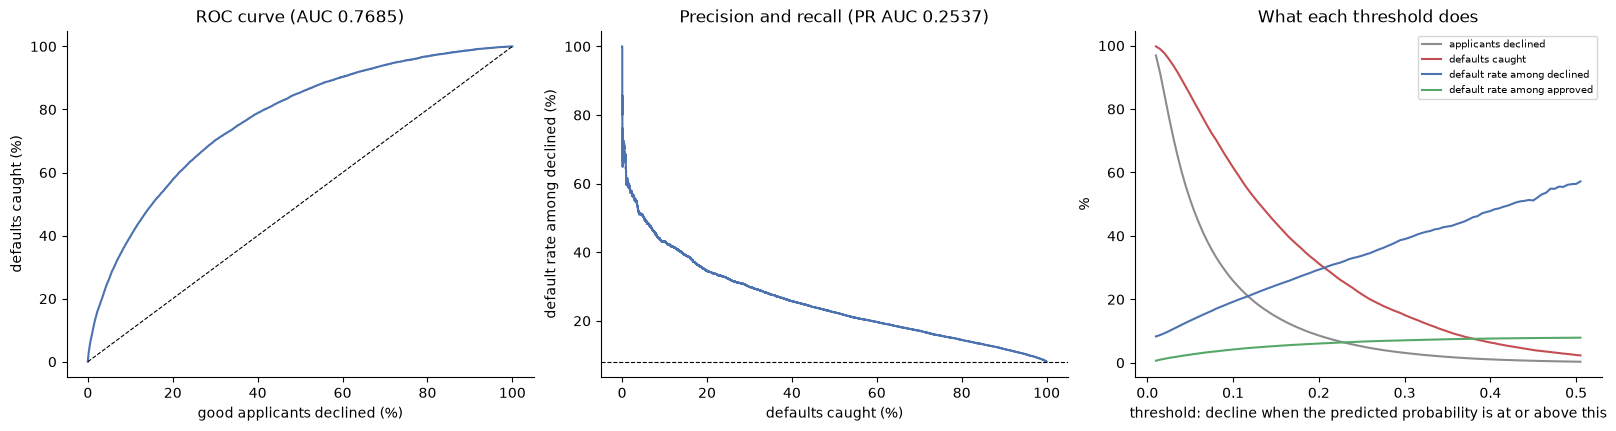

In [85]:
fpr, tpr, roc_t = roc_curve(y_arr, p_cal)
precision, recall, pr_t = precision_recall_curve(y_arr, p_cal)
ks_index = int(np.argmax(tpr - fpr))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), layout='constrained')
axes[0].plot(fpr * 100, tpr * 100, color='#4C72B0')
axes[0].plot([0, 100], [0, 100], color='black', linewidth=0.8, linestyle='--')
axes[0].set_xlabel('good applicants declined (%)'); axes[0].set_ylabel('defaults caught (%)')
axes[0].set_title(f"ROC curve (AUC {roc_auc_score(y_arr, p_cal):.4f})")

axes[1].plot(recall * 100, precision * 100, color='#4C72B0')
axes[1].axhline(n_bad / n_all * 100, color='black', linewidth=0.8, linestyle='--')
axes[1].set_xlabel('defaults caught (%)'); axes[1].set_ylabel('default rate among declined (%)')
axes[1].set_title(f"Precision and recall (PR AUC {average_precision_score(y_arr, p_cal):.4f})")

fine = np.arange(0.01, 0.51, 0.005)
curve_t = pd.DataFrame([at_threshold(p_cal, t) for t in fine]).set_index('threshold')
for column, color, label in [('declined_pct', '#8C8C8C', 'applicants declined'), ('defaults_caught_pct', '#C44E52', 'defaults caught'),
                             ('default_rate_among_declined_pct', '#4C72B0', 'default rate among declined'),
                             ('default_rate_among_approved_pct', '#55A868', 'default rate among approved')]:
    axes[2].plot(curve_t.index, curve_t[column], color=color, label=label)
axes[2].set_xlabel('threshold: decline when the predicted probability is at or above this'); axes[2].set_ylabel('%')
axes[2].set_title('What each threshold does')
axes[2].legend(fontsize=7)
sns.despine()
plt.show()

### 10.2 Conventional operating points

Thresholds that are commonly quoted, none of which involves a view on costs. They are shown for reference.

- **0.5**, the default cut-off in most software.
- **The default rate itself** (0.0807): decline anyone the model rates as riskier than average.
- **Maximum F1**: the best balance of precision and recall, treating them as equally important.
- **Maximum KS**: the point where the model best separates defaulters from non-defaulters. The KS statistic is the standard summary of a credit model's separating power.
- **Fixed approval rates**: a lender often starts from how much business it wants to write.

In [86]:
f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
conventional = pd.DataFrame({
    'software default (0.5)': at_threshold(p_cal, 0.5),
    'the default rate (0.0807)': at_threshold(p_cal, n_bad / n_all),
    'maximum F1': at_threshold(p_cal, float(pr_t[int(np.argmax(f1))])),
    'maximum KS': at_threshold(p_cal, float(roc_t[ks_index])),
}).T
print(f"KS statistic: {(tpr - fpr).max():.4f}   (defaults caught {tpr[ks_index] * 100:.1f}% minus good applicants declined {fpr[ks_index] * 100:.1f}%)")
print(f"maximum F1: {f1.max():.4f}")
print(conventional.round(3).to_string())

by_approval = pd.DataFrame({f"approve {rate}%": at_threshold(p_cal, float(np.quantile(p_cal, rate / 100))) for rate in [95, 90, 85, 80, 70, 60, 50]}).T
by_approval['defaults_avoided_per_1000_declined'] = by_approval['default_rate_among_declined_pct'] * 10
print('\nfixed approval rates (portfolio default rate with no model: 8.07%)')
by_approval[['threshold', 'approved_pct', 'default_rate_among_approved_pct', 'defaults_caught_pct', 'default_rate_among_declined_pct', 'good_applicants_declined_pct']].round(3)

KS statistic: 0.4026   (defaults caught 70.2% minus good applicants declined 30.0%)
maximum F1: 0.3146
                           threshold  declined_pct  approved_pct  defaults_caught_pct  default_rate_among_declined_pct  default_rate_among_approved_pct  good_applicants_declined_pct  declined_per_default_caught
software default (0.5)         0.500         0.349        99.651                2.437                           56.410                            7.904                         0.165                        1.773
the default rate (0.0807)      0.081        33.040        66.960               70.005                           17.105                            3.616                        29.793                        5.846
maximum F1                     0.152        14.205        85.795               43.409                           24.669                            5.325                        11.641                        4.054
maximum KS                     0.080        33.225   

,threshold,approved_pct,default_rate_among_approved_pct,defaults_caught_pct,default_rate_among_declined_pct,good_applicants_declined_pct
approve 95%,0.253,95.0,6.706,21.083,34.038,3.588
approve 90%,0.185,90.0,5.868,34.577,27.913,7.842
approve 85%,0.147,85.0,5.249,44.738,24.077,12.389
approve 80%,0.121,80.0,4.731,53.117,21.440,17.092
approve 70%,0.088,70.0,3.849,66.626,17.929,26.784
approve 60%,0.067,60.0,3.204,76.183,15.376,36.822
approve 50%,0.052,50.0,2.661,83.520,13.485,47.056


### 10.3 A threshold from a view on costs

Suppose approving a defaulter costs *r* times as much as declining a good applicant. For example, if a default loses half the loan and a good loan earns a margin of 5%, then *r* is 10.

With that single number, the cost of any threshold can be counted: *r* for each defaulter approved, 1 for each good applicant declined. And if the model's probabilities are right, the best threshold needs no search. Declining an applicant with default probability *p* avoids an expected cost of *r × p* and gives up an expected gain of *1 − p*. Declining is worth it when *r × p* is larger, which is when

**p is above 1 / (1 + r)**

The cell below tests that. For each cost ratio it compares the threshold from the formula with the threshold found by searching for the lowest cost. If the probabilities are well calibrated, the two agree. The cost ratio is an assumption, not something measured here, so several are shown.

In [87]:
def cost_per_1000(p, t, r, y=y_arr):
    declined = p >= t
    return (r * ((~declined) & (y == 1)).sum() + (declined & (y == 0)).sum()) / len(y) * 1000

search_grid = np.arange(0.005, 0.60, 0.001)
def searched_threshold(p, r, y=y_arr):
    costs = [cost_per_1000(p, t, r, y) for t in search_grid]
    return float(search_grid[int(np.argmin(costs))]), float(np.min(costs))

rows = {}
for r in [2, 3, 5, 10, 15, 20, 30]:
    formula = 1 / (1 + r)
    found, found_cost = searched_threshold(p_cal, r)
    point = at_threshold(p_cal, formula)
    rows[r] = {'threshold_from_formula': formula, 'threshold_from_search': found,
               'cost_at_formula': cost_per_1000(p_cal, formula, r), 'cost_at_search': found_cost,
               'cost_approve_everyone': r * n_bad / n_all * 1000, 'cost_decline_everyone': (n_all - n_bad) / n_all * 1000,
               'cost_at_0.5': cost_per_1000(p_cal, 0.5, r),
               'approved_pct': point['approved_pct'], 'defaults_caught_pct': point['defaults_caught_pct']}
costs = pd.DataFrame(rows).T
costs.index.name = 'cost_ratio_r'
costs['saving_vs_best_no_model_pct'] = (1 - costs['cost_at_formula'] / costs[['cost_approve_everyone', 'cost_decline_everyone']].min(axis=1)) * 100
costs['formula_cost_above_search_pct'] = (costs['cost_at_formula'] / costs['cost_at_search'] - 1) * 100
print('costs are per 1,000 applicants, in units of one wrongly declined good applicant')
costs.round({'threshold_from_formula': 4, 'threshold_from_search': 3, 'cost_at_formula': 1, 'cost_at_search': 1, 'cost_approve_everyone': 1,
             'cost_decline_everyone': 1, 'cost_at_0.5': 1, 'approved_pct': 1, 'defaults_caught_pct': 1, 'saving_vs_best_no_model_pct': 1,
             'formula_cost_above_search_pct': 2})

costs are per 1,000 applicants, in units of one wrongly declined good applicant


,threshold_from_formula,threshold_from_search,cost_at_formula,cost_at_search,cost_approve_everyone,cost_decline_everyone,cost_at_0.5,approved_pct,defaults_caught_pct,saving_vs_best_no_model_pct,formula_cost_above_search_pct
cost_ratio_r,,,,,,,,,,,
2,0.3333,0.326,155.8,155.6,161.5,919.3,159.0,97.8,11.5,3.5,0.11
3,0.2500,0.236,224.1,223.6,242.2,919.3,237.8,94.8,21.6,7.5,0.22
5,0.1667,0.162,335.3,335.1,403.6,919.3,395.3,87.8,39.2,16.9,0.07
10,0.0909,0.085,516.2,515.3,807.3,919.3,789.1,71.0,65.4,36.1,0.18
15,0.0625,0.063,623.2,623.3,1210.9,919.3,1182.9,57.4,78.5,32.2,-0.03
20,0.0476,0.050,695.6,695.1,1614.6,919.3,1576.8,46.8,85.6,24.3,0.08
30,0.0323,0.034,784.0,781.9,2421.9,919.3,2364.4,31.4,92.9,14.7,0.27


### 10.4 Why calibration came first, and whether a searched threshold leaks

Two checks.

**The formula on uncalibrated scores.** The same thresholds are applied to the model's scores as they were before stage 9, to show what the formula does when the probabilities are wrong.

**Searching for the threshold.** The alternative to the formula is to search for the lowest-cost threshold on the data. Done honestly, the search is run on four folds and the threshold applied to the fifth. Done carelessly, it is run and scored on the same rows. Both are compared with the formula.

In [88]:
raw_scores = results[FINAL_NAME]['oof']          # the same model before calibration
rows = {}
for r in [5, 10, 20]:
    formula = 1 / (1 + r)
    honest_cost = 0.0
    fold_thresholds = []
    for k in range(N_SPLITS):
        other, this = dev_fold != k, dev_fold == k
        t_k, _ = searched_threshold(p_cal[other], r, y_arr[other])      # searched without fold k
        fold_thresholds.append(t_k)
        declined = p_cal[this] >= t_k
        honest_cost += r * ((~declined) & (y_arr[this] == 1)).sum() + (declined & (y_arr[this] == 0)).sum()
    honest_cost = honest_cost / n_all * 1000
    _, careless_cost = searched_threshold(p_cal, r)
    rows[r] = {'formula_threshold': formula, 'cost_formula_calibrated': cost_per_1000(p_cal, formula, r),
               'cost_formula_uncalibrated': cost_per_1000(raw_scores, formula, r),
               'approved_pct_calibrated': at_threshold(p_cal, formula)['approved_pct'],
               'approved_pct_uncalibrated': at_threshold(raw_scores, formula)['approved_pct'],
               'cost_searched_on_other_folds': honest_cost, 'cost_searched_on_same_rows': careless_cost,
               'searched_thresholds_by_fold': ', '.join(f"{t:.3f}" for t in fold_thresholds)}
check = pd.DataFrame(rows).T
check.index.name = 'cost_ratio_r'
check['extra_cost_without_calibration_pct'] = (check['cost_formula_uncalibrated'].astype(float) / check['cost_formula_calibrated'].astype(float) - 1) * 100
check['search_flattered_by_pct'] = (check['cost_searched_on_other_folds'].astype(float) / check['cost_searched_on_same_rows'].astype(float) - 1) * 100
check['formula_vs_honest_search_pct'] = (check['cost_formula_calibrated'].astype(float) / check['cost_searched_on_other_folds'].astype(float) - 1) * 100
with pd.option_context('display.max_colwidth', 60):
    display(check.infer_objects().round(3))

,formula_threshold,cost_formula_calibrated,cost_formula_uncalibrated,approved_pct_calibrated,approved_pct_uncalibrated,cost_searched_on_other_folds,cost_searched_on_same_rows,searched_thresholds_by_fold,extra_cost_without_calibration_pct,search_flattered_by_pct,formula_vs_honest_search_pct
cost_ratio_r,,,,,,,,,,,
5,0.167,335.322,370.842,87.826,72.384,335.957,335.074,"0.168, 0.162, 0.160, 0.157, 0.175",10.593,0.263,-0.189
10,0.091,516.227,570.490,71.018,48.543,517.304,515.321,"0.092, 0.085, 0.085, 0.088, 0.088",10.511,0.385,-0.208
20,0.048,695.640,761.813,46.760,23.155,696.957,695.079,"0.050, 0.049, 0.047, 0.051, 0.047",9.512,0.270,-0.189


### 10.5 The thresholds carried forward

A cost ratio of 10 is taken as the reference: a missed default costs ten times a wrongly declined good applicant. That corresponds, for example, to losing half of a loan on default against a 5% margin on a good one. It is an assumption made for illustration. Ratios of 5 and 20 are carried alongside it to show how the decision moves if the true ratio is half or double that.

These three thresholds come from the formula, so they are fixed now, before the holdout is opened. Stage 11 reports the holdout at exactly these values.

In [89]:
REFERENCE_COST_RATIO = 10
OPERATING_POINTS = {r: 1 / (1 + r) for r in [5, 10, 20]}
THRESHOLD = OPERATING_POINTS[REFERENCE_COST_RATIO]

chosen = pd.DataFrame({f"r = {r}{' (reference)' if r == REFERENCE_COST_RATIO else ''}": at_threshold(p_cal, t) for r, t in OPERATING_POINTS.items()}).T
print(chosen.round(3).to_string())

declined = p_cal >= THRESHOLD
confusion = pd.DataFrame({'approved': [int((~declined & (y_arr == 0)).sum()), int((~declined & (y_arr == 1)).sum())],
                          'declined': [int((declined & (y_arr == 0)).sum()), int((declined & (y_arr == 1)).sum())]},
                         index=['repaid', 'defaulted'])
print(f"\nat the reference threshold of {THRESHOLD:.4f}:")
print(confusion.to_string())

# how steady is the reference point from fold to fold?
by_fold = pd.DataFrame([at_threshold(p_cal[dev_fold == k], THRESHOLD, y_arr[dev_fold == k]) for k in range(N_SPLITS)])
steady = by_fold[['approved_pct', 'defaults_caught_pct', 'default_rate_among_declined_pct', 'default_rate_among_approved_pct', 'good_applicants_declined_pct']]
print('\nreference threshold, by fold:')
print(pd.DataFrame({'mean': steady.mean(), 'std': steady.std(ddof=1), 'min': steady.min(), 'max': steady.max()}).round(3).to_string())

                    threshold  declined_pct  approved_pct  defaults_caught_pct  default_rate_among_declined_pct  default_rate_among_approved_pct  good_applicants_declined_pct  declined_per_default_caught
r = 5                   0.167        12.174        87.826               39.240                           26.020                            5.585                         9.798                        3.843
r = 10 (reference)      0.091        28.982        71.018               65.413                           18.221                            3.932                        25.782                        5.488
r = 20                  0.048        53.240        46.760               85.609                           12.981                            2.485                        50.398                        7.704

at the reference threshold of 0.0909:
           approved  declined
repaid       167842     58306
defaulted      6869     12991

reference threshold, by fold:
                        

### 10.6 Who gets declined

At the reference threshold, the share of applicants approved in each group, beside that group's actual default rate. The model uses gender and age as inputs, so it will treat groups differently where their default rates differ. The last column divides each group's approval rate by the highest in its category. A common screening rule in lending and employment flags a ratio under 0.8 for review.

In [90]:
group_rows = []
for segment, values in segments.items():
    values = pd.Series(np.asarray(values), index=X_dev.index)
    for level, idx in values.groupby(values).groups.items():
        mask = X_dev.index.isin(idx)
        if mask.sum() < 500:
            continue
        good = mask & (y_arr == 0)
        group_rows.append({'segment': segment, 'group': level, 'rows': int(mask.sum()), 'actual_default_pct': y_arr[mask].mean() * 100,
                           'approved_pct': (~declined[mask]).mean() * 100,
                           'good_applicants_approved_pct': (~declined[good]).mean() * 100,
                           'defaults_caught_pct': declined[mask & (y_arr == 1)].mean() * 100})
by_group = pd.DataFrame(group_rows).set_index(['segment', 'group'])
by_group['approval_ratio_to_highest'] = by_group['approved_pct'] / by_group.groupby(level='segment')['approved_pct'].transform('max')
print(f"overall: {(~declined).mean() * 100:.1f}% approved")
print(f"groups with an approval ratio under 0.8: {by_group.index[by_group['approval_ratio_to_highest'] < 0.8].tolist()}")
print(holdout)
assert holdout.log == []
by_group.round(2)

overall: 71.0% approved
groups with an approval ratio under 0.8: [('gender', 'M'), ('age', '30 to 40'), ('age', 'under 30'), ('has an employer', 'yes'), ('education', 'lower secondary'), ('education', 'secondary')]
HoldoutVault(61,503 rows, 4,965 defaults, opened 0 times)


rows  actual_default_pct  \
segment                 group                                           
loan type               Cash loans         222560                8.34   
                        Revolving loans     23448                5.49   
gender                  F                  161887                7.00   
                        M                   84119               10.14   
age                     30 to 40            65858                9.59   
                        40 to 50            61282                7.66   
                        50 to 60            54489                6.06   
                        over 60             28098                4.91   
                        under 30            36281               11.48   
external scores missing 0                   87631                7.32   
                        1                  128962                8.16   
                        2                   29276                9.94   
has an employer         no                  44143                5.37   
                        yes                201865                8.66   
education               higher              59802                5.39   
                        incomplete higher    8289                8.63   
                        lower secondary      3025               11.07   
                        secondary          174768                8.92   

                                           approved_pct  \
segment                 group                             
loan type               Cash loans                69.82   
                        Revolving loans           82.42   
gender                  F                         76.26   
                        M                         60.94   
age                     30 to 40                  63.91   
                        40 to 50                  73.09   
                        50 to 60                  81.01   
                        over 60                   87.33   
                        under 30                  52.78   
external scores missing 0                         74.51   
                        1                         70.92   
                        2                         61.02   
has an employer         no                        85.24   
                        yes                       67.91   
education               higher                    83.79   
                        incomplete higher         67.57   
                        lower secondary           58.48   
                        secondary                 67.02   

                                           good_applicants_approved_pct  \
segment                 group                                             
loan type               Cash loans                                73.13   
                        Revolving loans                           84.22   
gender                  F                                         78.95   
                        M                                         64.79   
age                     30 to 40                                  67.71   
                        40 to 50                                  76.14   
                        50 to 60                                  83.14   
                        over 60                                   88.52   
                        under 30                                  56.77   
external scores missing 0                                         77.43   
                        1                                         74.15   
                        2                                         64.63   
has an employer         no                                        86.76   
                        yes                                       71.38   
education               higher                                    85.68   
                        incomplete higher                         70.64   
                        lower secondary              

### Stage 10 findings

**The trade-off**

| Threshold | Approved | Defaults caught | Default rate among approved | Good applicants declined |
|---:|---:|---:|---:|---:|
| 0.50 | 99.7% | 2.4% | 7.90% | 0.2% |
| 0.20 | 91.4% | 31.3% | 6.07% | 6.6% |
| 0.15 | 85.4% | 44.1% | 5.29% | 12.0% |
| 0.10 | 74.2% | 61.6% | 4.18% | 22.7% |
| 0.08 | 66.6% | 70.3% | 3.59% | 30.1% |
| 0.05 | 48.6% | 84.5% | 2.57% | 48.4% |

- With no model, a lender approving everyone gets a portfolio default rate of 8.07%.
- The software default of 0.5 is useless here. It declines 0.35% of applicants and catches 2.4% of defaults.
- Catching defaults is expensive in good applicants turned away. At a threshold of 0.10, 5 applicants are declined for each default caught. At 0.05 it is 7.5.
- By approval rate: approving 90% of applicants brings the portfolio default rate from 8.07% to 5.87%. Approving 80% brings it to 4.73%, and 70% to 3.85%.
- The model's KS statistic is 0.403, at a threshold of 0.080: it catches 70.2% of defaults there while declining 30.0% of good applicants.

**A threshold from a view on costs**

| Cost ratio *r* | Threshold from the formula | Threshold found by search | Approved | Defaults caught | Saving against the best policy with no model |
|---:|---:|---:|---:|---:|---:|
| 2 | 0.333 | 0.326 | 97.8% | 11.5% | 3.5% |
| 5 | 0.167 | 0.162 | 87.8% | 39.2% | 16.9% |
| 10 | 0.091 | 0.085 | 71.0% | 65.4% | 36.1% |
| 20 | 0.048 | 0.050 | 46.8% | 85.6% | 24.3% |
| 30 | 0.032 | 0.034 | 31.4% | 92.9% | 14.7% |

- *r* is how many times worse it is to approve a defaulter than to decline a good applicant.
- The formula, decline when the probability is above 1 / (1 + *r*), gives nearly the same threshold as searching for the lowest cost, at every ratio tried. The cost at the formula's threshold is within 0.3% of the best the search found.
- That agreement is a second confirmation of stage 9. The formula only works if a predicted 9% means 9%.
- The model is worth most when the two mistakes are of comparable total weight. At a ratio of 10 it saves 36% of the cost of the best blanket policy. At a ratio of 2 almost everyone should be approved and the model saves 3.5%. At 30 almost everyone should be declined.
- Even at a ratio of 10, a threshold of 0.5 costs 789 per 1,000 applicants, against 807 for approving everyone and 516 at the formula's threshold. Using the model with the wrong threshold throws away nearly all of its value.

**Why calibration had to come first**
- Applying the same formula to the model's scores before calibration costs 9.5% to 10.6% more.
- At a ratio of 10, the uncalibrated scores would approve 48.5% of applicants where the calibrated ones approve 71.0%. The inflated probabilities make the model decline far too many people.
- Ranking is identical in the two cases. The whole difference comes from the numbers attached to the ranking.

**A searched threshold leaks a little, and the formula does not**
- Searching for the best threshold and scoring it on the same rows understates the cost by 0.26% to 0.39%, compared with searching on four folds and applying the result to the fifth.
- The thresholds found on different folds vary: between 0.085 and 0.092 at a ratio of 10. That variation is the noise the search introduces.
- The formula's threshold beats the honestly searched one by about 0.2% at all three ratios. It has no noise, because nothing is fitted.
- So the threshold carried forward is not learned from the data. It cannot leak, and it does not need a validation set of its own.

**The reference operating point**

At a cost ratio of 10, the threshold is 0.0909.

| | Approved | Declined |
|---|---:|---:|
| Repaid | 167,842 | 58,306 |
| Defaulted | 6,869 | 12,991 |

- 71.0% of applicants are approved. 65.4% of defaults are caught.
- The default rate among approved applicants is 3.93%, less than half the 8.07% of approving everyone. Among declined applicants it is 18.2%.
- The price is that 25.8% of applicants who would have repaid are declined.
- These figures are steady across the five folds. The approval rate ranges from 70.6% to 71.4% and the share of defaults caught from 64.5% to 66.2%.

**Who gets declined**

| Group | Actual default rate | Approved | Good applicants approved |
|---|---:|---:|---:|
| Women | 7.0% | 76.3% | 79.0% |
| Men | 10.1% | 60.9% | 64.8% |
| Under 30 | 11.5% | 52.8% | 56.8% |
| 30 to 40 | 9.6% | 63.9% | 67.7% |
| Over 60 | 4.9% | 87.3% | 88.5% |
| Higher education | 5.4% | 83.8% | 85.7% |
| Lower secondary education | 11.1% | 58.5% | 62.3% |

- The model approves groups in line with their default rates, as a calibrated model must. That produces large gaps in approval. Applicants under 30 are approved at 60% of the rate of those over 60. Men are approved at 80% of the rate of women.
- Six groups fall under a ratio of 0.8, the level a common screening rule flags for review: men, applicants under 30 and from 30 to 40, applicants with an employer, and those with lower secondary or secondary education.
- The gap holds among people who repaid. Of men who repaid, 64.8% were approved, against 79.0% of women who repaid.
- This is a description of what the model does, not a legal assessment. The model takes gender and age as inputs. Stage 8 put the accuracy cost of removing gender, age and family status at 0.0034 of AUC. Whether such a model could be used for real lending depends on the law where it is used, and in many places gender could not be an input at all.

**Limits**
- The cost ratio is an assumption. The dataset has no profit, interest or recovery figures, so nothing here measures what a default costs or what a good loan earns. The reference of 10 is an illustration. The formula gives the threshold for whatever ratio a lender supplies.
- One ratio for all applicants is a simplification. A default on a large loan costs more than one on a small loan. A cost-per-loan version would weight each decision by the loan amount, and was not done.
- The analysis treats decline and approve as the only options. A real lender could also offer a smaller loan, a higher rate or a manual review.
- All figures are from the development set. The declined applicants here did receive loans in reality, which is why their outcomes are known. For a lender who actually declines them, those outcomes would never be observed.
- Train and test differ (stage 9 limits). A threshold tied to calibrated probabilities inherits any calibration error on a population with a different default rate.

**Verification**
- This stage fits no models. It works entirely from the calibrated out-of-fold predictions of stage 9. The cache stayed at 192 files.
- All 90 code cells ran in order with no errors and no warnings.
- The switch to Platt scaling changed the model carried forward and nothing else. Its predictions were already computed and cached in stage 9.

**Decisions**
- Three thresholds are fixed for the holdout evaluation, from the formula: 0.1667 (cost ratio 5), 0.0909 (cost ratio 10, the reference) and 0.0476 (cost ratio 20).
- They are fixed before the holdout is opened, and stage 11 reports at exactly these values.
- The threshold is always applied to calibrated probabilities.
- 0.5 is never used.
- The choice of cost ratio is left to whoever uses the model. The served model should return the probability, and the threshold should be a setting, not something built into the model.
- The holdout is still unopened.

## Stage 11: Holdout evaluation

What does the chosen model score on rows it has never seen?

In stage 2, 61,503 applications were set aside. Nothing since has used them: not the model comparison, the tuning, the feature pruning, the calibration, or the thresholds. Every one of those choices was made on the development set, and many were made by picking the best of several options, which always flatters the winner a little. This stage measures the finished model on the untouched rows.

**It is done once.** The value of a holdout comes from not reacting to it. If the result were used to adjust the model and the model were scored again, the holdout would become one more validation set and its number would mean no more than the cross-validated one. So the model, the thresholds, the measures to report and the range that would count as agreement are all written down in section 11.1 before the holdout is opened, and nothing is changed afterwards whatever it shows.

**What this stage can and cannot say.** The holdout is a random 20% of the training file. It tests whether the model was tuned to the particular rows it was developed on. It does not test the shift between the training file and the competition's test file. Only the Kaggle submission in stage 13 does that.

### 11.1 What is fixed before opening

In [91]:
assert holdout.log == [], 'the holdout has already been opened in this session'

cv_auc = float(results[FINAL_CALIBRATED]['mean']['roc_auc'])
cv_fold_auc = results[FINAL_CALIBRATED]['folds']['roc_auc']
cv_report = calibration_report(y_dev, results[FINAL_CALIBRATED]['oof'])

# stage 2 estimated the 95% range of an AUC measured on the holdout as plus or minus 0.008
AGREEMENT_BAND = (round(cv_auc - 0.008, 4), round(cv_auc + 0.008, 4))

plan = pd.Series({
    'model': f"tuned LightGBM, learning rate 0.02, {int(round(final_trees * 2.5)):,} trees",
    'features': f"{len(FINAL_FEATURES)}, built from {len(RAW_COLUMNS_NEEDED)} raw columns",
    'calibration': f"{CALIBRATION}, fitted inside the training data",
    'trained on': f"all {len(X_dev):,} development rows",
    'thresholds': ', '.join(f"{t:.4f} (cost ratio {r})" for r, t in OPERATING_POINTS.items()),
    'cross-validated ROC AUC': f"{cv_auc:.4f} (folds {cv_fold_auc.min():.4f} to {cv_fold_auc.max():.4f})",
    'cross-validated log loss': f"{cv_report['log_loss']:.4f}",
    'holdout AUC that counts as agreement': f"{AGREEMENT_BAND[0]:.4f} to {AGREEMENT_BAND[1]:.4f}",
    'reference models scored alongside': 'predicting the default rate, EXT_MEAN as a score, binned logistic regression, LightGBM with default settings',
    'if the holdout disagrees': 'report it. Change nothing.',
})
print(holdout)
print(plan.to_string())

HoldoutVault(61,503 rows, 4,965 defaults, opened 0 times)
model                                     tuned LightGBM, learning rate 0.02, 2,365 trees
features                                                    36, built from 28 raw columns
calibration                                Platt scaling, fitted inside the training data
trained on                                                   all 246,008 development rows
thresholds                              0.1667 (cost ratio 5), 0.0909 (cost ratio 10),...
cross-validated ROC AUC                                   0.7685 (folds 0.7668 to 0.7710)
cross-validated log loss                                                           0.2432
holdout AUC that counts as agreement                                     0.7605 to 0.7765
reference models scored alongside       predicting the default rate, EXT_MEAN as a sco...
if the holdout disagrees                                       report it. Change nothing.


### 11.2 Fit the final model on all of the development set

The complete pipeline from stage 9 is fitted on every development row: encode the text columns, keep the 36 features, fit the tuned LightGBM, and fit the calibrator on predictions the model made for rows it had not seen. The holdout is not involved. Two reference models are fitted the same way.

In [92]:
started = time.time()
final_model, was_cached = cached_object('stage11-final-model-v1-' + cache_key(final_pipeline(), None, X_dev, y_dev, dev_fold),
                                        lambda: final_pipeline().fit(X_dev, y_dev))
print(f"final model: {'loaded from cache' if was_cached else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")

calibrated_step = final_model.named_steps['model']
platt = calibrated_step.calibrator_
print(f"features the model was fitted on: {len(final_model.named_steps['preprocess'].named_steps['keep'].columns_)}")
print(f"trees: {calibrated_step.model_.n_estimators_:,}")
print(f"calibrator: probability = sigmoid({platt.coef_[0, 0]:.4f} x log-odds {platt.intercept_[0]:+.4f})")

def fit_reference_models():
    with warnings.catch_warnings():
        warnings.filterwarnings('ignore', message='Bins whose width are too small')
        return {
            'binned logistic regression': make_model_pipeline(make_linear_preprocessor(bin_features=CONTINUOUS_FEATURES), logistic()).fit(X_dev, y_dev),
            'LightGBM, default settings': make_model_pipeline(tree_pre(), LGBMClassifier(random_state=SEED, verbose=-1)).fit(X_dev, y_dev),
        }

# The fitted reference models are saved too. Logistic regression's solver does not land on exactly the same coefficients on every run,
# which moved its holdout AUC in the fourth decimal between runs. Saving the fitted model keeps the reported figures fixed.
reference_models, references_cached = cached_object('stage11-reference-models-v1-' + cache_key(final_pipeline(), None, X_dev, y_dev, dev_fold), fit_reference_models)
print(f"reference models fitted on the development set: {list(reference_models)} ({'loaded from cache' if references_cached else 'fitted now'})")
print(holdout)
assert holdout.log == []

final model: loaded from cache
features the model was fitted on: 36
trees: 2,365
calibrator: probability = sigmoid(1.0051 x log-odds -0.6447)
reference models fitted on the development set: ['binned logistic regression', 'LightGBM, default settings'] (loaded from cache)
HoldoutVault(61,503 rows, 4,965 defaults, opened 0 times)


### 11.3 Open the holdout

This is the only cell that reads the holdout rows.

In [93]:
X_hold, y_hold = holdout.open('stage 11: the single final evaluation of the model fixed in stages 7 to 10')
y_h = y_hold.values

assert len(set(X_hold.index) & set(X_dev.index)) == 0, 'a holdout row is in the development set'
assert list(X_hold.columns) == list(X_dev.columns)
print(f"{len(X_hold):,} rows, {int(y_h.sum()):,} defaults ({y_h.mean():.3%}); development set {y_dev.mean():.3%}")

encoded_hold = final_model.named_steps['preprocess'].transform(X_hold)
hold_pred = {
    'final model': final_model.predict_proba(X_hold)[:, 1],
    'final model before calibration': calibrated_step.model_.predict_proba(encoded_hold)[:, 1],
    'LightGBM, default settings': reference_models['LightGBM, default settings'].predict_proba(X_hold)[:, 1],
    'binned logistic regression': reference_models['binned logistic regression'].predict_proba(X_hold)[:, 1],
}
p_hold = hold_pred['final model']
print(f"predictions made for {len(p_hold):,} holdout rows; none missing: {bool(np.isfinite(p_hold).all())}")
print(holdout)

HOLDOUT OPENED (time 1): stage 11: the single final evaluation of the model fixed in stages 7 to 10


61,503 rows, 4,965 defaults (8.073%); development set 8.073%


predictions made for 61,503 holdout rows; none missing: True
HoldoutVault(61,503 rows, 4,965 defaults, opened 1 times)


### 11.4 The headline: holdout against cross-validation

In [94]:
hold_report = calibration_report(y_h, p_hold)
headline = pd.DataFrame({
    'cross-validated (development)': {'ROC AUC': cv_auc, 'PR AUC': float(results[FINAL_CALIBRATED]['mean']['pr_auc']), 'log loss': cv_report['log_loss'],
                                      'Brier score': cv_report['brier'], 'average prediction %': cv_report['mean_predicted_pct'],
                                      'actual default rate %': y_dev.mean() * 100, 'calibration error (pts)': cv_report['expected_calibration_error_pts']},
    'holdout': {'ROC AUC': hold_report['roc_auc'], 'PR AUC': average_precision_score(y_h, p_hold), 'log loss': hold_report['log_loss'],
                'Brier score': hold_report['brier'], 'average prediction %': hold_report['mean_predicted_pct'],
                'actual default rate %': y_h.mean() * 100, 'calibration error (pts)': hold_report['expected_calibration_error_pts']},
})
headline['difference'] = headline['holdout'] - headline['cross-validated (development)']

# bootstrap: resample the holdout rows with replacement to see how much the score could move by chance
rng = np.random.default_rng(SEED)
N_BOOT = 1000
boot = {name: np.empty(N_BOOT) for name in hold_pred}
for b in range(N_BOOT):
    idx = rng.integers(0, len(y_h), len(y_h))
    for name, p in hold_pred.items():
        boot[name][b] = roc_auc_score(y_h[idx], p[idx])
low, high = np.percentile(boot['final model'], [2.5, 97.5])

in_band = AGREEMENT_BAND[0] <= hold_report['roc_auc'] <= AGREEMENT_BAND[1]
print(f"holdout ROC AUC: {hold_report['roc_auc']:.4f}   (95% interval from {N_BOOT} resamples: {low:.4f} to {high:.4f})")
print(f"cross-validated: {cv_auc:.4f}   difference: {hold_report['roc_auc'] - cv_auc:+.4f}")
print(f"range fixed in advance as agreement: {AGREEMENT_BAND[0]:.4f} to {AGREEMENT_BAND[1]:.4f}  ->  {'WITHIN the range' if in_band else 'OUTSIDE the range'}")
print(f"the cross-validated score lies {'inside' if low <= cv_auc <= high else 'outside'} the holdout's 95% interval")
headline.round(4)

holdout ROC AUC: 0.7715   (95% interval from 1000 resamples: 0.7641 to 0.7786)
cross-validated: 0.7685   difference: +0.0030
range fixed in advance as agreement: 0.7605 to 0.7765  ->  WITHIN the range
the cross-validated score lies inside the holdout's 95% interval


,cross-validated (development),holdout,difference
ROC AUC,0.7685,0.7715,0.0030
PR AUC,0.2539,0.2644,0.0105
log loss,0.2432,0.2417,-0.0015
Brier score,0.0673,0.0668,-0.0004
average prediction %,8.0912,8.0778,-0.0134
actual default rate %,8.0729,8.0728,-0.0001
calibration error (pts),0.2196,0.3223,0.1027


### 11.5 Does the order of the models hold?

The reference models were scored on the same holdout rows. None of them was a candidate at this point: the final model was fixed before the holdout was opened. They show whether the gaps seen in cross-validation are real. The last table compares the final model with each reference directly, resampling the same holdout rows for both, which is more precise than comparing two separate intervals.

In [95]:
ext_hold = -X_hold['EXT_MEAN'].fillna(X_dev['EXT_MEAN'].median())
rows = {
    'predicting the default rate': {'cv_auc': 0.5, 'holdout_auc': 0.5, 'holdout_log_loss': log_loss(y_h, np.full(len(y_h), y_dev.mean())), 'holdout_pr_auc': y_h.mean()},
    'EXT_MEAN as a score, no model': {'cv_auc': float(results['EXT_MEAN as a score, no model']['mean']['roc_auc']), 'holdout_auc': roc_auc_score(y_h, ext_hold),
                                      'holdout_log_loss': np.nan, 'holdout_pr_auc': average_precision_score(y_h, ext_hold)},
}
cv_names = {'binned logistic regression': LINEAR, 'LightGBM, default settings': 'LightGBM, default', 'final model before calibration': FINAL_NAME, 'final model': FINAL_CALIBRATED}
for name in ['binned logistic regression', 'LightGBM, default settings', 'final model before calibration', 'final model']:
    p = hold_pred[name]
    rows[name] = {'cv_auc': float(results[cv_names[name]]['mean']['roc_auc']), 'holdout_auc': roc_auc_score(y_h, p),
                  'holdout_log_loss': log_loss(y_h, np.clip(p, 1e-7, 1 - 1e-7)), 'holdout_pr_auc': average_precision_score(y_h, p),
                  'interval_low': np.percentile(boot[name], 2.5), 'interval_high': np.percentile(boot[name], 97.5),
                  'holdout_mean_prediction_pct': p.mean() * 100}
models = pd.DataFrame(rows).T
models['holdout_minus_cv'] = models['holdout_auc'] - models['cv_auc']
print(models[['cv_auc', 'holdout_auc', 'holdout_minus_cv', 'interval_low', 'interval_high', 'holdout_pr_auc', 'holdout_log_loss', 'holdout_mean_prediction_pct']].round(4).to_string())

paired = {}
for other in ['LightGBM, default settings', 'binned logistic regression']:
    d = boot['final model'] - boot[other]
    cv_gap = float(results[FINAL_CALIBRATED]['mean']['roc_auc'] - results[cv_names[other]]['mean']['roc_auc'])
    paired[f'final model minus {other}'] = {'gap_in_cv': cv_gap, 'gap_on_holdout': roc_auc_score(y_h, p_hold) - roc_auc_score(y_h, hold_pred[other]),
                                             'interval_low': np.percentile(d, 2.5), 'interval_high': np.percentile(d, 97.5),
                                             'resamples_where_final_wins_pct': (d > 0).mean() * 100}
print()
pd.DataFrame(paired).T.round(4)

                                cv_auc  holdout_auc  holdout_minus_cv  interval_low  interval_high  holdout_pr_auc  holdout_log_loss  holdout_mean_prediction_pct
predicting the default rate     0.5000       0.5000            0.0000           NaN            NaN          0.0807            0.2805                          NaN
EXT_MEAN as a score, no model   0.7164       0.7165            0.0001           NaN            NaN          0.1921               NaN                          NaN
binned logistic regression      0.7557       0.7613            0.0057        0.7537         0.7684          0.2495            0.2450                       8.0510
LightGBM, default settings      0.7612       0.7653            0.0041        0.7579         0.7725          0.2526            0.2439                       8.0437
final model before calibration  0.7685       0.7715            0.0030        0.7641         0.7786          0.2644            0.2584                      13.5645
final model                 

,gap_in_cv,gap_on_holdout,interval_low,interval_high,resamples_where_final_wins_pct
"final model minus LightGBM, default settings",0.0074,0.0062,0.0044,0.0081,100.0
final model minus binned logistic regression,0.0129,0.0102,0.0079,0.0127,100.0


### 11.6 Calibration on the holdout

The calibrator was fitted on the development set. If it carries over, predicted and actual default rates agree on the holdout too.

                                    roc_auc  log_loss   brier  mean_predicted_pct  expected_calibration_error_pts  largest_gap_pts  slope  intercept
before calibration                   0.7715    0.2584  0.0713               13.56                           5.492            14.22  1.031     -0.610
after calibration (final model)      0.7715    0.2417  0.0668                8.08                           0.322             0.90  1.026      0.052
cross-validated, after calibration   0.7685    0.2432  0.0673                8.09                           0.220             0.77  1.013      0.025

holdout, by tenth of predicted risk:
                             0        1        2        3        4        5        6        7        8        9
predicted_pct             1.13     1.93     2.68     3.51     4.53     5.84     7.65    10.29    14.83    28.38
actual_pct                0.93     2.02     2.28     3.45     4.19     6.10     7.85    10.47    14.59    28.86
rows                   6151.00

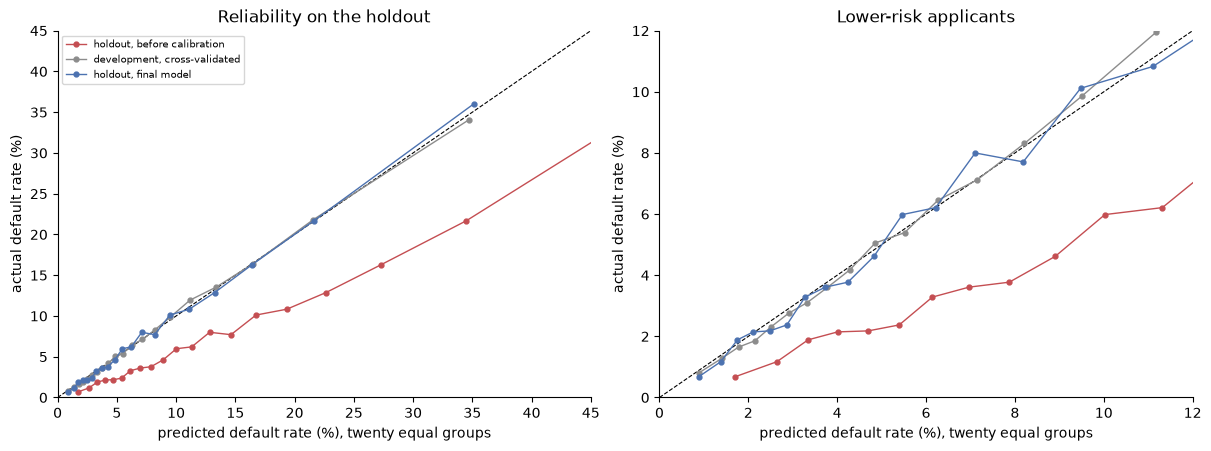

In [96]:
calib_hold = pd.DataFrame({'before calibration': calibration_report(y_h, hold_pred['final model before calibration']),
                           'after calibration (final model)': hold_report,
                           'cross-validated, after calibration': cv_report}).T
print(calib_hold.round({'roc_auc': 4, 'log_loss': 4, 'brier': 4, 'mean_predicted_pct': 2, 'expected_calibration_error_pts': 3, 'largest_gap_pts': 2, 'slope': 3, 'intercept': 3}).to_string())

tenths = reliability(y_h, p_hold, bins=10)
tenths['gap_pts'] = tenths['predicted_pct'] - tenths['actual_pct']
tenths['share_of_defaults_pct'] = tenths['actual_pct'] * tenths['rows'] / (tenths['actual_pct'] * tenths['rows']).sum() * 100
print('\nholdout, by tenth of predicted risk:')
print(tenths.round(2).T.to_string())
print(f"\nriskiest tenth: {tenths['actual_pct'].iloc[-1]:.1f}% default, {tenths['share_of_defaults_pct'].iloc[-1]:.1f}% of all defaults. "
      f"Riskiest three tenths: {tenths['share_of_defaults_pct'].iloc[-3:].sum():.1f}%. Safest tenth: {tenths['actual_pct'].iloc[0]:.2f}% default.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), layout='constrained')
for ax, limit in zip(axes, [45, 12]):
    ax.plot([0, limit], [0, limit], color='black', linewidth=0.8, linestyle='--')
    for label, yy, pp, color in [('holdout, before calibration', y_h, hold_pred['final model before calibration'], '#C44E52'),
                                 ('development, cross-validated', y_dev, results[FINAL_CALIBRATED]['oof'], '#8C8C8C'),
                                 ('holdout, final model', y_h, p_hold, '#4C72B0')]:
        r = reliability(yy, pp)
        ax.plot(r['predicted_pct'], r['actual_pct'], marker='o', markersize=3.5, linewidth=1, color=color, label=label)
    ax.set_xlim(0, limit); ax.set_ylim(0, limit)
    ax.set_xlabel('predicted default rate (%), twenty equal groups'); ax.set_ylabel('actual default rate (%)')
axes[0].set_title('Reliability on the holdout'); axes[1].set_title('Lower-risk applicants')
axes[0].legend(fontsize=7)
sns.despine()
plt.show()

### 11.7 The thresholds fixed in stage 10

The three thresholds were set by formula before the holdout was opened. Each is shown beside its figures from the development set. Cost is per 1,000 applicants, in units of one wrongly declined good applicant, at that threshold's own cost ratio.

In [97]:
p_dev_cal, y_d = results[FINAL_CALIBRATED]['oof'], y_dev.values
rows = []
for r, t in OPERATING_POINTS.items():
    for where, p, yy in [('development', p_dev_cal, y_d), ('holdout', p_hold, y_h)]:
        point = at_threshold(p, t, yy)
        blanket = min(r * yy.mean(), 1 - yy.mean()) * 1000
        cost = cost_per_1000(p, t, r, yy)
        rows.append({'cost_ratio': r, 'threshold': round(t, 4), 'data': where, 'approved_pct': point['approved_pct'], 'defaults_caught_pct': point['defaults_caught_pct'],
                     'default_rate_among_approved_pct': point['default_rate_among_approved_pct'],
                     'default_rate_among_declined_pct': point['default_rate_among_declined_pct'],
                     'good_applicants_declined_pct': point['good_applicants_declined_pct'], 'cost_per_1000': cost,
                     'saving_vs_no_model_pct': (1 - cost / blanket) * 100})
operating = pd.DataFrame(rows).set_index(['cost_ratio', 'threshold', 'data'])
print(operating.round(2).to_string())

declined_h = p_hold >= THRESHOLD
confusion_h = pd.DataFrame({'approved': [int((~declined_h & (y_h == 0)).sum()), int((~declined_h & (y_h == 1)).sum())],
                            'declined': [int((declined_h & (y_h == 0)).sum()), int((declined_h & (y_h == 1)).sum())]}, index=['repaid', 'defaulted'])
print(f"\nholdout at the reference threshold of {THRESHOLD:.4f}:")
print(confusion_h.to_string())

# was the formula's threshold still close to the best one on the holdout? (reported, not used)
for r in OPERATING_POINTS:
    best_t, best_cost = searched_threshold(p_hold, r, y_h)
    print(f"cost ratio {r}: formula threshold {1 / (1 + r):.4f} costs {cost_per_1000(p_hold, 1 / (1 + r), r, y_h):.1f}; "
          f"the best threshold in hindsight ({best_t:.3f}) costs {best_cost:.1f}")

                                  approved_pct  defaults_caught_pct  default_rate_among_approved_pct  default_rate_among_declined_pct  good_applicants_declined_pct  cost_per_1000  saving_vs_no_model_pct
cost_ratio threshold data                                                                                                                                                                                 
5          0.1667    development         87.83                39.24                             5.59                            26.02                          9.80         335.32                   16.93
                     holdout             87.94                40.28                             5.48                            26.96                          9.58         329.15                   18.45
10         0.0909    development         71.02                65.41                             3.93                            18.22                         25.78         516.23          

cost ratio 5: formula threshold 0.1667 costs 329.2; the best threshold in hindsight (0.166) costs 328.5


cost ratio 10: formula threshold 0.0909 costs 513.5; the best threshold in hindsight (0.095) costs 513.2


cost ratio 20: formula threshold 0.0476 costs 693.3; the best threshold in hindsight (0.050) costs 688.2


### 11.8 Calibration and approval by group, on the holdout

In [98]:
age_h = -X_hold['DAYS_BIRTH'] / 365.25
segments_h = {
    'loan type': X_hold['NAME_CONTRACT_TYPE'],
    'gender': X_hold['CODE_GENDER'].fillna('(missing)'),
    'age': pd.cut(age_h, [0, 30, 40, 50, 60, 100], labels=['under 30', '30 to 40', '40 to 50', '50 to 60', 'over 60']).astype(str),
    'external scores missing': X_hold['EXT_N_MISSING'].astype(int).astype(str),
    'has an employer': np.where(X_hold['DAYS_EMPLOYED'].isna(), 'no', 'yes'),
    'education': X_hold['EDUCATION_LEVEL'].map({0: 'lower secondary', 1: 'secondary', 2: 'incomplete higher', 3: 'higher', 4: 'academic degree'}),
}
rows = []
for segment, values in segments_h.items():
    values = pd.Series(np.asarray(values), index=X_hold.index)
    for level, idx in values.groupby(values).groups.items():
        mask = X_hold.index.isin(idx)
        if mask.sum() < 300:
            continue
        actual, predicted = y_h[mask].mean() * 100, p_hold[mask].mean() * 100
        se = np.sqrt(actual * (100 - actual) / mask.sum())
        rows.append({'segment': segment, 'group': level, 'rows': int(mask.sum()), 'actual_default_pct': actual, 'predicted_pct': predicted,
                     'gap_pts': predicted - actual, 'gap_in_standard_errors': (predicted - actual) / se,
                     'approved_pct': (~declined_h[mask]).mean() * 100, 'auc_within_group': roc_auc_score(y_h[mask], p_hold[mask])})
groups_h = pd.DataFrame(rows).set_index(['segment', 'group'])
groups_h['approval_ratio_to_highest'] = groups_h['approved_pct'] / groups_h.groupby(level='segment')['approved_pct'].transform('max')
print(f"largest calibration gap in any group: {groups_h['gap_pts'].abs().max():.2f} points; groups more than 2 standard errors off: "
      f"{groups_h.index[groups_h['gap_in_standard_errors'].abs() > 2].tolist()}")
print(f"AUC within groups: {groups_h['auc_within_group'].min():.4f} to {groups_h['auc_within_group'].max():.4f}")
groups_h.round(2)

largest calibration gap in any group: 0.48 points; groups more than 2 standard errors off: []
AUC within groups: 0.7311 to 0.7812


rows  actual_default_pct  \
segment                 group                                          
loan type               Cash loans         55672                8.35   
                        Revolving loans     5831                5.42   
gender                  F                  40561                6.99   
                        M                  20940               10.17   
age                     30 to 40           16491                9.57   
                        40 to 50           15299                7.58   
                        50 to 60           13620                6.34   
                        over 60             7188                4.97   
                        under 30            8905               11.30   
external scores missing 0                  21958                7.23   
                        1                  32051                8.24   
                        2                   7461                9.84   
has an employer         no                 11231                5.52   
                        yes                50272                8.64   
education               higher             15061                5.20   
                        incomplete higher   1988                7.90   
                        lower secondary      791               10.37   
                        secondary          43623                9.04   

                                           predicted_pct  gap_pts  \
segment                 group                                       
loan type               Cash loans                  8.35    -0.00   
                        Revolving loans             5.51     0.09   
gender                  F                           7.05     0.06   
                        M                          10.07    -0.10   
age                     30 to 40                    9.58     0.01   
                        40 to 50                    7.72     0.14   
                        50 to 60                    6.11    -0.24   
                        over 60                     4.90    -0.07   
                        under 30                   11.48     0.19   
external scores missing 0                           7.26     0.03   
                        1                           8.19    -0.05   
                        2                          10.01     0.17   
has an employer         no                          5.34    -0.19   
                        yes                         8.69     0.05   
education               higher                      5.36     0.16   
                        incomplete higher           8.38     0.48   
                        lower secondary            10.49     0.13   
                        secondary                   8.96    -0.08   

                                           gap_in_standard_errors  \
segment                 group                                       
loan type               Cash loans                          -0.03   
                        Revolving loans                      0.29   
gender                  F                                    0.46   
                        M                                   -0.48   
age                     30 to 40                             0.06   
                        40 to 50                             0.65   
                        50 to 60                            -1.13   
                        over 60                             -0.26   
                        under 30                             0.56   
external scores missing 0                                    0.19   
                        1                                   -0.36   
                        2                                    0.49   
has an employer         no                                  -0.86   
                        yes                                  0.38   
education               higher                               0.90   
                        incomplete higher        

### 11.9 Closing the holdout

In [99]:
print(holdout)
print('opened for:', holdout.log)
assert len(holdout.log) == 1, 'the holdout was opened more than once'

HOLDOUT_RESULT = {'roc_auc': float(hold_report['roc_auc']), 'interval': (float(low), float(high)), 'pr_auc': float(average_precision_score(y_h, p_hold)),
                  'log_loss': float(hold_report['log_loss']), 'cv_roc_auc': cv_auc, 'within_agreement_band': bool(in_band)}
print(pd.Series(HOLDOUT_RESULT).to_string())

HoldoutVault(61,503 rows, 4,965 defaults, opened 1 times)
opened for: ['stage 11: the single final evaluation of the model fixed in stages 7 to 10']
roc_auc                                                  0.771533
interval                 (0.7640995652126401, 0.7786399916754393)
pr_auc                                                   0.264404
log_loss                                                 0.241709
cv_roc_auc                                               0.768522
within_agreement_band                                        True


### Stage 11 findings

**The headline**

| Measure | Cross-validated on the development set | Holdout | Difference |
|---|---:|---:|---:|
| ROC AUC | 0.7685 | 0.7715 | +0.0030 |
| PR AUC | 0.2539 | 0.2644 | +0.0105 |
| Log loss | 0.2432 | 0.2417 | -0.0015 |
| Brier score | 0.0673 | 0.0668 | -0.0004 |
| Average prediction | 8.09% | 8.08% | |
| Actual default rate | 8.07% | 8.07% | |

- The holdout ROC AUC is 0.7715, with a 95% interval of 0.7641 to 0.7786 from 1,000 resamples of the holdout rows.
- It lies inside the range fixed in advance as agreement (0.7605 to 0.7765), and the cross-validated score lies inside the holdout's interval.
- The holdout was opened once, after the model, the thresholds and that range had been written down. Nothing was changed afterwards.

**The cross-validated scores were honest**
- The model scored 0.0030 higher on the holdout than cross-validation predicted. Tuning to the development rows would have produced the opposite: a holdout score below the cross-validated one.
- Two things push the holdout score up slightly. The final model was trained on all 246,008 development rows, where each cross-validation model saw 196,806. And these particular 61,503 rows appear to be somewhat easier: every model scored higher on them than in cross-validation.
- So the difference of +0.0030 is not evidence that the model is better than 0.7685. It is evidence that 0.7685 was not inflated. The fifty-trial searches, the feature pruning, and the choice of calibration method did not overfit the development set in any way the holdout can detect.

**The order of the models holds**

| Model | Cross-validated | Holdout | Holdout minus cross-validated |
|---|---:|---:|---:|
| Predicting the default rate | 0.5000 | 0.5000 | |
| `EXT_MEAN` as a score, no model | 0.7164 | 0.7165 | +0.0001 |
| Binned logistic regression | 0.7557 | 0.7613 | +0.0057 |
| LightGBM, default settings | 0.7612 | 0.7653 | +0.0041 |
| Final model | 0.7685 | 0.7715 | +0.0030 |

- The final model beats the default LightGBM by 0.0062 on the holdout, with an interval of 0.0044 to 0.0081. In cross-validation the gap was 0.0074.
- It beats the binned logistic regression by 0.0102, with an interval of 0.0079 to 0.0127. In cross-validation the gap was 0.0129.
- In all 1,000 resamples the final model won both comparisons.
- Both gaps are somewhat smaller on the holdout than in cross-validation. That is the direction expected when the final model was chosen by search and the reference models were not, and it puts a size on the selection effect: about 0.001 to 0.003. The gaps remain clearly above zero.
- The reference models were scored for comparison only. The final model had been fixed, and it was not reconsidered.

**Calibration carries over**
- The model predicts an average default rate of 8.08% on the holdout. The actual rate is 8.07%.
- Before calibration the same model predicted 13.56%, with a log loss of 0.2584. After calibration the log loss is 0.2417.
- Across ten groups by predicted risk, the largest gap between predicted and actual default rate is 0.48 points.
- The calibration error is 0.32 points on the holdout against 0.22 in cross-validation. The holdout has a quarter of the rows, so each of its twenty groups is noisier, and some rise in this figure is expected from that alone.
- In none of the 18 applicant groups is the gap between predicted and actual default rate larger than 2 standard errors. The largest is 0.48 points, for applicants with incomplete higher education.
- The riskiest tenth of holdout applicants defaults at 28.9% and holds 35.8% of all defaults. The riskiest three tenths hold 66.8%. The safest tenth defaults at 0.93%.

**The thresholds behave as they did in development**

| Cost ratio | Threshold | Approved | Defaults caught | Default rate among approved | Saving against the best policy with no model |
|---:|---:|---:|---:|---:|---:|
| 5 | 0.1667 | 87.9% (87.8%) | 40.3% (39.2%) | 5.48% (5.59%) | 18.5% (16.9%) |
| 10 | 0.0909 | 71.1% (71.0%) | 65.6% (65.4%) | 3.91% (3.93%) | 36.4% (36.1%) |
| 20 | 0.0476 | 47.0% (46.8%) | 85.6% (85.6%) | 2.47% (2.48%) | 24.6% (24.3%) |

(Holdout first, development set in brackets.)

- Every figure is within about one percentage point of its development value.
- At the reference threshold the holdout confusion table is 42,045 repaid and approved, 14,493 repaid and declined, 1,709 defaulted and approved, 3,256 defaulted and declined.
- The formula's thresholds were still close to the best available. At a cost ratio of 10, the formula's threshold costs 513.5 per 1,000 applicants, and the best threshold found in hindsight on the holdout costs 513.2. At a ratio of 20 the hindsight threshold is 0.7% cheaper.

**Performance and approval by group**
- AUC within groups ranges from 0.731 to 0.781. The model ranks least well among applicants over 60 (0.73), those with no employer (0.74) and those with lower secondary education (0.74). These are the groups with the lowest or least varied risk, where there is less to separate.
- The approval gaps from stage 10 reappear. Applicants under 30 are approved at 61% of the rate of those over 60, and men at 80% of the rate of women.

**What the holdout does not show**
- It is a random sample of the training file. It confirms the model was not tuned to particular rows. It says nothing about a population that differs from the training file.
- The competition's test file does differ (stages 10 and 12 of the EDA, stage 2 of this notebook), mainly in loan payment rates. The model's most important engineered feature, `ANNUITY_TO_CREDIT`, is the one that shifts most. The Kaggle submission in stage 13 is the only test of that.
- The holdout shares the one known weakness of this work: the 55 candidate features, and the list of 18 dropped in stage 8, were chosen in the EDA using all training rows including these. Stage 1 found that effect too small to measure. The holdout cannot check it, because it was part of it.
- A single holdout has its own noise. Its 95% interval is 0.015 wide. It can confirm a score to about plus or minus 0.007, and cannot rank models closer than that, except through the paired comparison in section 11.5.

**Verification**
- All 99 code cells ran in order with no errors and no warnings.
- One cell in the notebook calls `holdout.open()`. The vault's log shows one opening, and the stage ends by asserting that.
- Before opening, the notebook asserted that the holdout had not been touched, at the start of the stage and again after the final model was fitted. After opening, it asserted that no holdout row is in the development set.
- The fitted final model is saved in the cache. Re-running the notebook reloads it and reproduces the same holdout predictions. That re-execution is not a second look: nothing depends on it and nothing is changed by it.
- The final model's holdout figures were identical in every run: 0.7715, interval 0.7641 to 0.7786.
- One reference figure was not stable at first. The binned logistic regression was refitted on each run, and its solver does not land on exactly the same coefficients every time. Its holdout AUC read 0.7612, then 0.7614, then 0.7613 across three runs. The fitted reference models are now saved in the cache as well, and two further runs gave identical figures. The figures quoted above are the saved ones. The movement was 0.0002 in a reference model and affected no decision.
- All of stages 1 to 10 match the notebook signed off at stage 10.

**Decisions**
- The model is confirmed as built: tuned LightGBM on 36 features with Platt scaling.
- The figure to quote for this model's ranking performance on new applicants from the same population is the holdout's: **ROC AUC 0.7715, with a 95% interval of 0.764 to 0.779**.
- Nothing is changed in response to the holdout. The model, features, calibration and thresholds are as they were fixed in stages 7 to 10.
- From here on the holdout is not used again. Stage 12 explains the model using the development set, and stage 13 refits it on all of the training data for the submission.

## Stage 12: Explainability

Why does the model give a particular applicant a particular score?

A credit decision has to be explainable. A lender must be able to tell a declined applicant the main reasons, and anyone reviewing the model needs to see that it relies on sensible things. This stage explains the final model with SHAP values.

**What a SHAP value is.** For one applicant, the model's prediction is broken into a starting point, which is the same for everyone, plus one contribution from each feature. A positive contribution means that feature's value pushed this applicant's predicted risk up, and a negative one means it pushed it down. The contributions add up exactly to the prediction. Averaged over many applicants, the size of a feature's contributions says how much the model relies on it.

**The units.** Contributions are in log-odds, because that is the scale on which they add up. To make them readable they are also shown as multipliers on the odds of default: a contribution of +0.69 doubles the odds, and −0.69 halves them. The Platt calibration from stage 9 is a straight-line rescaling of the log-odds, so the contributions carry through it exactly and the explanations describe the calibrated probability the model actually outputs.

**What is and is not being done here.**
- The model explained is the final one from stage 11, fitted on the whole development set.
- The holdout is not used. It was closed at the end of stage 11.
- An explanation describes what the model does. It is not a measure of how accurate the model is, so explaining rows the model was trained on does not inflate any score. Section 12.6 still checks that the explanations hold for applicants the model has not seen.
- SHAP values describe the model, not the world. A large contribution from a feature means the model uses it, not that the feature causes default.

### 12.1 Computing the contributions, and checking they add up

In [100]:
final_pre = final_model.named_steps['preprocess']
final_cal = final_model.named_steps['model']
final_lgbm = final_cal.model_
PLATT_A, PLATT_B = float(final_cal.calibrator_.coef_[0, 0]), float(final_cal.calibrator_.intercept_[0])
EXPLAINED = list(final_pre.named_steps['keep'].columns_)

sample_rows = np.sort(np.random.default_rng(SEED).choice(len(X_dev), size=20_000, replace=False))
X_sample_raw = X_dev.iloc[sample_rows]                      # values as a person would read them
X_sample = final_pre.transform(X_sample_raw)                # what the model receives
y_sample = y_dev.values[sample_rows]

def contributions(model, X_encoded):
    # exact TreeSHAP values from LightGBM: one column per feature, plus the starting point in the last column
    out = model.predict(X_encoded, pred_contrib=True)
    return np.asarray(out[:, :-1]), np.asarray(out[:, -1])

started = time.time()
raw_contrib, raw_base = contributions(final_lgbm, X_sample)
print(f"contributions for {len(X_sample):,} applicants and {len(EXPLAINED)} features in {time.time() - started:.1f} seconds")

# 1. the contributions and the starting point add up to the model's raw score
raw_score = final_lgbm.predict(X_sample, raw_score=True)
print(f"largest difference between sum of contributions and the model's raw score: {np.abs(raw_contrib.sum(axis=1) + raw_base - raw_score).max():.2e}")

# 2. carried through the calibration, they add up to the probability the final model outputs
shap_values = pd.DataFrame(PLATT_A * raw_contrib, columns=EXPLAINED, index=X_sample_raw.index)     # calibrated log-odds
BASE_LOGODDS = float(PLATT_A * raw_base[0] + PLATT_B)
p_from_shap = 1 / (1 + np.exp(-(shap_values.sum(axis=1).values + BASE_LOGODDS)))
p_sample = final_model.predict_proba(X_sample_raw)[:, 1]
print(f"largest difference between the probability rebuilt from contributions and the model's output: {np.abs(p_from_shap - p_sample).max():.2e}")

print(f"\nstarting point: log-odds {BASE_LOGODDS:.3f}, which is a probability of {1 / (1 + np.exp(-BASE_LOGODDS)):.2%}")
print(f"average predicted probability in the sample: {p_sample.mean():.2%}; actual default rate in the sample: {y_sample.mean():.2%}")
print(f"calibration: calibrated log-odds = {PLATT_A:.4f} x raw log-odds {PLATT_B:+.4f}")
print(holdout)

contributions for 20,000 applicants and 36 features in 20.9 seconds


largest difference between sum of contributions and the model's raw score: 3.02e-14


largest difference between the probability rebuilt from contributions and the model's output: 4.72e-15

starting point: log-odds -2.812, which is a probability of 5.67%
average predicted probability in the sample: 7.99%; actual default rate in the sample: 7.90%
calibration: calibrated log-odds = 1.0051 x raw log-odds -0.6447
HoldoutVault(61,503 rows, 4,965 defaults, opened 1 times)


### 12.2 Which features drive the model overall

The average size of each feature's contribution, in log-odds, and the same thing as a typical multiplier on the odds. A typical multiplier of 1.20 means that feature usually moves an applicant's odds of default up or down by about 20%.

In [101]:
FAMILIES = {
    'external scores': [c for c in EXPLAINED if c.startswith('EXT_')],
    'loan and amounts': ['AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'ANNUITY_TO_CREDIT', 'CREDIT_TO_GOODS', 'CREDIT_TO_INCOME', 'ANNUITY_TO_INCOME', 'NAME_CONTRACT_TYPE'],
    'age, gender, education, family': ['DAYS_BIRTH', 'CODE_GENDER', 'EDUCATION_LEVEL', 'NAME_FAMILY_STATUS'],
    'employment': ['DAYS_EMPLOYED', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE'],
    'documents, phone and registration': ['DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE', 'FLAG_DOCUMENT_3', 'FLAG_WORK_PHONE'],
    'housing, car and region': ['OWN_CAR_AGE', 'NAME_HOUSING_TYPE', 'REGION_POPULATION_RELATIVE', 'REGION_RATING_CLIENT_W_CITY', 'REG_CITY_NOT_LIVE_CITY'],
    'social circle and bureau enquiries': ['OBS_30_CNT_SOCIAL_CIRCLE', 'DEF_30_CNT_SOCIAL_CIRCLE', 'AMT_REQ_CREDIT_BUREAU_YEAR'],
}
family_of = {c: fam for fam, members in FAMILIES.items() for c in members}
assert sorted(family_of) == sorted(EXPLAINED)

shap_importance = pd.DataFrame({
    'family': pd.Series(family_of),
    'engineered': [c in ENGINEERED_SET for c in EXPLAINED],
    'mean_abs_contribution': shap_values.abs().mean(),
    'typical_odds_multiplier': np.exp(shap_values.abs().mean()),
    'share_pct': shap_values.abs().mean() / shap_values.abs().mean().sum() * 100,
    'largest_push_up': np.exp(shap_values.max()),
    'largest_push_down': np.exp(shap_values.min()),
}, index=EXPLAINED).sort_values('mean_abs_contribution', ascending=False)
shap_importance['rank'] = np.arange(1, len(shap_importance) + 1)
shap_importance['permutation_rank_stage8'] = importance.loc[shap_importance.index, 'auc_drop'].rank(ascending=False).astype(int)

print(f"rank agreement with stage 8 permutation importance (Spearman): {shap_importance['mean_abs_contribution'].corr(importance.loc[shap_importance.index, 'auc_drop'], method='spearman'):.2f}")
print(f"share of total contribution in the top 5 / top 10 features: {shap_importance['share_pct'].head(5).sum():.0f}% / {shap_importance['share_pct'].head(10).sum():.0f}%")

# a family's contribution is the sum of its features' contributions, so features that offset each other inside a family cancel
family_table = pd.DataFrame({fam: {'features': len(members),
                                   'mean_abs_contribution': shap_values[members].sum(axis=1).abs().mean(),
                                   'typical_odds_multiplier': np.exp(shap_values[members].sum(axis=1).abs().mean())}
                             for fam, members in FAMILIES.items()}).T.sort_values('mean_abs_contribution', ascending=False)
family_table['share_pct'] = family_table['mean_abs_contribution'] / family_table['mean_abs_contribution'].sum() * 100
print('\nby family of features:')
print(family_table.round(3).to_string())
with pd.option_context('display.max_rows', 40):
    display(shap_importance.round({'mean_abs_contribution': 4, 'typical_odds_multiplier': 3, 'share_pct': 1, 'largest_push_up': 2, 'largest_push_down': 2}))

rank agreement with stage 8 permutation importance (Spearman): 0.95
share of total contribution in the top 5 / top 10 features: 34% / 54%



by family of features:
                                    features  mean_abs_contribution  typical_odds_multiplier  share_pct
external scores                          8.0                  0.577                    1.780     39.251
loan and amounts                         8.0                  0.288                    1.333     19.587
age, gender, education, family           4.0                  0.155                    1.168     10.557
employment                               3.0                  0.147                    1.158     10.000
housing, car and region                  5.0                  0.123                    1.131      8.373
documents, phone and registration        5.0                  0.104                    1.110      7.087
social circle and bureau enquiries       3.0                  0.076                    1.079      5.145


,family,engineered,mean_abs_contribution,typical_odds_multiplier,share_pct,largest_push_up,largest_push_down,rank,permutation_rank_stage8
EXT_MEAN,external scores,True,0.2715,1.312,11.2,2.19,0.53,1,1
ANNUITY_TO_CREDIT,loan and amounts,True,0.1773,1.194,7.3,2.09,0.47,2,2
EXT_SOURCE_3,external scores,False,0.1546,1.167,6.4,2.44,0.78,3,3
CREDIT_TO_GOODS,loan and amounts,True,0.1095,1.116,4.5,1.62,0.79,4,5
CODE_GENDER,"age, gender, education, family",False,0.1053,1.111,4.4,1.36,0.85,5,6
EXT_MIN,external scores,True,0.1022,1.108,4.2,1.77,0.82,6,14
OWN_CAR_AGE,"housing, car and region",False,0.1004,1.106,4.2,1.14,0.69,7,11
EXT_MAX,external scores,True,0.0983,1.103,4.1,1.36,0.72,8,7
DAYS_EMPLOYED,employment,False,0.0933,1.098,3.9,1.29,0.67,9,9
EDUCATION_LEVEL,"age, gender, education, family",True,0.0849,1.089,3.5,1.17,0.74,10,15


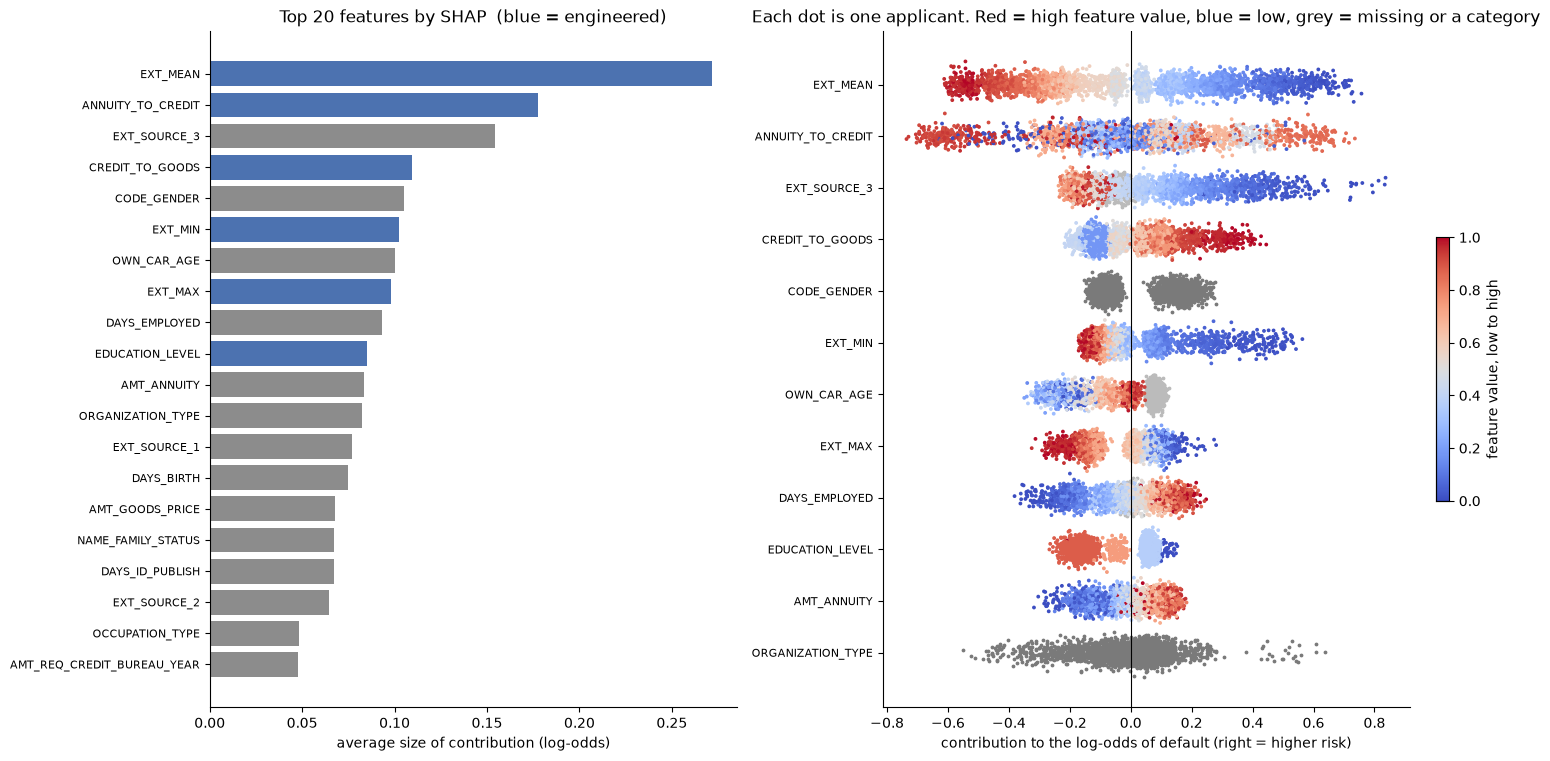

In [102]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5), layout='constrained')
top = shap_importance.head(20).iloc[::-1]
axes[0].barh(top.index, top['mean_abs_contribution'], color=np.where(top['engineered'], '#4C72B0', '#8C8C8C'))
axes[0].set_xlabel('average size of contribution (log-odds)')
axes[0].set_title('Top 20 features by SHAP  (blue = engineered)')
axes[0].tick_params(axis='y', labelsize=8)

# every applicant's contribution for the top 12 features, coloured by whether the feature value is low or high
plot_rows = np.random.default_rng(SEED).choice(len(shap_values), 4000, replace=False)
names = shap_importance.head(12).index[::-1]
for i, c in enumerate(names):
    v = shap_values[c].values[plot_rows]
    feature = X_sample[c].iloc[plot_rows]
    numeric = pd.api.types.is_numeric_dtype(feature) and not isinstance(feature.dtype, pd.CategoricalDtype)
    colour = feature.rank(pct=True).values if numeric else np.full(len(v), np.nan)
    jitter = np.random.default_rng(i).normal(0, 0.12, len(v))
    if numeric:
        seen = ~np.isnan(feature.values.astype(float))
        axes[1].scatter(v[~seen], i + jitter[~seen], s=3, color='#BBBBBB')
        sc = axes[1].scatter(v[seen], i + jitter[seen], s=3, c=colour[seen], cmap='coolwarm', vmin=0, vmax=1)
    else:
        axes[1].scatter(v, i + jitter, s=3, color='#7A7A7A')
axes[1].set_yticks(range(len(names))); axes[1].set_yticklabels(names, fontsize=8)
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_xlabel('contribution to the log-odds of default (right = higher risk)')
axes[1].set_title('Each dot is one applicant. Red = high feature value, blue = low, grey = missing or a category')
fig.colorbar(sc, ax=axes[1], fraction=0.025, label='feature value, low to high')
sns.despine()
plt.show()

### 12.3 The shape of each relationship

For the most important numeric features, the contribution plotted against the feature's value. This shows what the model has learned: where risk rises, where it falls, and whether the relationship is a straight line. Day counts are shown as years. The table gives the same thing in numbers, as the average multiplier on the odds within each tenth of the feature's values.

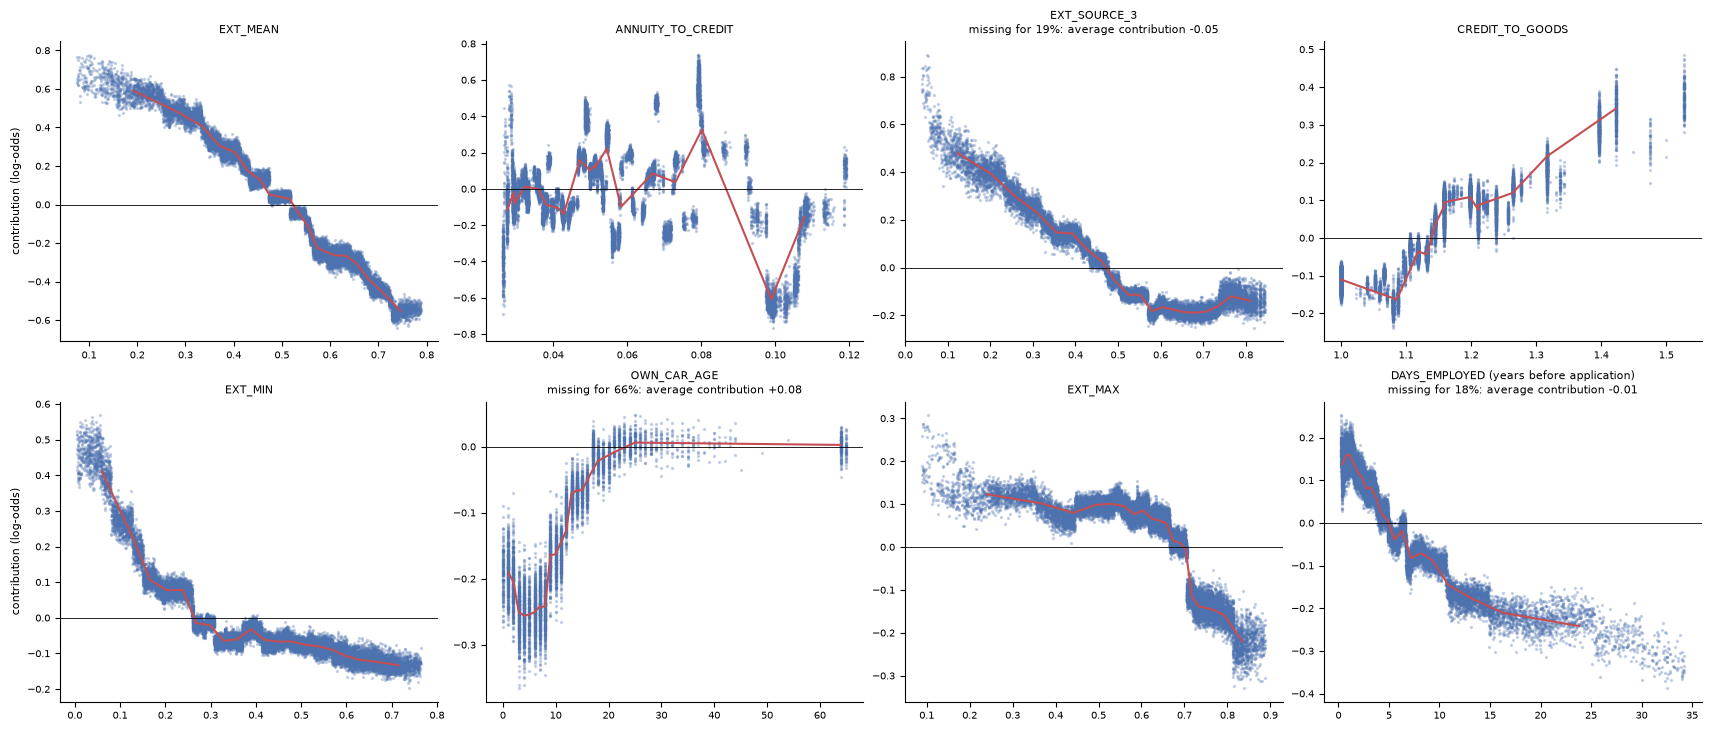

EXT_MEAN
  value:            [0.239, 0.351, 0.415, 0.463, 0.506, 0.544, 0.583, 0.623, 0.667, 0.728]
  odds multiplier:  [1.73, 1.43, 1.25, 1.11, 1.02, 0.92, 0.79, 0.77, 0.71, 0.61]
ANNUITY_TO_CREDIT
  value:            [0.029, 0.032, 0.037, 0.042, 0.05, 0.051, 0.053, 0.064, 0.079, 0.105]
  odds multiplier:  [0.92, 0.97, 0.98, 0.88, 1.17, 1.13, 1.1, 1.03, 1.2, 0.69]
EXT_SOURCE_3
  value:            [0.159, 0.282, 0.374, 0.445, 0.512, 0.566, 0.62, 0.671, 0.721, 0.786]
  odds multiplier:  [1.56, 1.31, 1.16, 1.05, 0.91, 0.87, 0.84, 0.83, 0.85, 0.88]
  when missing (19% of applicants): odds multiplier 0.95
CREDIT_TO_GOODS
  value:            [1.0, 1.066, 1.106, 1.132, 1.158, 1.198, 1.238, 1.396]
  odds multiplier:  [0.89, 0.89, 0.92, 0.98, 1.08, 1.11, 1.1, 1.29]
EXT_MIN
  value:            [0.091, 0.184, 0.254, 0.314, 0.374, 0.433, 0.494, 0.555, 0.615, 0.693]
  odds multiplier:  [1.38, 1.1, 1.04, 0.96, 0.95, 0.94, 0.93, 0.92, 0.89, 0.88]
OWN_CAR_AGE
  value:            [1.0, 4.0, 6.0, 7.0, 

  when missing (66% of applicants): odds multiplier 1.08


In [103]:
def readable_values(c, s):
    # accepts a table column or a plain list of values
    s = pd.Series(np.asarray(s, dtype=float), index=s.index if isinstance(s, pd.Series) else None)
    return (-s / 365.25, f"{c} (years before application)") if c.startswith('DAYS_') else (s, c)

numeric_top = [c for c in shap_importance.index if c not in TEXT_FEATURES][:8]
fig, axes = plt.subplots(2, 4, figsize=(17, 7.2), layout='constrained')
for ax, c in zip(axes.ravel(), numeric_top):
    x, label = readable_values(c, X_sample_raw[c])
    v = shap_values[c]
    missing = x.isna().values
    lo, hi = np.nanpercentile(x, [0.5, 99.5])
    keep = ~missing & (x.values >= lo) & (x.values <= hi)
    ax.scatter(x.values[keep], v.values[keep], s=2, alpha=0.25, color='#4C72B0')
    bins = pd.qcut(x[keep], 20, duplicates='drop')
    centre = pd.DataFrame({'x': x[keep], 'v': v[keep]}).groupby(bins, observed=True).median()
    ax.plot(centre['x'], centre['v'], color='#C44E52', linewidth=1.5)
    ax.axhline(0, color='black', linewidth=0.6)
    if missing.mean() >= 0.005:
        ax.set_title(f"{label}\nmissing for {missing.mean():.0%}: average contribution {v.values[missing].mean():+.2f}", fontsize=8)
    else:
        ax.set_title(label, fontsize=8)
    ax.tick_params(labelsize=7)
for ax in axes[:, 0]:
    ax.set_ylabel('contribution (log-odds)', fontsize=8)
sns.despine()
plt.show()

for c in numeric_top[:6]:
    x, label = readable_values(c, X_sample_raw[c])
    table = pd.DataFrame({'value': x, 'contribution': shap_values[c]}).dropna()
    by = table.groupby(pd.qcut(table['value'], 10, duplicates='drop'), observed=True).agg(median_value=('value', 'median'), odds_multiplier=('contribution', lambda s: np.exp(s.mean())))
    print(label)
    print('  value:           ', np.round(by['median_value'].values, 3).tolist())
    print('  odds multiplier: ', np.round(by['odds_multiplier'].values, 2).tolist())
    if x.isna().mean() >= 0.005:
        print(f"  when missing ({x.isna().mean():.0%} of applicants): odds multiplier {np.exp(shap_values.loc[x.isna().values, c].mean()):.2f}")

### 12.4 The text features

For each level of a text feature, the average multiplier on the odds that the model applies. Levels held by fewer than 150 applicants in the sample are left out.

In [104]:
for c in [c for c in shap_importance.index if c in TEXT_FEATURES]:
    levels = X_sample_raw[c].fillna('(missing)').astype(str)
    by = pd.DataFrame({'level': levels.values, 'contribution': shap_values[c].values, 'y': y_sample}).groupby('level').agg(
        applicants=('contribution', 'size'), odds_multiplier=('contribution', lambda s: np.exp(s.mean())), actual_default_pct=('y', lambda s: s.mean() * 100))
    by = by[by['applicants'] >= 150].sort_values('odds_multiplier', ascending=False)
    shown = by if len(by) <= 10 else pd.concat([by.head(5), by.tail(5)])
    print(f"{c}  (rank {int(shap_importance.loc[c, 'rank'])} of {len(EXPLAINED)}; {len(by)} levels shown{', highest and lowest five' if len(by) > 10 else ''})")
    print(shown.round(2).to_string())
    print()

CODE_GENDER  (rank 5 of 36; 2 levels shown)
       applicants  odds_multiplier  actual_default_pct
level                                                 
M            6819             1.16                9.77
F           13181             0.92                6.94

ORGANIZATION_TYPE  (rank 12 of 36; 22 levels shown, highest and lowest five)
                        applicants  odds_multiplier  actual_default_pct
level                                                                  
Construction                   472             1.24               11.23
Self-employed                 2569             1.10                9.61
Industry: type 3               192             1.08               10.94
XNA                           3648             1.04                5.18
Business Entity Type 3        4421             1.04                9.57
Kindergarten                   425             0.89                6.82
School                         566             0.85                7.07
Bank      

NAME_CONTRACT_TYPE  (rank 28 of 36; 2 levels shown)
                 applicants  odds_multiplier  actual_default_pct
level                                                           
Cash loans            18074             1.02                8.21
Revolving loans        1926             0.85                5.09

NAME_HOUSING_TYPE  (rank 34 of 36; 5 levels shown)


                     applicants  odds_multiplier  actual_default_pct
level                                                               
Municipal apartment         747             1.10                6.96
Rented apartment            329             1.10               10.64
With parents                971             1.03               11.12
House / apartment         17730             0.99                7.75
Office apartment            161             0.86                6.21



### 12.5 Explaining individual applicants

Four applicants from the sample: the one the model rates riskiest, the safest, one sitting on the reference threshold from stage 10, and one at the median. For each, the features that moved the prediction most are listed with their values. Each explanation starts from the same point and adds up to that applicant's probability.

In [105]:
def explain(position, top=6):
    row = shap_values.iloc[position].sort_values(key=abs, ascending=False)
    values = X_sample_raw.iloc[position]
    lines = []
    for c in row.index[:top]:
        shown, _ = readable_values(c, [values[c]]) if (c.startswith('DAYS_') and pd.notna(values[c])) else (None, None)
        value = f"{float(shown.iloc[0]):.1f} years" if shown is not None else ('missing' if pd.isna(values[c]) else (f"{values[c]:.4g}" if isinstance(values[c], (int, float, np.integer, np.floating)) else str(values[c])))
        lines.append({'feature': c, 'value': value, 'contribution': row[c], 'odds_multiplier': np.exp(row[c]), 'direction': 'raises risk' if row[c] > 0 else 'lowers risk'})
    rest = row.iloc[top:].sum()
    lines.append({'feature': f'all {len(row) - top} other features together', 'value': '', 'contribution': rest, 'odds_multiplier': np.exp(rest),
                  'direction': 'raises risk' if rest > 0 else 'lowers risk'})
    return pd.DataFrame(lines).set_index('feature')

order = np.argsort(p_sample)
examples = {'riskiest in the sample': order[-1], 'safest in the sample': order[0],
            f'on the reference threshold ({THRESHOLD:.4f})': int(np.argmin(np.abs(p_sample - THRESHOLD))),
            'median applicant': order[len(order) // 2]}
base_p = 1 / (1 + np.exp(-BASE_LOGODDS))
for label, pos in examples.items():
    decision = 'declined' if p_sample[pos] >= THRESHOLD else 'approved'
    outcome = 'defaulted' if y_sample[pos] == 1 else 'repaid'
    print(f"{label}: predicted probability {p_sample[pos]:.2%} ({decision} at the reference threshold; in fact {outcome})")
    print(f"  starting point {base_p:.2%}, total of all contributions {shap_values.iloc[pos].sum():+.2f} log-odds, odds multiplied by {np.exp(shap_values.iloc[pos].sum()):.2f}")
    print(explain(pos).round(3).to_string())
    print()

riskiest in the sample: predicted probability 69.85% (declined at the reference threshold; in fact defaulted)
  starting point 5.67%, total of all contributions +3.65 log-odds, odds multiplied by 38.57
                                  value  contribution  odds_multiplier    direction
feature                                                                            
EXT_SOURCE_3                    0.03816         0.838            2.311  raises risk
EXT_MEAN                        0.07372         0.783            2.189  raises risk
EXT_MIN                         0.03816         0.552            1.737  raises risk
EXT_MAX                          0.1009         0.280            1.323  raises risk
EXT_SOURCE_1                     0.1009         0.204            1.227  raises risk
EXT_SOURCE_2                    0.08212         0.156            1.169  raises risk
all 30 other features together                  0.838            2.312  raises risk

safest in the sample: predicted probabili

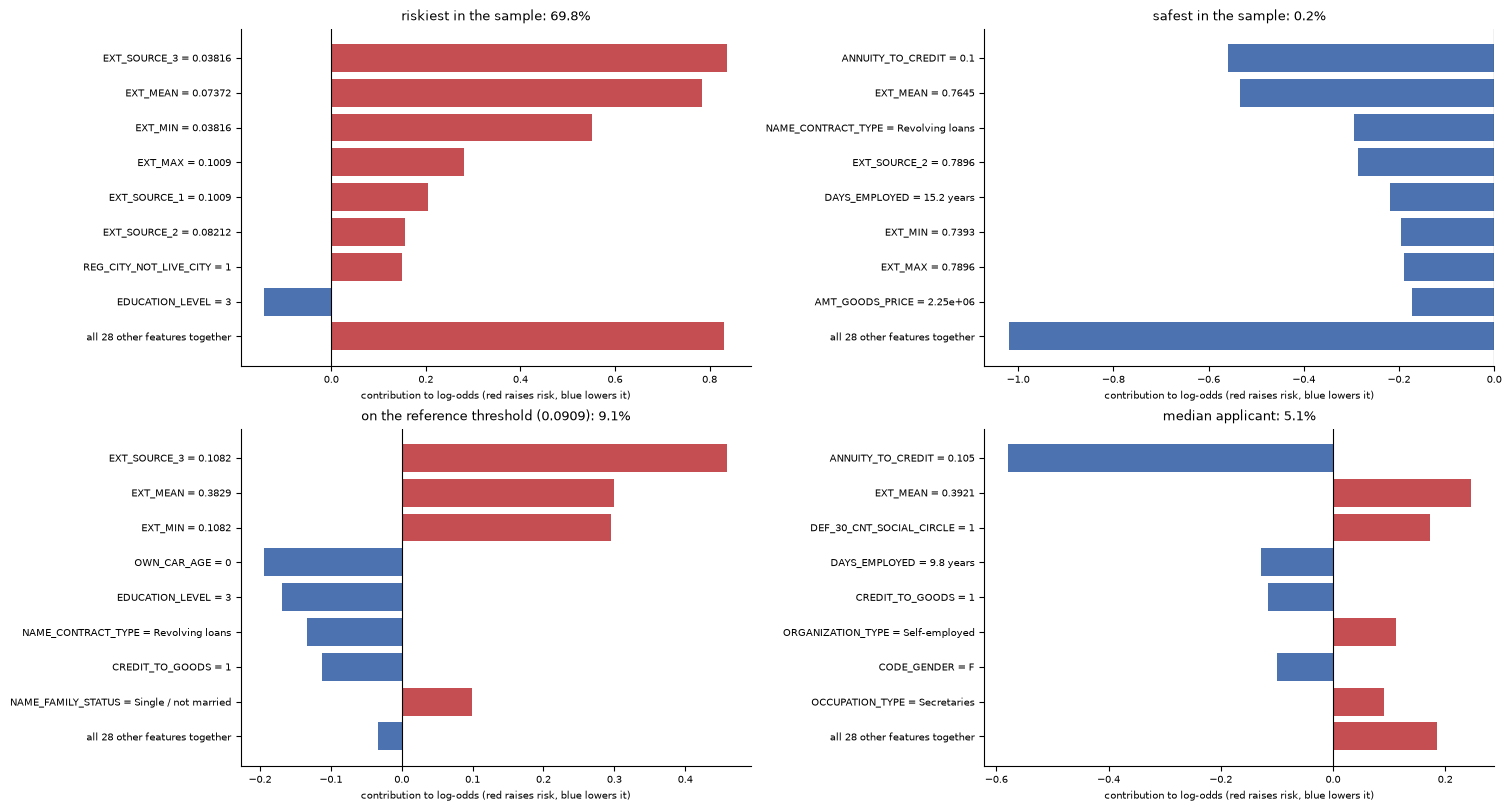

In [106]:
fig, axes = plt.subplots(2, 2, figsize=(15, 8), layout='constrained')
for ax, (label, pos) in zip(axes.ravel(), examples.items()):
    e = explain(pos, top=8).iloc[::-1]
    ax.barh([f"{i} = {v}" if v else i for i, v in zip(e.index, e['value'])], e['contribution'], color=np.where(e['contribution'] > 0, '#C44E52', '#4C72B0'))
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(f"{label}: {p_sample[pos]:.1%}", fontsize=9)
    ax.set_xlabel('contribution to log-odds (red raises risk, blue lowers it)', fontsize=7)
    ax.tick_params(labelsize=7)
sns.despine()
plt.show()

**Reasons for decline.** A lender that declines an application is usually expected to give the main reasons. For every applicant in the sample who would be declined at the reference threshold, the feature with the largest risk-raising contribution is taken as the main reason. The table counts how often each feature is the main reason, and how often it is among the top three.

In [107]:
declined_s = p_sample >= THRESHOLD
positive = shap_values[declined_s].clip(lower=0)
ranks = positive.rank(axis=1, ascending=False, method='first')
reasons = pd.DataFrame({'main_reason_pct': (ranks == 1).mean() * 100, 'in_top_three_pct': (ranks <= 3).mean() * 100,
                        'average_odds_multiplier_when_main': [np.exp(shap_values.loc[declined_s, c][(ranks[c] == 1).values].mean()) if (ranks[c] == 1).any() else np.nan
                                                               for c in EXPLAINED]}, index=EXPLAINED).sort_values('main_reason_pct', ascending=False)
print(f"{int(declined_s.sum()):,} of {len(p_sample):,} applicants in the sample would be declined ({declined_s.mean():.1%})")
print(f"distinct features that are the main reason for at least one applicant: {int((reasons['main_reason_pct'] > 0).sum())}")
print(f"the three most common main reasons cover {reasons['main_reason_pct'].head(3).sum():.0f}% of declines")
missing_reason = pd.Series({c: (X_sample_raw.loc[declined_s, c].isna().values & (ranks[c] == 1).values).mean() * 100 for c in EXPLAINED})
print(f"declines where the main reason is a feature whose value is missing: {missing_reason.sum():.1f}% (mostly {missing_reason.idxmax()})")
# The same question by family. Several features are built from the same three external scores and split one effect between them,
# so a family's contributions are added together before the largest is picked.
family_push = pd.DataFrame({fam: shap_values.loc[declined_s, members].sum(axis=1) for fam, members in FAMILIES.items()})
family_reasons = pd.DataFrame({'main_reason_pct': family_push.idxmax(axis=1).value_counts(normalize=True) * 100,
                               'average_odds_multiplier_among_declined': np.exp(family_push.mean())}).sort_values('main_reason_pct', ascending=False)
print('\nmain reason by family of features:')
print(family_reasons.round(2).to_string())
reasons.head(12).round(2)

5,662 of 20,000 applicants in the sample would be declined (28.3%)
distinct features that are the main reason for at least one applicant: 27
the three most common main reasons cover 82% of declines
declines where the main reason is a feature whose value is missing: 0.9% (mostly AMT_REQ_CREDIT_BUREAU_YEAR)

main reason by family of features:
                                    main_reason_pct  average_odds_multiplier_among_declined
external scores                               70.88                                    2.08
loan and amounts                              19.53                                    1.24
employment                                     3.51                                    1.09
age, gender, education, family                 3.34                                    1.05
documents, phone and registration              1.18                                    1.05
social circle and bureau enquiries             0.88                                    1.02
housing, car 

,main_reason_pct,in_top_three_pct,average_odds_multiplier_when_main
EXT_MEAN,49.81,76.05,1.60
ANNUITY_TO_CREDIT,18.03,39.76,1.54
EXT_SOURCE_3,14.50,42.44,1.55
CREDIT_TO_GOODS,3.89,16.00,1.37
CODE_GENDER,2.93,19.29,1.22
EXT_MIN,2.10,27.39,1.45
ORGANIZATION_TYPE,1.96,6.43,1.45
DAYS_ID_PUBLISH,1.54,5.85,1.32
DEF_30_CNT_SOCIAL_CIRCLE,1.29,8.21,1.32
DAYS_EMPLOYED,1.15,11.48,1.21


### 12.6 Do the explanations hold for applicants the model has not seen?

The contributions above come from the final model, which was trained on the rows it is explaining. Two checks that this does not distort them.

A second model with the same settings is trained on four folds and used to explain applicants in the fifth, whom it has never seen. Its explanations are compared with the final model's for the same applicants: do the two agree on which features matter, on each applicant's individual contributions, and on the main reason?

In [108]:
in_fold0 = dev_fold[sample_rows] == 0
unseen_pre = make_tree_preprocessor('category').fit(X_dev[dev_fold != 0])
keep_cols = lambda frame: frame[EXPLAINED]
unseen_model = FINAL().fit(keep_cols(unseen_pre.transform(X_dev[dev_fold != 0])), y_dev[dev_fold != 0])
unseen_contrib, _ = contributions(unseen_model, keep_cols(unseen_pre.transform(X_sample_raw[in_fold0])))
unseen_shap = pd.DataFrame(unseen_contrib, columns=EXPLAINED)
seen_shap = pd.DataFrame(raw_contrib[in_fold0], columns=EXPLAINED)          # the final model, same applicants, before the calibration rescaling

row_corr = np.array([np.corrcoef(unseen_shap.values[i], seen_shap.values[i])[0, 1] for i in range(len(unseen_shap))])
same_main = (unseen_shap.values.argmax(axis=1) == seen_shap.values.argmax(axis=1)).mean()
top3 = lambda frame: np.argsort(-frame.values, axis=1)[:, :3]
main_family = lambda frame: pd.DataFrame({fam: frame[members].sum(axis=1) for fam, members in FAMILIES.items()}).values.argmax(axis=1)
family_of_main = lambda frame: np.array([family_of[EXPLAINED[i]] for i in frame.values.argmax(axis=1)])
differ = unseen_shap.values.argmax(axis=1) != seen_shap.values.argmax(axis=1)
overlap = np.mean([len(set(a) & set(b)) for a, b in zip(top3(unseen_shap), top3(seen_shap))])
check = pd.Series({
    'applicants compared (in fold 0, unseen by the second model)': int(in_fold0.sum()),
    'rank agreement on overall feature importance (Spearman)': unseen_shap.abs().mean().corr(seen_shap.abs().mean(), method='spearman'),
    'correlation of overall feature importance': unseen_shap.abs().mean().corr(seen_shap.abs().mean()),
    'median correlation between the two explanations of one applicant': np.median(row_corr),
    'applicants where that correlation is under 0.9 (%)': (row_corr < 0.9).mean() * 100,
    'same main risk-raising feature (%)': same_main * 100,
    'where the main feature differs, both are in the same family (%)': (family_of_main(unseen_shap)[differ] == family_of_main(seen_shap)[differ]).mean() * 100,
    'same main risk-raising family, with a family added together (%)': (main_family(unseen_shap) == main_family(seen_shap)).mean() * 100,
    'average overlap of the top three risk-raising features (of 3)': overlap,
    'average size of contribution, model that saw the rows': seen_shap.abs().mean().mean(),
    'average size of contribution, model that did not': unseen_shap.abs().mean().mean(),
})
print(check.round(4).to_string())
side = pd.DataFrame({'final model (saw these rows)': seen_shap.abs().mean(), 'second model (did not)': unseen_shap.abs().mean()}).sort_values('final model (saw these rows)', ascending=False)
print('\naverage size of contribution, top 10 features:')
print(side.head(10).round(4).to_string())
# Why the main reason changes for some applicants: how far ahead of the runner-up the main feature was in the final model,
# and where the second model's main feature sits in the final model's own ordering.
ordered = -np.sort(-seen_shap.values, axis=1)
lead = ordered[:, 0] - ordered[:, 1]
position = (np.argsort(-seen_shap.values, axis=1) == unseen_shap.values.argmax(axis=1)[:, None]).argmax(axis=1)
print('\nlead of the main feature over the runner-up in the final model (log-odds), median:')
print(f'  applicants where both models give the same main feature: {np.median(lead[~differ]):.3f}')
print(f'  applicants where they give different main features:      {np.median(lead[differ]):.3f}')
print(f'where they differ, the second model\'s main feature is the final model\'s runner-up for {(position[differ] == 1).mean():.1%}, '
      f'and in its top three for {(position[differ] <= 2).mean():.1%}')
print(f'same main feature among applicants whose lead is above the median lead ({np.median(lead):.3f}): {(~differ)[lead > np.median(lead)].mean():.1%}; '
      f'at or below it: {(~differ)[lead <= np.median(lead)].mean():.1%}')
print(holdout)
assert len(holdout.log) == 1, 'the holdout must not be opened again'

applicants compared (in fold 0, unseen by the second model)         4187.0000
rank agreement on overall feature importance (Spearman)                0.9920
correlation of overall feature importance                              0.9976
median correlation between the two explanations of one applicant       0.9849
applicants where that correlation is under 0.9 (%)                     0.8120
same main risk-raising feature (%)                                    81.4903
where the main feature differs, both are in the same family (%)       22.5806
same main risk-raising family, with a family added together (%)       89.5390
average overlap of the top three risk-raising features (of 3)          2.5187
average size of contribution, model that saw the rows                  0.0669
average size of contribution, model that did not                       0.0679

average size of contribution, top 10 features:
                   final model (saw these rows)  second model (did not)
EXT_MEAN              

### Stage 12 findings

**What was explained.** The final model from stage 11 (LightGBM, 2,365 trees, 36 features, Platt scaling), on a sample of 20,000 development applicants. Contributions are SHAP values taken directly from LightGBM and rescaled by the calibrator's slope, so they are in the same log-odds as the probability the model reports. For every applicant the starting point (5.67%) plus the 36 contributions gives the reported probability to within 5e-15. Nothing in this stage was fitted, tuned or chosen using the holdout, which is still opened exactly once.

**What the model relies on**

| Family | Share of total contribution |
|---|---|
| External scores (6 features) | 39% |
| Loan and amounts | 20% |
| Age, gender, education, family | 11% |
| Employment | 10% |
| Housing, car and region | 8% |
| Documents, phone and registration | 7% |
| Social circle and bureau enquiries | 5% |

- The five largest features are `EXT_MEAN`, `ANNUITY_TO_CREDIT`, `EXT_SOURCE_3`, `CREDIT_TO_GOODS` and `CODE_GENDER`. The top five carry 34% of the total and the top ten 54%, so the model is not a one-feature model, but it is led by the external scores.
- The ranking agrees with the permutation importance from stage 8 (Spearman 0.95). Those are two different methods, one measuring loss of accuracy and one measuring size of contribution, so the agreement is evidence that neither ranking is an artefact of its method.

**Shapes of the main effects**

- `EXT_MEAN` is steep and monotone: odds multiplied by 1.73 in the lowest tenth and by 0.61 in the highest.
- `ANNUITY_TO_CREDIT` is not monotone. The effect rises through the middle of the range (about 1.1 to 1.2) and drops sharply in the top tenth (0.69). The top tenth are short loans repaid quickly. This is the shape the EDA found, and it is why this feature gained most from binning in the linear model.
- `CREDIT_TO_GOODS` rises steadily from 0.89 when the loan equals the price of the goods to 1.29 when it is about 40% above it.
- Missing values carry information, as the EDA suggested. No car on record (`OWN_CAR_AGE` missing, 66% of applicants) multiplies the odds by 1.08, while a new car multiplies them by about 0.8. A missing `EXT_SOURCE_3` (19%) is close to neutral at 0.95.
- `CODE_GENDER` multiplies the odds by 1.16 for men and 0.92 for women. This is the direct mechanism behind part of the approval-rate gap measured in stage 10. The model uses gender explicitly; whether it should is a policy question, not a modelling one, and it is listed under limits below.

**Reasons for a decline** (5,662 applicants in the sample, 28.3%, at the reference threshold of 0.0909)

- The single largest risk-raising feature is `EXT_MEAN` for 50% of declines, `ANNUITY_TO_CREDIT` for 18% and `EXT_SOURCE_3` for 14%. These three cover 82%; 27 different features are the main reason for at least one applicant.
- Added together by family, the external scores are the main reason for 71% of declines and the loan terms for 20%. Every other family is under 4%.
- A missing value is the main reason for 0.9% of declines.
- The four worked examples (riskiest 69.85%, safest 0.19%, one exactly on the threshold, and the median applicant) show the same pattern: the riskiest applicant's six largest contributions are all external-score features.

**Are the explanations stable?** A second model was trained without fold 0 and both models explained the same 4,187 fold-0 applicants.

| Measure | Result |
|---|---|
| Rank agreement on overall importance | 0.992 |
| Median correlation between the two explanations of one applicant | 0.985 |
| Applicants where that correlation is under 0.9 | 0.8% |
| Same main risk-raising feature | 81.5% |
| Same main risk-raising family | 89.5% |
| Overlap of the top three risk-raising features | 2.52 of 3 |

- The overall picture and the full explanation of each applicant are stable. The single "main reason" is less so: it changes for about one applicant in five.
- I expected the changes to be swaps between correlated external-score features. They are not: where the main feature changes, the two are in the same family only 23% of the time.
- The changes are near-ties. Where the two models disagree, the main feature led the runner-up by a median of 0.013 log-odds in the final model, against 0.072 where they agree. In 62% of disagreements the second model's main feature is the final model's runner-up, and in 81% it is in its top three. Among applicants whose main feature has an above-median lead, agreement is 98.4%; among the rest it is 64.6%.
- The practical consequence: a single reason should only be quoted when it leads clearly. Otherwise the top two or three should be given together, or the reason given by family.

**Limits**

- These contributions describe what the model does, not what causes default. A feature with a large contribution is one the model leans on, nothing more.
- For about seven declines in ten the honest main reason is an external score. Those scores come from outside providers and their inputs are unknown, so the explanation stops at "a low external score". That is a real limit on how useful these reasons are to an applicant, and it comes from the data, not from the method.
- The six external-score features are built from the same three scores and share one effect between them. Their individual contributions should not be read separately; the family total is the meaningful figure.
- The model uses gender and age-related features directly. Stage 10 measured the resulting approval-rate gaps. A lender subject to fair-lending rules would have to remove them or justify them, and this notebook does neither.
- The sample is 20,000 development applicants that the final model was trained on. The stability check shows that explanations of unseen applicants look the same, but the figures above are from seen rows.

**Verification**

- Additivity: largest error 4.7e-15 across 20,000 applicants.
- Two independent importance methods agree (0.95), and two models trained on different data agree (0.992).
- The notebook ran from top to bottom with 108 code cells, no errors and no warnings. Against the previous run and the signed-off stage 11 notebook, the only differences in earlier cells are recorded fitting times.
- The cache held 194 files before and after, so no earlier result was recomputed.
- One cell calls `holdout.open(`, and the vault reports one opening.

**Decisions carried forward**

- The model is unchanged. Nothing found here is a reason to revisit the 36 features or the calibration.
- Reason codes should be reported as the top three risk-raising features, or by family, not as a single feature.
- Stage 13 refits the final pipeline on all the training data, saves it under `artifacts/` and writes the submission files.


## Stage 13: Final model and outputs

Refit the chosen model on all of the training data, save it in a form that can be used outside this notebook, and write the Kaggle submission files.

Every choice is already fixed: the 36 features (stage 8), the LightGBM settings and 2,365 trees (stage 7), Platt scaling (stage 9) and the reference threshold (stage 10). This stage changes none of them. It only gives the same recipe more rows to learn from.

| Section | What it does |
|---|---|
| 13.1 | Refit the final pipeline on all 307,511 training rows |
| 13.2 | Check the refitted model against the model that was evaluated in stage 11 |
| 13.3 | Save the model as plain files and prove they can be loaded and used without this notebook |
| 13.4 | Build the second model, without `ANNUITY_TO_CREDIT`, and write down what is expected of both before any score is seen |
| 13.5 | Write and check the two submission files |

**About the holdout.** The 61,503 holdout rows did their job in stage 11 and now become ordinary training rows. That is the standard final step: more data gives a better model, and no further decision depends on them. The cost is that the refitted model has no unseen labelled rows left, so **its accuracy cannot be measured here**. The stage 11 figures (holdout ROC AUC 0.7715) belong to the model trained on 80% of the data and are the best available estimate for this one. No score is computed on training rows in this stage, because such a score would mean nothing.

**About the test file.** It has no target, so nothing can be fitted to it or chosen with it. It is only passed through the finished model.

### 13.1 Refit on all of the training data

The full training table is loaded again from the saved file, because every object that held it was deleted in stage 2. The holdout vault is not opened: nothing is being evaluated.

In [109]:
full = pd.read_parquet(f'{PROCESSED}/application_train_features.parquet')
full['REGION_RATING_CLIENT_W_CITY'] = full['REGION_RATING_CLIENT_W_CITY'].astype(float)      # as in stage 1
X_all, y_all = full[FEATURES].copy(), full['TARGET'].copy()
del full

refit_checks = {
    'all 307,511 training rows, 24,825 defaults': len(X_all) == 307511 and int(y_all.sum()) == 24825,
    'exactly the rows of the frozen split (development and holdout)': set(X_all.index) == set(split.index),
    'the development rows are unchanged': X_all.loc[X_dev.index].equals(X_dev) and y_all.loc[y_dev.index].equals(y_dev),
    'no test row is included': len(X_all.index.intersection(X_test.index)) == 0,
    'same columns and types as the development set': list(X_all.columns) == list(X_dev.columns) and all(str(X_all[c].dtype) == str(X_dev[c].dtype) for c in FEATURES),
}
for name, ok in refit_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(refit_checks.values())

ALL_ROWS = np.zeros(len(X_all), dtype=int)          # no folds: every row is a training row
started = time.time()
production, was_cached = cached_object('stage13-production-model-v1-' + cache_key(final_pipeline(), None, X_all, y_all, ALL_ROWS),
                                       lambda: final_pipeline().fit(X_all, y_all))
print(f"\nrefitted model: {'loaded from cache' if was_cached else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")

prod_pre, prod_cal = production.named_steps['preprocess'], production.named_steps['model']
prod_lgbm = prod_cal.model_
PROD_A, PROD_B = float(prod_cal.calibrator_.coef_[0, 0]), float(prod_cal.calibrator_.intercept_[0])
PROD_FEATURES = list(prod_pre.named_steps['keep'].columns_)
assert PROD_FEATURES == list(FINAL_FEATURES) and prod_lgbm.n_estimators_ == final_lgbm.n_estimators_

same_settings = {k: v for k, v in prod_lgbm.get_params().items()} == {k: v for k, v in final_lgbm.get_params().items()}
print(pd.DataFrame({
    'model evaluated in stage 11': {'training rows': f'{len(X_dev):,}', 'defaults': f'{int(y_dev.sum()):,}', 'features': str(len(EXPLAINED)), 'trees': f'{final_lgbm.n_estimators_:,}',
                                    'calibration slope': f'{PLATT_A:.4f}', 'calibration intercept': f'{PLATT_B:.4f}'},
    'refitted model': {'training rows': f'{len(X_all):,}', 'defaults': f'{int(y_all.sum()):,}', 'features': str(len(PROD_FEATURES)), 'trees': f'{prod_lgbm.n_estimators_:,}',
                       'calibration slope': f'{PROD_A:.4f}', 'calibration intercept': f'{PROD_B:.4f}'},
}).to_string())
print(f"\nidentical LightGBM settings: {same_settings}")
print(f"text levels learned from all rows that the development set did not contain: "
      f"{ {c: sorted(set(prod_pre.named_steps['encode'].categories_[c]) - set(final_pre.named_steps['encode'].categories_[c])) for c in TEXT_FEATURES if set(prod_pre.named_steps['encode'].categories_[c]) - set(final_pre.named_steps['encode'].categories_[c])} or 'none'}")
print(holdout)

PASS  all 307,511 training rows, 24,825 defaults
PASS  exactly the rows of the frozen split (development and holdout)
PASS  the development rows are unchanged
PASS  no test row is included
PASS  same columns and types as the development set



refitted model: loaded from cache
                      model evaluated in stage 11 refitted model
training rows                             246,008        307,511
defaults                                   19,860         24,825
features                                       36             36
trees                                       2,365          2,365
calibration slope                          1.0051         1.0118
calibration intercept                     -0.6447        -0.6387

identical LightGBM settings: True
text levels learned from all rows that the development set did not contain: none
HoldoutVault(61,503 rows, 4,965 defaults, opened 1 times)


### 13.2 Is the refitted model the same model, slightly better fed?

The refitted model cannot be scored, but it can be compared with the model that was scored. Both are run on the 48,744 test applications, which neither has seen. If the recipe is stable, adding 25% more rows should move individual predictions a little and leave the overall picture alone.

In [110]:
from scipy.stats import spearmanr

p_test = production.predict_proba(X_test)[:, 1]
p_test_dev = final_model.predict_proba(X_test)[:, 1]
assert np.isfinite(p_test).all() and ((p_test > 0) & (p_test < 1)).all()

moved = np.abs(p_test - p_test_dev)
agreement = pd.Series({
    'test applications scored': len(p_test),
    'rank correlation between the two models (Spearman)': spearmanr(p_test, p_test_dev)[0],
    'average prediction, model from stage 11 (%)': p_test_dev.mean() * 100,
    'average prediction, refitted model (%)': p_test.mean() * 100,
    'median change in one applicant\'s probability (points)': np.median(moved) * 100,
    '99th percentile of that change (points)': np.quantile(moved, 0.99) * 100,
    'same approve or decline decision at the reference threshold (%)': ((p_test >= THRESHOLD) == (p_test_dev >= THRESHOLD)).mean() * 100,
    'declined at the reference threshold, model from stage 11 (%)': (p_test_dev >= THRESHOLD).mean() * 100,
    'declined at the reference threshold, refitted model (%)': (p_test >= THRESHOLD).mean() * 100,
})
print(agreement.round(4).to_string())

# the same figures on the training file, for comparison
oof_final = results[FINAL_CALIBRATED]['oof']
print(f"\nfor comparison, on the training file: default rate {y_all.mean():.2%}; "
      f"declined at the reference threshold in cross-validation {(oof_final >= THRESHOLD).mean():.1%}; average cross-validated prediction {oof_final.mean():.2%}")

test applications scored                                           48744.0000
rank correlation between the two models (Spearman)                     0.9921
average prediction, model from stage 11 (%)                            8.1272
average prediction, refitted model (%)                                 8.1413
median change in one applicant's probability (points)                  0.3596
99th percentile of that change (points)                                4.1366
same approve or decline decision at the reference threshold (%)       97.1730
declined at the reference threshold, model from stage 11 (%)          30.0016
declined at the reference threshold, refitted model (%)               29.9647

for comparison, on the training file: default rate 8.07%; declined at the reference threshold in cross-validation 29.0%; average cross-validated prediction 8.09%


### 13.3 Save the model

The fitted pipeline uses three classes defined in this notebook (`CategoryEncoder`, `KeepColumns`, `CalibratedModel`). A pickle of it could only be opened from inside this notebook, which would make the saved file useless to anything else. So the model is saved as two plain files instead:

| File | Contents |
|---|---|
| `artifacts/final_model/model.txt` | The LightGBM trees, in LightGBM's own text format |
| `artifacts/final_model/metadata.json` | Feature order, the levels of each text feature, the calibration line, the threshold, the settings, the scores from stages 8 to 11, and the package versions |

`src/models/scoring.py` loads those two files and reproduces the pipeline in about forty lines, using only numpy, pandas and lightgbm.

The saved model is then tested the way it will be used: a **separate Python process**, which shares nothing with this notebook, loads the files and scores the test table. Its output must equal the notebook pipeline's output.

In [111]:
import sys, subprocess, tempfile
import lightgbm, scipy

MODEL_DIR = Path('../artifacts/final_model')
MODEL_DIR.mkdir(parents=True, exist_ok=True)

prod_lgbm.booster_.save_model(str(MODEL_DIR / 'model.txt'))
model_sha = hashlib.sha256((MODEL_DIR / 'model.txt').read_bytes()).hexdigest()

cv_final = results[FINAL_CALIBRATED]['mean']
levels = prod_pre.named_steps['encode'].categories_
metadata = {
    'name': 'Home Credit default risk, application table only',
    'predicts': 'probability that the applicant has payment difficulties (TARGET = 1)',
    'files': {'model': 'model.txt', 'model_sha256': model_sha},
    'features': PROD_FEATURES,
    'text_feature_levels': {c: list(levels[c]) for c in PROD_FEATURES if c in TEXT_FEATURES},
    'raw_application_columns_needed': list(RAW_COLUMNS_NEEDED),
    'calibration': {'method': 'Platt scaling', 'slope': PROD_A, 'intercept': PROD_B,
                    'formula': 'probability = sigmoid(slope * log(p / (1 - p)) + intercept), p = LightGBM output clipped to [1e-7, 1 - 1e-7]'},
    'decision': {'rule': 'decline when the probability is at or above the threshold',
                 'reference_threshold': float(THRESHOLD), 'reference_cost_ratio': REFERENCE_COST_RATIO,
                 'thresholds_by_cost_ratio': {str(r): float(t) for r, t in OPERATING_POINTS.items()}},
    'training': {'rows': int(len(X_all)), 'defaults': int(y_all.sum()), 'source': 'data/processed/application_train_features.parquet (all rows)',
                 'trees': int(prod_lgbm.n_estimators_), 'learning_rate': float(prod_lgbm.get_params()['learning_rate']), 'seed': SEED,
                 'lightgbm_settings': {k: (float(v) if isinstance(v, float) else int(v)) for k, v in best_params.items()}},
    'evidence': {'note': 'Measured on the same recipe trained on 80% of the training data. The saved model was trained on all of it and has not itself been scored.',
                 'cross_validation': {'roc_auc': float(cv_final['roc_auc']), 'pr_auc': float(cv_final['pr_auc']), 'log_loss': float(cv_final['log_loss'])},
                 'holdout': {'roc_auc': HOLDOUT_RESULT['roc_auc'], 'roc_auc_95_interval': list(HOLDOUT_RESULT['interval']),
                             'pr_auc': HOLDOUT_RESULT['pr_auc'], 'log_loss': HOLDOUT_RESULT['log_loss'], 'rows': holdout.n_rows}},
    'versions': {'python': sys.version.split()[0], 'lightgbm': lightgbm.__version__, 'pandas': pd.__version__, 'numpy': np.__version__,
                 'scikit-learn': sklearn.__version__, 'scipy': scipy.__version__},
}
(MODEL_DIR / 'metadata.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')
for f in sorted(MODEL_DIR.iterdir()):
    print(f"saved {f.as_posix().replace('../', '')}  ({f.stat().st_size / 1024:,.0f} KB)")
print(f"model.txt sha256: {model_sha[:16]}...")

# 1. a separate Python process loads the saved files and scores the test table
SCORER = Path('../src/models/scoring.py')
with tempfile.TemporaryDirectory() as tmp:
    out_csv = Path(tmp) / 'scores.csv'
    run = subprocess.run([sys.executable, str(SCORER), str(MODEL_DIR), f'{PROCESSED}/application_test_features.parquet', str(out_csv)],
                         capture_output=True, text=True)
    assert run.returncode == 0, run.stderr[-2000:]
    outside = pd.read_csv(out_csv).set_index('SK_ID_CURR')['TARGET']
assert outside.index.equals(X_test.index)
difference_outside = float(np.abs(outside.values - p_test).max())
print(f"\nseparate process: {run.stdout.strip()}; largest difference from the notebook pipeline: {difference_outside:.2e}")
assert difference_outside < 1e-9

# 2. the same loader used directly, on awkward input
sys.path.insert(0, str(SCORER.parent))
from scoring import load_model
saved_model = load_model(MODEL_DIR)
direct = saved_model.predict_proba(X_test)
few = X_test.head(500)
shuffled = few[list(reversed(FEATURES))].assign(NOT_A_FEATURE=1.0)
unseen = few.copy()
for c in saved_model.text_levels:
    unseen[c] = unseen[c].astype(object)
    unseen[c] = 'NEVER_SEEN'
as_missing = few.copy()
for c in saved_model.text_levels:
    as_missing[c] = np.nan
try:
    saved_model.predict_proba(few.drop(columns='EXT_MEAN'))
    refused = False
except ValueError as error:
    refused = 'EXT_MEAN' in str(error)

loader_checks = {
    'loaded in this process: equal to the pipeline to 1e-9': float(np.abs(direct - p_test).max()) < 1e-9,
    'given all 55 columns, it uses its 36': len(saved_model.features) == 36,
    'column order and extra columns do not matter': np.array_equal(saved_model.predict_proba(shuffled), direct[:500]),
    'a text level never seen in training is scored as a missing value': np.array_equal(saved_model.predict_proba(unseen), saved_model.predict_proba(as_missing)),
    'the pipeline treats unseen levels the same way': float(np.abs(production.predict_proba(unseen)[:, 1] - saved_model.predict_proba(unseen)).max()) < 1e-9,
    'a missing column is refused with a clear message': refused,
    'decisions use the reference threshold': np.array_equal(saved_model.decide(X_test), p_test >= THRESHOLD),
}
for name, ok in loader_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(loader_checks.values())

saved artifacts/final_model/metadata.json  (6 KB)
saved artifacts/final_model/model.txt  (2,957 KB)
model.txt sha256: 58fce879544e8572...



separate process: 48744 rows scored; largest difference from the notebook pipeline: 9.97e-17


PASS  loaded in this process: equal to the pipeline to 1e-9
PASS  given all 55 columns, it uses its 36
PASS  column order and extra columns do not matter
PASS  a text level never seen in training is scored as a missing value
PASS  the pipeline treats unseen levels the same way
PASS  a missing column is refused with a clear message
PASS  decisions use the reference threshold


### 13.4 The second model, and what is expected of both

**Why a second submission.** The test file is not a random sample of the same population as the training file (EDA stages 10 and 12, and stage 2 here). The largest difference is in loan payment rates, and `ANNUITY_TO_CREDIT`, the model's second most important feature, is the feature that shifts most. Cross-validation and the holdout both draw from the training file, so neither can show whether that shift hurts. The only evidence available is Kaggle's score on the test file.

So two models are submitted that differ in one thing: the 36-feature final model, and the same recipe without `ANNUITY_TO_CREDIT`. Cross-validation says what removing the feature costs when there is no shift. Kaggle will say what it costs when there is.

**What this comparison can and cannot show.** `AMT_ANNUITY` and `AMT_CREDIT` both stay in the model, so the trees can rebuild part of the ratio from them. The comparison tests the explicit ratio, not the removal of all payment-rate information.

The second model is a diagnostic. It is not a candidate to replace the final model: choosing between them on the Kaggle score would be tuning on the test set.

In [112]:
NO_A2C = [c for c in FINAL_FEATURES if c != 'ANNUITY_TO_CREDIT']
NO_A2C_NAME = 'final model, without ANNUITY_TO_CREDIT'
assert len(NO_A2C) == len(FINAL_FEATURES) - 1 and {'AMT_ANNUITY', 'AMT_CREDIT'} <= set(NO_A2C)

# how far each feature of the final model moves between the development set and the test file (no target involved)
shift = pd.Series({c: psi(X_dev[c], X_test[c]) for c in FINAL_FEATURES}).sort_values(ascending=False)
print('largest shifts between the development set and the test file (PSI; above 0.1 is usually called a moderate shift):')
print(shift.head(6).round(4).to_string())

# cost of removing the feature when there is no shift: the same five development folds as every other model
register(NO_A2C_NAME, cross_validate(with_columns(NO_A2C, FINAL())), columns=len(NO_A2C), note='stage 13 diagnostic')
versus_final = compare(NO_A2C_NAME, FINAL_NAME)
print(f"\nROC AUC by fold ({'loaded from cache' if results[NO_A2C_NAME]['cached'] else 'fitted now'})")
print(pd.DataFrame({'final model, 36 features': results[FINAL_NAME]['folds']['roc_auc'],
                    'without ANNUITY_TO_CREDIT': results[NO_A2C_NAME]['folds']['roc_auc']}).T.round(4).to_string())
CV_FINAL, CV_NO_A2C = float(results[FINAL_NAME]['mean']['roc_auc']), float(results[NO_A2C_NAME]['mean']['roc_auc'])
CV_COST = float(-versus_final['mean_difference'])
print(f"cross-validated ROC AUC: {CV_FINAL:.4f} with the feature, {CV_NO_A2C:.4f} without; cost of removing it {CV_COST:.4f} "
      f"(standard deviation across folds {versus_final['difference_std']:.4f}, worse in {N_SPLITS - versus_final['folds_better']} of {N_SPLITS} folds)")

def no_a2c_pipeline():
    return with_columns(NO_A2C, CalibratedModel(FINAL(), method=METHOD_KEY, odds_multiplier=ODDS_MULTIPLIER_FINAL))

started = time.time()
production_no_a2c, was_cached = cached_object('stage13-production-no-a2c-v1-' + cache_key(no_a2c_pipeline(), None, X_all, y_all, ALL_ROWS),
                                              lambda: no_a2c_pipeline().fit(X_all, y_all))
print(f"\nsecond model refitted on all training rows: {'loaded from cache' if was_cached else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
p_test_no_a2c = production_no_a2c.predict_proba(X_test)[:, 1]
assert 'ANNUITY_TO_CREDIT' not in production_no_a2c.named_steps['preprocess'].named_steps['keep'].columns_

# Written down before any submission is scored.
CARRY_OVER_FLOOR = round(CV_FINAL - 0.010, 4)
print('\nexpectations, fixed before submitting:')
print(f"  1. Final model. Cross-validation {CV_FINAL:.4f}, holdout {HOLDOUT_RESULT['roc_auc']:.4f}. The test file is a different population, so a lower score is expected.")
print(f"     The validation score is said to carry over if the private score is {CARRY_OVER_FLOOR:.4f} or higher (within 0.010 of cross-validation).")
print(f"  2. ANNUITY_TO_CREDIT. Without a shift, removing it costs {CV_COST:.4f}.")
print(f"     If the final model leads the second model on Kaggle by at least half of that ({CV_COST / 2:.4f}), the feature keeps its value on the test file.")
print(f"     If the second model scores the same or higher, the shift cancels the feature's value there.")

largest shifts between the development set and the test file (PSI; above 0.1 is usually called a moderate shift):
ANNUITY_TO_CREDIT     1.0106
NAME_CONTRACT_TYPE    0.2106
CREDIT_TO_INCOME      0.1137
EXT_SOURCE_1          0.0842
AMT_GOODS_PRICE       0.0821
AMT_CREDIT            0.0798



ROC AUC by fold (loaded from cache)
fold                            0       1       2       3      4
final model, 36 features   0.7676  0.7668  0.7682  0.7689  0.771
without ANNUITY_TO_CREDIT  0.7604  0.7598  0.7601  0.7603  0.764
cross-validated ROC AUC: 0.7685 with the feature, 0.7609 without; cost of removing it 0.0076 (standard deviation across folds 0.0008, worse in 5 of 5 folds)

second model refitted on all training rows: loaded from cache



expectations, fixed before submitting:
  1. Final model. Cross-validation 0.7685, holdout 0.7715. The test file is a different population, so a lower score is expected.
     The validation score is said to carry over if the private score is 0.7585 or higher (within 0.010 of cross-validation).
  2. ANNUITY_TO_CREDIT. Without a shift, removing it costs 0.0076.
     If the final model leads the second model on Kaggle by at least half of that (0.0038), the feature keeps its value on the test file.
     If the second model scores the same or higher, the shift cancels the feature's value there.


### 13.5 Submission files

Kaggle expects one row per test application with two columns, `SK_ID_CURR` and `TARGET`, where `TARGET` is the predicted probability. Each file is checked against the competition's own `sample_submission.csv`, then read back from disk and checked again.

The competition metric is ROC AUC, which depends only on the order of the predictions. Calibration therefore does not change the Kaggle score. The calibrated probabilities are submitted because they are what the model outputs.

In [113]:
SUBMISSION_DIR = Path('../artifacts/submissions')
SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)
sample = pd.read_csv(f'{RAW}/sample_submission.csv')

submissions = {'submission_final_model.csv': p_test, 'submission_without_annuity_to_credit.csv': p_test_no_a2c}
rows = {}
for filename, predictions in submissions.items():
    frame = pd.DataFrame({'SK_ID_CURR': X_test.index.values, 'TARGET': predictions}).set_index('SK_ID_CURR').loc[sample['SK_ID_CURR']].reset_index()
    frame.to_csv(SUBMISSION_DIR / filename, index=False)
    back = pd.read_csv(SUBMISSION_DIR / filename)
    file_checks = {
        'columns': list(back.columns) == list(sample.columns) == ['SK_ID_CURR', 'TARGET'],
        'rows': len(back) == len(sample) == 48744,
        'ids and order': (back['SK_ID_CURR'].values == sample['SK_ID_CURR'].values).all() and back['SK_ID_CURR'].is_unique,
        'no train id': len(set(back['SK_ID_CURR']) & set(X_all.index)) == 0,
        'probabilities': back['TARGET'].notna().all() and ((back['TARGET'] > 0) & (back['TARGET'] < 1)).all(),
        'survives the round trip': np.allclose(back['TARGET'].values, frame['TARGET'].values, rtol=0, atol=1e-12),
    }
    assert all(file_checks.values()), {k: v for k, v in file_checks.items() if not v}
    rows[filename] = {'rows': len(back), 'checks_passed': f"{sum(file_checks.values())} of {len(file_checks)}", 'mean_pct': back['TARGET'].mean() * 100,
                      'median_pct': back['TARGET'].median() * 100, 'min_pct': back['TARGET'].min() * 100, 'max_pct': back['TARGET'].max() * 100,
                      'declined_at_reference_threshold_pct': (back['TARGET'] >= THRESHOLD).mean() * 100,
                      'size_kb': (SUBMISSION_DIR / filename).stat().st_size / 1024}
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f'{v:.3f}'))
print(f"\nrank correlation between the two submissions: {spearmanr(p_test, p_test_no_a2c)[0]:.4f}")
print(f"same decision at the reference threshold: {((p_test >= THRESHOLD) == (p_test_no_a2c >= THRESHOLD)).mean():.1%}")
print(f"training file for comparison: default rate {y_all.mean():.2%}, average cross-validated prediction {oof_final.mean():.2%}")

# the full training table is not needed again
del X_all, y_all
print(holdout)
assert len(holdout.log) == 1, 'the holdout must not be opened again'

                                           rows checks_passed mean_pct median_pct min_pct max_pct declined_at_reference_threshold_pct  size_kb
submission_final_model.csv                48744        6 of 6    8.141      5.198   0.241  73.055                              29.965 1340.445
submission_without_annuity_to_credit.csv  48744        6 of 6    8.129      5.432   0.257  72.424                              30.094 1339.180

rank correlation between the two submissions: 0.9581
same decision at the reference threshold: 93.1%
training file for comparison: default rate 8.07%, average cross-validated prediction 8.09%
HoldoutVault(61,503 rows, 4,965 defaults, opened 1 times)


### 13.6 Kaggle scores

The two files have to be uploaded by hand on the competition's "Late Submission" page. Kaggle then shows a public score (about 20% of the test rows) and a private score (the other 80%). The private score is the one that counts.

The scores below were read from that page on 8 October 2026 and typed in by hand. The files uploaded are the ones written in 13.5.

The last part of the cell looks at one possible reason for the result on `ANNUITY_TO_CREDIT`. It uses no labels: it compares how the feature is distributed, and how much the model leans on it, in the development sample and in the test file.

In [114]:
KAGGLE_SCORES = {
    'submission_final_model.csv': {'public': 0.76743, 'private': 0.76382},
    'submission_without_annuity_to_credit.csv': {'public': 0.75067, 'private': 0.74911},
}

entered = all(v is not None for scores in KAGGLE_SCORES.values() for v in scores.values())
if not entered:
    print('Not submitted yet. No test-set score exists, and the expectations in 13.4 are untested.')
else:
    main, second = KAGGLE_SCORES['submission_final_model.csv'], KAGGLE_SCORES['submission_without_annuity_to_credit.csv']
    print(pd.DataFrame({'cross-validation': {'final model': CV_FINAL, 'without ANNUITY_TO_CREDIT': CV_NO_A2C},
                        'public': {'final model': main['public'], 'without ANNUITY_TO_CREDIT': second['public']},
                        'private': {'final model': main['private'], 'without ANNUITY_TO_CREDIT': second['private']}}).round(4).to_string())
    print(f"\n1. private score {main['private']:.4f} against the floor of {CARRY_OVER_FLOOR:.4f}: "
          f"{'the validation score carries over' if main['private'] >= CARRY_OVER_FLOOR else 'the validation score does NOT carry over'} "
          f"(private minus cross-validation {main['private'] - CV_FINAL:+.4f})")
    lead = main['private'] - second['private']
    verdict = ('the feature keeps its value on the test file' if lead >= CV_COST / 2
               else "the shift cancels the feature's value on the test file" if lead <= 0 else 'the feature keeps part of its value on the test file')
    print(f"2. the final model leads the second model by {lead:+.4f} on the private score (in cross-validation {CV_COST:+.4f}): {verdict}")

# How much does the final model lean on ANNUITY_TO_CREDIT in each file? No labels are involved.
dev_contrib, _ = contributions(prod_lgbm, prod_pre.transform(X_sample_raw))
test_contrib, _ = contributions(prod_lgbm, prod_pre.transform(X_test))
lean = pd.DataFrame({'development sample': np.abs(PROD_A * dev_contrib).mean(axis=0), 'test file': np.abs(PROD_A * test_contrib).mean(axis=0)}, index=PROD_FEATURES)
lean['ratio'] = lean['test file'] / lean['development sample']
lean['share_dev_pct'] = lean['development sample'] / lean['development sample'].sum() * 100
lean['share_test_pct'] = lean['test file'] / lean['test file'].sum() * 100
print('\naverage size of contribution (log-odds), the five features the model leans on most:')
print(lean.sort_values('test file', ascending=False).head(5).round(3).to_string())

edges = X_dev['ANNUITY_TO_CREDIT'].quantile([0.1, 0.5, 0.9]).values
where = lambda s: pd.Series({'lowest tenth of the development range': (s <= edges[0]).mean() * 100, 'below the development median': (s <= edges[1]).mean() * 100,
                             'highest tenth of the development range': (s > edges[2]).mean() * 100})
print('\nwhere applicants sit on ANNUITY_TO_CREDIT (% of applicants):')
print(pd.DataFrame({'development set': where(X_dev['ANNUITY_TO_CREDIT']), 'test file': where(X_test['ANNUITY_TO_CREDIT'])}).round(1).to_string())
print(holdout)
assert len(holdout.log) == 1

                           cross-validation  public  private
final model                          0.7685  0.7674   0.7638
without ANNUITY_TO_CREDIT            0.7609  0.7507   0.7491

1. private score 0.7638 against the floor of 0.7585: the validation score carries over (private minus cross-validation -0.0047)
2. the final model leads the second model by +0.0147 on the private score (in cross-validation +0.0076): the feature keeps its value on the test file



average size of contribution (log-odds), the five features the model leans on most:
                   development sample  test file  ratio  share_dev_pct  share_test_pct
EXT_MEAN                        0.267      0.254  0.950         10.881          10.280
ANNUITY_TO_CREDIT               0.192      0.246  1.280          7.822           9.965
EXT_SOURCE_3                    0.151      0.152  1.008          6.152           6.172
CODE_GENDER                     0.109      0.109  1.000          4.422           4.399
CREDIT_TO_GOODS                 0.111      0.106  0.950          4.528           4.279

where applicants sit on ANNUITY_TO_CREDIT (% of applicants):
                                        development set  test file
lowest tenth of the development range              10.1        0.0
below the development median                       58.5       26.3
highest tenth of the development range             10.0       18.7
HoldoutVault(61,503 rows, 4,965 defaults, opened 1 times)


### Stage 13 findings

**What was produced**

| Output | Location |
|---|---|
| The final model, refitted on all 307,511 training rows | `artifacts/final_model/model.txt` and `metadata.json` |
| Code that loads and uses it without this notebook | `src/models/scoring.py` |
| Submission of the final model | `artifacts/submissions/submission_final_model.csv` |
| Submission of the diagnostic model without `ANNUITY_TO_CREDIT` | `artifacts/submissions/submission_without_annuity_to_credit.csv` |

**The refit**

- The recipe is unchanged: the same 36 features, the same LightGBM settings, 2,365 trees, Platt scaling. Only the number of training rows changed, from 246,008 to 307,511.
- The calibration line barely moved: slope 1.0051 to 1.0118, intercept -0.6447 to -0.6387. No text level appeared that the development set did not already contain.
- The number of trees was kept at 2,365. With 25% more rows a few more trees might help, but there are no unseen labelled rows left to check that on, so it was not changed.
- **The refitted model has not been scored and cannot be.** The stage 11 figures (holdout ROC AUC 0.7715, interval 0.7641 to 0.7786) describe the same recipe trained on 80% of the data. They are the estimate for this model, not a measurement of it.

**Is it the same model?** Compared with the stage 11 model on the 48,744 test applications:

| Measure | Result |
|---|---|
| Rank correlation between the two models | 0.992 |
| Average prediction | 8.13% and 8.14% |
| Median change in one applicant's probability | 0.36 points |
| 99th percentile of that change | 4.1 points |
| Same decision at the reference threshold | 97.2% |

- The two models agree closely on the whole and on the average, but about 1 applicant in 35 would get a different decision. Those are applicants close to the threshold. This is the ordinary instability of any single cut-off, and it is the same effect stage 12 found in the "main reason" for a decline.
- The average prediction on the test file (8.14%) is close to the training default rate (8.07%), and 30.0% of test applicants would be declined against 29.0% in cross-validation. The model does not see the test population as much riskier or safer overall.

**The saved model**

- A pickle of the pipeline would only open inside this notebook, because three of its classes are defined here. The model is saved as LightGBM's text format plus a JSON file holding the feature order, text levels, calibration line and threshold.
- A separate Python process loaded those files and scored the test table. Its output differs from the notebook pipeline's by at most 1e-16.
- The loader ignores extra columns and column order, treats a text level it has never seen as a missing value (as the pipeline does), refuses input with a missing column, and checks the model file against a recorded checksum.
- The loader expects the engineered feature table, not the raw application file. The cleaning and feature code still lives in the EDA notebook. Moving it into `src` is the remaining step before the model could score a raw application.

**The diagnostic model without `ANNUITY_TO_CREDIT`**

- The shift is large. `ANNUITY_TO_CREDIT` has a PSI of 1.01 between the development set and the test file. The next largest are `NAME_CONTRACT_TYPE` at 0.21 and `CREDIT_TO_INCOME` at 0.11. Above 0.25 is usually called a major shift.
- In cross-validation, removing it costs 0.0076 ROC AUC (0.7685 to 0.7609), worse in all five folds. That is the price when there is no shift.
- The two submissions are clearly different models: rank correlation 0.958, and 6.9% of test applicants get a different decision.

**Kaggle scores** (late submissions, 8 October 2026)

The expectations were fixed in section 13.4 before either file was uploaded.

| Model | Cross-validation | Holdout | Kaggle public | Kaggle private |
|---|---|---|---|---|
| Final model, 36 features | 0.7685 | 0.7715 | 0.7674 | 0.7638 |
| Without `ANNUITY_TO_CREDIT` | 0.7609 | not scored | 0.7507 | 0.7491 |

1. **The validation score carries over.** The private score is 0.7638, above the floor of 0.7585 and 0.0047 below cross-validation. A small drop was expected because the test file is a different population. This is the first score in the project that none of the modelling work could have influenced.
2. **`ANNUITY_TO_CREDIT` keeps its value on the test file.** The final model leads the diagnostic model by 0.0147 on the private score, against a bar of 0.0038. The concern carried since the EDA, that the feature with the largest shift might fail on the test file, is not borne out.
3. **The lead is about twice what cross-validation predicted** (0.0147 against 0.0076). I did not predict this. A check that uses no labels points to a likely reason:
   - Test applicants sit much higher on the feature. None are in the lowest tenth of the development range, 26% are below the development median (58% in development, where many applicants share the median value), and 19% are in the highest tenth.
   - The final model leans on the feature 28% more on the test file: its average contribution is 0.246 log-odds there against 0.192 in the development sample, almost level with `EXT_MEAN`. The other leading features are within 5% of their development values.
   - So the test file has more applicants in the range where this feature separates risk, and a model without it loses more there. This is consistent with the scores but is not proof: without test labels the feature's accuracy in that range cannot be measured.
4. **The public score is higher than the private score for both models** (by 0.0036 and 0.0016). The public score uses about 20% of the test rows, so it is the noisier of the two.

**In context.** The winning private score in the competition was about 0.806. That used all seven tables. This model uses the application table only, and 0.764 is what that table supports. The history tables are the next phase.

**Leakage check for this stage**

- Nothing was chosen in this stage. Every setting was fixed before stage 11.
- The test file was only passed through finished models. It has no target, and nothing was fitted to it.
- The holdout vault was not opened; it still shows one opening. Its rows were used as training rows only, and no score was computed on them or on any training row.
- The full training table was loaded for the two refits and deleted afterwards.

**Verification**

- 5 of 5 refit checks, 7 of 7 loader checks and 6 of 6 checks on each submission file passed.
- Each submission has 48,744 rows, the same IDs in the same order as `sample_submission.csv`, and probabilities strictly between 0 and 1.
- The notebook ran from top to bottom without errors or warnings, and a second run reproduced the saved files byte for byte.

**Next**

- Stage 14 draws the conclusions.

## Stage 14: Conclusions

The chosen model, its score, its limits, and what to do next.

Nothing is fitted or chosen in this stage. The cell below gathers the scores recorded in earlier stages into one table, so that every figure quoted in the conclusions can be traced to the cell that produced it.

cross-validated on the development set, same five folds for every row:
                                                      stage  cv_roc_auc  cv_pr_auc  cv_log_loss  gain_on_previous
Predict the default rate for everyone                     4      0.5000     0.0807       0.2805                  
EXT_MEAN as a score, no model                             4      0.7164     0.1889                         0.2164
Logistic regression                                       4      0.7503     0.2310       0.2485            0.0338
Logistic regression, continuous features binned           4      0.7557     0.2387       0.2470            0.0054
LightGBM, default settings                                5      0.7612     0.2449       0.2454            0.0055
CatBoost, best version                                    7      0.7645     0.2479       0.2445            0.0033
LightGBM, tuned (55 features)                             7      0.7683     0.2537       0.2598            0.0038
Final model: tune

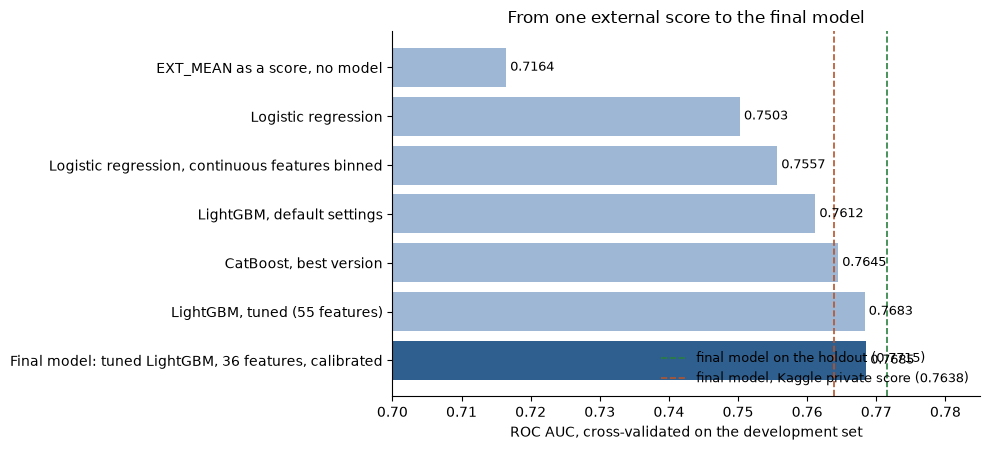

HoldoutVault(61,503 rows, 4,965 defaults, opened 1 times)


In [115]:
ladder_names = {
    'Predict the default rate for everyone': 'predict the default rate',
    'EXT_MEAN as a score, no model': 'EXT_MEAN as a score, no model',
    'Logistic regression': 'logistic regression, all features',
    'Logistic regression, continuous features binned': LINEAR,
    'LightGBM, default settings': 'LightGBM, default',
    'CatBoost, best version': CATBOOST_BEST,
    'LightGBM, tuned (55 features)': LGBM_BEST,
    'Final model: tuned LightGBM, 36 features, calibrated': FINAL_CALIBRATED,
}
ladder = pd.DataFrame({label: {'stage': {'predict the default rate': 4, 'EXT_MEAN as a score, no model': 4, 'logistic regression, all features': 4, LINEAR: 4,
                                         'LightGBM, default': 5, CATBOOST_BEST: 7, LGBM_BEST: 7, FINAL_CALIBRATED: 9}[name],
                               'cv_roc_auc': results[name]['mean']['roc_auc'], 'cv_pr_auc': results[name]['mean']['pr_auc'],
                               'cv_log_loss': results[name]['mean']['log_loss']} for label, name in ladder_names.items()}).T
ladder['gain_on_previous'] = ladder['cv_roc_auc'].diff()
ladder.loc['EXT_MEAN as a score, no model', 'cv_log_loss'] = np.nan          # a raw score, not a probability
print('cross-validated on the development set, same five folds for every row:')
print(ladder.astype({'stage': int}).to_string(float_format=lambda v: f'{v:.4f}', na_rep=''))

kaggle_private = KAGGLE_SCORES['submission_final_model.csv']['private']
evidence = pd.Series({
    'cross-validation, development set (5 folds, 246,008 rows)': CV_FINAL,
    'holdout, opened once (61,503 rows)': HOLDOUT_RESULT['roc_auc'],
    'Kaggle public score (about 20% of 48,744 test rows)': KAGGLE_SCORES['submission_final_model.csv']['public'],
    'Kaggle private score (about 80% of the test rows)': kaggle_private,
}, name='ROC AUC of the final model')
print()
print(evidence.to_string(float_format=lambda v: f'{v:.4f}'))
print(f"holdout 95% interval: {HOLDOUT_RESULT['interval'][0]:.4f} to {HOLDOUT_RESULT['interval'][1]:.4f}")
print(f"spread of the four estimates: {evidence.max() - evidence.min():.4f}")

# the figures quoted in the conclusions below
assert round(CV_FINAL, 4) == 0.7685 and round(HOLDOUT_RESULT['roc_auc'], 4) == 0.7715 and kaggle_private == 0.76382
assert len(FINAL_FEATURES) == 36 and len(RAW_COLUMNS_NEEDED) == 28 and round(THRESHOLD, 4) == 0.0909
assert len(holdout.log) == 1

fig, ax = plt.subplots(figsize=(10, 4.6))
shown = ladder.iloc[1:]
ax.barh(shown.index[::-1], shown['cv_roc_auc'][::-1], color='#9db7d5')
ax.barh(shown.index[-1], shown['cv_roc_auc'].iloc[-1], color='#2f5f8f')
for i, (label, value) in enumerate(shown['cv_roc_auc'][::-1].items()):
    ax.text(value + 0.0006, i, f'{value:.4f}', va='center', fontsize=9)
ax.axvline(HOLDOUT_RESULT['roc_auc'], color='#2a7f3f', linestyle='--', linewidth=1.2, label=f"final model on the holdout ({HOLDOUT_RESULT['roc_auc']:.4f})")
ax.axvline(kaggle_private, color='#b5542d', linestyle='--', linewidth=1.2, label=f'final model, Kaggle private score ({kaggle_private:.4f})')
ax.set_xlim(0.70, 0.785)
ax.set_xlabel('ROC AUC, cross-validated on the development set')
ax.set_title('From one external score to the final model')
ax.legend(loc='lower right', fontsize=9, frameon=False)
sns.despine()
plt.tight_layout()
plt.show()
print(holdout)

### Conclusions

**The model**

A LightGBM classifier on 36 features, built from 28 columns of the application form, with its output passed through Platt scaling so that it can be read as a probability of default.

| | |
|---|---|
| Inputs | 36 features (26 raw, 10 engineered), from 28 of the 120 raw application columns |
| Settings | 2,365 small trees (10 leaves, at least 803 rows per leaf), learning rate 0.02 |
| Output | A calibrated probability of payment difficulties |
| Reference decision rule | Decline at 0.0909 or above, which follows from treating a missed default as 10 times as costly as a wrongly declined applicant |
| Saved as | `artifacts/final_model/`, loaded by `src/models/scoring.py` |

**How good it is**

| Evidence | ROC AUC | What it rules out |
|---|---:|---|
| Cross-validation on the development set | 0.7685 | |
| Holdout, opened once | 0.7715 (0.7641 to 0.7786) | That the tuning, pruning and calibration overfitted the development rows |
| Kaggle private score | 0.7638 | That the score depends on the training file's population |

- Three independent measurements agree to within 0.008. The last one is on a different population, on rows whose labels nobody in this project has seen.
- The probabilities are right as well as the ranking. On the holdout the model predicts an average default rate of 8.08% against an actual 8.07%, and no group of applicants tested is off by more than 0.5 points.
- At the reference threshold the model approves 71% of applicants and catches 65% of defaults. The default rate among approved applicants is about half the 8.07% a lender would get by approving everyone.

**Where the score comes from**

- The external scores do most of the work. Their mean alone scores 0.7164, and removing all of them drops the model to 0.7193.
- Everything else adds 0.052 on top: a linear model on all features reaches 0.7503, binning its continuous features 0.7557, gradient boosting at default settings 0.7612, and tuning 0.7683.
- One engineered feature matters more than the rest together. `ANNUITY_TO_CREDIT` is worth 0.0076 in cross-validation and 0.0147 on Kaggle's test file.
- The whole range from a plain logistic regression to the final model is 0.018. The data sets the level; the choice of model moves it a little.

**What did not help**

- **Rebalancing the classes.** Class weights, undersampling, oversampling and SMOTE did not improve ranking, and each distorted the probabilities. The perceived problem, that the model "never predicts a default", is a property of the 0.5 threshold.
- **A heavier model.** CatBoost led at default settings but gained nothing from tuning, took about ten times as long, and finished 0.0038 behind tuned LightGBM. Blending the two was no better than LightGBM alone.
- **More features.** 19 of the 55 features could be removed with no loss, which also cut the raw columns needed from 120 to 28.
- **More tuning.** Two searches arrived at the same score by different routes, which suggests about 0.768 is what these features support.

**Data leakage: what was controlled, and what each leak would have cost**

Each control was paired with a deliberate demonstration of doing it wrongly, so the size of the leak is measured, not assumed.

| Leak | Control | Measured effect of the wrong way |
|---|---|---|
| Tuning to the evaluation rows | 20% holdout, frozen in stage 2, opened once in stage 11 | Holdout came in 0.0030 above cross-validation, so none detected |
| Preprocessing fitted on all rows | Inside the pipeline, fitted on training folds | +0.00006 ROC AUC (negligible here) |
| Oversampling before splitting | Resampling inside the pipeline | +0.047 ROC AUC, the largest leak found |
| Feature selection on all rows | Selection inside each fold | +0.0005 to +0.0020 ROC AUC |
| Early stopping on the validation fold | Stops on a 15% slice of the training folds | Not measured |
| Calibrator fitted on the rows it is scored on | Nested calibration | Isotonic regression appears perfect; Platt scaling is unaffected |
| Threshold searched on the scored rows | Threshold from a formula, nothing fitted | Cost understated by 0.26% to 0.39% |
| The test file | Never fitted on; used once to write submissions | |

The lesson from the table is that leaks differ enormously in size. The one most often warned about, preprocessing outside the folds, was negligible on this data. Oversampling before splitting inflated the score by more than the whole gain from modelling.

**Mistakes made along the way**

- The first hyperparameter search was biased. Early stopping watched log loss as well as AUC and cut off half the trials too soon. It was found, explained and rerun in stage 7. The final score was unaffected, but the first search's conclusion about class weights was wrong.
- The rule written in advance for choosing a calibration method picked prior correction, because it looked only at log loss. It was overridden in favour of Platt scaling after review, and the override is recorded in stage 9. That choice was made on the development set, before the holdout was opened.
- I expected the shift in `ANNUITY_TO_CREDIT` to hurt on the test file. It did the opposite.

**Limits**

- **It uses one table of seven.** The winning private score was about 0.806. The gap is the applicant's repayment history, which this model never sees.
- **Most of its power comes from scores it cannot explain.** For about 7 declines in 10 the main reason is a low external score, whose inputs are unknown.
- **It uses gender and age.** At the reference threshold men are approved at 0.80 times the rate of women, and applicants under 30 at 0.60 times the rate of those over 60. Removing gender costs 0.0010 of ROC AUC; removing gender, age and family status costs 0.0034. Whether to pay that price is a policy decision this notebook does not make.
- **It only knows applicants who were approved.** Every row is a loan that was granted. How the model behaves on applicants a lender would previously have rejected cannot be learned from this data.
- **The cost ratio of 10 is an assumption.** The threshold follows from it. A lender's real costs would replace it.
- **The decision near the threshold is not stable.** Retraining on 25% more rows changed the decision for 2.8% of test applicants, and the single "main reason" for a decline changes for about 1 applicant in 5.
- **The saved model has not itself been scored on labelled data.** It was refitted on all the training rows. The Kaggle score is its only direct test.
- **It needs the engineered feature table.** The cleaning and feature code is still in the EDA notebook.

**What to do next**

1. **Add the history tables, one at a time**, starting with `bureau` and `installments_payments`. Keep the frozen split and the same folds, so that each table's gain is measured against 0.7685 on equal terms. The Kaggle result shows that a cross-validated gain here can be expected to carry over.
2. **Move the cleaning, feature and pipeline code into `src`**, with tests, so that the model can score a raw application and the notebook classes are no longer needed.
3. **Serve it.** A small API around `scoring.py` that returns the probability, the decision and the top three reasons.
4. **Monitor `ANNUITY_TO_CREDIT`.** It is the second most important feature and the one whose distribution moves most. A drift check on it is the first alert worth having.
5. **Decide on gender and age** before any real use, and retrain without them if required.
6. **Pin the package versions** in `requirements.txt`. The versions used are recorded in `artifacts/final_model/metadata.json`.